# Thực hành Bài 09 — Double DQN và REINFORCE trên CartPole, Lunar Lander và Flappy Bird

Học phần Học tăng cường · Học kỳ 1, năm học 2026–2027.

Notebook thực hành của Bài 08 cài đặt mạng Q sâu (Deep Q-Network, DQN) theo Thuật toán 08.13 và huấn luyện nó trên `CartPole-v1`, `LunarLander-v3` và `FlappyBird-v0`. Ở CartPole, mạng học được báo $\max_aQ_\theta(O_0,a)=108{,}5$ trong khi mọi lợi tức chiết khấu đều nhỏ hơn $1/(1-\gamma)=100$ (Ví dụ 09.1 của ghi chú). Mục 15 của notebook đó đã so điểm của Double DQN với DQN trên Lunar Lander (năm hạt giống (seed)) và Flappy Bird (ba hạt giống), nhưng chưa đo chính đại lượng mà Double DQN nhắm tới: độ lệch giữa giá trị mạng báo và lợi tức (return) thực tế. Tình huống 09.1 của ghi chú ghi phép đo đó là việc còn để ngỏ (nhiệm vụ 1, mục 14 của notebook Bài 08). Notebook này làm phép đo đó trên tám hạt giống, rồi chuyển sang gradient chính sách (policy gradient), theo hai nửa của ghi chú Bài 09.

- **Nửa thứ nhất (mục 3–7).** Tính độ chệch của phép cực đại (maximization bias) trên các ví dụ nhỏ, cài đặt Double Q-learning dạng bảng và mục tiêu Double DQN (Thuật toán 09.5), rồi so DQN với Double DQN trên ba môi trường bằng hai thước đo: điểm của chính sách và mức đánh giá cao (overestimation) $\max_aQ_\theta(O_t,a)-G_t$ dọc các lượt (episode) đánh giá.
- **Nửa thứ hai (mục 8–12).** Cài đặt chính sách softmax trên mạng nơ-ron và REINFORCE (Thuật toán 09.25; Williams, 1992), huấn luyện trên ba môi trường, rồi đo phương sai của ước lượng gradient, giới hạn mà Bài 10 xử lý.

**Mục tiêu.** Sau bài thực hành, người học có thể:

1. tính độ chệch của phép cực đại và của ước lượng kép trên các ví dụ rời rạc, đối chiếu với Mệnh đề 09.2 và 09.4;
2. cài đặt Double Q-learning dạng bảng và mục tiêu Double DQN, kiểm từng phép tính bằng số liệu của Ví dụ 09.6 và 09.7;
3. đo độ lệch giữa $\max_aQ_\theta(O_t,a)$ và lợi tức thực tế $G_t$ trên nhiều lượt và nhiều hạt giống, và phân biệt kết luận về độ chệch với kết luận về điểm;
4. cài đặt REINFORCE với hàm mất mát thay thế, kiểm bằng Ví dụ 09.18–09.20, huấn luyện và đánh giá chính sách ngẫu nhiên;
5. đo phương sai của ước lượng gradient chính sách tại hai giá trị của $\theta$, so bốn cách tính trọng số (kể cả chuẩn hóa lợi tức (return normalization) của `pytorch/examples`), và nêu giới hạn của phép so giữa REINFORCE thuần với cấu hình chuẩn hóa.

**Tiên quyết.** Ghi chú Bài 09: Mục 2 (Định nghĩa 09.1, Mệnh đề 09.2, Ví dụ 09.1–09.3), Mục 3 (Mệnh đề 09.4, Ví dụ 09.4–09.7, Thuật toán 09.5 và 09.7, Nhận xét 09.6), Mục 4–6 (Ví dụ 09.8–09.9, Định nghĩa 09.11, 09.14, 09.15, Mệnh đề 09.16, 09.17, Bổ đề 09.22, Định lý 09.23, Thuật toán 09.25, Hệ quả 09.26, Ví dụ 09.18–09.21), Tình huống 09.1 và 09.2. Notebook thực hành Bài 08: hạ tầng đánh giá, chính sách tham chiếu, trình phát và cấu hình DQN được sao chép từ đó, nên notebook này không cần tệp nào khác.

**Bảng ký hiệu** (thống nhất với ghi chú Bài 09; quan sát viết $O_t$ như Bài 08, trùng trạng thái $S_t$ của ghi chú khi quan sát đủ Markov):

| Ký hiệu | Ý nghĩa | Biến trong mã, kích thước |
|---|---|---|
| $O_t$, $n$ | quan sát ở bước $t$; số chiều ($4$, $8$, $12$) | `o`, cỡ `(n,)` |
| $A_t\in\mathcal A$, $m$ | hành động; số hành động ($2$, $4$, $2$) | `a`; `n_act` |
| $R_{t+1}$, $\gamma$ | phần thưởng sau $A_t$; hệ số chiết khấu $0{,}99$ | `r`; `GAMMA` |
| $Z$, $U$ | cờ kết thúc của MDP; cờ cắt ngắn | `term`, `trunc` |
| $G_t$ | lợi tức chiết khấu từ bước $t$, $G_t=R_{t+1}+\gamma G_{t+1}$, $G_T=0$ | `G`, cỡ `(L,)` |
| $\widehat Q_a$, $q_a$, $\beta$ | ước lượng có nhiễu và giá trị đúng của hành động $a$; độ chệch của phép cực đại | `Qhat`; `q`; `beta` |
| $\theta$, $\theta^-$ | (mục 5–7) tham số mạng trực tuyến và mạng mục tiêu | `q_net`, `tgt_net` |
| $Q_\theta(o,\cdot)$ | vector giá trị hành động tại $o$ | `q_net(O)`, cỡ `(b, m)` |
| $(O_i,A_i,R_i,O'_i,Z_i,U_i)$, $b$ | mẫu chuyển của mini-batch; cỡ mini-batch | `O, A, R, O2, Z, U`: `(b,n)`, `(b,)`, `(b,)`, `(b,n)`, `(b,)`, `(b,)` |
| $a_i^*$, $y_i$ | hành động mạng trực tuyến chọn tại $O'_i$; mục tiêu hồi quy | `a_star` `(b,1)`; `y` `(b,)` |
| $Q_0$, $G_0$ | $\max_aQ_\theta(O_0,a)$ và lợi tức thực tế từ đầu một lượt đánh giá | `Q0`, `G0` |
| độ lệch theo bước | trung bình theo $t$ của $\max_aQ_\theta(O_t,a)-G_t$ trên các bước hợp lệ của một lượt (mục 5) | khóa `gap` |
| đỉnh trung bình $q_i$ | $\max_t$ của trung bình $q_i=Q_\theta(O_i,A_i)$ trên các mini-batch của mỗi $1000$ bước | khóa `qmax` |
| $N$, $N_{\mathrm{start}}$, $F$, $C$, $t_{\mathrm{end}}$ | dung lượng bộ nhớ phát lại; số mẫu trước bước tối ưu đầu; số bước môi trường giữa hai bước tối ưu; số bước tối ưu giữa hai lần đồng bộ; ngân sách bước môi trường | `cfg["N"]`, `cfg["N_start"]`, `cfg["F"]`, `cfg["C"]`, `cfg["t_end"]` |
| $\eta$, $\epsilon_{\mathrm{exp}}$, $f_\epsilon$ | tốc độ học của Adam (DQN); xác suất thăm dò; phần của $t_{\mathrm{end}}$ trong đó $\epsilon_{\mathrm{exp}}$ giảm tuyến tính | `cfg["lr"]`; `eps`; `cfg["eps_frac"]` |
| $h$ | số nút mỗi tầng ẩn | `cfg["hidden"]` |
| $Q_1$, $Q_2$ | hai bảng của Double Q-learning | `Q1`, `Q2` |
| $\theta$, $\pi_\theta(a\mid o)$, $z_\theta(o)$ | (mục 8–12) tham số chính sách; chính sách softmax; vector logit của mạng | `pol`; `torch.softmax(pol(o), -1)`, cỡ `(m,)`; `pol(o)` |
| $\psi_t$ | hàm điểm (score function) $\nabla_\theta\log\pi_\theta(A_t\mid O_t)$ | vector cỡ `(d,)` |
| $L(\theta)$ | hàm mất mát thay thế (surrogate loss), $-\nabla_\theta L=\widehat g$ | `reinforce_loss(...)`, vô hướng |
| $\widehat g$, $K$ | ước lượng REINFORCE của $\nabla_\theta J$; số lượt gộp vào một cập nhật | `g_hat`; `cfg["K"]` |
| $\alpha$, $N_{\text{lượt}}$ | bước học của Adam (REINFORCE); số lượt huấn luyện | `cfg["lr"]`; `cfg["n_episodes"]` |
| $d$ | số tham số của mạng | `n_params` |
| $b_0$ | (mục 12, 15) đường cơ sở (baseline) hằng trừ khỏi $G_t$ | `b` |
| $M$, $V$ | (mục 12) số lượt độc lập tại một $\theta$ cố định; tổng phương sai mẫu của $\widehat g$ | `M`; `V` |
| TB, sd, SE, df | trung bình; độ lệch chuẩn (standard deviation); sai số chuẩn (standard error) $\mathrm{sd}/\sqrt n$; số bậc tự do (degrees of freedom) của phân phối Student | (in trong bảng) |
| $L$ | độ dài (số bước) của một lượt | `len(rs)` |

Thuật toán 09.5 viết ngân sách là $t_{\mathrm{end}}$ vì chữ $T$ dành cho bước kết thúc của lượt; notebook dùng khóa `t_end`. Bộ nhớ phát lại (experience replay) $\mathcal D$ và mạng mục tiêu (target network) $\theta^-$ giữ nghĩa như Bài 08. Chữ $\theta$ có hai vai như trong ghi chú: tham số mạng giá trị ở mục 5–7 và tham số chính sách ở mục 8–12; hai vai không xuất hiện trong cùng một ô mã.

**Cách dùng.** Chạy các ô mã theo thứ tự từ trên xuống; ô ở mục 1 tự cài các gói, nên notebook chạy được trên Jupyter cục bộ hoặc Google Colab. Mọi phép ngẫu nhiên dùng hạt giống cố định. Trên cùng máy, cùng phiên bản gói và cùng số luồng CPU, chạy lại cho cùng số liệu; với phiên bản PyTorch hoặc số luồng khác, số liệu huấn luyện lệch theo. Vì vậy các đoạn **Đọc kết quả** dựa trên các bảng nhiều hạt giống chạy khi soạn (nhúng trong notebook), không dựa trên con số của một lần chạy trực tiếp. Các phép kiểm `assert` chỉ dùng số tính tay, số đếm và kích thước, không dùng số liệu huấn luyện.

Phần chạy trực tiếp gồm hai lần huấn luyện DQN và Double DQN trên CartPole, một lần REINFORCE và một lần cấu hình đối chiếu trên CartPole; Lunar Lander và Flappy Bird dùng bảng tám hạt giống và các lượt ghi khi soạn. Khi soạn, phần tính toán mất khoảng $11$ phút trên CPU hai luồng (trong lúc máy chạy song song các thí nghiệm khác), cộng $1$–$2$ phút cài gói; thời gian của lần chạy hiện tại in ở cuối mục 14. Không cần GPU. Các số dẫn trong văn bản được tạo với gymnasium 1.4.0, torch 2.15.0+cpu, hai luồng; ô in kết quả của lần chạy trực tiếp in kèm số tham chiếu đó để đối chiếu. Đặt `RUN_LUNAR = True` ở mục 7 để huấn luyện thêm Double DQN trên Lunar Lander (khoảng $6$ phút trên CPU hai luồng khi soạn).

## 1. Cài đặt và chuẩn bị

Ô mã dưới cài Gymnasium kèm phần mở rộng `box2d` (bộ mô phỏng vật lý của Lunar Lander), gói `flappy-bird-gymnasium`, NumPy và Matplotlib, rồi cài PyTorch bản CPU nếu môi trường chưa có (Colab có sẵn PyTorch). Cận trên phiên bản giữ API đã dùng khi soạn (Gymnasium 1.x, `flappy-bird-gymnasium` 0.4.x).

`pip` có thể in dòng *Note: you may need to restart the kernel to use updated packages*; khi ô cài đặt được chạy trước mọi lệnh `import`, không cần khởi động lại. `pip` có thể báo xung đột giữa `pygame` và `pygame-ce` (phần mở rộng `box2d` của Gymnasium 1.4 cài `pygame-ce`, còn `flappy-bird-gymnasium` cài `pygame`); notebook không gọi `render`, nên có thể bỏ qua cảnh báo này, như ở notebook Bài 08.

In [1]:
%pip install -q "gymnasium[box2d]>=1.0,<2" "flappy-bird-gymnasium>=0.4,<0.5" numpy matplotlib
import importlib.util
if importlib.util.find_spec("torch") is None:       # Colab có sẵn torch; máy cục bộ chưa có thì cài bản CPU
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


Ô mã dưới nhập các gói, in phiên bản và đặt hằng số. Bốn tập hạt giống giữ quy ước của Bài 08: lượt huấn luyện thứ $k$ của hạt giống tác tử $s$ dùng `20_000 + 100_000 * s + k` (với $s=1$ là `TRAIN_SEED` $=120\,000$); mốc kiểm định dùng $10$ lượt `VALID_SEED + i`; đánh giá cuối dùng $100$ lượt `TEST_SEED + i`; `SEL_SEED` là tập lượt thứ tư, dùng để đối chiếu khi chọn cấu hình. `torch.set_num_threads(2)` khớp với hai lõi CPU của Colab.

In [2]:
import copy, hashlib, json, time
from importlib.metadata import version

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import patches
import gymnasium as gym
import flappy_bird_gymnasium  # noqa: F401  (đăng ký môi trường FlappyBird-v0)
from gymnasium.envs.box2d import lunar_lander as ll
import torch
import torch.nn as nn
from IPython.display import HTML, display

T_START = time.time()                      # đo tổng thời gian chạy notebook
torch.set_num_threads(2)                   # số liệu huấn luyện phụ thuộc số luồng
print("gymnasium", gym.__version__, "| flappy-bird-gymnasium", version("flappy-bird-gymnasium"),
      "| torch", torch.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

GAMMA = 0.99            # hệ số chiết khấu gamma
TRAIN_SEED = 120_000    # hạt giống tác tử s = 1: lượt huấn luyện k dùng reset(seed=TRAIN_SEED + k)
VALID_SEED = 40_000     # 10 lượt kiểm định ở mỗi mốc
TEST_SEED = 30_000      # 100 lượt đánh giá cuối, dùng chung cho mọi chính sách
SEL_SEED = 50_000       # 100 lượt của tập thứ tư (bảng chạy khi soạn)
AGENT_SEED = 1          # khởi tạo tham số, thăm dò, rút mini-batch, lấy mẫu hành động khi huấn luyện
N_TEST, N_VALID = 100, 10

gymnasium 1.4.0 | flappy-bird-gymnasium 0.4.0 | torch 2.15.0+cpu | numpy 2.5.4 | matplotlib 3.11.2


## 2. Ba môi trường, thước đo và chính sách tham chiếu

**Vấn đề.** Cả hai nửa của notebook cần cùng một thước đo: chạy một chính sách trên các lượt riêng và so hai chính sách trên cùng các lượt đó. Mục này sao chép nguyên hạ tầng của notebook Bài 08 (mục 2–3): hàm tạo môi trường, `evaluate_policy` (trung bình, độ lệch chuẩn sd, sai số chuẩn $\mathrm{SE}=\mathrm{sd}/\sqrt{N_{\mathrm{ev}}}$ trên $N_{\mathrm{ev}}$ lượt, lượt thứ $i$ dùng hạt giống `seed + i` cho cả `reset` lẫn bộ sinh số ngẫu nhiên của chính sách), `paired_difference` (hiệu ghép cặp $\bar d\pm1{,}96\,\mathrm{SE}(d)$) và các chính sách tham chiếu.

| Môi trường | Quan sát $O_t$ | $m$ | Phần thưởng | $Z=1$ khi | $U=1$ khi |
|---|---|---|---|---|---|
| `CartPole-v1` | $(x,\dot x,\phi,\dot\phi)$, $n=4$ | $2$ | $+1$ mỗi bước | $\lvert\phi\rvert>12^\circ$ hoặc $\lvert x\rvert>2{,}4$ | lượt đạt $500$ bước |
| `LunarLander-v3` | vị trí, vận tốc, góc, vận tốc góc, hai cờ chân, $n=8$ | $4$ | hàm định hình trừ nhiên liệu; $-100$ khi rơi, $+100$ khi nằm yên | chạm đất bằng thân, ra ngoài, nằm yên | lượt đạt $1000$ bước |
| `FlappyBird-v0` | ba ống, độ cao, vận tốc dọc, góc của chim, $n=12$ | $2$ | $+0{,}1$ mỗi bước, $+1$ qua ống, $-0{,}5$ chạm mép trên, $-1$ khi chết | chạm ống hoặc đất | qua $50$ ống |

Mô tả chi tiết và mức độ thỏa giả thiết Markov của ba quan sát có trong notebook Bài 08, mục 2. Chính sách tham chiếu: CartPole chọn đều, luật theo dấu góc, luật $\phi+0{,}5\,\dot\phi>0$; Lunar Lander chọn đều, bộ điều khiển viết tay của Gymnasium; Flappy Bird vỗ cánh với xác suất $0{,}08$, luật tay của Bài 07 (ngưỡng $0{,}02$).

In [3]:
def make_env(env_id):
    # Môi trường đơn (không tự đặt lại); Lunar Lander: hành động rời rạc, không gió; Flappy Bird: quan sát 12 chiều
    if env_id == "CartPole-v1":
        return gym.make("CartPole-v1")
    if env_id == "LunarLander-v3":
        return gym.make("LunarLander-v3", continuous=False, enable_wind=False)
    return gym.make("FlappyBird-v0", use_lidar=False, score_limit=50)


ENV_IDS = ["CartPole-v1", "LunarLander-v3", "FlappyBird-v0"]
KIND = {"CartPole-v1": "cartpole", "LunarLander-v3": "lunar", "FlappyBird-v0": "flappy"}


# ---- chính sách tham chiếu
def uniform_policy(n_act):
    return lambda o, rng: int(rng.integers(n_act))           # chọn đều trong A


def cartpole_angle(o, rng=None):
    return int(o[2] >= 0)                                      # theo dấu góc phi (Bài 04)


def cartpole_angle_vel(o, rng=None, c=0.5):
    return int(o[2] + c * o[3] > 0)                            # phi + c * phi_dot > 0: đẩy phải


def make_lander_heuristic(env):
    core = env.unwrapped
    return lambda o, rng: int(ll.heuristic(core, o))           # bộ điều khiển viết tay của Gymnasium, tất định


FB_W, FB_H = 288.0, 512.0                                      # kích thước màn hình Flappy Bird (điểm ảnh)
FB_PLAYER_X, FB_PIPE_W, FB_PLAYER_H = int(FB_W * 0.2) / FB_W, 52 / FB_W, 24 / FB_H


def flappy_random(o, rng, p=0.08):
    return int(rng.random() < p)                               # vỗ cánh với xác suất p


def flappy_rule(o, rng=None, thr=0.02):
    # ống kế tiếp: ống đầu tiên có mép phải còn ở phía trước mép trái của chim (Bài 07)
    k = next(j for j in range(3) if o[3 * j] + FB_PIPE_W > FB_PLAYER_X or j == 2)
    dy = o[9] + FB_PLAYER_H / 2 - 0.5 * (o[3 * k + 1] + o[3 * k + 2])   # tâm chim - tâm khe (dương: chim thấp hơn)
    return int(dy > thr and o[10] > 0)                         # vỗ khi thấp hơn tâm khe và đang rơi


# ---- đánh giá qua nhiều lượt
def evaluate_policy(env, policy, n_episodes, seed, gamma=GAMMA):
    out = dict(total=[], G0=[], length=[], term=[], trunc=[], score=[], seeds=[])
    for i in range(n_episodes):
        rng = np.random.default_rng(seed + i)                  # cùng hạt giống cho reset và cho chính sách
        o, _ = env.reset(seed=seed + i)
        rs, info = [], {}
        while True:
            o, r, term, trunc, info = env.step(policy(o, rng))
            rs.append(r)
            if term or trunc:
                break
        rs = np.array(rs)
        out["total"].append(rs.sum()); out["G0"].append(float(np.sum(rs * gamma ** np.arange(len(rs)))))
        out["length"].append(len(rs)); out["term"].append(term); out["trunc"].append(trunc)
        out["score"].append(info.get("score", np.nan)); out["seeds"].append(seed + i)
    return {k: np.array(v) for k, v in out.items()}


def summarize(name, res, flappy=False):
    n = len(res["total"]); se = lambda v: v.std(ddof=1) / np.sqrt(n)
    g = res["score"] if flappy else res["total"]
    unit = "ống" if flappy else "tổng thưởng"
    print(f"{name:<26} {unit} {g.mean():8.2f} ± {se(g):5.2f} (sd {g.std(ddof=1):6.2f}) | G_0 {res['G0'].mean():7.2f} | "
          f"dài {res['length'].mean():6.0f} | cắt ngắn {res['trunc'].mean():4.0%}")


def paired_difference(res_a, res_b, key="total"):
    assert np.array_equal(res_a["seeds"], res_b["seeds"])     # ghép cặp chỉ hợp lệ trên cùng dãy hạt giống
    d = res_a[key] - res_b[key]
    return d.mean(), 1.96 * d.std(ddof=1) / np.sqrt(len(d))

In [4]:
envs = {env_id: make_env(env_id) for env_id in ENV_IDS}       # một môi trường đánh giá cho mỗi bài toán
REF_POLICIES = {
    "CartPole-v1": {"ngẫu nhiên": uniform_policy(2), "theo dấu góc": cartpole_angle, "góc + vận tốc góc": cartpole_angle_vel},
    "LunarLander-v3": {"ngẫu nhiên": uniform_policy(4), "điều khiển viết tay": make_lander_heuristic(envs["LunarLander-v3"])},
    "FlappyBird-v0": {"ngẫu nhiên p=0,08": flappy_random, "luật tay": flappy_rule},
}
results_ref, t0 = {}, time.time()
for env_id, pols in REF_POLICIES.items():
    print(f"--- {env_id}: {N_TEST} lượt TEST_SEED, trung bình ± SE")
    results_ref[env_id] = {name: evaluate_policy(envs[env_id], p, N_TEST, TEST_SEED) for name, p in pols.items()}
    for name, res in results_ref[env_id].items():
        summarize(name, res, flappy=(env_id == "FlappyBird-v0"))
print(f"({time.time() - t0:.0f} giây)")

--- CartPole-v1: 100 lượt TEST_SEED, trung bình ± SE


ngẫu nhiên                 tổng thưởng    22.95 ±  1.16 (sd  11.62) | G_0   20.09 | dài     23 | cắt ngắn   0%
theo dấu góc               tổng thưởng    41.89 ±  0.82 (sd   8.20) | G_0   34.14 | dài     42 | cắt ngắn   0%
góc + vận tốc góc          tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
--- LunarLander-v3: 100 lượt TEST_SEED, trung bình ± SE


ngẫu nhiên                 tổng thưởng  -194.82 ± 12.30 (sd 123.00) | G_0  -98.93 | dài    101 | cắt ngắn   1%
điều khiển viết tay        tổng thưởng   236.89 ± 10.07 (sd 100.66) | G_0   68.79 | dài    267 | cắt ngắn   4%
--- FlappyBird-v0: 100 lượt TEST_SEED, trung bình ± SE


ngẫu nhiên p=0,08          ống     0.03 ±  0.02 (sd   0.17) | G_0    3.11 | dài     49 | cắt ngắn   0%
luật tay                   ống    34.30 ±  1.30 (sd  12.95) | G_0   11.56 | dài   1334 | cắt ngắn  23%
(11 giây)


Ba ô mã dưới sao chép từ notebook Bài 08 các công cụ xem một lượt: `record_episode` ghi mảng trạng thái, hành động, phần thưởng của một lượt; `player` dựng trình phát `<canvas>` từ các mảng đó (Phát/Dừng, thanh tua, tốc độ); `filmstrip` và `plot_episodes` vẽ dải ảnh và đồ thị tĩnh bằng Matplotlib, hiển thị được cả khi trình duyệt không chạy JavaScript. Hai chỉnh sửa nhỏ so với Bài 08: dải ảnh CartPole cao hơn và thu khung ngang quanh vùng xe chạy; thanh điều khiển của trình phát rộng tới $1300$ điểm ảnh để ba khung Lunar Lander nằm trên một hàng khi màn hình đủ rộng. Các chính sách tham chiếu được phát cùng chính sách học được ở mục 6, 7, 9 và 11.

In [5]:
W_WORLD, H_WORLD = ll.VIEWPORT_W / ll.SCALE, ll.VIEWPORT_H / ll.SCALE   # khung hình Lunar Lander (m)
LANDER_POLY = np.array(ll.LANDER_POLY, dtype=float) / ll.SCALE           # đa giác thân tàu (m)
FB_GROUND = 404.48                                                        # tọa độ mặt đất Flappy Bird (điểm ảnh)
LANDER_ACTIONS = ["không bật", "đ.cơ trái", "đ.cơ chính", "đ.cơ phải"]


def record_episode(env, policy, seed, kind):
    rng = np.random.default_rng(seed)                       # cùng quy ước hạt giống với evaluate_policy
    obs, _ = env.reset(seed=seed)
    ep = {"seed": seed, "kind": kind}
    if kind == "lunar":                                      # địa hình và bãi đáp, chỉ dùng để vẽ
        u = env.unwrapped
        ep["terrain"] = [list(map(float, p[0])) for p in u.sky_polys] + [list(map(float, u.sky_polys[-1][1]))]
        ep["helipad"] = (float(u.helipad_x1), float(u.helipad_x2), float(u.helipad_y))
    states, actions, rewards, info = [obs], [], [], {}
    while True:
        a = policy(obs, rng)
        obs, r, term, trunc, info = env.step(a)
        states.append(obs); actions.append(a); rewards.append(r)
        if term or trunc:
            break
    ep.update(states=np.array(states, dtype=float), actions=np.array(actions, dtype=int),   # (T+1, n), (T,)
              rewards=np.array(rewards, dtype=float), terminated=bool(term), truncated=bool(trunc),
              score=info.get("score"))
    return ep


def end_reason(ep):
    T = len(ep["actions"])
    if ep["kind"] == "cartpole":
        if ep["truncated"]:
            return f"cắt ngắn ở {T} bước"
        return "|φ| > 12 độ" if abs(ep["states"][-1, 2]) > 0.2095 else "|x| > 2,4"
    if ep["kind"] == "lunar":
        if ep["terminated"]:
            return "nằm yên (+100)" if ep["rewards"][-1] == 100 else "rơi hoặc ra ngoài (-100)"
        return "cắt ngắn 1000 bước"
    return "đạt 50 ống" if ep["truncated"] else f"va chạm, {ep['score']} ống"


def _pack(name, ep, stride):
    # Đóng gói một lượt thành mảng nhỏ cho JavaScript; giữ mỗi `stride` bước và luôn giữ bước cuối
    S, A = ep["states"], ep["actions"]
    L = len(A)                                               # độ dài lượt
    idx = np.unique(np.r_[np.arange(0, L + 1, stride), L])   # các bước được vẽ, gồm 0 và L
    S = S[idx]
    item = {"name": name, "T": len(idx) - 1, "steps": idx.tolist(), "a": A[idx[:-1]].tolist(),
            "reason": f"dừng ở bước {L}: {end_reason(ep)}"}
    if ep["kind"] == "cartpole":
        item.update(x=S[:, 0].round(4).tolist(), th=S[:, 2].round(4).tolist())
    elif ep["kind"] == "lunar":                              # quan sát chuẩn hóa -> tọa độ (m) theo công thức trong step
        hy = ep["helipad"][2]
        item.update(x=(S[:, 0] * W_WORLD / 2 + W_WORLD / 2).round(3).tolist(),
                    y=(S[:, 1] * H_WORLD / 2 + hy + ll.LEG_DOWN / ll.SCALE).round(3).tolist(),
                    phi=S[:, 4].round(3).tolist(), l1=S[:, 6].astype(int).tolist(), l2=S[:, 7].astype(int).tolist(),
                    terrain=np.round(ep["terrain"], 3).tolist(), pad=list(ep["helipad"]))
    else:                                                    # quan sát chuẩn hóa -> điểm ảnh
        sc = np.concatenate([[0], np.cumsum(ep["rewards"] >= 1.0)]).astype(int)[idx]   # số ống đã qua
        item.update(px=np.round(S[:, [0, 3, 6]] * FB_W).astype(int).tolist(),
                    pt=np.round(S[:, [1, 4, 7]] * FB_H).astype(int).tolist(),
                    pb=np.round(S[:, [2, 5, 8]] * FB_H).astype(int).tolist(),
                    y=np.round(S[:, 9] * FB_H).astype(int).tolist(), r=np.round(S[:, 11] * 90).astype(int).tolist(),
                    s=sc.tolist())
    return item


_PLAYER_COUNT = [0]


def player(episodes, max_frames=1000):
    # episodes: {tên: lượt do record_episode trả về}, cùng một môi trường.
    # Lượt dài hơn max_frames bước được vẽ cách quãng (mỗi `stride` bước) để vẫn thấy toàn bộ lượt.
    kind = next(iter(episodes.values()))["kind"]
    L_max = max(len(e["actions"]) for e in episodes.values())
    stride = int(np.ceil(L_max / max_frames))
    dt = {"cartpole": 0.02, "lunar": 1 / ll.FPS, "flappy": 1 / 30}[kind]
    eps = [_pack(n, e, stride) for n, e in episodes.items()]
    world_h = H_WORLD
    if kind == "lunar":                                      # khung đủ cao để tàu không bị cắt ở đầu lượt
        world_h = max(H_WORLD, max(max(e["y"]) for e in eps) + 1.5)
    data = {"kind": kind, "dt": dt, "stride": stride, "eps": eps, "poly": LANDER_POLY.round(4).tolist(),
            "world": [W_WORLD, world_h], "ground": FB_GROUND}
    payload = json.dumps(data, ensure_ascii=False, separators=(",", ":"))
    _PLAYER_COUNT[0] += 1                                     # mỗi lần hiển thị một mã riêng, tất định giữa các lần chạy
    uid = f"pl{_PLAYER_COUNT[0]}_" + hashlib.md5(payload.encode()).hexdigest()[:8]
    html = PLAYER_HTML.replace("__ID__", uid).replace("__DATA__", payload)
    note = "" if stride == 1 else f"; vẽ mỗi {stride} bước để hiển thị trọn lượt dài {L_max} bước"
    print(f"Trình phát: {len(episodes)} lượt, HTML nhúng {len(html) / 1e3:.0f} kB{note}")
    return HTML(html)

In [6]:
# Mẫu HTML của trình phát chung; __ID__ và __DATA__ được thay bằng mã ô và dữ liệu JSON
PLAYER_HTML = r'''
<div id="__ID__" style="font-family: sans-serif; font-size: 13px;">
  <div class="pl-nojs" style="color: #a00;">Trình phát cần JavaScript: tin cậy notebook hoặc chạy lại ô này.</div>
  <div class="pl-panels" style="display: flex; flex-wrap: wrap; gap: 8px;"></div>
  <div style="display: flex; align-items: center; gap: 8px; margin-top: 6px; max-width: 1300px;">
    <button class="pl-play" style="font-size: 13px;">Phát</button>
    <input class="pl-slider" type="range" min="0" value="0" style="flex: 1;">
    <span class="pl-label" style="min-width: 150px;"></span>
    <select class="pl-speed" style="font-size: 13px;">
      <option value="0.25">0,25×</option><option value="0.5">0,5×</option>
      <option value="1" selected>1× (thời gian thực)</option><option value="2">2×</option><option value="4">4×</option>
    </select>
  </div>
</div>
<script>
(function () {
  const root = document.getElementById('__ID__'); const D = __DATA__;
  root.querySelector('.pl-nojs').style.display = 'none';
  const SIZE = {cartpole: [400, 150], lunar: [420, 40 + Math.round(D.world[1] * 420 / D.world[0])], flappy: [216, 390]};
  const W = SIZE[D.kind][0], H = SIZE[D.kind][1], dpr = window.devicePixelRatio || 1;
  const stats = [];                                       // dòng chữ dưới khung hình: bước dừng và lý do dừng
  const ctxs = D.eps.map(function (ep) {
    const box = document.createElement('div'); box.style.width = W + 'px'; box.style.maxWidth = '100%';
    const c = document.createElement('canvas'); c.width = W * dpr; c.height = H * dpr;
    c.style.width = W + 'px'; c.style.maxWidth = '100%'; c.style.border = '1px solid #ddd';
    const st = document.createElement('div'); st.style.font = '12px sans-serif'; st.style.minHeight = '32px';
    box.appendChild(c); box.appendChild(st); root.querySelector('.pl-panels').appendChild(box); stats.push(st);
    const ctx = c.getContext('2d'); ctx.scale(dpr, dpr); return ctx;
  });
  const Tmax = Math.max.apply(null, D.eps.map(function (e) { return e.T; }));
  const LONG = D.eps.filter(function (e) { return e.T === Tmax; })[0];   // lượt dài nhất: đổi số khung sang số bước
  const slider = root.querySelector('.pl-slider'), label = root.querySelector('.pl-label');
  const btn = root.querySelector('.pl-play'), speed = root.querySelector('.pl-speed');
  slider.max = Tmax;
  function head(ctx, ep, t, k, txt) {                    // tên chính sách và dòng trạng thái
    ctx.fillStyle = '#000'; ctx.textAlign = 'center';
    ctx.font = 'bold 14px sans-serif'; ctx.fillText(ep.name, W / 2, 15);
    ctx.font = '12px sans-serif';
    ctx.fillText('bước ' + ep.steps[k] + (txt ? ': ' + txt : '') + (t >= ep.T ? ' (đã dừng)' : ''), W / 2, 31);
  }
  function cartpole(ctx, ep, t) {
    const k = Math.min(t, ep.T), view = 3.0, s = W / (2 * view), g = H - 8, X = function (x) { return W / 2 + x * s; };
    ctx.clearRect(0, 0, W, H); head(ctx, ep, t, k, t < ep.T ? (ep.a[k] === 1 ? 'đẩy phải' : 'đẩy trái') : '');
    ctx.strokeStyle = '#000'; ctx.lineWidth = 1; ctx.beginPath(); ctx.moveTo(0, g); ctx.lineTo(W, g); ctx.stroke();
    ctx.setLineDash([3, 3]); ctx.strokeStyle = '#888';     // ngưỡng |x| = 2,4
    [-2.4, 2.4].forEach(function (xv) { ctx.beginPath(); ctx.moveTo(X(xv), g); ctx.lineTo(X(xv), 36); ctx.stroke(); });
    ctx.setLineDash([]);
    const x = ep.x[k], th = ep.th[k], cw = 0.5 * s, ch = 0.3 * s, L = 1.0 * s;
    ctx.fillStyle = '#c6dbef'; ctx.strokeStyle = '#000';
    ctx.fillRect(X(x) - cw / 2, g - ch, cw, ch); ctx.strokeRect(X(x) - cw / 2, g - ch, cw, ch);
    ctx.strokeStyle = '#8c510a'; ctx.lineWidth = 4; ctx.beginPath(); ctx.moveTo(X(x), g - ch);
    ctx.lineTo(X(x) + L * Math.sin(th), g - ch - L * Math.cos(th)); ctx.stroke();
    if (t < ep.T) {                                       // mũi tên hướng lực
      const d = ep.a[k] === 1 ? 1 : -1, y = g - ch / 2, x0 = X(x) + d * cw / 2, x1 = x0 + d * 30;
      ctx.strokeStyle = '#000'; ctx.lineWidth = 2; ctx.beginPath(); ctx.moveTo(x0, y); ctx.lineTo(x1, y);
      ctx.moveTo(x1, y); ctx.lineTo(x1 - d * 7, y - 5); ctx.moveTo(x1, y); ctx.lineTo(x1 - d * 7, y + 5); ctx.stroke();
    }
  }
  const LN = ['không bật', 'động cơ trái', 'động cơ chính', 'động cơ phải'];
  function lunar(ctx, ep, t) {
    const k = Math.min(t, ep.T), TOP = 40, s = W / D.world[0];
    const SX = function (x) { return x * s; }, SY = function (y) { return TOP + (D.world[1] - y) * s; };
    function body(x, y, phi, pts) {
      const c = Math.cos(phi), sn = Math.sin(phi); ctx.beginPath();
      pts.forEach(function (p, i) { const X = SX(x + c * p[0] - sn * p[1]), Y = SY(y + sn * p[0] + c * p[1]);
        if (i === 0) ctx.moveTo(X, Y); else ctx.lineTo(X, Y); }); ctx.closePath();
    }
    ctx.clearRect(0, 0, W, H); head(ctx, ep, t, k, t < ep.T ? LN[ep.a[k]] : '');
    ctx.save(); ctx.beginPath(); ctx.rect(0, TOP, W, H - TOP); ctx.clip();   // không vẽ đè dòng chữ phía trên
    ctx.beginPath(); ctx.moveTo(SX(ep.terrain[0][0]), SY(0));
    ep.terrain.forEach(function (p) { ctx.lineTo(SX(p[0]), SY(p[1])); });
    ctx.lineTo(SX(ep.terrain[ep.terrain.length - 1][0]), SY(0)); ctx.closePath();
    ctx.fillStyle = '#d9d9d9'; ctx.fill(); ctx.strokeStyle = '#555'; ctx.lineWidth = 1; ctx.stroke();
    [ep.pad[0], ep.pad[1]].forEach(function (xf) {         // cờ bãi đáp
      ctx.strokeStyle = '#000'; ctx.beginPath(); ctx.moveTo(SX(xf), SY(ep.pad[2])); ctx.lineTo(SX(xf), SY(ep.pad[2] + 1.6)); ctx.stroke();
      ctx.fillStyle = '#e6c229'; ctx.beginPath(); ctx.moveTo(SX(xf), SY(ep.pad[2] + 1.6));
      ctx.lineTo(SX(xf), SY(ep.pad[2] + 1.2)); ctx.lineTo(SX(xf) + 10, SY(ep.pad[2] + 1.4)); ctx.closePath(); ctx.fill();
    });
    ctx.setLineDash([2, 3]); ctx.strokeStyle = '#4c72b0'; ctx.beginPath();     // quãng đường đã đi
    for (let i = 0; i <= k; i++) { if (i === 0) ctx.moveTo(SX(ep.x[i]), SY(ep.y[i])); else ctx.lineTo(SX(ep.x[i]), SY(ep.y[i])); }
    ctx.stroke(); ctx.setLineDash([]);
    const x = ep.x[k], y = ep.y[k], phi = ep.phi[k];
    const fl = {2: [[-0.2, -0.33], [0.2, -0.33], [0, -1.0]], 1: [[0.57, 0.15], [0.57, 0.4], [1.05, 0.27]],
                3: [[-0.57, 0.15], [-0.57, 0.4], [-1.05, 0.27]]};
    if (t < ep.T && fl[ep.a[k]]) { body(x, y, phi, fl[ep.a[k]]); ctx.fillStyle = '#f28e2b'; ctx.fill(); ctx.strokeStyle = '#7f2704'; ctx.stroke(); }
    [-1, 1].forEach(function (sg, i) {                    // chân: tô đặc khi chạm đất
      const c = Math.cos(phi), sn = Math.sin(phi), p0 = [sg * 0.4, -0.3], p1 = [sg * 0.7, -0.6];
      ctx.strokeStyle = '#000'; ctx.lineWidth = 2; ctx.beginPath();
      ctx.moveTo(SX(x + c * p0[0] - sn * p0[1]), SY(y + sn * p0[0] + c * p0[1]));
      const fx = SX(x + c * p1[0] - sn * p1[1]), fy = SY(y + sn * p1[0] + c * p1[1]); ctx.lineTo(fx, fy); ctx.stroke();
      ctx.beginPath(); ctx.arc(fx, fy, 3.5, 0, 2 * Math.PI);
      ctx.fillStyle = ((i === 0 ? ep.l1[k] : ep.l2[k]) > 0.5) ? '#000' : '#fff'; ctx.fill(); ctx.stroke();
    });
    body(x, y, phi, D.poly); ctx.fillStyle = '#c6dbef'; ctx.fill(); ctx.strokeStyle = '#000'; ctx.lineWidth = 1.2; ctx.stroke();
    ctx.restore();
  }
  function flappy(ctx, ep, t) {
    const k = Math.min(t, ep.T), S = 0.75, TOP = 36;
    ctx.clearRect(0, 0, W, H); head(ctx, ep, t, k, 'ống ' + ep.s[k] + (t < ep.T && ep.a[k] === 1 ? ', vỗ cánh' : ''));
    ctx.save(); ctx.beginPath(); ctx.rect(0, TOP, W, H - TOP); ctx.clip(); ctx.translate(0, TOP - 30);
    ctx.fillStyle = '#dff3ff'; ctx.fillRect(0, 0, W, 512 * S);
    ctx.fillStyle = '#d9c38b'; ctx.fillRect(0, D.ground * S, W, 512 * S - D.ground * S);
    for (let j = 0; j < 3; j++) {
      const x = ep.px[k][j], top = ep.pt[k][j], bot = ep.pb[k][j];
      if (top <= 0 && bot >= 512) continue;               // ống chưa vào màn hình
      ctx.fillStyle = '#5cb85c'; ctx.strokeStyle = '#2d6a2d';
      ctx.fillRect(x * S, 0, 52 * S, top * S); ctx.strokeRect(x * S, 0, 52 * S, top * S);
      ctx.fillRect(x * S, bot * S, 52 * S, (D.ground - bot) * S); ctx.strokeRect(x * S, bot * S, 52 * S, (D.ground - bot) * S);
    }
    ctx.translate((57 + 17) * S, (ep.y[k] + 12) * S); ctx.rotate(-ep.r[k] * Math.PI / 180);
    ctx.fillStyle = (t < ep.T && ep.a[k] === 1) ? '#ff9800' : '#ffd54f';      // cam: đang vỗ cánh
    ctx.beginPath(); ctx.ellipse(0, 0, 17 * S, 12 * S, 0, 0, 2 * Math.PI); ctx.fill(); ctx.strokeStyle = '#333'; ctx.stroke();
    ctx.restore();
  }
  const DRAW = {cartpole: cartpole, lunar: lunar, flappy: flappy};
  let t = 0, timer = null;
  function render() {
    const step = LONG.steps[Math.min(t, LONG.T)];
    slider.value = t; label.textContent = 'bước ' + step + ' (' + (step * D.dt).toFixed(2) + ' s)';
    D.eps.forEach(function (ep, i) {
      DRAW[D.kind](ctxs[i], ep, t);
      stats[i].textContent = (t >= ep.T ? 'Lượt ' : 'Lượt sẽ ') + ep.reason + '.';
    });
  }
  function stop() { clearInterval(timer); timer = null; btn.textContent = 'Phát'; }
  function start() {                                      // mỗi bước dt giây được phát trong dt / tốc độ giây
    if (t >= Tmax) t = 0; btn.textContent = 'Dừng';
    timer = setInterval(function () { t += 1; render(); if (t >= Tmax) stop(); }, 1000 * D.dt * D.stride / parseFloat(speed.value));
  }
  btn.onclick = function () { if (timer) stop(); else start(); };
  speed.onchange = function () { if (timer) { stop(); start(); } };
  slider.oninput = function () { if (timer) stop(); t = parseInt(slider.value, 10); render(); };
  render();
})();
</script>
'''

In [7]:
CART_W, CART_H = 0.5, 0.3                                    # xe CartPole (m), chỉ để minh họa
FB_PLAYER_PX, FB_PIPE_PX = 57, 52                            # vị trí ngang của chim, bề rộng ống (điểm ảnh)


# ---- dải ảnh tĩnh (Matplotlib), hiển thị được khi không có JavaScript
def draw_frame(ax, ep, k):
    S, T = ep["states"], len(ep["actions"])
    a = ep["actions"][k] if k < T else None
    ax.clear(); ax.axis("off")
    if ep["kind"] == "cartpole":
        x, _, th, _ = S[k]
        lo = max(-3.0, S[:, 0].min() - 1.0); hi = min(3.0, max(S[:, 0].max() + 1.0, lo + 2.5))   # khung quanh vùng xe chạy
        ax.set_xlim(lo, hi); ax.set_ylim(-0.1, 1.45); ax.set_aspect("equal")
        ax.plot([-3, 3], [0, 0], "k", lw=1)
        for sg in (-1, 1):
            ax.plot([sg * 2.4] * 2, [0, 1.3], color="gray", ls=":", lw=1)
        ax.add_patch(patches.Rectangle((x - CART_W / 2, 0), CART_W, CART_H, fc="#c6dbef", ec="k"))
        ax.plot([x, x + np.sin(th)], [CART_H, CART_H + np.cos(th)], color="#8c510a", lw=3)   # cột dài 2*length = 1
        if a is not None:
            d = 1 if a == 1 else -1
            ax.annotate("", xy=(x + d * (CART_W / 2 + 0.5), CART_H / 2), xytext=(x + d * CART_W / 2, CART_H / 2),
                        arrowprops=dict(arrowstyle="->", lw=1.5))
        ax.set_title(f"t = {k}" + ("" if a is None else (" | đẩy phải" if a == 1 else " | đẩy trái")), fontsize=8)
    elif ep["kind"] == "lunar":
        hy = ep["helipad"][2]
        terr = np.array(ep["terrain"])
        ax.fill_between(terr[:, 0], 0, terr[:, 1], color="0.85"); ax.plot(terr[:, 0], terr[:, 1], "k", lw=0.8)
        for xf in ep["helipad"][:2]:
            ax.plot([xf, xf], [hy, hy + 1.6], "k", lw=0.8)
        xw = S[:, 0] * W_WORLD / 2 + W_WORLD / 2
        yw = S[:, 1] * H_WORLD / 2 + hy + ll.LEG_DOWN / ll.SCALE
        ax.plot(xw[:k + 1], yw[:k + 1], ls=":", color="#4c72b0", lw=1)
        c, s = np.cos(S[k, 4]), np.sin(S[k, 4])
        P = np.c_[xw[k] + c * LANDER_POLY[:, 0] - s * LANDER_POLY[:, 1], yw[k] + s * LANDER_POLY[:, 0] + c * LANDER_POLY[:, 1]]
        ax.add_patch(plt.Polygon(P, fc="#c6dbef", ec="k", lw=1))
        ax.set_xlim(0, W_WORLD); ax.set_ylim(0, max(H_WORLD, yw.max() + 1.5)); ax.set_aspect("equal")
        ax.set_title(f"t = {k}" + ("" if a is None else f" | {LANDER_ACTIONS[a]}"), fontsize=8)
    else:
        o = S[k]
        ax.set_xlim(0, FB_W); ax.set_ylim(FB_GROUND + 20, 0); ax.set_aspect("equal")
        ax.add_patch(patches.Rectangle((0, 0), FB_W, FB_GROUND, fc="#dff3ff", ec="none"))
        ax.add_patch(patches.Rectangle((0, FB_GROUND), FB_W, 20, fc="#d9c38b", ec="none"))
        for j in range(3):
            x, top, bot = o[3 * j] * FB_W, o[3 * j + 1] * FB_H, o[3 * j + 2] * FB_H
            if (top <= 0 and bot >= FB_H) or x >= FB_W:    # ống chưa vào màn hình
                continue
            ax.add_patch(patches.Rectangle((x, 0), FB_PIPE_PX, top, fc="#5cb85c", ec="#2d6a2d"))
            ax.add_patch(patches.Rectangle((x, bot), FB_PIPE_PX, FB_GROUND - bot, fc="#5cb85c", ec="#2d6a2d"))
        ax.add_patch(patches.Ellipse((FB_PLAYER_PX + 17, o[9] * FB_H + 12), 34, 24, angle=o[11] * 90,
                                     fc="#ff9800" if a == 1 else "#ffd54f", ec="#333"))
        n_pipe = int(np.sum(ep["rewards"][:k] >= 1.0))
        ax.set_title(f"t = {k} | {n_pipe} ống" + (" | vỗ" if a == 1 else ""), fontsize=8)


def filmstrip(ep, n=6, title="", t_max=None):
    # n thời điểm cách đều trong [0, min(T, t_max)]
    T = len(ep["actions"]) if t_max is None else min(len(ep["actions"]), t_max)
    ts = np.linspace(0, T, n).astype(int)
    w = {"cartpole": 1.9, "lunar": 2.0, "flappy": 1.4}[ep["kind"]]
    h = {"cartpole": 2.6, "lunar": 2.4, "flappy": 2.4}[ep["kind"]]
    fig, axes = plt.subplots(1, n, figsize=(w * n, h))
    for ax, k in zip(np.atleast_1d(axes), ts):
        draw_frame(ax, ep, k)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    return fig


def plot_episodes(episodes, title, max_steps=600):
    # Đồ thị theo thời gian của các biến quyết định kết cục lượt; kiểu nét phân biệt chính sách
    kind = next(iter(episodes.values()))["kind"]
    styles = ["-", "--", ":", "-."]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    for (name, ep), ls in zip(episodes.items(), styles):
        S = ep["states"][:max_steps + 1]; t = np.arange(len(S))
        if kind == "cartpole":
            axes[0].plot(t, np.degrees(S[:, 2]), ls=ls, label=name); axes[1].plot(t, S[:, 0], ls=ls, label=name)
        elif kind == "lunar":
            axes[0].plot(t, S[:, 1], ls=ls, label=name); axes[1].plot(t, np.degrees(S[:, 4]), ls=ls, label=name)
        else:
            k = np.array([next(j for j in range(3) if o[3 * j] + FB_PIPE_W > FB_PLAYER_X or j == 2) for o in S])
            yc = (S[:, 9] + FB_PLAYER_H / 2) * FB_H                               # tâm chim (điểm ảnh)
            gap = 0.5 * (S[np.arange(len(S)), 3 * k + 1] + S[np.arange(len(S)), 3 * k + 2]) * FB_H
            axes[0].plot(t, yc, ls=ls, label=name); axes[1].plot(t, yc - gap, ls=ls, label=name)
    if kind == "cartpole":
        for ax, thr, lab in [(axes[0], 12, r"$\phi$ (độ)"), (axes[1], 2.4, "$x$ (m)")]:
            ax.axhline(thr, color="gray", ls=":", lw=1); ax.axhline(-thr, color="gray", ls=":", lw=1); ax.set_ylabel(lab)
    elif kind == "lunar":
        axes[0].set_ylabel("độ cao $y$ (chuẩn hóa)"); axes[1].set_ylabel("góc nghiêng (độ)")
    else:
        axes[0].set_ylabel("tâm chim (điểm ảnh, trục hướng xuống)"); axes[0].invert_yaxis()
        axes[1].axhline(38, color="gray", ls=":", lw=1); axes[1].axhline(-38, color="gray", ls=":", lw=1)
        axes[1].set_ylabel("tâm chim − tâm khe (điểm ảnh)")
    for ax in axes:
        ax.set_xlabel("bước t"); ax.legend(fontsize=8)
    fig.suptitle(title, fontsize=10); fig.tight_layout(); plt.show()

## 3. Độ chệch của phép cực đại

**Vấn đề.** Phần bootstrap của mục tiêu DQN là $\max_{a'}Q_{\theta^-}(O'_i,a')$: cùng một bản ước lượng vừa chọn hành động thắng vừa báo giá trị của nó. Với các ước lượng không chệch $\widehat Q_a=q_a+\varepsilon_a$, Định nghĩa 09.1 đặt độ chệch của phép cực đại là
$$\beta=\mathbb E\bigl[\max_a\widehat Q_a\bigr]-\max_aq_a,$$
và Mệnh đề 09.2 cho $\beta\ge0$. Ước lượng kép chọn $a^*=\arg\max_a\widehat Q^A_a$ bằng bản A rồi báo $\widehat Q^B_{a^*}$ của bản B; khi bản B độc lập với bản A và không chệch, Mệnh đề 09.4 cho $\mathbb E[\widehat Q^B_{a^*}]\le\max_aq_a$.

Hàm `exact_estimators` dưới liệt kê mọi tổ hợp nhiễu $\pm1$ đồng xác suất (như Ví dụ 09.2–09.5) và tính đúng hai kỳ vọng $\mathbb E[\max_a\widehat Q_a]$ và $\mathbb E[\widehat Q^B_{a^*}]$; khi hòa, $a^*$ là hành động có chỉ số nhỏ nhất, như quy tắc phá hòa của Ví dụ 09.4. Với $m$ hành động, mảng nhiễu của bản A và bản B có cỡ $(2^m,m)$ mỗi bản; mọi cặp (bản A, bản B) được lấy, nên có $4^m$ tổ hợp.

In [8]:
import itertools


def exact_estimators(q):
    # q: giá trị đúng (m,); nhiễu eps_a = ±1 độc lập, xác suất 1/2 -> kỳ vọng đúng bằng liệt kê mọi tổ hợp
    q = np.asarray(q, float); m = len(q)
    E = np.array(list(itertools.product([-1.0, 1.0], repeat=m)))     # (2^m, m): mọi vector nhiễu
    single = (q + E).max(axis=1).mean()                                # E[max_a Qhat_a]
    a_star = (q + E).argmax(axis=1)                                    # (2^m,): bản A chọn, hòa -> chỉ số nhỏ nhất
    double = np.mean([(q + eB)[a] for a in a_star for eB in E])        # E[Qhat^B_{a*}], bản B độc lập
    return single, double


for name, q in [("Ví dụ 09.2 và 09.4, q = (0; 0)", [0, 0]), ("Ví dụ 09.3(i) và 09.5, q = (0,5; 0)", [0.5, 0]),
                ("Ví dụ 09.3(ii), q = (3; 0)", [3, 0])]:
    s, d = exact_estimators(q)
    print(f"{name:<36} max q = {max(q):4.1f} | E[max Qhat] = {s:.3f}, beta = {s - max(q):+.3f} | "
          f"ước lượng kép {d:.3f}, độ chệch {d - max(q):+.3f}")
assert exact_estimators([0, 0]) == (0.5, 0.0)            # Ví dụ 09.2: beta = 1/2; Ví dụ 09.4: không chệch
assert exact_estimators([0.5, 0]) == (0.875, 0.375)      # Ví dụ 09.3(i): 0,875; Ví dụ 09.5: 0,375 (chệch -0,125)
assert exact_estimators([3, 0])[0] == 3.0                # Ví dụ 09.3(ii): beta = 0

Ví dụ 09.2 và 09.4, q = (0; 0)       max q =  0.0 | E[max Qhat] = 0.500, beta = +0.500 | ước lượng kép 0.000, độ chệch +0.000
Ví dụ 09.3(i) và 09.5, q = (0,5; 0)  max q =  0.5 | E[max Qhat] = 0.875, beta = +0.375 | ước lượng kép 0.375, độ chệch -0.125
Ví dụ 09.3(ii), q = (3; 0)           max q =  3.0 | E[max Qhat] = 3.000, beta = +0.000 | ước lượng kép 3.000, độ chệch +0.000


Ba dòng in trùng số liệu của ghi chú: phép cực đại chệch lên $\tfrac12$, $0{,}375$ và $0$ khi khoảng cách giữa hai giá trị đúng là $0$, $0{,}5$ và $3$; ước lượng kép không chệch khi hai giá trị đúng bằng nhau và chệch âm $-0{,}125$ khi bản A đôi lúc chọn sai (Ví dụ 09.5).

Ví dụ nhỏ chưa cho biết $\beta$ thay đổi thế nào theo số hành động. Ô mã dưới lấy $q_a=0$ với mọi $a$, nhiễu chuẩn $\varepsilon_a\sim\mathcal N(0,1)$ độc lập, và ước lượng hai kỳ vọng bằng trung bình trên $200\,000$ lần rút cho $m=2,4,10,50$. Khi mọi $q_a$ bằng nhau, $\beta$ bằng kỳ vọng của cực đại của $m$ biến chuẩn độc lập, chẳng hạn $1/\sqrt\pi\approx0{,}564$ khi $m=2$.

m =  2: một bản beta ≈ 0.566 | ước lượng kép ≈ -0.002
m =  4: một bản beta ≈ 1.028 | ước lượng kép ≈ -0.003


m = 10: một bản beta ≈ 1.538 | ước lượng kép ≈ -0.000


m = 50: một bản beta ≈ 2.248 | ước lượng kép ≈ +0.004
m = 2, giá trị đúng 1/sqrt(pi) = 0.564


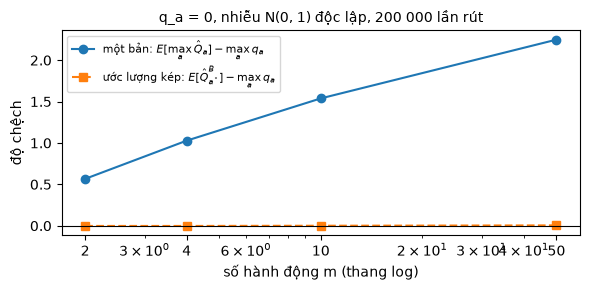

In [9]:
rng = np.random.default_rng(0)
ms, beta_single, beta_double = [2, 4, 10, 50], [], []
for m in ms:
    QA, QB = rng.standard_normal((200_000, m)), rng.standard_normal((200_000, m))   # hai bản độc lập, (200 000, m)
    beta_single.append(QA.max(axis=1).mean())                                        # E[max_a Qhat^A_a] - 0
    beta_double.append(QB[np.arange(len(QB)), QA.argmax(axis=1)].mean())             # E[Qhat^B_{a*}] - 0
    print(f"m = {m:2d}: một bản beta ≈ {beta_single[-1]:.3f} | ước lượng kép ≈ {beta_double[-1]:+.3f}")
print(f"m = 2, giá trị đúng 1/sqrt(pi) = {1 / np.sqrt(np.pi):.3f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ms, beta_single, "o-", label="một bản: $E[\\max_a \\hat Q_a]-\\max_a q_a$")
ax.plot(ms, beta_double, "s--", label="ước lượng kép: $E[\\hat Q^B_{a^*}]-\\max_a q_a$")
ax.axhline(0, color="k", lw=0.8); ax.set_xscale("log"); ax.set_xticks(ms, [str(m) for m in ms])
ax.set_xlabel("số hành động m (thang log)"); ax.set_ylabel("độ chệch"); ax.legend(fontsize=8)
ax.set_title("q_a = 0, nhiễu N(0, 1) độc lập, 200 000 lần rút", fontsize=10); fig.tight_layout(); plt.show()

**Đọc kết quả.** Khi mọi hành động có cùng giá trị đúng, độ chệch của phép cực đại tăng theo số hành động (khoảng $0{,}56$; $1{,}03$; $1{,}54$; $2{,}25$ độ lệch chuẩn của nhiễu với $m=2,4,10,50$), còn ước lượng kép cho trung bình quanh $0$ ở mọi $m$. Mệnh đề 09.2 chỉ cho dấu của $\beta$; con số cụ thể ở đây phụ thuộc phân phối chuẩn và giả thiết các giá trị đúng bằng nhau, tình huống cho độ chệch lớn nhất (Ví dụ 09.3).

Kết quả của mục này nói về một trạng thái cố định với nhiễu biết trước. Trong một thuật toán học, hai bản ước lượng phải được dựng từ dữ liệu. Mục 4 xét cách Double Q-learning dựng chúng trong trường hợp bảng.

## 4. Double Q-learning dạng bảng

**Vấn đề.** Thuật toán 09.7 (Double Q-learning, van Hasselt 2010) giữ hai bảng $Q_1$, $Q_2$; mỗi mẫu chuyển cập nhật một bảng, chọn $a^*$ bằng bảng đó và đánh giá $a^*$ bằng bảng kia. Ô mã dưới cài một bước cập nhật và kiểm bằng Ví dụ 09.7: $R=1$, $\gamma=0{,}9$, $Z=0$, $\alpha=0{,}1$, $Q_1(S,A)=4$, $Q_1(S',\cdot)=(3;\,6)$, $Q_2(S',\cdot)=(5;\,4)$; đồng xu chọn $Q_1$. Bảng $Q_1$ chọn $a^*=2$, mục tiêu $y_1=1+0{,}9\cdot4=4{,}6$, giá trị mới $4+0{,}1\cdot0{,}6=4{,}06$.

Sau đó ô mã chạy bài toán của Sutton và Barto (2018, Ví dụ 6.7): từ trạng thái A, hành động "phải" kết thúc lượt với phần thưởng $0$; hành động "trái" đưa tới B với phần thưởng $0$; tại B có $10$ hành động, mỗi hành động kết thúc lượt với phần thưởng rút từ $\mathcal N(-0{,}1;\,1)$. Giá trị đúng của "trái" là $-0{,}1<0$, nên chính sách tối ưu chọn "phải". Hành vi $\epsilon_{\mathrm{exp}}$-tham lam với $\epsilon_{\mathrm{exp}}=0{,}1$ (theo $Q_1+Q_2$ với Double Q-learning), $\alpha=0{,}1$, $\gamma=1$, $300$ lượt, $500$ lần chạy độc lập; đại lượng đo là tỉ lệ lượt chọn "trái" tại A. Tỉ lệ nhỏ nhất có thể là $\epsilon_{\mathrm{exp}}/2=0{,}05$. Hòa giữa các giá trị bảng được phá ngẫu nhiên.

a* = 2, y_1 = 4.60, Q_1(S, A) mới = 4.06, Q_2 không đổi: [[0.0, 0.0], [5.0, 4.0]]


(17 giây) lượt 1-50: Q-learning 0.862, Double Q-learning 0.281; 50 lượt cuối: 0.124 và 0.068; đỉnh Q-learning 0.95 ở lượt 25


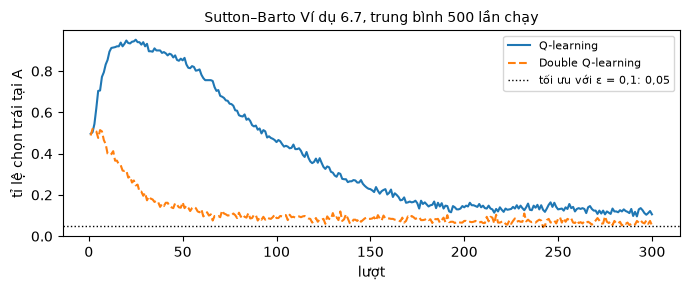

In [10]:
def double_q_update(Q_upd, Q_eval, s, a, r, s2, z, alpha, gamma):
    # Bước 2 của Thuật toán 09.7 cho bảng được đồng xu chọn: Q_upd chọn a*, Q_eval đánh giá
    a_star = int(np.argmax(Q_upd[s2]))
    y = r + gamma * (1 - z) * Q_eval[s2, a_star]
    Q_upd[s, a] += alpha * (y - Q_upd[s, a])
    return a_star, y


# Ví dụ 09.7: trạng thái 0 = S, trạng thái 1 = S'; hai hành động (chỉ số 0, 1)
Q1 = np.array([[4.0, 0.0], [3.0, 6.0]]); Q2 = np.array([[0.0, 0.0], [5.0, 4.0]])
a_star, y = double_q_update(Q1, Q2, s=0, a=0, r=1.0, s2=1, z=0, alpha=0.1, gamma=0.9)
print(f"a* = {a_star + 1}, y_1 = {y:.2f}, Q_1(S, A) mới = {Q1[0, 0]:.2f}, Q_2 không đổi: {Q2.tolist()}")
assert a_star == 1 and abs(y - 4.6) < 1e-12 and abs(Q1[0, 0] - 4.06) < 1e-12 and Q2[1].tolist() == [5.0, 4.0]


def maximization_bias_mdp(double, n_runs=500, n_eps=300, n_b=10, alpha=0.1, eps=0.1, seed=0):
    # Sutton và Barto (2018), Ví dụ 6.7. Trạng thái 0 = A (hành động 0 = trái, 1 = phải), 1 = B (n_b hành động).
    rng = np.random.default_rng(seed)
    left = np.zeros((n_runs, n_eps))
    greedy = lambda v: int(rng.choice(np.flatnonzero(v == v.max())))          # phá hòa ngẫu nhiên
    for run in range(n_runs):
        Q = [{0: np.zeros(2), 1: np.zeros(n_b)}, {0: np.zeros(2), 1: np.zeros(n_b)}]   # Q_1, Q_2 (Q_2 không dùng nếu double=False)
        for e in range(n_eps):
            beh = (lambda s: Q[0][s] + Q[1][s]) if double else (lambda s: Q[0][s])
            a = int(rng.integers(2)) if rng.random() < eps else greedy(beh(0))
            left[run, e] = (a == 0)
            if a == 1:                                   # phải: kết thúc, R = 0, Z = 1
                j = int(rng.random() < 0.5) if double else 0
                Q[j][0][1] += alpha * (0.0 - Q[j][0][1]); continue
            j = int(rng.random() < 0.5) if double else 0  # trái: tới B, R = 0, Z = 0
            boot = Q[1 - j][1][greedy(Q[j][1])] if double else Q[0][1].max()
            Q[j][0][0] += alpha * (0.0 + boot - Q[j][0][0])
            a_B = int(rng.integers(n_b)) if rng.random() < eps else greedy(beh(1))   # hành động tại B
            r = rng.normal(-0.1, 1.0)                    # tại B: kết thúc với R ~ N(-0,1; 1)
            j = int(rng.random() < 0.5) if double else 0
            Q[j][1][a_B] += alpha * (r - Q[j][1][a_B])
    return left.mean(axis=0)                             # tỉ lệ chọn trái theo lượt, (n_eps,)


t0 = time.time()
left_q, left_dq = maximization_bias_mdp(False), maximization_bias_mdp(True)
print(f"({time.time() - t0:.0f} giây) lượt 1-50: Q-learning {left_q[:50].mean():.3f}, Double Q-learning {left_dq[:50].mean():.3f}; "
      f"50 lượt cuối: {left_q[-50:].mean():.3f} và {left_dq[-50:].mean():.3f}; đỉnh Q-learning {left_q.max():.2f} ở lượt {left_q.argmax() + 1}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(np.arange(1, 301), left_q, label="Q-learning"); ax.plot(np.arange(1, 301), left_dq, ls="--", label="Double Q-learning")
ax.axhline(0.05, color="k", ls=":", lw=1, label="tối ưu với ε = 0,1: 0,05")
ax.set_xlabel("lượt"); ax.set_ylabel("tỉ lệ chọn trái tại A"); ax.legend(fontsize=8)
ax.set_title("Sutton–Barto Ví dụ 6.7, trung bình 500 lần chạy", fontsize=10); fig.tight_layout(); plt.show()

**Đọc kết quả.** Bảng của Q-learning tại A dùng $\max_bQ(B,b)$ trên mười ước lượng có nhiễu của cùng giá trị $-0{,}1$; trong các lượt đầu, cực đại đó thường dương, nên "trái" trông tốt hơn "phải" và tỉ lệ chọn trái vượt xa $0{,}5$. Double Q-learning đánh giá hành động mà một bảng chọn bằng bảng kia, nên tỉ lệ chọn trái giảm ngay từ đầu. Khi soạn, trong $50$ lượt đầu tỉ lệ chọn trái trung bình là $0{,}86$ với Q-learning (đỉnh $0{,}95$ ở lượt $25$) và $0{,}28$ với Double Q-learning. Khi số mẫu tại B tăng, nhiễu của các ước lượng giảm và cả hai tỉ lệ giảm dần; ở $50$ lượt cuối, Double Q-learning ở $0{,}07$, gần mức tối ưu $0{,}05$, còn Q-learning vẫn ở $0{,}12$. Hai bảng của Double Q-learning không độc lập hoàn toàn (mỗi bảng bootstrap từ bảng kia, hành vi dùng tổng hai bảng), nên đây là minh họa trên một bài toán, không phải kiểm chứng Mệnh đề 09.4.

Trong DQN không có hai bảng học trên hai tập mẫu riêng. Thuật toán 09.5 dùng lại hai mạng sẵn có, nên bản đánh giá $\theta^-$ là bản sao trễ của bản chọn $\theta$. Mục 5 cài đặt mục tiêu đó.

## 5. Mục tiêu Double DQN và phép đo độ chệch

**Vấn đề.** Thuật toán 09.5 khác Thuật toán 08.13 (DQN của Mnih và cộng sự, 2015) đúng ở bước 3: với mini-batch $\{(O_i,A_i,R_i,O'_i,Z_i,U_i)\}_{i=1}^b$,
$$a_i^*=\arg\max_aQ_\theta(O'_i,a),\qquad y_i=R_i+\gamma(1-Z_i)\,Q_{\theta^-}(O'_i,a_i^*),$$
cả hai trong $\operatorname{sg}$ (không lấy gradient), thay cho $y_i=R_i+\gamma(1-Z_i)\max_aQ_{\theta^-}(O'_i,a)$ của DQN. Vì $Q_{\theta^-}(O'_i,a_i^*)\le\max_aQ_{\theta^-}(O'_i,a)$, với cùng cặp mạng và cùng mẫu chuyển luôn có $y_i^{\mathrm{DDQN}}\le y_i^{\mathrm{DQN}}$; khi $Z_i=0$ và $\gamma>0$, dấu bằng xảy ra khi và chỉ khi $a_i^*$ cũng cực đại $Q_{\theta^-}(O'_i,\cdot)$, chẳng hạn khi hai mạng chọn cùng hành động.

Ô mã dưới sao chép mạng `QNet` và bộ nhớ `Replay` của Bài 08 và viết `dqn_loss` với cờ `double`. Ánh xạ: `q_net(O2).argmax(dim=1, keepdim=True)` là $a_i^*$, cỡ $(b,1)$; `tgt_net(O2).gather(1, a_star)` là $Q_{\theta^-}(O'_i,a_i^*)$; `(1.0 - Z)` là mặt nạ, cờ cắt ngắn `U` không vào mục tiêu. Notebook Bài 08 (mục 15.2) đã kiểm Ví dụ 09.6 với hàm `dqn_loss_ext`; ô dưới kiểm lại vì `dqn_loss` được viết lại với cờ `double`, rồi kiểm thêm một điều mới: bất đẳng thức $y_i^{\mathrm{DDQN}}\le y_i^{\mathrm{DQN}}$ trên một mini-batch ngẫu nhiên. Ví dụ 09.6: $R=1$, $\gamma=0{,}9$, $Z=0$, $Q_{\theta^-}(O',\cdot)=(5;\,4)$, $Q_\theta(O',\cdot)=(3;\,6)$; DQN cho $y=1+0{,}9\cdot5=5{,}5$, Double DQN cho $y=1+0{,}9\cdot4=4{,}6$; với $Z=1$, cả hai cho $y=R=1$. Hai tầng tuyến tính không hệ số tự do với quan sát $o'=1$ cho đúng các giá trị $Q$ này. Phép kiểm thứ hai dùng hai mạng `QNet` khởi tạo khác nhau, $b=256$ quan sát ngẫu nhiên cỡ $(256,4)$, $Z_i=0$, và kiểm dấu bằng xảy ra đúng ở các mẫu mà hai mạng chọn cùng hành động.

In [11]:
class QNet(nn.Module):
    # Q_theta: R^n -> R^m, hai tầng ẩn ReLU (Bài 08, mục 4)
    def __init__(self, n_obs, n_act, hidden=(128, 128)):
        super().__init__()
        layers, d = [], n_obs
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, n_act))
        self.net = nn.Sequential(*layers)

    def forward(self, o):                                  # o: (b, n) -> (b, m)
        return self.net(o)


class Replay:
    # Bộ nhớ phát lại D: bộ đệm vòng dung lượng N, sáu mảng cho (O, A, R, O', Z, U)
    def __init__(self, N, n_obs):
        self.N, self.k, self.size = N, 0, 0
        self.O = np.zeros((N, n_obs), np.float32); self.A = np.zeros(N, np.int64)
        self.R = np.zeros(N, np.float32); self.O2 = np.zeros((N, n_obs), np.float32)
        self.Z = np.zeros(N, np.float32); self.U = np.zeros(N, np.float32)

    def add(self, o, a, r, o2, z, u):
        i = self.k
        self.O[i], self.A[i], self.R[i], self.O2[i], self.Z[i], self.U[i] = o, a, r, o2, z, u
        self.k = (self.k + 1) % self.N; self.size = min(self.size + 1, self.N)   # ghi đè mẫu cũ nhất khi đầy

    def sample(self, b, rng):
        idx = rng.integers(0, self.size, size=b)           # rút đều, có hoàn lại
        f = torch.from_numpy
        return (f(self.O[idx]), f(self.A[idx]), f(self.R[idx]), f(self.O2[idx]), f(self.Z[idx]), f(self.U[idx]))


def dqn_loss(q_net, tgt_net, batch, gamma, double=False):
    O, A, R, O2, Z, U = batch                              # (b,n) (b,) (b,) (b,n) (b,) (b,)
    q = q_net(O).gather(1, A.unsqueeze(1)).squeeze(1)      # q_i = Q_theta(O_i, A_i), (b,)
    with torch.no_grad():                                  # sg(.): mục tiêu không nhận gradient
        q2_tgt = tgt_net(O2)                               # Q_{theta^-}(O'_i, .), (b, m)
        if double:                                         # Thuật toán 09.5, bước 3
            a_star = q_net(O2).argmax(dim=1, keepdim=True)          # a*_i theo mạng trực tuyến, (b, 1)
            boot = q2_tgt.gather(1, a_star).squeeze(1)              # đánh giá bằng mạng mục tiêu, (b,)
        else:                                              # Thuật toán 08.13
            boot = q2_tgt.max(dim=1).values
        y = R + gamma * (1.0 - Z) * boot                   # mặt nạ 1 - Z; U không dùng
    return ((y - q) ** 2).mean(), q.detach(), y            # L_B, q_i, y_i


# Ví dụ 09.6: một quan sát o' = 1, hai hành động
q_on, q_tg = nn.Linear(1, 2, bias=False), nn.Linear(1, 2, bias=False)
with torch.no_grad():
    q_on.weight.copy_(torch.tensor([[3.0], [6.0]]))        # Q_theta(o', .) = (3; 6)
    q_tg.weight.copy_(torch.tensor([[5.0], [4.0]]))        # Q_{theta^-}(o', .) = (5; 4)
o1 = torch.ones(1, 1)
for z in (0.0, 1.0):
    batch = (o1, torch.tensor([0]), torch.tensor([1.0]), o1, torch.tensor([z]), torch.tensor([0.0]))
    y_dqn = dqn_loss(q_on, q_tg, batch, 0.9)[2].item(); y_dd = dqn_loss(q_on, q_tg, batch, 0.9, double=True)[2].item()
    print(f"Z = {z:.0f}: y_DQN = {y_dqn:.2f}, y_Double = {y_dd:.2f}")
    assert (abs(y_dqn - 5.5) < 1e-6 and abs(y_dd - 4.6) < 1e-6) if z == 0 else (y_dqn == 1.0 and y_dd == 1.0)

# Bất đẳng thức của Ví dụ 09.6 trên mini-batch ngẫu nhiên: y_DDQN <= y_DQN, bằng nhau khi hai mạng chọn cùng hành động
torch.manual_seed(0)
net_a, net_b = QNet(4, 2, (16,)), QNet(4, 2, (16,))      # đóng vai Q_theta và Q_{theta^-}
Ob = torch.randn(256, 4); zeros = torch.zeros(256)
batch_rand = (Ob, torch.zeros(256, dtype=torch.int64), zeros, torch.randn(256, 4), zeros, zeros)   # R = 0, Z = 0
y1 = dqn_loss(net_a, net_b, batch_rand, 0.9)[2]; y2 = dqn_loss(net_a, net_b, batch_rand, 0.9, double=True)[2]
same = net_a(batch_rand[3]).argmax(1) == net_b(batch_rand[3]).argmax(1)            # cỡ (256,)
print(f"256 mẫu: y_DDQN <= y_DQN ở mọi mẫu: {bool((y2 <= y1 + 1e-6).all())}; hai mạng chọn cùng hành động ở {int(same.sum())} mẫu")
assert (y2 <= y1 + 1e-6).all() and torch.allclose(y1[same], y2[same]) and (y2[~same] < y1[~same]).all()

Z = 0: y_DQN = 5.50, y_Double = 4.60
Z = 1: y_DQN = 1.00, y_Double = 1.00
256 mẫu: y_DDQN <= y_DQN ở mọi mẫu: True; hai mạng chọn cùng hành động ở 159 mẫu


**Vòng huấn luyện.** Hàm `train_dqn` dưới là hàm cùng tên của notebook Bài 08 (mục 6) với hai thay đổi: cờ `double` trong cấu hình chọn mục tiêu, và nhật ký ghi thêm trung bình $y_i$ trên các mini-batch của mỗi $1000$ bước môi trường. Thứ tự các bước theo Thuật toán 09.5: chọn $A_t$ theo $\epsilon_{\mathrm{exp}}$-tham lam, lưu mẫu chuyển, đặt lại khi $Z\lor U$, rồi khi $\lvert\mathcal D\rvert\ge N_{\mathrm{start}}$ và $t\bmod F=0$ thì rút mini-batch, tính $y_i$, một bước Adam, tăng $k_{\mathrm{opt}}$, đồng bộ $\theta^-\leftarrow\theta$ khi $k_{\mathrm{opt}}\bmod C=0$. Hàm giữ thêm bản sao của mạng ở mốc kiểm định có tổng thưởng trung bình cao nhất trên `VALID_SEED`.

**Phép đo độ chệch.** Theo cách đo của van Hasselt, Guez và Silver (2016), hàm `value_vs_return` chạy chính sách tham lam $\pi(o)\in\arg\max_aQ_\theta(o,a)$ trên các lượt `TEST_SEED`, ghi $\max_aQ_\theta(O_t,a)$ ở mỗi bước và tính lợi tức thực tế $G_t$ lùi từ cuối lượt. Với chính sách tham lam, $\max_aQ_\theta(O_t,a)=Q_\theta(O_t,\pi(O_t))$ là ước lượng của lợi tức chiết khấu kỳ vọng từ $O_t$. Hàm trả ba đại lượng cho mỗi lượt:

- $Q_0=\max_aQ_\theta(O_0,a)$ và $G_0$; trung bình của $Q_0-G_0$ trên $100$ lượt so ước lượng của mạng với trung bình lợi tức thực tế từ đầu lượt. Ở lượt bị cắt ngắn sau $L$ bước, $G_0$ thấp hơn lợi tức của bài toán không giới hạn thời gian tối đa $\gamma^L$ lần cận của giá trị; ở CartPole, với $L=500$, phần này không quá $100\cdot0{,}99^{500}\approx0{,}66$, nhỏ so với các hiệu đo được;
- độ lệch theo bước (khóa `gap`): trung bình của $\max_aQ_\theta(O_t,a)-G_t$ trên các bước hợp lệ của lượt. Lượt kết thúc thật ($Z=1$): mọi bước. Lượt bị cắt ngắn ($U=1$): chỉ các bước $t<L-300$, vì giá trị đúng của bài toán không có giới hạn thời gian vẫn bootstrap qua bước cắt ngắn, còn $G_t$ thì dừng ở đó; phần bị mất của $G_t$ không quá $0{,}99^{300}\approx0{,}05$ lần cận của giá trị.

Hai đại lượng này đo độ lệch của giá trị so với lợi tức của chính chính sách tham lam trên các lượt đánh giá. Chúng gộp mọi nguồn sai số của mạng, không tách riêng phần do phép cực đại.

In [12]:
def linear_eps(t, t_end, e0, e1, frac):
    # epsilon_exp giảm tuyến tính từ e0 xuống e1 trong frac * t_end bước đầu, rồi giữ e1
    return max(e1, e0 - (e0 - e1) * t / max(1, frac * t_end))


def greedy_action(q_net, o):
    with torch.no_grad():
        return int(torch.argmax(q_net(torch.as_tensor(o, dtype=torch.float32).unsqueeze(0))[0]))


def net_policy(q_net):
    return lambda o, rng: greedy_action(q_net, o)          # chính sách tham lam theo Q_theta


def make_optimizer(params, lr):
    try:                                                   # Adam bản gộp, cùng quy tắc, nhanh hơn trên CPU
        return torch.optim.Adam(params, lr=lr, fused=True)
    except (RuntimeError, TypeError):
        return torch.optim.Adam(params, lr=lr)


def train_dqn(env_id, cfg, agent_seed=AGENT_SEED, n_ckpt=10):
    torch.manual_seed(agent_seed); rng = np.random.default_rng(agent_seed)
    train_seed = 20_000 + 100_000 * agent_seed               # agent_seed = 1 -> TRAIN_SEED
    env, env_valid = make_env(env_id), make_env(env_id)
    n_obs, n_act = env.observation_space.shape[0], env.action_space.n
    q_net, tgt_net = QNet(n_obs, n_act, cfg["hidden"]), QNet(n_obs, n_act, cfg["hidden"])
    tgt_net.load_state_dict(q_net.state_dict())              # theta^- <- theta
    opt = make_optimizer(q_net.parameters(), cfg["lr"])
    D = Replay(cfg["N"], n_obs)
    t_end, b, F, C, N_start = cfg["t_end"], cfg["b"], cfg["F"], cfg["C"], cfg["N_start"]
    ep, t, k_opt, ep_ret = 0, 0, 0, 0.0
    o, _ = env.reset(seed=train_seed + ep)
    log = dict(ep_t=[], ep_ret=[], loss_t=[], qmean=[], ymean=[], ckpt_t=[], ckpt_mean=[])
    acc = [0.0, 0.0, 0]                                      # tổng TB q_i, tổng TB y_i, số bước tối ưu trong 1000 bước
    ckpts = {int(round(t_end * (j + 1) / n_ckpt)) for j in range(n_ckpt)}
    best_mean, best_net, t0 = -np.inf, None, time.time()
    while t < t_end:
        eps = linear_eps(t, t_end, cfg["eps_start"], cfg["eps_end"], cfg["eps_frac"])
        a = int(rng.integers(n_act)) if rng.random() < eps else greedy_action(q_net, o)   # bước 1
        o2, r, term, trunc, info = env.step(a)
        D.add(o, a, r, o2, float(term), float(trunc)); ep_ret += r                        # lưu, o2 lấy trước reset
        if term or trunc:                                                                 # đặt lại khi Z or U
            log["ep_t"].append(t + 1); log["ep_ret"].append(ep_ret)
            ep += 1; ep_ret = 0.0; o, _ = env.reset(seed=train_seed + ep)
        else:
            o = o2
        t += 1
        if D.size >= N_start and t % F == 0:                                              # bước 2
            L, q, y = dqn_loss(q_net, tgt_net, D.sample(b, rng), cfg["gamma"], cfg["double"])  # bước 3
            opt.zero_grad(); L.backward(); opt.step(); k_opt += 1                         # bước 4
            if k_opt % C == 0:                                                            # bước 5
                tgt_net.load_state_dict(q_net.state_dict())
            acc[0] += float(q.mean()); acc[1] += float(y.mean()); acc[2] += 1
        if t % 1000 == 0 and acc[2]:
            log["loss_t"].append(t); log["qmean"].append(acc[0] / acc[2]); log["ymean"].append(acc[1] / acc[2])
            acc = [0.0, 0.0, 0]
        if t in ckpts:                                       # mốc kiểm định: chính sách tham lam, 10 lượt VALID_SEED
            res = evaluate_policy(env_valid, net_policy(q_net), N_VALID, VALID_SEED, cfg["gamma"])
            log["ckpt_t"].append(t); log["ckpt_mean"].append(res["total"].mean())
            if res["total"].mean() > best_mean:
                best_mean, best_net = res["total"].mean(), copy.deepcopy(q_net); log["best_t"] = t
    log.update(k_opt=k_opt, n_episodes=ep, train_secs=time.time() - t0)
    return q_net, {k: (np.array(v) if isinstance(v, list) else v) for k, v in log.items()}, best_net

In [13]:
def value_vs_return(q_net, env, n_episodes, seed, gamma=GAMMA, cut=300):
    # Mỗi lượt tham lam: max_a Q_theta(O_t, a), G_t = R_{t+1} + gamma G_{t+1}; bước hợp lệ như mô tả ở trên
    out = dict(Q0=[], G0=[], gap=[], total=[], score=[], seeds=[], Q=[], G=[])
    for i in range(n_episodes):
        o, _ = env.reset(seed=seed + i)
        obs, rs, info = [], [], {}
        while True:
            obs.append(o)
            o, r, term, trunc, info = env.step(greedy_action(q_net, o))
            rs.append(r)
            if term or trunc:
                break
        with torch.no_grad():
            Q = q_net(torch.as_tensor(np.array(obs), dtype=torch.float32)).max(dim=1).values.numpy()   # (L,)
        G = np.zeros(len(rs)); acc = 0.0
        for t in range(len(rs) - 1, -1, -1):
            acc = rs[t] + gamma * acc; G[t] = acc
        valid = len(rs) if term else max(0, len(rs) - cut)
        out["Q0"].append(Q[0]); out["G0"].append(G[0]); out["total"].append(sum(rs))
        out["gap"].append((Q[:valid] - G[:valid]).mean() if valid else np.nan); out["score"].append(info.get("score", np.nan)); out["seeds"].append(seed + i)
        if i == 0:
            out["Q"], out["G"] = Q, G                        # lượt đầu, để vẽ
    return {k: (np.array(v) if k not in ("Q", "G") else v) for k, v in out.items()}

## 6. DQN và Double DQN trên CartPole

**Vấn đề.** CartPole có cận $1/(1-\gamma)=100$ cho mọi giá trị đúng, nên đây là môi trường đầu tiên để đo đánh giá cao bằng một con số, và một lần huấn luyện đủ ngắn để chạy trực tiếp.

**Cấu hình.** Double DQN dùng nguyên siêu tham số của DQN và chỉ đổi mục tiêu, như van Hasselt, Guez và Silver (2016) làm trên Atari ("the exact same hyper-parameters as for DQN"). Cấu hình của cả ba môi trường là cấu hình đã chọn ở notebook Bài 08 (mục 7–10), không chỉnh lại:

| Ký hiệu | Ý nghĩa | CartPole | Lunar Lander | Flappy Bird |
|---|---|---|---|---|
| $t_{\mathrm{end}}$ | ngân sách bước môi trường | $50\,000$ | $100\,000$ | $300\,000$ |
| $N$ | dung lượng của $\mathcal D$ | $50\,000$ | $50\,000$ | $100\,000$ |
| $b$ | cỡ mini-batch | $64$ | $128$ | $64$ |
| $N_{\mathrm{start}}$ | số mẫu trước bước tối ưu đầu | $1000$ | $1000$ | $1000$ |
| $F$ | số bước môi trường giữa hai bước tối ưu | $1$ | $1$ | $4$ |
| $C$ | số bước tối ưu giữa hai lần đồng bộ | $200$ | $250$ | $250$ |
| $\eta$ | tốc độ học của Adam | $10^{-3}$ | $6{,}3\cdot10^{-4}$ | $5\cdot10^{-4}$ |
| $\epsilon_{\mathrm{exp}}$ | đầu → cuối, trong phần $f_\epsilon$ của $t_{\mathrm{end}}$ | $1\to0{,}05$, $f_\epsilon=0{,}2$ | $1\to0{,}1$, $f_\epsilon=0{,}12$ | $0{,}1\to0{,}001$, $f_\epsilon=0{,}1$ |
| $h$ | số nút mỗi tầng ẩn (hai tầng) | $64$ | $128$ | $128$ |

Ô mã dưới huấn luyện DQN rồi Double DQN trên CartPole với cùng hạt giống `AGENT_SEED` (khoảng $2$ phút mỗi lần trên CPU hai luồng khi soạn). Hai lần chạy có cùng khởi tạo $\theta$ và cùng các lượt huấn luyện đầu; chúng tách nhau từ bước tối ưu đầu tiên mà hai mạng chọn khác hành động tại $O'_i$. Số bước tối ưu $t_{\mathrm{end}}-N_{\mathrm{start}}+1=49\,001$ không phụ thuộc mục tiêu.

In [14]:
BASE = dict(gamma=GAMMA, double=False)
CFG = {
    "CartPole-v1": dict(BASE, t_end=50_000, N=50_000, b=64, N_start=1000, F=1, C=200, lr=1e-3,
                        eps_start=1.0, eps_end=0.05, eps_frac=0.2, hidden=(64, 64)),
    "LunarLander-v3": dict(BASE, t_end=100_000, N=50_000, b=128, N_start=1000, F=1, C=250, lr=6.3e-4,
                           eps_start=1.0, eps_end=0.1, eps_frac=0.12, hidden=(128, 128)),
    "FlappyBird-v0": dict(BASE, t_end=300_000, N=100_000, b=64, N_start=1000, F=4, C=250, lr=5e-4,
                          eps_start=0.1, eps_end=0.001, eps_frac=0.1, hidden=(128, 128)),
}
env_id = "CartPole-v1"
nets_cp, logs_cp = {}, {}
for name, dbl in [("DQN", False), ("Double DQN", True)]:
    nets_cp[name], logs_cp[name], _ = train_dqn(env_id, dict(CFG[env_id], double=dbl))
    lg = logs_cp[name]
    print(f"{name:<11} {lg['train_secs']:.0f} giây | k_opt = {lg['k_opt']} | số lượt huấn luyện = {lg['n_episodes']}")
    assert lg["k_opt"] == CFG[env_id]["t_end"] - CFG[env_id]["N_start"] + 1

DQN         112 giây | k_opt = 49001 | số lượt huấn luyện = 355


Double DQN  129 giây | k_opt = 49001 | số lượt huấn luyện = 384


Ô mã dưới đánh giá hai chính sách tham lam trên $100$ lượt `TEST_SEED` bằng `value_vs_return`, in điểm, $Q_0$, $G_0$, $Q_0-G_0$ và độ lệch theo bước, rồi vẽ hai hình. Hình trái: trung bình $q_i$ trên các mini-batch theo bước $t$ của hai lần huấn luyện, cùng cận $1/(1-\gamma)=100$; mọi phần thưởng của CartPole bằng $1$, nên giá trị đúng của mọi cặp quan sát–hành động không vượt cận này. Hình phải: $\max_aQ_\theta(O_t,a)$ và $G_t$ dọc lượt đầu của `TEST_SEED` của từng chính sách. Một lượt bị cắt ngắn ở bước $500$ có $G_t$ giảm về $1$ ở cuối lượt; phần đó không so được với giá trị của bài toán không có giới hạn thời gian. Một lượt kết thúc sớm ($Z=1$) có $G_t$ đúng là lợi tức tới khi cột đổ.

DQN         tổng thưởng  500.0 | Q_0 = 108.54, G_0 =  99.34, Q_0 - G_0 =   9.20 ± 0.01 (SE theo lượt) | gap =  10.12
Double DQN  tổng thưởng  375.9 | Q_0 = 112.70, G_0 =  96.73, Q_0 - G_0 =  15.97 ± 0.23 (SE theo lượt) | gap =  12.58
Double DQN - DQN, tổng thưởng: -124.1 ± 18.5 (khoảng 95%, ghép cặp trên 100 lượt)
Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): DQN 500,0, Q_0 = 108,54, Q_0 - G_0 = 9,20; Double DQN 375,9, Q_0 = 112,70, Q_0 - G_0 = 15,97; hiệu -124,1 ± 18,5


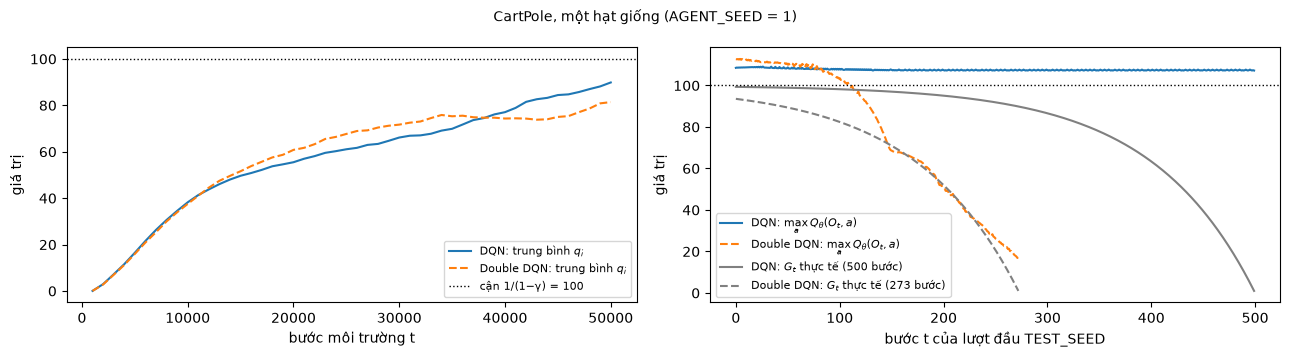

In [15]:
vr_cp = {name: value_vs_return(net, envs[env_id], N_TEST, TEST_SEED) for name, net in nets_cp.items()}
for name, v in vr_cp.items():
    d = v["Q0"] - v["G0"]
    print(f"{name:<11} tổng thưởng {v['total'].mean():6.1f} | Q_0 = {v['Q0'].mean():6.2f}, G_0 = {v['G0'].mean():6.2f}, "
          f"Q_0 - G_0 = {d.mean():6.2f} ± {d.std(ddof=1) / np.sqrt(N_TEST):.2f} (SE theo lượt) | gap = {np.nanmean(v['gap']):6.2f}")
m, h = paired_difference(vr_cp["Double DQN"], vr_cp["DQN"], "total")
print(f"Double DQN - DQN, tổng thưởng: {m:.1f} ± {h:.1f} (khoảng 95%, ghép cặp trên 100 lượt)")
print("Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): DQN 500,0, Q_0 = 108,54, Q_0 - G_0 = 9,20; "
      "Double DQN 375,9, Q_0 = 112,70, Q_0 - G_0 = 15,97; hiệu -124,1 ± 18,5")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for (name, lg), ls in zip(logs_cp.items(), ["-", "--"]):
    axes[0].plot(lg["loss_t"], lg["qmean"], ls=ls, label=f"{name}: trung bình $q_i$")
    axes[1].plot(vr_cp[name]["Q"], ls=ls, label=rf"{name}: $\max_a Q_\theta(O_t,a)$")
axes[0].axhline(100, color="k", ls=":", lw=1, label="cận 1/(1−γ) = 100"); axes[0].set_xlabel("bước môi trường t")
for (name, v), ls in zip(vr_cp.items(), ["-", "--"]):
    axes[1].plot(v["G"], color="0.5", ls=ls, lw=1.5, label=f"{name}: $G_t$ thực tế ({len(v['G'])} bước)")
axes[1].axhline(100, color="k", ls=":", lw=1); axes[1].set_xlabel("bước t của lượt đầu TEST_SEED")
for ax in axes:
    ax.set_ylabel("giá trị"); ax.legend(fontsize=8)
fig.suptitle("CartPole, một hạt giống (AGENT_SEED = 1)", fontsize=10); fig.tight_layout(); plt.show()

**Đọc kết quả của lần chạy trực tiếp.** Với torch 2.15.0+cpu và hai luồng, lần chạy cho đúng các số tham chiếu in ở dòng cuối của ô trên. Các số dưới đây là số tham chiếu khi soạn; với phiên bản khác, số in ra có thể khác. Với các số tham chiếu, DQN giữ cột đủ $500$ bước ở cả $100$ lượt, Double DQN đạt trung bình $375{,}9$; cả hai mạng báo $Q_0$ trên cận $100$ ($108{,}5$ và $112{,}7$), nên theo Ví dụ 09.1 cả hai có đánh giá cao chắc chắn. Ở hạt giống này, $Q_0-G_0$ của Double DQN lớn hơn của DQN ($16{,}0$ so với $9{,}2$). Hiệu ghép cặp về tổng thưởng, $-124{,}1\pm18{,}5$ trên $100$ lượt, có khoảng $95\%$ không chứa $0$, nhưng nó chỉ so hai mạng cụ thể này trên cùng các lượt đánh giá, không so hai thuật toán: độ biến thiên giữa các lần huấn luyện chỉ đo được khi có nhiều hạt giống tác tử, và bảng dưới cho hiệu $-0{,}2$. Ở lượt đầu, lượt của Double DQN kết thúc ở bước $273$; từ khoảng bước $150$, giá trị mạng báo giảm cùng $G_t$ và bám sát nó. Bảng tám hạt giống chạy với một luồng CPU (khóa `threads` trong dữ liệu nhúng); ở hạt giống $1$, nó cho $500$ ở cả hai thuật toán và $Q_0-G_0$ là $12{,}5$ và $17{,}6$ (dòng đầu của mỗi danh sách dưới): cùng mã, cùng hạt giống, chỉ khác số luồng CPU, đã cho hai chính sách khác nhau.

**Dữ liệu chạy khi soạn.** Ô mã dưới nạp các bảng đã nhúng sẵn. Mỗi lần chạy dùng cùng hàm `train_dqn`, cấu hình ở bảng trên, hạt giống tác tử $s=1,\dots,8$ (lượt huấn luyện thứ $k$ dùng hạt giống $20\,000+100\,000\,s+k$), một luồng CPU. Với mỗi lần chạy, các số được ghi: điểm của chính sách cuối và của mốc kiểm định tốt nhất trên $100$ lượt `TEST_SEED`, điểm trên $100$ lượt `SEL_SEED`, trung bình $Q_0$, $G_0$, $Q_0-G_0$, độ lệch theo bước (khóa `gap`) trên $100$ lượt `TEST_SEED`, đỉnh trung bình $q_i$ ($\max_t$ của trung bình $q_i$, khóa `qmax`), thời gian huấn luyện, số luồng CPU (khóa `threads`). Điểm là tổng thưởng (CartPole, Lunar Lander) hoặc số ống (Flappy Bird). Với DQN, các lần chạy trùng cấu hình gốc của Bài 08 và cho lại đúng số liệu đã công bố ở đó (Lunar Lander: $187{,}3\pm21{,}6$ trên `TEST_SEED`).

In [16]:
TABLES = json.loads(r'''{"dqn":{"CartPole-v1":{"ddqn":{"1":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":116.96,"G0":99.34,"Q0G0":17.62,"gap":19.33,"qmax":92.07,"secs":95,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.05,2.82,6.98,11.23,15.98,20.87,25.45,30.35,34.89,38.84,42.9,46.73,50.14,52.69,54.55,57.01,58.93,61.3,63.51,64.62,65.35,67.23,69.0,69.19,69.99,70.82,71.03,71.52,71.95,73.05,74.5,75.14,75.73,75.72,75.83,76.55,77.21,77.15,78.16,78.03,79.24,80.1,80.6,82.03,84.15,85.55,87.17,88.21,90.74,92.07],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[247.2,220.0,199.6,142.6,219.3,154.9,164.3,475.2,500.0,500.0]}},"2":{"row":{"final":500.0,"best":499.71,"sel":500.0,"Q0":104.21,"G0":99.34,"Q0G0":4.87,"gap":6.23,"qmax":85.11,"secs":104,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[-0.07,2.79,7.02,11.43,16.71,22.24,27.13,31.67,36.09,40.09,43.9,47.03,50.14,52.14,54.01,56.19,57.89,59.17,60.14,61.31,62.51,62.74,63.59,63.68,64.37,64.85,64.81,64.72,64.37,65.31,65.44,66.51,68.3,69.05,70.06,71.03,73.28,74.06,74.82,75.82,76.91,77.77,79.31,79.04,79.58,81.53,82.96,84.51,85.11,84.82],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[191.2,230.7,483.6,126.3,126.7,500.0,301.3,500.0,500.0,500.0]}},"3":{"row":{"final":246.26,"best":466.61,"sel":248.71,"Q0":103.65,"G0":91.54,"Q0G0":12.11,"gap":24.44,"qmax":79.56,"secs":96,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.02,2.79,7.1,11.55,16.08,20.69,24.91,28.97,32.6,36.1,38.97,41.44,43.56,45.45,46.67,47.92,49.81,51.81,53.61,55.08,56.53,58.01,59.26,59.98,60.57,61.6,62.37,62.82,63.78,65.04,66.27,67.03,67.42,68.52,69.02,68.91,69.7,70.32,70.65,71.14,71.52,71.92,73.02,73.68,74.41,75.34,77.15,78.14,78.58,79.56],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[245.5,116.1,208.9,158.4,139.5,167.6,500.0,189.6,500.0,247.6]}},"4":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":102.19,"G0":99.34,"Q0G0":2.84,"gap":4.44,"qmax":75.09,"secs":100,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[-0.03,2.81,7.08,11.46,16.34,21.04,25.72,29.83,33.02,36.2,38.89,41.27,43.67,45.47,47.07,49.06,50.97,52.97,54.22,55.29,56.43,57.09,57.7,58.36,58.82,59.52,60.71,60.96,61.59,60.62,61.05,61.52,61.41,62.02,62.17,62.38,62.44,63.11,63.77,65.01,66.09,66.78,67.37,67.61,68.57,69.67,70.7,72.15,73.64,75.09],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[215.5,123.0,116.0,137.3,161.4,172.0,144.8,222.0,500.0,500.0]}},"5":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":105.7,"G0":99.34,"Q0G0":6.36,"gap":9.73,"qmax":96.74,"secs":124,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.02,2.83,6.95,11.21,16.22,21.22,25.9,30.45,34.73,38.15,41.3,44.23,47.04,49.1,51.79,53.63,55.31,57.0,58.94,60.75,62.57,63.97,65.86,67.12,67.94,69.77,71.71,72.84,74.62,76.63,78.14,78.58,79.51,80.89,82.49,83.94,84.49,85.12,86.11,85.63,86.12,86.97,87.91,90.16,91.77,93.25,94.69,95.92,96.34,96.74],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[248.2,197.7,222.2,301.3,248.7,500.0,500.0,500.0,500.0,500.0]}},"6":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":134.82,"G0":99.34,"Q0G0":35.48,"gap":35.98,"qmax":112.14,"secs":118,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.03,2.74,6.82,11.31,16.6,21.41,26.52,30.97,35.31,39.51,43.47,47.45,50.78,52.88,54.53,56.95,59.58,61.02,62.26,63.82,66.2,67.57,67.26,67.34,68.47,69.48,70.78,72.11,72.72,73.97,75.78,77.7,79.1,78.77,80.69,82.8,84.94,85.04,85.65,86.45,89.04,92.52,95.9,99.25,101.25,103.74,106.59,107.91,109.54,112.14],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[232.4,172.3,202.6,374.6,480.4,500.0,116.9,500.0,500.0,500.0]}},"7":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":109.16,"G0":99.34,"Q0G0":9.81,"gap":3.53,"qmax":86.54,"secs":99,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[-0.12,2.7,6.95,11.37,15.87,20.71,25.17,29.42,33.54,37.24,40.61,43.62,46.02,47.48,50.07,52.33,54.8,56.64,58.85,60.81,62.5,64.66,66.47,67.61,68.63,69.81,71.11,72.52,73.81,74.76,75.61,76.49,77.52,78.14,78.59,78.73,78.71,78.89,80.16,80.69,81.09,80.95,81.93,81.71,83.19,83.28,84.45,84.97,85.33,86.54],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[351.3,116.1,120.3,390.9,162.0,169.9,500.0,500.0,500.0,500.0]}},"8":{"row":{"final":499.4,"best":500.0,"sel":498.36,"Q0":99.55,"G0":99.34,"Q0G0":0.21,"gap":-2.64,"qmax":89.06,"secs":119,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.1,2.88,7.09,11.67,16.82,21.87,26.9,31.02,34.7,38.62,42.04,44.89,47.22,49.16,51.33,53.02,55.21,57.82,59.95,62.03,63.93,65.84,67.58,69.41,71.46,73.51,74.25,75.3,76.27,77.3,78.67,79.54,80.78,81.38,82.03,82.97,83.5,83.14,83.84,83.24,83.12,82.86,83.96,85.06,85.43,84.55,85.79,87.6,88.42,89.06],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[290.1,251.4,246.5,322.7,304.7,157.9,101.9,255.6,500.0,499.9]}}},"dqn":{"1":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":111.81,"G0":99.34,"Q0G0":12.46,"gap":12.7,"qmax":87.88,"secs":90,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.05,2.97,7.2,11.58,16.56,21.88,26.48,31.15,35.31,39.21,42.55,45.57,48.23,50.6,52.76,54.52,56.0,58.71,59.73,60.65,61.85,62.49,63.45,64.28,65.7,67.11,67.47,68.21,68.81,69.88,70.5,71.88,72.91,74.15,75.21,76.78,78.86,78.92,79.64,80.39,80.29,80.85,81.87,82.82,83.99,83.9,84.71,86.07,86.62,87.88],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[289.7,227.0,134.5,155.5,500.0,500.0,189.3,333.0,500.0,500.0]}},"2":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":110.3,"G0":99.34,"Q0G0":10.96,"gap":8.93,"qmax":97.52,"secs":89,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[-0.07,2.79,6.8,11.06,15.73,20.77,25.64,30.48,34.97,38.63,41.87,44.42,46.4,48.44,51.29,53.6,55.67,57.05,57.93,59.36,60.98,61.98,62.72,64.46,65.69,66.17,67.99,68.71,69.81,71.16,71.8,72.43,72.89,74.71,75.74,77.29,78.39,79.92,82.03,83.9,84.83,86.27,87.67,88.75,89.52,91.34,93.82,95.08,96.72,97.52],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[224.0,251.1,407.3,497.3,139.2,476.3,500.0,220.2,500.0,500.0]}},"3":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":117.38,"G0":99.34,"Q0G0":18.04,"gap":17.23,"qmax":92.23,"secs":112,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.02,2.8,6.99,11.15,15.79,20.15,24.43,29.04,32.85,36.38,39.41,41.99,44.59,46.88,49.85,52.12,54.32,56.61,58.94,60.73,61.78,63.06,64.0,64.58,65.58,66.91,67.37,68.26,69.56,70.51,71.31,72.09,72.62,73.11,73.55,74.71,76.5,77.61,79.29,80.39,81.45,82.45,84.42,85.28,86.39,87.44,88.62,89.46,91.0,92.23],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[215.1,185.8,233.6,135.3,99.0,160.1,305.4,497.7,500.0,500.0]}},"4":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":108.57,"G0":99.34,"Q0G0":9.23,"gap":10.89,"qmax":90.06,"secs":85,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[-0.03,2.81,7.02,11.63,16.68,21.45,26.52,31.18,35.04,38.55,41.67,44.08,46.74,49.78,52.15,54.6,56.35,57.3,58.77,59.8,61.0,62.21,63.3,64.65,66.35,67.48,67.2,68.01,68.59,69.47,70.45,71.49,72.48,73.36,73.75,75.0,76.72,77.33,78.15,79.5,81.86,82.58,83.78,84.69,86.01,86.91,87.98,89.0,89.6,90.06],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[314.7,245.0,135.2,250.3,212.1,150.5,258.4,239.0,352.6,500.0]}},"5":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":120.95,"G0":99.34,"Q0G0":21.6,"gap":19.26,"qmax":112.13,"secs":102,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.02,2.82,6.91,11.23,16.24,21.03,25.65,29.99,34.54,38.7,43.01,47.39,51.2,53.82,57.42,61.77,64.89,67.45,69.67,71.89,74.79,78.07,80.03,81.55,82.69,84.23,85.53,87.47,88.8,90.1,90.98,92.04,93.35,95.4,96.78,99.43,100.06,101.56,101.26,101.56,101.95,102.03,101.55,102.44,102.82,103.51,104.82,106.55,110.07,112.13],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[304.8,500.0,500.0,500.0,249.2,210.8,136.5,161.9,143.5,500.0]}},"6":{"row":{"final":247.49,"best":500.0,"sel":246.97,"Q0":114.79,"G0":91.68,"Q0G0":23.11,"gap":67.24,"qmax":110.62,"secs":105,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.03,2.85,7.07,11.24,16.18,20.72,25.06,29.1,33.04,36.1,38.58,40.86,44.14,47.18,48.73,50.68,53.11,54.96,56.87,58.73,60.41,61.95,62.84,63.46,64.12,65.64,67.7,68.6,69.92,70.5,70.29,71.35,72.42,73.04,73.39,74.04,75.54,78.05,80.71,83.75,85.52,88.43,91.61,94.89,97.88,101.53,103.6,105.45,107.89,110.62],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[183.1,172.4,138.3,203.6,224.5,199.3,268.4,500.0,500.0,245.4]}},"7":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":118.3,"G0":99.34,"Q0G0":18.96,"gap":20.57,"qmax":100.67,"secs":110,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[-0.12,2.73,7.17,11.76,16.45,21.39,26.38,31.01,35.29,39.74,44.18,47.43,50.67,53.22,55.66,57.48,59.26,60.38,61.33,61.8,62.68,63.68,65.71,66.79,67.02,68.57,69.91,71.67,72.68,74.32,76.28,78.41,80.57,80.96,82.61,84.51,86.33,87.01,89.69,92.16,93.37,95.35,95.55,96.66,97.75,98.97,100.34,100.49,100.3,100.67],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[226.0,182.8,101.9,152.8,198.8,500.0,500.0,500.0,293.8,500.0]}},"8":{"row":{"final":500.0,"best":500.0,"sel":500.0,"Q0":111.11,"G0":99.34,"Q0G0":11.77,"gap":10.01,"qmax":92.85,"secs":108,"threads":1},"curves":{"qt":[1000,2000,3000,4000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,21000,22000,23000,24000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000],"q":[0.1,2.92,7.18,11.65,16.65,21.41,26.21,30.23,34.0,37.6,40.37,42.97,46.18,48.27,50.05,51.99,53.83,55.94,58.34,60.78,62.24,63.87,64.59,65.7,66.34,67.35,69.46,70.86,72.92,74.24,75.18,76.75,77.99,79.66,81.94,82.28,83.37,83.83,84.72,85.03,85.52,86.27,87.33,88.29,88.64,89.91,90.57,90.75,91.32,92.85],"ct":[5000,10000,15000,20000,25000,30000,35000,40000,45000,50000],"c":[211.0,158.9,122.9,200.5,310.0,500.0,333.0,170.4,500.0,500.0]}}}},"FlappyBird-v0":{"ddqn":{"1":{"row":{"final":35.09,"best":35.09,"sel":37.89,"Q0":8.33,"G0":10.91,"Q0G0":-2.58,"gap":-2.49,"qmax":8.15,"secs":290,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.01,0.01,0.26,0.58,0.88,1.24,1.42,1.57,1.62,1.73,1.94,1.99,2.21,2.28,2.29,2.46,2.57,2.69,3.06,3.35,3.74,3.8,4.2,4.24,4.25,4.42,4.56,4.57,4.78,5.07,5.2,5.36,5.35,5.58,5.6,5.56,5.65,5.85,5.85,6.02,6.06,5.97,6.25,6.42,6.36,6.3,6.42,6.44,6.55,6.44,6.7,7.05,7.24,7.4,7.41,7.68,7.75,7.86,7.83,7.96],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.5,1.8,0.8,0.9,3.0,2.8,6.6,7.0,27.5,30.3]}},"2":{"row":{"final":45.38,"best":45.38,"sel":42.14,"Q0":10.3,"G0":11.44,"Q0G0":-1.14,"gap":-1.32,"qmax":10.39,"secs":308,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.07,0.4,0.72,1.0,1.36,1.6,1.81,1.99,2.2,2.5,2.57,2.82,2.88,3.06,3.31,3.59,3.63,3.69,3.74,3.81,4.05,4.23,4.4,4.8,5.39,5.39,5.5,5.66,5.94,6.13,6.47,6.73,6.99,7.0,7.2,7.23,7.5,7.82,7.94,8.11,8.31,8.58,8.74,8.83,9.05,9.29,9.44,9.59,9.94,9.96,10.2,10.22,10.08,10.32,10.22,10.38,10.38,10.34,10.39,10.19],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[2.1,1.4,5.1,10.6,17.5,20.8,38.8,31.6,32.2,39.4]}},"3":{"row":{"final":42.18,"best":43.89,"sel":39.33,"Q0":11.02,"G0":11.02,"Q0G0":0.0,"gap":-1.19,"qmax":9.92,"secs":319,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.04,0.18,0.53,0.85,1.18,1.43,1.62,1.7,1.83,1.84,1.9,2.06,2.11,2.31,2.4,2.49,2.79,3.01,3.12,3.44,3.69,3.88,4.03,4.06,4.21,4.56,4.71,4.86,5.18,5.35,5.54,5.86,5.7,5.65,5.75,5.96,6.06,6.34,6.43,6.37,6.57,6.93,7.09,7.22,7.38,7.41,7.75,7.73,7.86,7.81,7.95,8.17,8.43,8.53,8.84,9.25,9.37,9.57,9.61,9.83],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.6,1.3,4.7,5.8,15.0,24.0,28.5,46.4,19.6,35.0]}},"4":{"row":{"final":21.33,"best":21.33,"sel":23.78,"Q0":10.25,"G0":10.8,"Q0G0":-0.55,"gap":0.64,"qmax":10.31,"secs":310,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.07,0.23,0.52,0.9,1.24,1.56,1.71,1.81,2.07,2.28,2.34,2.55,2.61,2.65,2.7,2.99,3.21,3.44,3.8,3.99,4.16,4.37,4.44,4.71,4.72,4.85,5.0,5.21,5.14,5.32,5.48,5.73,5.87,6.31,6.34,6.36,6.65,6.94,7.05,7.15,7.2,7.55,7.57,7.76,8.05,8.12,8.2,8.31,8.11,8.55,8.78,9.19,9.34,9.76,10.13,10.23,10.04,9.92,10.05,9.97],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.4,2.6,1.4,9.1,19.8,25.9,21.6,17.1,18.7,28.9]}},"5":{"row":{"final":37.71,"best":37.71,"sel":33.88,"Q0":8.97,"G0":11.38,"Q0G0":-2.41,"gap":-3.65,"qmax":7.59,"secs":316,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.0,-0.7,-0.78,-0.37,0.09,0.67,0.96,1.32,1.59,1.82,2.05,2.22,2.4,2.36,2.44,2.37,2.4,2.67,2.73,2.98,2.97,3.22,3.47,3.5,3.73,3.78,3.93,3.84,3.82,3.95,4.03,4.33,4.47,4.82,4.69,4.71,4.71,4.73,4.89,4.97,5.13,5.37,5.19,5.44,5.44,5.57,5.68,5.81,6.02,6.03,6.25,6.58,6.66,6.71,6.69,6.96,7.01,7.14,7.18,7.19],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.5,1.5,0.5,3.6,3.4,4.9,4.1,10.0,21.3,28.3]}},"6":{"row":{"final":5.71,"best":39.51,"sel":6.9,"Q0":9.32,"G0":6.37,"Q0G0":2.94,"gap":3.92,"qmax":8.92,"secs":319,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.1,-0.01,0.2,0.65,1.04,1.35,1.66,1.9,2.02,2.19,2.39,2.48,2.67,2.82,2.97,3.06,3.29,3.57,3.46,3.72,3.7,4.17,4.51,4.57,5.04,5.1,5.33,5.3,5.35,5.56,5.86,5.81,5.94,6.22,6.06,6.1,6.05,6.21,6.34,6.62,6.57,6.83,6.91,7.09,7.22,7.54,7.56,7.71,7.83,7.89,7.97,8.0,8.26,8.21,8.39,8.29,8.45,8.74,8.86,8.76],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.5,2.3,1.7,2.3,6.5,3.7,16.9,3.8,32.7,10.8]}},"7":{"row":{"final":22.94,"best":38.32,"sel":20.39,"Q0":9.71,"G0":10.2,"Q0G0":-0.49,"gap":0.39,"qmax":9.36,"secs":302,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.08,0.05,0.36,0.68,1.01,1.38,1.58,1.69,1.8,1.92,1.99,2.09,2.12,2.25,2.29,2.2,2.32,2.35,2.53,2.66,2.91,3.02,3.19,3.3,3.5,3.54,3.99,4.07,4.29,4.53,4.68,4.94,5.2,5.32,5.38,5.78,5.88,5.8,5.95,6.39,6.7,6.83,6.98,7.27,7.42,7.61,7.61,7.66,7.59,7.78,7.65,7.9,8.22,8.2,8.28,8.28,8.56,8.87,8.95,9.17],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.6,1.5,2.7,0.0,3.6,17.9,7.2,31.1,26.7,20.5]}},"8":{"row":{"final":21.72,"best":21.72,"sel":21.94,"Q0":9.43,"G0":10.86,"Q0G0":-1.42,"gap":-1.17,"qmax":8.72,"secs":290,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.09,0.19,0.51,0.78,0.98,1.25,1.41,1.49,1.66,1.84,2.05,2.27,2.41,2.56,2.76,2.84,3.21,3.27,3.31,3.36,3.65,3.83,4.08,4.24,4.41,4.7,4.99,5.16,5.25,5.32,5.48,5.65,5.79,5.83,5.9,5.94,6.01,6.29,6.42,6.68,6.81,6.71,6.89,7.12,7.13,7.18,7.55,7.56,7.73,8.13,8.2,8.09,8.16,8.24,8.34,8.44,8.39,8.45,8.59,8.72],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.5,0.4,5.3,3.5,3.6,1.8,10.8,13.5,15.8,20.8]}}},"dqn":{"1":{"row":{"final":38.87,"best":38.87,"sel":37.03,"Q0":8.85,"G0":11.26,"Q0G0":-2.41,"gap":-3.21,"qmax":8.41,"secs":281,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.01,-0.08,0.23,0.51,0.84,1.15,1.43,1.65,1.86,1.91,1.98,2.11,2.16,2.19,2.28,2.33,2.54,2.7,2.86,2.93,3.32,3.45,3.61,3.7,3.97,4.18,4.31,4.72,5.05,5.09,5.1,5.21,5.67,5.7,5.95,6.32,6.44,6.71,6.77,6.94,6.9,6.92,6.89,6.9,7.04,7.1,7.3,7.22,7.29,7.33,7.57,7.63,7.99,8.06,8.34,8.23,8.02,8.12,8.14,8.06],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.2,1.2,1.6,3.3,3.0,6.7,9.1,9.1,8.6,40.9]}},"2":{"row":{"final":16.42,"best":35.41,"sel":12.44,"Q0":9.81,"G0":7.28,"Q0G0":2.52,"gap":3.89,"qmax":10.23,"secs":289,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.07,0.47,0.76,1.07,1.33,1.57,1.63,1.86,2.06,2.31,2.57,2.78,2.93,3.03,3.18,3.32,3.47,3.55,3.79,4.12,4.14,4.44,4.73,4.98,5.02,5.06,4.91,5.04,5.0,5.22,5.48,5.67,6.01,6.16,6.34,6.37,6.63,6.86,6.98,7.29,7.43,7.61,7.94,8.16,8.25,8.31,8.46,8.68,8.84,8.96,8.91,9.04,9.42,9.5,9.6,9.82,9.82,9.93,9.99,10.17],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[1.1,1.4,4.0,4.8,11.1,17.5,24.8,28.5,35.5,8.6]}},"3":{"row":{"final":46.63,"best":47.14,"sel":45.1,"Q0":11.16,"G0":11.5,"Q0G0":-0.34,"gap":-1.11,"qmax":10.77,"secs":306,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.04,0.3,0.64,0.97,1.32,1.61,1.81,2.01,2.06,2.25,2.56,2.85,3.01,3.15,3.37,3.34,3.66,3.72,3.84,4.01,4.08,4.01,4.11,4.44,4.73,4.91,5.29,5.54,5.87,5.98,5.96,6.3,6.46,6.37,6.47,6.5,6.78,7.08,7.38,7.31,7.63,7.78,8.09,8.13,8.37,8.52,8.58,8.83,9.11,9.27,9.52,9.85,9.94,10.27,10.1,10.18,10.19,10.43,10.47,10.68],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[1.2,2.0,4.0,4.6,10.7,28.7,44.5,28.5,46.3,39.8]}},"4":{"row":{"final":33.94,"best":45.77,"sel":35.63,"Q0":11.09,"G0":11.44,"Q0G0":-0.35,"gap":-0.56,"qmax":10.7,"secs":314,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.07,0.3,0.62,1.03,1.33,1.5,1.74,1.92,2.12,2.21,2.32,2.41,2.7,2.7,2.88,2.87,3.06,3.37,3.44,3.99,3.96,4.33,4.41,4.7,4.79,5.02,5.28,5.3,5.36,5.62,5.7,5.94,6.15,6.3,6.51,6.69,6.71,6.92,7.14,7.19,7.2,7.34,7.66,7.95,8.4,8.3,8.64,8.66,8.74,8.73,9.07,9.4,9.43,9.34,9.64,9.78,10.11,10.37,10.57,10.67],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.5,0.9,2.0,3.4,3.3,23.4,10.2,48.8,43.3,30.2]}},"5":{"row":{"final":15.29,"best":13.74,"sel":16.76,"Q0":9.19,"G0":10.04,"Q0G0":-0.85,"gap":-0.71,"qmax":7.66,"secs":300,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.0,-0.72,-0.91,-0.41,-0.06,0.34,0.81,1.14,1.39,1.78,1.98,2.09,2.17,2.35,2.46,2.37,2.51,2.57,2.58,2.74,2.87,3.07,3.31,3.11,2.95,3.05,3.26,3.33,3.49,3.66,3.68,4.0,4.14,4.42,4.67,4.81,5.1,5.11,5.16,5.49,5.52,5.46,5.74,6.06,6.13,6.37,6.31,6.31,6.45,6.51,6.79,6.87,6.99,7.13,7.1,6.97,7.17,7.45,7.43,7.62],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.0,0.9,0.0,3.0,3.4,5.0,5.4,5.9,17.5,15.0]}},"6":{"row":{"final":4.3,"best":40.17,"sel":5.76,"Q0":11.79,"G0":7.81,"Q0G0":3.98,"gap":5.93,"qmax":11.06,"secs":288,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.1,0.49,0.82,1.14,1.4,1.75,2.07,2.38,2.7,2.9,3.17,3.25,3.69,4.11,4.61,4.77,4.97,4.79,5.06,5.38,5.75,5.86,6.05,6.31,6.67,6.92,6.83,6.99,7.2,7.36,7.54,7.8,7.96,8.21,8.09,8.09,8.37,8.29,8.33,8.44,9.01,8.73,8.79,8.87,9.16,9.35,9.51,9.78,10.2,9.85,10.01,9.84,9.93,10.16,10.32,10.46,10.75,10.68,10.87,11.0],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[1.5,0.1,3.4,8.0,11.2,5.1,18.3,34.9,20.7,4.1]}},"7":{"row":{"final":36.83,"best":36.83,"sel":36.69,"Q0":11.37,"G0":11.3,"Q0G0":0.07,"gap":-0.81,"qmax":10.24,"secs":281,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[-0.08,0.05,0.38,0.75,1.07,1.36,1.66,1.89,1.98,2.05,2.21,2.31,2.21,2.37,2.56,2.6,2.52,2.58,2.76,3.14,3.38,3.57,3.82,4.06,4.19,4.16,4.33,4.69,4.98,5.03,5.24,5.45,5.42,5.6,5.69,5.87,5.94,5.95,6.32,6.43,6.6,6.62,6.91,7.1,7.27,7.85,8.05,8.46,8.44,8.63,8.93,9.02,9.16,9.45,9.67,9.81,9.95,9.9,10.02,10.14],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[0.3,1.1,1.4,5.8,8.1,5.6,20.0,16.3,30.5,31.0]}},"8":{"row":{"final":18.35,"best":39.43,"sel":18.93,"Q0":9.84,"G0":10.72,"Q0G0":-0.88,"gap":0.48,"qmax":9.6,"secs":278,"threads":1},"curves":{"qt":[1000,6000,11000,16000,21000,26000,31000,36000,41000,46000,51000,56000,61000,66000,71000,76000,81000,86000,91000,96000,101000,106000,111000,116000,121000,126000,131000,136000,141000,146000,151000,156000,161000,166000,171000,176000,181000,186000,191000,196000,201000,206000,211000,216000,221000,226000,231000,236000,241000,246000,251000,256000,261000,266000,271000,276000,281000,286000,291000,296000],"q":[0.09,0.28,0.63,1.0,1.24,1.51,1.65,1.74,2.0,2.16,2.37,2.47,2.68,3.0,3.18,3.31,3.51,3.76,4.07,4.49,4.64,4.97,5.05,5.18,5.35,5.6,5.88,6.07,5.94,5.99,6.26,6.4,6.57,6.69,6.72,6.91,7.13,7.35,7.64,7.78,7.9,7.76,7.92,8.04,8.05,8.1,8.28,8.18,8.38,8.47,8.56,8.63,8.74,8.73,8.8,8.96,9.04,9.22,9.37,9.45],"ct":[30000,60000,90000,120000,150000,180000,210000,240000,270000,300000],"c":[1.0,0.6,2.1,7.2,10.2,12.5,17.3,38.0,21.0,14.4]}}}},"LunarLander-v3":{"ddqn":{"1":{"row":{"final":204.85,"best":204.85,"sel":201.17,"Q0":80.89,"G0":46.44,"Q0G0":34.45,"gap":24.59,"qmax":56.71,"secs":383,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.03,-2.83,-1.65,1.04,2.42,3.79,6.73,8.76,10.7,12.16,13.51,15.42,15.35,16.16,16.39,16.74,17.03,18.48,21.22,23.07,24.5,26.18,29.22,31.12,31.3,31.88,32.23,32.25,33.06,32.02,32.69,32.65,31.3,30.16,28.88,27.11,27.8,27.65,28.0,29.09,29.58,30.37,32.47,35.43,39.4,43.76,48.26,50.71,53.45,55.93],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-69.65,-46.66,-46.46,46.56,-40.3,-61.59,-34.35,-14.8,239.21,251.36]}},"2":{"row":{"final":210.75,"best":184.87,"sel":162.46,"Q0":92.21,"G0":57.98,"Q0G0":34.23,"gap":16.1,"qmax":57.63,"secs":397,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.1,-2.93,0.26,4.7,6.0,10.27,14.42,16.5,17.63,18.46,20.11,20.35,20.97,21.75,22.89,23.52,26.67,27.23,27.97,30.89,32.2,34.15,37.2,38.98,39.38,40.39,41.16,43.33,44.4,46.39,48.6,50.2,50.42,50.45,51.32,51.39,51.88,51.71,52.52,52.86,53.63,53.2,52.55,53.79,54.8,54.81,55.09,55.65,55.14,56.9],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[31.47,-25.02,-1.8,-83.15,87.18,49.83,-108.04,-223.58,208.64,190.49]}},"3":{"row":{"final":234.47,"best":234.47,"sel":225.76,"Q0":68.22,"G0":47.79,"Q0G0":20.43,"gap":5.87,"qmax":42.29,"secs":406,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[-0.03,-0.1,3.61,6.31,9.68,8.22,7.74,8.59,11.74,13.91,14.64,14.97,16.19,15.83,16.9,18.0,19.17,19.85,19.79,20.84,22.51,24.61,25.2,26.13,26.61,27.72,27.55,26.82,26.12,23.62,23.68,24.01,24.41,23.65,22.88,22.71,22.24,22.46,24.3,24.71,25.8,28.02,28.74,31.19,32.86,34.16,35.41,37.62,39.54,41.7],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-75.57,-159.4,-39.26,-47.42,99.47,-15.04,149.3,145.32,146.95,232.22]}},"4":{"row":{"final":237.4,"best":199.72,"sel":218.27,"Q0":92.52,"G0":56.7,"Q0G0":35.82,"gap":12.8,"qmax":62.4,"secs":401,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.08,1.21,6.45,12.68,14.18,18.44,19.5,18.72,19.95,20.5,21.17,22.24,24.47,27.27,30.28,32.67,34.32,35.3,35.0,36.05,37.42,36.18,36.1,36.08,37.8,38.13,37.74,38.07,36.81,35.91,37.77,40.38,43.12,45.17,45.55,46.84,49.71,50.58,52.86,55.27,55.91,56.52,57.08,57.87,58.75,58.98,59.59,58.88,60.36,61.99],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-137.14,-109.46,-20.87,229.92,20.98,64.67,205.74,161.34,108.65,223.54]}},"5":{"row":{"final":181.05,"best":229.34,"sel":192.3,"Q0":79.0,"G0":45.04,"Q0G0":33.96,"gap":32.71,"qmax":64.2,"secs":366,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[-0.01,-5.56,-6.78,-0.07,8.12,14.68,20.97,24.54,27.27,29.21,32.53,33.53,32.92,34.12,33.53,36.32,38.31,40.99,44.36,47.47,48.91,49.61,51.05,49.15,48.56,50.5,50.06,49.74,48.49,47.71,46.24,46.15,46.77,47.29,49.61,49.49,51.34,51.51,53.43,55.92,57.07,57.6,57.35,57.85,57.86,59.7,60.93,61.73,64.08,63.83],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-62.31,-34.08,-47.58,-2.28,-11.99,-9.01,147.79,204.02,235.29,217.16]}},"6":{"row":{"final":-4.74,"best":10.16,"sel":-23.26,"Q0":95.24,"G0":41.16,"Q0G0":54.08,"gap":44.05,"qmax":53.85,"secs":378,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[-0.01,2.31,5.59,6.76,6.37,8.67,9.05,10.92,13.9,18.22,19.63,22.53,26.16,28.8,30.48,31.92,33.73,37.42,38.99,40.38,41.2,40.92,42.15,42.58,43.69,44.94,45.73,45.84,44.3,45.48,46.17,47.15,46.79,47.64,47.75,48.56,47.51,48.61,50.1,49.95,49.74,49.82,49.18,49.81,50.4,52.23,53.56,53.28,53.8,51.99],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-149.2,-44.75,-34.47,-34.23,-6.22,-16.46,99.32,-23.31,17.92,-4.86]}},"7":{"row":{"final":-35.41,"best":-13.12,"sel":-25.49,"Q0":72.87,"G0":43.13,"Q0G0":29.74,"gap":55.01,"qmax":36.75,"secs":360,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.02,-2.04,2.47,5.69,6.72,5.04,3.68,5.73,8.49,10.33,11.7,13.38,14.34,15.04,16.79,16.08,16.74,17.76,17.6,17.82,18.69,18.67,20.7,22.56,23.93,25.25,23.75,24.08,23.23,22.12,22.67,22.4,22.25,22.46,23.35,24.29,25.13,25.93,27.37,30.24,31.31,32.26,33.55,34.34,35.38,35.48,36.64,36.47,36.59,36.21],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-163.46,-49.57,-41.61,-45.38,-99.11,-168.37,-29.44,-31.56,-9.48,-44.11]}},"8":{"row":{"final":70.52,"best":252.89,"sel":45.62,"Q0":77.93,"G0":44.61,"Q0G0":33.32,"gap":60.32,"qmax":65.23,"secs":352,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.01,-0.24,4.93,7.59,7.0,8.55,11.04,14.94,17.74,19.31,19.98,21.9,23.27,25.1,27.05,28.41,29.67,32.48,33.45,36.01,37.66,38.66,39.74,40.33,40.52,41.11,42.03,43.49,44.12,45.24,46.65,48.24,50.49,53.25,54.95,55.9,57.62,58.77,59.2,59.5,58.96,58.67,58.84,59.99,60.66,62.02,63.08,63.85,64.23,65.22],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-25.84,-9.47,128.45,140.71,-195.1,113.14,167.95,247.15,141.26,41.44]}}},"dqn":{"1":{"row":{"final":175.08,"best":147.22,"sel":199.8,"Q0":85.04,"G0":47.07,"Q0G0":37.97,"gap":42.81,"qmax":71.39,"secs":350,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.03,-1.84,0.62,2.69,1.72,2.41,4.03,6.38,8.93,11.62,13.5,15.33,16.25,17.63,20.46,19.96,21.29,23.51,23.93,25.44,27.23,28.87,30.05,32.62,34.08,33.66,37.21,38.45,38.42,39.26,40.02,39.8,41.99,44.57,44.74,46.19,47.4,49.35,51.52,53.45,55.41,59.59,61.23,63.51,66.19,67.21,69.91,70.25,71.39,70.03],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-28.72,6.3,-25.85,-8.43,206.95,33.47,204.3,156.47,204.17,173.27]}},"2":{"row":{"final":162.74,"best":162.74,"sel":152.67,"Q0":92.52,"G0":32.14,"Q0G0":60.37,"gap":29.06,"qmax":46.32,"secs":353,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.1,-2.6,0.18,5.0,11.57,17.83,22.92,26.79,30.28,33.85,35.51,35.63,36.71,38.37,39.84,40.12,40.5,41.95,41.87,43.53,44.84,46.05,46.21,45.21,46.32,45.75,43.71,42.89,40.43,37.37,34.07,32.12,31.8,31.05,30.76,32.52,33.43,34.4,35.04,35.61,36.25,37.29,39.05,39.15,39.95,40.67,40.46,40.85,41.5,42.07],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-203.67,-92.63,-34.67,-59.55,-21.03,-70.95,-41.33,-84.41,76.18,134.28]}},"3":{"row":{"final":203.98,"best":203.98,"sel":191.36,"Q0":85.32,"G0":42.82,"Q0G0":42.5,"gap":28.35,"qmax":52.68,"secs":368,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[-0.03,1.24,4.4,6.57,8.43,9.65,13.94,17.48,19.71,22.73,23.39,24.25,23.83,23.74,23.98,24.37,24.73,25.2,25.46,27.0,27.78,28.06,28.35,27.76,27.31,27.48,27.32,26.79,26.04,26.12,28.13,29.44,30.97,32.42,35.59,37.74,39.1,40.54,44.28,45.89,45.68,45.16,45.45,45.43,45.43,46.61,47.7,49.29,51.03,52.68],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-41.31,-64.88,-83.52,-89.67,-57.75,76.08,-89.01,-40.33,146.86,180.23]}},"4":{"row":{"final":253.98,"best":220.8,"sel":244.3,"Q0":99.3,"G0":61.3,"Q0G0":38.0,"gap":5.17,"qmax":69.97,"secs":351,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.08,-0.39,1.93,5.24,5.24,6.37,9.86,13.18,16.19,19.06,21.67,23.77,24.66,26.64,28.39,30.36,32.4,36.71,39.98,43.2,47.53,51.69,54.39,56.66,58.95,59.9,61.37,62.21,61.93,62.97,64.03,65.34,65.41,65.08,64.57,66.01,66.79,68.58,69.3,69.97,69.18,68.31,66.41,66.8,66.46,66.99,66.83,65.83,64.64,65.91],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-13.14,-7.31,-256.52,251.8,161.33,155.99,177.33,119.21,208.22,246.81]}},"5":{"row":{"final":247.16,"best":247.16,"sel":238.97,"Q0":84.48,"G0":52.93,"Q0G0":31.55,"gap":11.58,"qmax":63.67,"secs":339,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[-0.01,-2.29,1.19,6.17,12.58,16.8,21.54,23.39,25.0,27.61,30.03,31.9,33.21,34.33,35.46,37.54,38.13,41.32,41.62,43.61,46.46,48.45,50.77,51.78,52.19,53.07,54.1,56.59,60.6,63.26,61.91,61.02,59.45,60.33,58.15,56.14,56.43,57.02,55.95,55.06,54.44,55.91,56.49,54.72,55.2,56.92,58.15,59.66,61.77,61.65],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-304.38,-150.15,-55.08,20.96,-43.6,161.84,-64.0,86.89,-0.09,243.0]}},"6":{"row":{"final":243.42,"best":243.42,"sel":233.99,"Q0":102.95,"G0":63.1,"Q0G0":39.85,"gap":22.55,"qmax":72.82,"secs":337,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[-0.01,2.76,3.51,4.67,3.99,7.19,11.27,14.52,18.23,21.33,22.72,24.97,28.05,30.05,31.17,33.37,34.23,35.03,35.95,35.68,35.07,34.32,33.8,34.3,34.57,36.35,37.76,40.01,42.8,46.23,50.56,57.38,60.61,64.04,65.27,66.38,66.79,68.85,71.18,71.65,71.39,71.26,69.29,69.45,67.64,68.17,68.07,69.18,69.7,71.31],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-88.09,-126.0,-55.01,-50.25,-68.33,34.99,24.56,136.26,141.29,211.51]}},"7":{"row":{"final":123.8,"best":123.8,"sel":141.49,"Q0":73.39,"G0":19.44,"Q0G0":53.95,"gap":17.13,"qmax":21.88,"secs":313,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.02,-1.46,1.04,1.53,3.44,6.75,10.02,12.45,15.01,17.04,17.97,18.84,19.4,20.11,20.04,20.84,19.51,20.08,20.23,20.06,20.49,21.88,21.41,21.17,20.8,20.39,20.26,19.57,18.26,16.47,15.55,14.54,14.21,14.75,15.11,14.79,15.07,15.62,16.48,16.6,16.83,17.52,17.98,17.39,17.07,16.18,16.11,16.02,15.67,16.14],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-110.04,-57.62,-42.2,-86.57,-60.61,-49.57,-63.81,-23.16,-17.66,122.54]}},"8":{"row":{"final":88.43,"best":88.43,"sel":71.43,"Q0":113.4,"G0":37.52,"Q0G0":75.88,"gap":50.78,"qmax":64.39,"secs":327,"threads":1},"curves":{"qt":[1000,3000,5000,7000,9000,11000,13000,15000,17000,19000,21000,23000,25000,27000,29000,31000,33000,35000,37000,39000,41000,43000,45000,47000,49000,51000,53000,55000,57000,59000,61000,63000,65000,67000,69000,71000,73000,75000,77000,79000,81000,83000,85000,87000,89000,91000,93000,95000,97000,99000],"q":[0.01,0.29,6.13,4.74,8.39,10.32,14.93,18.55,21.75,24.08,25.03,26.83,27.85,29.54,30.54,32.42,32.97,33.68,34.45,34.67,35.78,36.52,37.48,36.77,37.18,37.11,36.01,34.35,33.37,32.87,32.2,34.32,36.15,35.64,37.11,38.72,40.65,42.96,46.75,49.11,52.95,55.05,56.2,59.54,62.03,62.48,63.31,62.94,62.02,62.67],"ct":[10000,20000,30000,40000,50000,60000,70000,80000,90000,100000],"c":[-79.91,-66.15,-118.83,-36.12,38.35,35.93,97.79,-192.58,19.96,122.99]}}}}},"rf":{"CartPole-v1":{"adam1e-2":{"spec":{"opt":"adam","lr":0.01,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":9.19,"greedy":9.19,"best":129.46,"sel":9.27,"n_ep":1000,"steps":19619,"secs":9,"ck":[33.5,137.0,9.2,9.2,9.2,9.2,9.2,9.2,9.2,9.2],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":26.71,"greedy":26.79,"best":78.41,"sel":27.62,"n_ep":1000,"steps":44054,"secs":15,"ck":[50.9,83.9,34.4,34.6,112.5,51.0,28.5,23.1,24.5,25.9],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":9.49,"greedy":9.49,"best":9.49,"sel":9.29,"n_ep":1000,"steps":9456,"secs":3,"ck":[9.6,9.6,9.6,9.6,9.6,9.6,9.6,9.6,9.6,9.6],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"adam1e-3_K4_N2000_nog":{"spec":{"opt":"adam","lr":0.001,"K":4,"N":2000,"T_max":null,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":200.32,"greedy":208.64,"best":480.28,"sel":198.57,"n_ep":2000,"steps":726034,"secs":159,"ck":[71.9,357.6,477.6,464.5,500.0,221.3,500.0,500.0,500.0,189.4],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"2":{"stoch":497.54,"greedy":500.0,"best":500.0,"sel":498.0,"n_ep":2000,"steps":568023,"secs":136,"ck":[66.7,377.5,84.0,155.9,131.3,430.2,417.8,483.4,500.0,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"3":{"stoch":483.26,"greedy":500.0,"best":496.27,"sel":475.88,"n_ep":2000,"steps":730512,"secs":178,"ck":[153.3,171.6,156.4,492.5,461.8,500.0,500.0,500.0,472.1,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]}}},"adam1e-3_K4_N2000":{"spec":{"opt":"adam","lr":0.001,"K":4,"N":2000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":457.64,"greedy":500.0,"best":489.78,"sel":444.42,"n_ep":2000,"steps":605824,"secs":157,"ck":[60.8,189.0,312.1,351.8,138.2,500.0,500.0,500.0,237.0,455.5],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"2":{"stoch":479.65,"greedy":500.0,"best":479.65,"sel":494.74,"n_ep":2000,"steps":574817,"secs":131,"ck":[117.3,221.4,226.9,223.7,240.8,349.1,473.5,419.1,315.8,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"3":{"stoch":205.95,"greedy":207.26,"best":381.28,"sel":206.83,"n_ep":2000,"steps":408914,"secs":114,"ck":[182.6,206.2,116.3,162.6,92.6,395.6,182.8,124.7,334.4,205.3],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]}}},"adam1e-3_K4_N4000":{"spec":{"opt":"adam","lr":0.001,"K":4,"N":4000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":500.0,"greedy":500.0,"best":489.78,"sel":500.0,"n_ep":4000,"steps":1307912,"secs":375,"ck":[189.0,351.8,500.0,500.0,455.5,176.7,496.4,500.0,98.2,500.0],"ck_ep":[400,800,1200,1600,2000,2400,2800,3200,3600,4000]},"2":{"stoch":448.19,"greedy":500.0,"best":479.65,"sel":458.94,"n_ep":4000,"steps":1559856,"secs":462,"ck":[221.4,223.7,349.1,419.1,500.0,500.0,500.0,500.0,500.0,471.8],"ck_ep":[400,800,1200,1600,2000,2400,2800,3200,3600,4000]},"3":{"stoch":500.0,"greedy":500.0,"best":479.6,"sel":500.0,"n_ep":4000,"steps":1140848,"secs":316,"ck":[206.2,162.6,395.6,124.7,205.3,255.2,319.3,500.0,500.0,500.0],"ck_ep":[400,800,1200,1600,2000,2400,2800,3200,3600,4000]},"4":{"stoch":500.0,"greedy":500.0,"best":491.58,"sel":500.0,"n_ep":4000,"steps":1366451,"secs":326,"ck":[230.7,296.4,364.4,488.4,412.8,354.9,500.0,166.9,214.7,500.0],"ck_ep":[400,800,1200,1600,2000,2400,2800,3200,3600,4000]},"5":{"stoch":498.19,"greedy":500.0,"best":500.0,"sel":500.0,"n_ep":4000,"steps":1366423,"secs":348,"ck":[297.3,247.4,323.4,350.0,281.9,500.0,500.0,430.2,438.4,500.0],"ck_ep":[400,800,1200,1600,2000,2400,2800,3200,3600,4000]}}},"adam1e-3_N2000":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":2000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":469.04,"greedy":472.5,"best":476.6,"sel":466.25,"n_ep":2000,"steps":826846,"secs":241,"ck":[218.4,455.8,500.0,500.0,255.1,474.8,500.0,500.0,500.0,475.1],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"2":{"stoch":500.0,"greedy":500.0,"best":500.0,"sel":500.0,"n_ep":2000,"steps":721729,"secs":217,"ck":[223.8,158.6,490.2,301.2,344.2,500.0,500.0,306.9,374.0,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"3":{"stoch":164.51,"greedy":179.41,"best":500.0,"sel":168.78,"n_ep":2000,"steps":493461,"secs":156,"ck":[191.5,217.2,102.4,499.8,198.8,173.0,411.3,191.0,500.0,148.8],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]}}},"adam1e-3_nog":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":1000,"T_max":null,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":240.73,"greedy":241.32,"best":351.73,"sel":237.75,"n_ep":1000,"steps":175073,"secs":59,"ck":[38.2,103.6,303.0,124.8,156.3,296.9,371.6,134.7,116.6,233.8],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":396.86,"greedy":500.0,"best":500.0,"sel":427.07,"n_ep":1000,"steps":332669,"secs":100,"ck":[85.8,34.8,415.9,113.6,338.7,497.5,500.0,461.2,462.2,455.9],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":234.25,"greedy":252.2,"best":500.0,"sel":232.73,"n_ep":1000,"steps":256587,"secs":75,"ck":[120.6,433.9,421.8,392.7,184.9,241.6,235.0,162.2,500.0,240.2],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"adam1e-3":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":252.04,"greedy":258.83,"best":476.6,"sel":252.07,"n_ep":1000,"steps":366674,"secs":95,"ck":[72.1,218.4,337.0,455.8,193.7,500.0,500.0,500.0,500.0,255.1],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":327.15,"greedy":295.6,"best":500.0,"sel":329.31,"n_ep":1000,"steps":265169,"secs":78,"ck":[58.1,223.8,179.3,158.6,398.1,490.2,500.0,301.2,233.5,344.2],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":242.45,"greedy":276.25,"best":499.0,"sel":249.2,"n_ep":1000,"steps":287295,"secs":104,"ck":[137.2,191.5,446.4,217.2,474.0,102.4,271.0,499.8,378.1,198.8],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"adam2e-3_K4_N2000":{"spec":{"opt":"adam","lr":0.002,"K":4,"N":2000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":476.13,"greedy":500.0,"best":490.97,"sel":477.96,"n_ep":2000,"steps":679165,"secs":159,"ck":[95.1,257.8,496.0,149.9,117.7,208.3,500.0,497.1,457.7,490.2],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"2":{"stoch":144.3,"greedy":143.12,"best":499.52,"sel":145.52,"n_ep":2000,"steps":491898,"secs":117,"ck":[83.2,500.0,120.4,60.4,230.6,158.0,185.3,500.0,331.2,142.6],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"3":{"stoch":500.0,"greedy":500.0,"best":500.0,"sel":500.0,"n_ep":2000,"steps":646694,"secs":156,"ck":[226.0,153.3,387.0,255.1,168.2,199.1,337.8,500.0,500.0,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]}}},"adam3e-3_nog":{"spec":{"opt":"adam","lr":0.003,"K":1,"N":1000,"T_max":null,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":10.48,"greedy":10.14,"best":38.97,"sel":10.26,"n_ep":1000,"steps":27989,"secs":9,"ck":[42.3,17.8,10.1,10.1,10.0,10.1,10.1,9.7,9.7,10.4],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":500.0,"greedy":500.0,"best":500.0,"sel":500.0,"n_ep":1000,"steps":261627,"secs":79,"ck":[44.6,82.0,43.2,490.3,134.5,272.6,500.0,111.0,500.0,500.0],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":176.04,"greedy":191.13,"best":232.59,"sel":165.99,"n_ep":1000,"steps":149502,"secs":51,"ck":[43.5,224.3,105.5,154.7,206.3,117.6,106.2,105.6,164.1,170.5],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"adam3e-3_relu":{"spec":{"opt":"adam","lr":0.003,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"relu"},"seeds":{"1":{"stoch":433.92,"greedy":467.76,"best":481.33,"sel":428.92,"n_ep":1000,"steps":242627,"secs":61,"ck":[139.6,22.1,184.2,149.8,395.0,491.6,58.7,111.2,223.8,429.8],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":368.33,"greedy":351.48,"best":500.0,"sel":368.87,"n_ep":1000,"steps":296038,"secs":78,"ck":[86.7,113.8,445.6,500.0,454.7,33.4,101.2,500.0,156.2,371.3],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":409.57,"greedy":464.14,"best":500.0,"sel":402.84,"n_ep":1000,"steps":169263,"secs":57,"ck":[101.2,89.2,185.8,15.9,47.5,500.0,261.9,116.8,105.8,409.0],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"adam3e-3":{"spec":{"opt":"adam","lr":0.003,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":17.62,"greedy":17.69,"best":175.22,"sel":17.72,"n_ep":1000,"steps":59660,"secs":21,"ck":[57.1,57.4,256.6,12.4,11.2,11.7,13.9,17.9,14.6,17.2],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":18.23,"greedy":18.3,"best":199.13,"sel":17.79,"n_ep":1000,"steps":72317,"secs":25,"ck":[44.6,203.7,30.1,44.9,12.7,12.4,15.3,15.0,16.5,18.4],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":35.96,"greedy":36.71,"best":212.1,"sel":42.7,"n_ep":1000,"steps":130193,"secs":48,"ck":[86.5,214.1,202.2,69.9,126.6,154.6,105.6,30.6,77.7,45.3],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"adam3e-4_N3000":{"spec":{"opt":"adam","lr":0.0003,"K":1,"N":3000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":278.8,"greedy":358.6,"best":499.55,"sel":265.06,"n_ep":3000,"steps":1100949,"secs":276,"ck":[159.3,176.3,465.8,427.7,482.8,496.7,500.0,310.1,492.3,272.0],"ck_ep":[300,600,900,1200,1500,1800,2100,2400,2700,3000]},"2":{"stoch":495.23,"greedy":500.0,"best":498.46,"sel":498.73,"n_ep":3000,"steps":1104575,"secs":308,"ck":[245.2,411.6,438.7,333.4,450.7,480.5,330.6,500.0,500.0,500.0],"ck_ep":[300,600,900,1200,1500,1800,2100,2400,2700,3000]},"3":{"stoch":454.36,"greedy":500.0,"best":497.26,"sel":452.7,"n_ep":3000,"steps":943094,"secs":264,"ck":[231.8,309.2,363.6,202.6,259.8,257.6,294.5,500.0,483.4,429.9],"ck_ep":[300,600,900,1200,1500,1800,2100,2400,2700,3000]}}},"adam5e-4_N2000_nog":{"spec":{"opt":"adam","lr":0.0005,"K":1,"N":2000,"T_max":null,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":493.14,"greedy":500.0,"best":500.0,"sel":494.43,"n_ep":2000,"steps":766543,"secs":215,"ck":[123.9,484.4,398.0,401.5,425.6,482.8,369.9,500.0,500.0,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"2":{"stoch":486.54,"greedy":500.0,"best":482.9,"sel":489.53,"n_ep":2000,"steps":776828,"secs":226,"ck":[197.3,334.0,467.4,442.0,470.0,500.0,444.6,500.0,452.1,500.0],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"3":{"stoch":216.07,"greedy":222.98,"best":472.09,"sel":212.94,"n_ep":2000,"steps":520665,"secs":147,"ck":[268.9,455.7,390.6,487.3,212.9,251.0,136.0,156.2,160.7,217.2],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]}}},"adam5e-4_N2000":{"spec":{"opt":"adam","lr":0.0005,"K":1,"N":2000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":489.39,"greedy":500.0,"best":495.02,"sel":474.21,"n_ep":2000,"steps":696044,"secs":189,"ck":[133.7,242.3,403.4,488.8,441.4,386.9,135.7,443.1,500.0,417.5],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"2":{"stoch":463.23,"greedy":500.0,"best":456.87,"sel":469.6,"n_ep":2000,"steps":565479,"secs":155,"ck":[188.9,259.6,248.1,346.1,466.5,164.3,380.5,260.9,244.4,408.5],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]},"3":{"stoch":204.76,"greedy":226.35,"best":500.0,"sel":207.66,"n_ep":2000,"steps":490779,"secs":143,"ck":[170.8,184.3,289.4,500.0,353.9,474.1,85.1,115.5,114.7,197.3],"ck_ep":[200,400,600,800,1000,1200,1400,1600,1800,2000]}}},"sgd1e-3":{"spec":{"opt":"sgd","lr":0.001,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":26.51,"greedy":26.57,"best":163.58,"sel":26.0,"n_ep":1000,"steps":36732,"secs":12,"ck":[112.9,29.6,41.3,31.7,31.5,38.3,27.1,28.3,24.3,27.1],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":23.55,"greedy":23.96,"best":42.57,"sel":22.92,"n_ep":1000,"steps":31327,"secs":8,"ck":[47.8,20.1,12.3,21.9,22.8,25.9,26.0,26.3,25.3,24.5],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":16.53,"greedy":16.4,"best":65.68,"sel":17.01,"n_ep":1000,"steps":26327,"secs":10,"ck":[24.8,20.1,27.4,20.2,18.9,60.4,24.1,18.7,15.8,16.6],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"sgd1e-4":{"spec":{"opt":"sgd","lr":0.0001,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":207.77,"greedy":209.18,"best":290.52,"sel":213.39,"n_ep":1000,"steps":138560,"secs":43,"ck":[36.8,43.1,40.2,161.0,144.0,53.3,267.0,135.7,176.3,236.5],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":37.48,"greedy":37.46,"best":157.01,"sel":40.37,"n_ep":1000,"steps":96900,"secs":28,"ck":[41.5,41.8,61.2,160.7,18.0,50.6,128.0,75.5,118.3,37.2],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":15.06,"greedy":14.98,"best":402.38,"sel":15.29,"n_ep":1000,"steps":144877,"secs":49,"ck":[58.3,145.1,378.1,193.7,413.2,282.8,275.2,151.0,311.2,14.2],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}},"sgd3e-4":{"spec":{"opt":"sgd","lr":0.0003,"K":1,"N":1000,"T_max":null,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":22.41,"greedy":22.28,"best":116.4,"sel":22.31,"n_ep":1000,"steps":47262,"secs":16,"ck":[62.3,42.7,23.7,108.0,30.5,34.8,32.0,69.9,14.2,20.5],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"2":{"stoch":319.01,"greedy":347.22,"best":319.01,"sel":322.49,"n_ep":1000,"steps":63843,"secs":15,"ck":[50.0,52.4,28.3,38.6,34.2,33.1,18.7,27.4,50.8,320.7],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]},"3":{"stoch":20.71,"greedy":19.67,"best":219.7,"sel":19.22,"n_ep":1000,"steps":75993,"secs":23,"ck":[27.3,202.9,13.6,20.1,84.0,27.4,68.6,22.7,217.4,20.0],"ck_ep":[100,200,300,400,500,600,700,800,900,1000]}}}},"FlappyBird-v0":{"adam1e-3_N30k_nog":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":30000,"T_max":4000000,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":0.65,"greedy":0.65,"best":1.14,"sel":0.5,"n_ep":30000,"steps":1885574,"secs":554,"ck":[0.2,0.6,0.5,0.8,0.0,0.0,0.5,0.0,0.0,0.6],"ck_ep":[3000,6000,9000,12000,15000,18000,21000,24000,27000,30000]},"2":{"stoch":0.59,"greedy":0.61,"best":1.48,"sel":0.53,"n_ep":30000,"steps":2157462,"secs":560,"ck":[0.8,1.1,0.3,0.0,2.0,0.0,0.6,0.6,1.8,0.2],"ck_ep":[3000,6000,9000,12000,15000,18000,21000,24000,27000,30000]}}},"adam1e-3_nog":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":5000,"T_max":1000000,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":0.82,"greedy":0.82,"best":0.55,"sel":0.81,"n_ep":5000,"steps":319506,"secs":81,"ck":[0.3,0.0,0.0,0.0,0.7,0.2,0.5,0.5,1.0,0.6],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]},"2":{"stoch":1.23,"greedy":1.18,"best":0.62,"sel":1.24,"n_ep":5000,"steps":354722,"secs":81,"ck":[0.3,0.3,0.3,0.0,1.2,0.8,0.5,0.9,0.5,0.9],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]}}},"adam1e-3":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":5000,"T_max":1000000,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":0.47,"greedy":0.5,"best":0.57,"sel":0.44,"n_ep":5000,"steps":330025,"secs":98,"ck":[0.0,0.3,0.4,0.6,0.6,0.4,0.2,0.7,0.6,0.3],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]},"2":{"stoch":0.06,"greedy":0.0,"best":0.62,"sel":0.07,"n_ep":5000,"steps":321000,"secs":102,"ck":[0.3,0.3,0.0,0.1,0.6,0.5,0.7,0.2,0.0,0.0],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]}}},"adam3e-3":{"spec":{"opt":"adam","lr":0.003,"K":1,"N":5000,"T_max":1000000,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":0.3,"greedy":0.3,"best":0.08,"sel":0.25,"n_ep":5000,"steps":265464,"secs":90,"ck":[0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]},"2":{"stoch":0.0,"greedy":0.0,"best":0.48,"sel":0.0,"n_ep":5000,"steps":272945,"secs":79,"ck":[0.2,0.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]}}},"adam3e-4_N30k_nog":{"spec":{"opt":"adam","lr":0.0003,"K":1,"N":30000,"T_max":4000000,"gamma_t":false,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":2.04,"greedy":2.01,"best":2.04,"sel":2.18,"n_ep":30000,"steps":3147336,"secs":867,"ck":[0.5,0.6,0.8,0.4,1.6,1.2,1.7,2.2,2.2,2.8],"ck_ep":[3000,6000,9000,12000,15000,18000,21000,24000,27000,30000]},"2":{"stoch":1.38,"greedy":1.38,"best":1.74,"sel":1.61,"n_ep":30000,"steps":3055263,"secs":791,"ck":[0.4,0.8,1.3,1.7,1.7,2.1,1.3,1.9,1.5,1.8],"ck_ep":[3000,6000,9000,12000,15000,18000,21000,24000,27000,30000]}}},"adam3e-4_N30k":{"spec":{"opt":"adam","lr":0.0003,"K":1,"N":30000,"T_max":4000000,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":1.63,"greedy":1.81,"best":1.89,"sel":2.14,"n_ep":30000,"steps":3033567,"secs":839,"ck":[0.4,0.6,0.4,0.7,1.3,1.4,0.2,2.1,2.3,1.7],"ck_ep":[3000,6000,9000,12000,15000,18000,21000,24000,27000,30000]},"2":{"stoch":1.18,"greedy":1.19,"best":1.71,"sel":1.42,"n_ep":30000,"steps":3069718,"secs":872,"ck":[0.4,0.2,0.2,1.6,1.9,2.2,2.3,1.7,1.7,1.4],"ck_ep":[3000,6000,9000,12000,15000,18000,21000,24000,27000,30000]}}},"adam3e-4":{"spec":{"opt":"adam","lr":0.0003,"K":1,"N":5000,"T_max":1000000,"gamma_t":true,"hidden":[64,64],"act":"tanh"},"seeds":{"1":{"stoch":0.87,"greedy":0.73,"best":0.87,"sel":0.87,"n_ep":5000,"steps":325791,"secs":94,"ck":[0.3,0.3,0.4,0.3,0.4,0.4,0.2,0.3,0.5,0.6],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]},"2":{"stoch":0.61,"greedy":0.72,"best":0.67,"sel":0.64,"n_ep":5000,"steps":317656,"secs":97,"ck":[0.0,0.3,0.4,0.5,0.5,0.4,0.2,0.5,0.4,0.3],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]}}}},"LunarLander-v3":{"adam1e-3_K4":{"spec":{"opt":"adam","lr":0.001,"K":4,"N":8000,"T_max":2000000,"gamma_t":true,"hidden":[128,128],"act":"tanh"},"seeds":{"1":{"stoch":-42.87,"greedy":-57.38,"best":-58.56,"sel":-54.18,"n_ep":3060,"steps":2000793,"secs":720,"ck":[-73.59,-77.16,-60.74],"ck_ep":[800,1600,2400]},"2":{"stoch":-59.41,"greedy":-74.51,"best":-27.96,"sel":-64.07,"n_ep":3159,"steps":2000875,"secs":741,"ck":[-33.51,-6.22,-22.99],"ck_ep":[800,1600,2400]}}},"adam1e-3_nog":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":5000,"T_max":1500000,"gamma_t":false,"hidden":[128,128],"act":"tanh"},"seeds":{"1":{"stoch":-28.58,"greedy":-25.77,"best":220.8,"sel":-34.45,"n_ep":5000,"steps":1402119,"secs":576,"ck":[-119.61,96.99,225.74,177.35,184.54,170.87,11.37,55.57,187.91,-31.13],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]},"2":{"stoch":47.4,"greedy":65.37,"best":239.23,"sel":92.9,"n_ep":4746,"steps":1500579,"secs":603,"ck":[-33.7,59.48,39.3,-25.47,247.76,238.79,89.6,243.69,10.7],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500]}}},"adam1e-3":{"spec":{"opt":"adam","lr":0.001,"K":1,"N":5000,"T_max":1500000,"gamma_t":true,"hidden":[128,128],"act":"tanh"},"seeds":{"1":{"stoch":-55.87,"greedy":-78.04,"best":-10.76,"sel":-51.67,"n_ep":2688,"steps":1500240,"secs":593,"ck":[-25.34,-23.2,-55.41,-11.79,19.94],"ck_ep":[500,1000,1500,2000,2500]},"2":{"stoch":6.0,"greedy":-20.57,"best":-11.72,"sel":1.17,"n_ep":1979,"steps":1500345,"secs":581,"ck":[-28.13,-4.91,-19.71],"ck_ep":[500,1000,1500]}}},"adam2e-3":{"spec":{"opt":"adam","lr":0.002,"K":1,"N":5000,"T_max":1500000,"gamma_t":true,"hidden":[128,128],"act":"tanh"},"seeds":{"1":{"stoch":-127.85,"greedy":-127.85,"best":-128.1,"sel":-128.3,"n_ep":5000,"steps":371851,"secs":168,"ck":[-147.8,-128.34,-112.86,-115.74,-126.5,-113.34,-113.24,-113.01,-113.93,-114.0],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]},"2":{"stoch":-124.47,"greedy":-126.81,"best":52.88,"sel":-127.37,"n_ep":5000,"steps":1299880,"secs":525,"ck":[-2.69,2.95,28.47,-255.85,-127.36,-137.31,-114.11,-114.32,-114.24,-126.89],"ck_ep":[500,1000,1500,2000,2500,3000,3500,4000,4500,5000]}}},"adam5e-4":{"spec":{"opt":"adam","lr":0.0005,"K":1,"N":5000,"T_max":1500000,"gamma_t":true,"hidden":[128,128],"act":"tanh"},"seeds":{"1":{"stoch":26.04,"greedy":-36.31,"best":-28.56,"sel":14.38,"n_ep":2975,"steps":1500492,"secs":577,"ck":[-85.39,-10.72,-4.99,-148.07,-29.27],"ck_ep":[500,1000,1500,2000,2500]},"2":{"stoch":-7.72,"greedy":-49.83,"best":-6.03,"sel":-14.39,"n_ep":2509,"steps":1500267,"secs":605,"ck":[-107.96,-98.79,8.74,-109.47,-11.17],"ck_ep":[500,1000,1500,2000,2500]}}}}},"pt":[{"seed":1,"solved_at":349,"n_episodes":349,"steps":88441,"secs":87.33445858955383,"stoch_TEST":500.0,"greedy_TEST":500.0},{"seed":2,"solved_at":413,"n_episodes":413,"steps":116070,"secs":108.91994524002075,"stoch_TEST":500.0,"greedy_TEST":500.0},{"seed":3,"solved_at":618,"n_episodes":618,"steps":127382,"secs":117.84395742416382,"stoch_TEST":500.0,"greedy_TEST":500.0}]}''')

DQN_RUNS = TABLES["dqn"]       # DQN_RUNS[env][algo][hạt giống] = {"row": {...}, "curves": {...}}; algo: "dqn", "ddqn"


def seed_values(env_id, algo, key):
    runs = DQN_RUNS[env_id][algo]
    return np.array([runs[s]["row"][key] for s in sorted(runs, key=int)])


def show_dqn_table(env_id):
    unit = "số ống" if env_id == "FlappyBird-v0" else "tổng thưởng"
    keys = [("final", f"{unit}, chính sách cuối"), ("best", f"{unit}, mốc tốt nhất"), ("sel", f"{unit}, cuối, SEL_SEED"),
            ("Q0", "Q_0"), ("G0", "G_0"), ("Q0G0", "Q_0 - G_0"), ("gap", "độ lệch theo bước (gap)"), ("qmax", "đỉnh TB q_i (qmax)")]
    n = len(DQN_RUNS[env_id]["dqn"])
    print(f"{env_id}: {n} hạt giống, TB ± SE giữa hạt giống; hiệu ghép cặp Double DQN - DQN, t = TB/SE, df = {n - 1}; "
          f"số luồng CPU khi chạy: {sorted({DQN_RUNS[env_id][a][s]['row']['threads'] for a in DQN_RUNS[env_id] for s in DQN_RUNS[env_id][a]})}")
    for key, label in keys:
        a, b = seed_values(env_id, "dqn", key), seed_values(env_id, "ddqn", key)
        d = b - a; se = lambda v: v.std(ddof=1) / np.sqrt(len(v))
        print(f"  {label:<32} DQN {a.mean():8.2f} ± {se(a):6.2f} | Double DQN {b.mean():8.2f} ± {se(b):6.2f} | "
              f"hiệu {d.mean():+8.2f}, t = {d.mean() / se(d):+5.2f}")
    print("  Q_0 - G_0 từng hạt giống, DQN:", seed_values(env_id, "dqn", "Q0G0").round(1).tolist())
    print("  Q_0 - G_0 từng hạt giống, DDQN:", seed_values(env_id, "ddqn", "Q0G0").round(1).tolist())


show_dqn_table("CartPole-v1")

CartPole-v1: 8 hạt giống, TB ± SE giữa hạt giống; hiệu ghép cặp Double DQN - DQN, t = TB/SE, df = 7; số luồng CPU khi chạy: [1]
  tổng thưởng, chính sách cuối     DQN   468.44 ±  31.56 | Double DQN   468.21 ±  31.71 | hiệu    -0.23, t = -0.00
  tổng thưởng, mốc tốt nhất        DQN   500.00 ±   0.00 | Double DQN   495.79 ±   4.17 | hiệu    -4.21, t = -1.01
  tổng thưởng, cuối, SEL_SEED      DQN   468.37 ±  31.63 | Double DQN   468.38 ±  31.38 | hiệu    +0.01, t = +0.00
  Q_0                              DQN   114.15 ±   1.55 | Double DQN   109.53 ±   4.07 | hiệu    -4.62, t = -1.11
  G_0                              DQN    98.38 ±   0.96 | Double DQN    98.37 ±   0.97 | hiệu    -0.02, t = -0.01
  Q_0 - G_0                        DQN    15.77 ±   1.87 | Double DQN    11.16 ±   3.98 | hiệu    -4.60, t = -1.44
  độ lệch theo bước (gap)          DQN    20.85 ±   6.80 | Double DQN    12.63 ±   4.56 | hiệu    -8.22, t = -1.84
  đỉnh TB q_i (qmax)               DQN    98.00 ±   3.25 | Double D

**Đọc kết quả của bảng tám hạt giống.** Ngưỡng hai phía $5\%$ của phân phối Student với $\mathrm{df}=7$ là $2{,}365$. Mỗi dòng là một kiểm định riêng; mục 7 bàn việc hiệu chỉnh cho nhiều phép so.

- **Điểm.** DQN đạt $500$ ở cả $100$ lượt với bảy hạt giống, Double DQN với sáu hạt giống (thêm một hạt giống $499{,}4$); hiệu ghép cặp gần $0$. Trên CartPole, điểm không phân biệt được hai mục tiêu.
- **Giá trị.** Trung bình của Double DQN thấp hơn ở cả ba thước đo của giá trị: $Q_0-G_0$ khoảng $11{,}2$ so với $15{,}8$, độ lệch theo bước $12{,}6$ so với $20{,}9$, đỉnh trung bình $q_i$ $89{,}5$ so với $98{,}0$. Chỉ hiệu của đỉnh trung bình $q_i$ vượt ngưỡng ($t\approx-3{,}0$); hiệu của $Q_0-G_0$ ($t\approx-1{,}4$) và của độ lệch theo bước ($t\approx-1{,}8$) chưa phân biệt được với $0$.
- **Cận $100$.** Trung bình $Q_0$ của Double DQN vẫn khoảng $109{,}5$, trên cận: đánh giá cao vẫn còn, dù mức giảm $Q_0-G_0$ chưa phân biệt được với tám hạt giống. Điều này phù hợp với Nhận xét 09.6: $\theta^-$ là bản sao trễ của $\theta$, nên giả thiết độc lập của Mệnh đề 09.4 không thỏa và không có bảo đảm hết chệch lên.

Phát lại lượt đầu của `TEST_SEED`: luật $\phi+0{,}5\,\dot\phi>0$ của mục 2 và hai mạng của lần chạy trực tiếp.

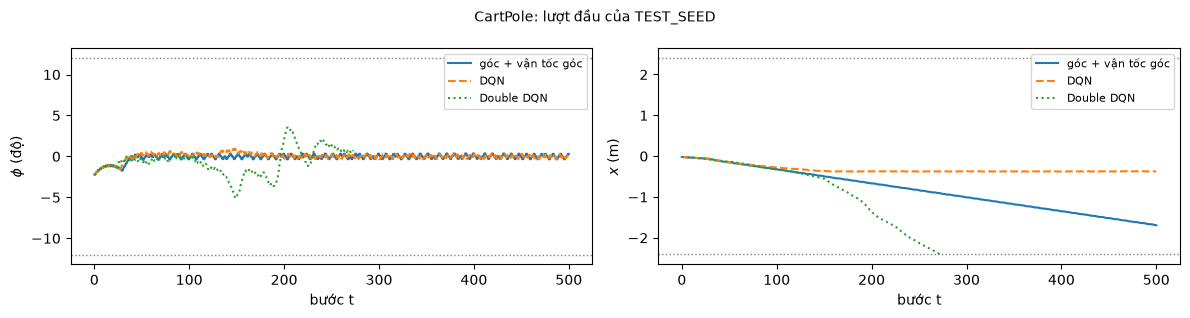

Trình phát: 3 lượt, HTML nhúng 37 kB


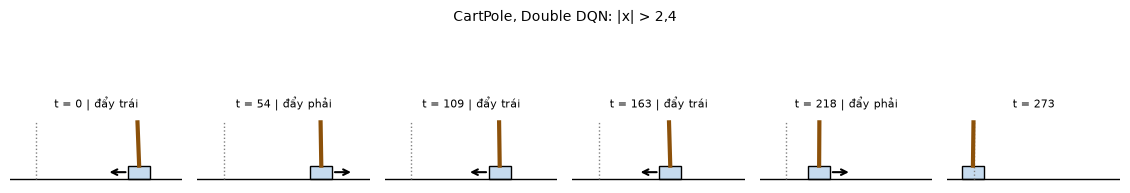

In [17]:
ep_cp = {"góc + vận tốc góc": record_episode(envs[env_id], cartpole_angle_vel, TEST_SEED, "cartpole"),
         **{name: record_episode(envs[env_id], net_policy(net), TEST_SEED, "cartpole") for name, net in nets_cp.items()}}
plot_episodes(ep_cp, "CartPole: lượt đầu của TEST_SEED")
display(player(ep_cp))
filmstrip(ep_cp["Double DQN"], 6, f"CartPole, Double DQN: {end_reason(ep_cp['Double DQN'])}"); plt.show()

## 7. DQN và Double DQN trên Lunar Lander và Flappy Bird

**Vấn đề.** CartPole có cận giá trị đã biết, nên một con số như $Q_0>100$ đủ để kết luận có đánh giá cao. Lunar Lander và Flappy Bird không có cận dễ dùng như vậy, nên mục này so $\max_aQ_\theta$ với lợi tức thực tế. Một lần huấn luyện mất khoảng $6$ phút (Lunar Lander) và $5$ phút (Flappy Bird) trên CPU, nên mục này đọc bảng tám hạt giống chạy khi soạn, với cùng cấu hình và cùng phép đo như mục 6.

In [18]:
show_dqn_table("LunarLander-v3")
print()
show_dqn_table("FlappyBird-v0")

LunarLander-v3: 8 hạt giống, TB ± SE giữa hạt giống; hiệu ghép cặp Double DQN - DQN, t = TB/SE, df = 7; số luồng CPU khi chạy: [1]
  tổng thưởng, chính sách cuối     DQN   187.32 ±  21.55 | Double DQN   137.36 ±  39.14 | hiệu   -49.96, t = -1.36
  tổng thưởng, mốc tốt nhất        DQN   179.69 ±  20.57 | Double DQN   162.90 ±  36.73 | hiệu   -16.80, t = -0.39
  tổng thưởng, cuối, SEL_SEED      DQN   184.25 ±  21.10 | Double DQN   124.60 ±  38.15 | hiệu   -59.65, t = -1.68
  Q_0                              DQN    92.05 ±   4.49 | Double DQN    82.36 ±   3.51 | hiệu    -9.69, t = -2.35
  G_0                              DQN    44.54 ±   5.24 | Double DQN    47.86 ±   2.19 | hiệu    +3.32, t = +0.59
  Q_0 - G_0                        DQN    47.51 ±   5.23 | Double DQN    34.50 ±   3.29 | hiệu   -13.00, t = -1.97
  độ lệch theo bước (gap)          DQN    25.93 ±   5.42 | Double DQN    31.43 ±   7.11 | hiệu    +5.50, t = +0.72
  đỉnh TB q_i (qmax)               DQN    57.89 ±   6.10 | Doubl

Hình dưới đặt hai thuật toán cạnh nhau theo từng hạt giống: mỗi đoạn thẳng nối giá trị của DQN (trái) và Double DQN (phải) ở cùng hạt giống. Hàng trên là $Q_0-G_0$, hàng dưới là điểm của chính sách cuối trên `TEST_SEED`.

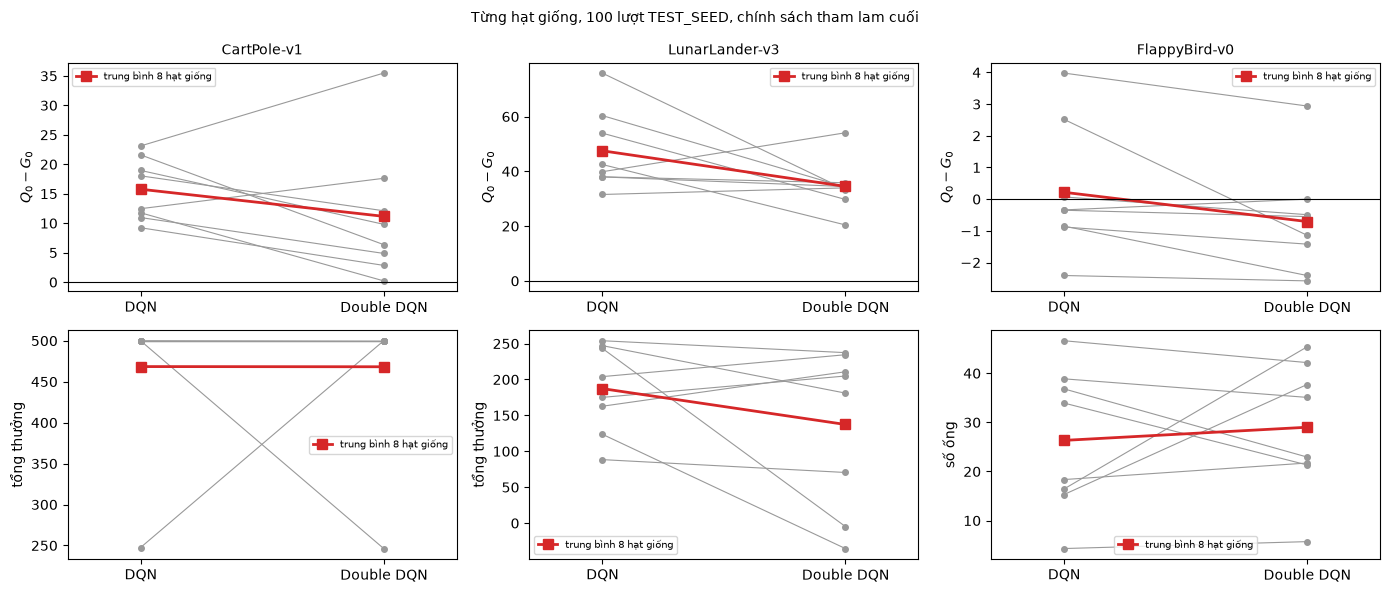

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, env_id_ in enumerate(ENV_IDS):
    for i, (key, lab) in enumerate([("Q0G0", "$Q_0 - G_0$"), ("final", "số ống" if env_id_ == "FlappyBird-v0" else "tổng thưởng")]):
        a, b = seed_values(env_id_, "dqn", key), seed_values(env_id_, "ddqn", key)
        ax = axes[i, j]
        for s in range(len(a)):
            ax.plot([0, 1], [a[s], b[s]], "o-", color="0.6", lw=0.8, ms=4)
        ax.plot([0, 1], [a.mean(), b.mean()], "s-", color="C3", lw=2, ms=7, label="trung bình 8 hạt giống")
        ax.set_xticks([0, 1], ["DQN", "Double DQN"]); ax.set_xlim(-0.3, 1.3); ax.set_ylabel(lab)
        if i == 0:
            ax.axhline(0, color="k", lw=0.8); ax.set_title(env_id_, fontsize=10)
        ax.legend(fontsize=7)
fig.suptitle("Từng hạt giống, 100 lượt TEST_SEED, chính sách tham lam cuối", fontsize=10); fig.tight_layout(); plt.show()

**Đọc kết quả.** Ngưỡng $5\%$ với $\mathrm{df}=7$ là $2{,}365$ cho từng phép so riêng.

- **Lunar Lander.** Cả hai thuật toán đánh giá cao mạnh ở đầu lượt: $Q_0$ khoảng $92$ (DQN) và $82$ (Double DQN), trong khi $G_0$ khoảng $45$–$48$. Trung bình $Q_0-G_0$ của Double DQN thấp hơn (hiệu $-13{,}0$, $t\approx-2{,}0$, chưa vượt ngưỡng), thấp hơn ở sáu trong tám hạt giống. Độ lệch theo bước đi ngược chiều ($+5{,}5$, $t\approx0{,}7$): tính trung bình trên mọi bước của lượt, hai thuật toán không khác nhau rõ. Về điểm, Double DQN thấp hơn ($137{,}4$ so với $187{,}3$), chủ yếu do hai hạt giống có chính sách cuối sụt ($-4{,}7$ và $-35{,}4$); hiệu $t\approx-1{,}4$ chưa phân biệt được.
- **Flappy Bird.** Trung bình $Q_0-G_0$ của DQN là $0{,}2\pm0{,}7$, của Double DQN là $-0{,}7\pm0{,}6$; cả hai chưa phân biệt được với $0$. Một giá trị âm như vậy phù hợp với khả năng chệch âm của ước lượng kép (Ví dụ 09.5), nhưng tám hạt giống chưa đủ để khẳng định. Hiệu $-0{,}9$ có $t\approx-2{,}1$; đỉnh trung bình $q_i$ giảm $0{,}66$ với $t\approx-2{,}6$ (vượt ngưỡng). Điểm không phân biệt được ($t\approx0{,}5$).

Gộp ba môi trường: trung bình $Q_0-G_0$ và đỉnh trung bình $q_i$ của Double DQN thấp hơn DQN ở cả ba môi trường. Bất đẳng thức $y^{\mathrm{DDQN}}_i\le y^{\mathrm{DQN}}_i$ của mục 5 chỉ so hai mục tiêu tính trên cùng cặp mạng và cùng mẫu chuyển; hai thuật toán huấn luyện ra hai cặp mạng khác nhau, nên bất đẳng thức đó không bảo đảm chiều của các hiệu này, và độ lệch theo bước ở Lunar Lander đi ngược chiều. Trong sáu phép so ($Q_0-G_0$ và đỉnh trung bình $q_i$ trên ba môi trường), hai hiệu vượt ngưỡng $2{,}365$ của từng phép so riêng (đỉnh trung bình $q_i$ ở CartPole và Flappy Bird). Với hiệu chỉnh Bonferroni cho sáu phép so (mức $5\%$ chia cho $6$, hai phía, $\mathrm{df}=7$), ngưỡng là $3{,}64$, và không hiệu nào vượt. Điểm của chính sách không cho thấy lợi ích của Double DQN ở các ngân sách này. Kết luận về giá trị và kết luận về điểm là hai kết luận khác nhau: Mệnh đề 09.2 nói về mục tiêu, không nói về chính sách.

**Quan hệ với Bài 08 và Tình huống 09.1.** Các lần chạy Double DQN dùng cùng mã, cùng cấu hình, cùng hạt giống với mục 15 của notebook Bài 08. Năm hạt giống đầu trên Lunar Lander cho lại đúng trung bình $200{,}0$ trên `SEL_SEED` của Bài 08 (mục 15.4) và của Tình huống 09.1; ba hạt giống thêm cho $-23{,}3$; $-25{,}5$; $45{,}6$, nên trung bình tám hạt giống trên `SEL_SEED` là $124{,}6$, so với $184{,}3$ của DQN. Trên Flappy Bird, $39{,}8$ ống trên ba hạt giống đầu của Bài 08 (mục 15.5) thành $28{,}3$ trên tám hạt giống. Kết luận "chưa phân biệt được" của Tình huống 09.1 vẫn giữ; phép đo độ chệch mà tình huống ghi là chưa làm nay có ở bảng trên.

**Lượt ghi khi soạn.** Notebook không huấn luyện lại hai môi trường này theo mặc định. Ô mã dưới nạp lượt đầu của `TEST_SEED` của chính sách cuối ở hạt giống $1$, ghi khi soạn bằng `record_episode` (mảng trạng thái, hành động, phần thưởng), rồi phát cùng chính sách tham chiếu tốt nhất của mục 2, ghi trực tiếp.

LunarLander-v3  điều khiển viết tay          197 bước, nằm yên (+100)
LunarLander-v3  DQN (ghi khi soạn)           316 bước, nằm yên (+100)
LunarLander-v3  Double DQN (ghi khi soạn)    286 bước, nằm yên (+100)


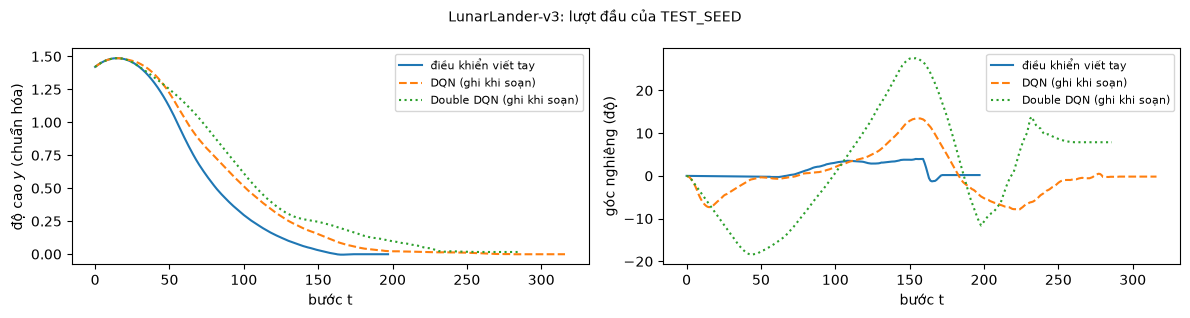

Trình phát: 3 lượt, HTML nhúng 34 kB


FlappyBird-v0   luật tay                    1365 bước, va chạm, 35 ống
FlappyBird-v0   DQN (ghi khi soạn)          1906 bước, đạt 50 ống
FlappyBird-v0   Double DQN (ghi khi soạn)   1792 bước, va chạm, 46 ống


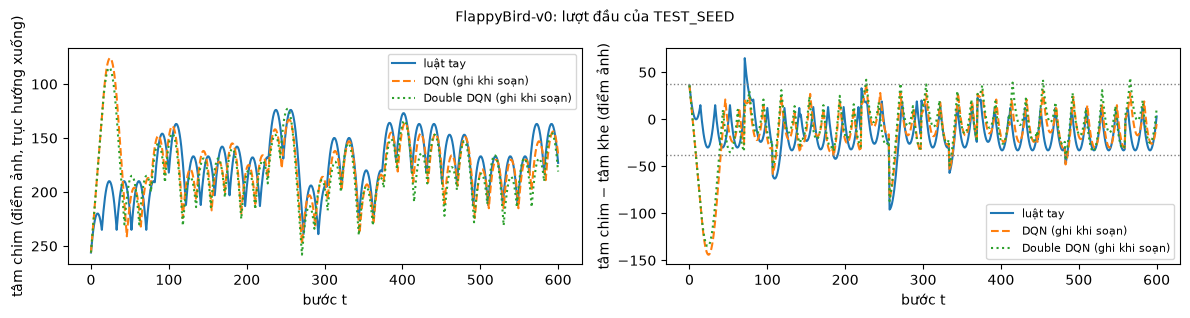

Trình phát: 3 lượt, HTML nhúng 151 kB; vẽ mỗi 2 bước để hiển thị trọn lượt dài 1906 bước


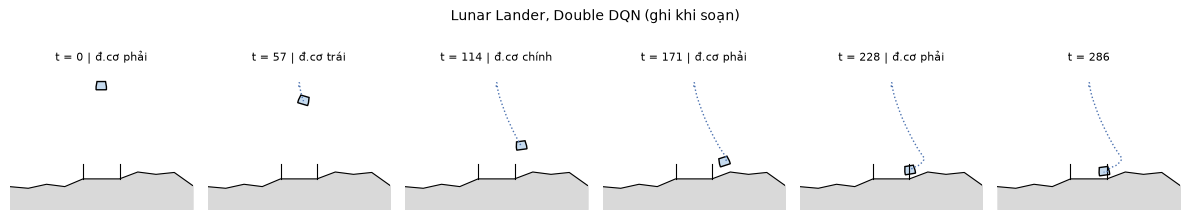

In [20]:
EPISODES = json.loads(r'''{"LunarLander-v3":{"DQN":{"seed":30000,"kind":"lunar","terrain":[[0.0,2.448],[2.0,2.271],[4.0,2.71],[6.0,2.455],[8.0,3.3],[10.0,3.3],[12.0,3.3],[14.0,4.055],[16.0,3.798],[18.0,4.005],[20.0,2.582]],"helipad":[8.0,12.0,3.3333],"states":[[0.0001,1.4201,0.0058,0.4089,-0.0001,-0.0013,0.0,0.0],[0.0002,1.4287,0.0161,0.3832,-0.0022,-0.0427,0.0,0.0],[0.0004,1.4368,0.027,0.3564,-0.0065,-0.0863,0.0,0.0],[0.0007,1.4442,0.0365,0.3297,-0.0127,-0.1244,0.0,0.0],[0.0011,1.451,0.0478,0.3024,-0.0212,-0.1696,0.0,0.0],[0.0016,1.4572,0.0582,0.2752,-0.0318,-0.2116,0.0,0.0],[0.0021,1.4628,0.0685,0.2478,-0.0444,-0.2527,0.0,0.0],[0.0028,1.4677,0.0763,0.221,-0.0586,-0.2839,0.0,0.0],[0.0035,1.4721,0.0845,0.1936,-0.0744,-0.3167,0.0,0.0],[0.0041,1.4759,0.0733,0.1675,-0.088,-0.2715,0.0,0.0],[0.0046,1.4791,0.062,0.1415,-0.0993,-0.2256,0.0,0.0],[0.005,1.4817,0.0533,0.1157,-0.1088,-0.1901,0.0,0.0],[0.0053,1.4838,0.0429,0.0899,-0.1162,-0.148,0.0,0.0],[0.0056,1.4852,0.0352,0.0642,-0.122,-0.1161,0.0,0.0],[0.0059,1.4861,0.0265,0.0377,-0.1261,-0.0812,0.0,0.0],[0.006,1.4863,0.0147,0.0119,-0.1278,-0.0336,0.0,0.0],[0.006,1.486,0.0038,-0.0139,-0.1272,0.0107,0.0,0.0],[0.006,1.4851,-0.0063,-0.0402,-0.1247,0.0512,0.0,0.0],[0.0059,1.4836,-0.0147,-0.066,-0.1204,0.0853,0.0,0.0],[0.0057,1.4815,-0.0232,-0.0919,-0.1144,0.1197,0.0,0.0],[0.0055,1.4796,-0.0298,-0.086,-0.109,0.1078,0.0,0.0],[0.0054,1.4778,-0.0181,-0.0808,-0.1033,0.1141,0.0,0.0],[0.0053,1.4753,-0.0094,-0.1081,-0.0994,0.0788,0.0,0.0],[0.0052,1.4723,-0.0206,-0.1343,-0.0932,0.1239,0.0,0.0],[0.0052,1.4695,-0.0066,-0.1224,-0.0866,0.1322,0.0,0.0],[0.005,1.4671,-0.0181,-0.1099,-0.0808,0.1161,0.0,0.0],[0.005,1.464,-0.0093,-0.137,-0.0768,0.0805,0.0,0.0],[0.005,1.4603,-0.0002,-0.1638,-0.0745,0.0441,0.0,0.0],[0.005,1.456,-0.0088,-0.1895,-0.0706,0.079,0.0,0.0],[0.0049,1.4512,-0.0088,-0.2162,-0.0666,0.079,0.0,0.0],[0.0049,1.4457,-0.0088,-0.2429,-0.0627,0.079,0.0,0.0],[0.0048,1.4396,-0.0088,-0.2695,-0.0587,0.079,0.0,0.0],[0.0048,1.4329,-0.0088,-0.2962,-0.0548,0.079,0.0,0.0],[0.0047,1.4263,-0.0139,-0.2952,-0.0512,0.0719,0.0,0.0],[0.0046,1.4191,-0.0139,-0.3219,-0.0476,0.0719,0.0,0.0],[0.0045,1.4112,-0.0139,-0.3486,-0.044,0.0719,0.0,0.0],[0.0044,1.4028,-0.0139,-0.3752,-0.0404,0.0719,0.0,0.0],[0.0043,1.3937,-0.0139,-0.4019,-0.0368,0.0719,0.0,0.0],[0.0041,1.3841,-0.0139,-0.4286,-0.0332,0.0719,0.0,0.0],[0.004,1.3738,-0.0139,-0.4552,-0.0296,0.0719,0.0,0.0],[0.0039,1.363,-0.0139,-0.4819,-0.026,0.0719,0.0,0.0],[0.0038,1.3515,-0.0139,-0.5086,-0.0224,0.0719,0.0,0.0],[0.0037,1.3395,-0.0139,-0.5352,-0.0188,0.0719,0.0,0.0],[0.0036,1.3269,-0.0139,-0.5619,-0.0152,0.0719,0.0,0.0],[0.0036,1.3136,-0.0027,-0.589,-0.0139,0.0271,0.0,0.0],[0.0036,1.2997,-0.0027,-0.6157,-0.0125,0.0271,0.0,0.0],[0.0036,1.2853,-0.0027,-0.6424,-0.0112,0.0271,0.0,0.0],[0.0036,1.2702,-0.0027,-0.669,-0.0098,0.0271,0.0,0.0],[0.0036,1.2546,-0.0027,-0.6957,-0.0085,0.0271,0.0,0.0],[0.0036,1.2383,-0.0027,-0.7224,-0.0071,0.0271,0.0,0.0],[0.0035,1.2215,-0.0027,-0.749,-0.0058,0.0271,0.0,0.0],[0.0036,1.204,0.0062,-0.7755,-0.0062,-0.0085,0.0,0.0],[0.0037,1.186,0.0062,-0.8021,-0.0066,-0.0085,0.0,0.0],[0.0037,1.1673,0.0062,-0.8288,-0.007,-0.0085,0.0,0.0],[0.0038,1.1481,0.0062,-0.8555,-0.0075,-0.0085,0.0,0.0],[0.0038,1.1282,0.0062,-0.8821,-0.0079,-0.0085,0.0,0.0],[0.0039,1.1091,0.0068,-0.8515,-0.0083,-0.0085,0.0,0.0],[0.0038,1.0904,-0.0081,-0.8286,-0.0095,-0.0235,0.0,0.0],[0.0037,1.0712,-0.0081,-0.8552,-0.0107,-0.0235,0.0,0.0],[0.0038,1.0528,0.0067,-0.8187,-0.0112,-0.0102,0.0,0.0],[0.0038,1.0338,0.0067,-0.8454,-0.0117,-0.0102,0.0,0.0],[0.004,1.0151,0.0152,-0.8274,-0.0118,-0.0027,0.0,0.0],[0.0042,0.9968,0.019,-0.8156,-0.0118,0.0003,0.0,0.0],[0.0045,0.9791,0.031,-0.7844,-0.0113,0.011,0.0,0.0],[0.0049,0.9616,0.0369,-0.778,-0.0105,0.0161,0.0,0.0],[0.0053,0.9447,0.0428,-0.7524,-0.0094,0.0211,0.0,0.0],[0.0057,0.9284,0.0415,-0.7232,-0.0085,0.0191,0.0,0.0],[0.0061,0.9125,0.0352,-0.71,-0.0078,0.0124,0.0,0.0],[0.0066,0.8971,0.0495,-0.6822,-0.0065,0.0257,0.0,0.0],[0.007,0.8824,0.0412,-0.6544,-0.0057,0.0171,0.0,0.0],[0.0075,0.8686,0.0481,-0.612,-0.0045,0.0233,0.0,0.0],[0.0079,0.8554,0.0368,-0.5873,-0.0039,0.012,0.0,0.0],[0.0083,0.8416,0.0368,-0.614,-0.0033,0.012,0.0,0.0],[0.0088,0.8283,0.0527,-0.5896,-0.002,0.0271,0.0,0.0],[0.0095,0.8151,0.064,-0.5855,-0.0001,0.0381,0.0,0.0],[0.0101,0.8028,0.0608,-0.5491,0.0017,0.0349,0.0,0.0],[0.0108,0.7909,0.066,-0.5263,0.0037,0.0401,0.0,0.0],[0.0116,0.78,0.0801,-0.4855,0.0064,0.0541,0.0,0.0],[0.0124,0.7685,0.0801,-0.5122,0.0091,0.0541,0.0,0.0],[0.0133,0.7564,0.0897,-0.5389,0.0099,0.0157,0.0,0.0],[0.0143,0.7445,0.0928,-0.5259,0.0109,0.0194,0.0,0.0],[0.015,0.7327,0.0772,-0.525,0.0111,0.0047,0.0,0.0],[0.0158,0.7203,0.0772,-0.5517,0.0113,0.0047,0.0,0.0],[0.0167,0.7086,0.0853,-0.5197,0.012,0.0135,0.0,0.0],[0.0175,0.6963,0.0853,-0.5463,0.0127,0.0135,0.0,0.0],[0.0184,0.6849,0.0894,-0.5071,0.0136,0.0187,0.0,0.0],[0.0193,0.6729,0.0894,-0.5337,0.0145,0.0187,0.0,0.0],[0.0201,0.6619,0.0744,-0.4909,0.0148,0.0056,0.0,0.0],[0.0208,0.6502,0.0744,-0.5176,0.0151,0.0056,0.0,0.0],[0.0216,0.638,0.0744,-0.5443,0.0154,0.0056,0.0,0.0],[0.0225,0.6261,0.0898,-0.5264,0.0165,0.0216,0.0,0.0],[0.0235,0.6145,0.0993,-0.5186,0.018,0.0316,0.0,0.0],[0.0245,0.6031,0.097,-0.5044,0.0196,0.0304,0.0,0.0],[0.0255,0.5912,0.097,-0.531,0.0211,0.0304,0.0,0.0],[0.0266,0.5799,0.1109,-0.5008,0.0234,0.0457,0.0,0.0],[0.0276,0.5689,0.0969,-0.4875,0.025,0.0335,0.0,0.0],[0.0286,0.5574,0.0969,-0.5141,0.0267,0.0335,0.0,0.0],[0.0297,0.5464,0.1067,-0.4865,0.029,0.045,0.0,0.0],[0.0307,0.5349,0.1067,-0.5132,0.0312,0.045,0.0,0.0],[0.0319,0.5238,0.1091,-0.4941,0.0337,0.0495,0.0,0.0],[0.033,0.5131,0.1122,-0.4726,0.0364,0.0549,0.0,0.0],[0.0341,0.503,0.1101,-0.4491,0.0392,0.0555,0.0,0.0],[0.0353,0.4923,0.1101,-0.4758,0.042,0.0555,0.0,0.0],[0.0362,0.4819,0.0945,-0.4634,0.0441,0.0427,0.0,0.0],[0.0371,0.4723,0.0855,-0.4259,0.046,0.0381,0.0,0.0],[0.038,0.4621,0.0855,-0.4526,0.0479,0.0381,0.0,0.0],[0.0388,0.4527,0.0812,-0.4184,0.0498,0.0382,0.0,0.0],[0.0396,0.4427,0.0812,-0.4451,0.0517,0.0382,0.0,0.0],[0.0406,0.4332,0.0931,-0.4236,0.0544,0.0533,0.0,0.0],[0.0414,0.4241,0.0791,-0.405,0.0566,0.0434,0.0,0.0],[0.0422,0.4144,0.0791,-0.4316,0.0588,0.0434,0.0,0.0],[0.0429,0.4048,0.0625,-0.4229,0.0603,0.0303,0.0,0.0],[0.0435,0.3956,0.0618,-0.411,0.0619,0.033,0.0,0.0],[0.0441,0.3867,0.0603,-0.3967,0.0637,0.0353,0.0,0.0],[0.0446,0.3781,0.0429,-0.3832,0.0648,0.0221,0.0,0.0],[0.045,0.3688,0.0429,-0.4098,0.0659,0.0221,0.0,0.0],[0.0455,0.3605,0.0471,-0.3691,0.0675,0.0327,0.0,0.0],[0.046,0.3516,0.0471,-0.3958,0.0692,0.0327,0.0,0.0],[0.0465,0.3434,0.0504,-0.3669,0.0712,0.0414,0.0,0.0],[0.0469,0.3354,0.0368,-0.3561,0.0728,0.0322,0.0,0.0],[0.0473,0.3267,0.0368,-0.3828,0.0745,0.0322,0.0,0.0],[0.0478,0.3182,0.0506,-0.3811,0.0769,0.0486,0.0,0.0],[0.0483,0.3099,0.0482,-0.3671,0.0794,0.0508,0.0,0.0],[0.0489,0.3023,0.0554,-0.3404,0.0826,0.0639,0.0,0.0],[0.0494,0.2954,0.0426,-0.3057,0.0856,0.059,0.0,0.0],[0.0498,0.2879,0.0426,-0.3324,0.0885,0.059,0.0,0.0],[0.0502,0.2809,0.0405,-0.3123,0.0917,0.0629,0.0,0.0],[0.0507,0.2733,0.0405,-0.339,0.0948,0.0629,0.0,0.0],[0.0511,0.2665,0.0369,-0.301,0.0982,0.0683,0.0,0.0],[0.0515,0.2591,0.0369,-0.3277,0.1016,0.0683,0.0,0.0],[0.052,0.2519,0.048,-0.3203,0.1059,0.0842,0.0,0.0],[0.0526,0.2457,0.0535,-0.2765,0.1109,0.1003,0.0,0.0],[0.0531,0.2396,0.0492,-0.2705,0.1159,0.1014,0.0,0.0],[0.0538,0.234,0.0581,-0.2532,0.1218,0.1173,0.0,0.0],[0.0543,0.2292,0.0443,-0.2137,0.1276,0.1158,0.0,0.0],[0.0548,0.2238,0.0443,-0.2404,0.1334,0.1158,0.0,0.0],[0.0553,0.2178,0.0443,-0.267,0.1392,0.1158,0.0,0.0],[0.0557,0.2126,0.0315,-0.2323,0.145,0.1159,0.0,0.0],[0.056,0.2067,0.0315,-0.259,0.1508,0.1159,0.0,0.0],[0.0562,0.201,0.0154,-0.2572,0.1561,0.1067,0.0,0.0],[0.0564,0.1957,0.0095,-0.2324,0.1617,0.1127,0.0,0.0],[0.0565,0.1913,0.0085,-0.1982,0.168,0.126,0.0,0.0],[0.0567,0.1863,0.0085,-0.2249,0.1743,0.126,0.0,0.0],[0.0568,0.1813,0.0015,-0.2192,0.1807,0.1275,0.0,0.0],[0.0568,0.1774,0.0004,-0.1776,0.1879,0.1443,0.0,0.0],[0.0569,0.1728,0.0004,-0.2042,0.1951,0.1443,0.0,0.0],[0.057,0.1685,0.0036,-0.1926,0.203,0.1581,0.0,0.0],[0.0568,0.165,-0.0261,-0.1583,0.2104,0.1478,0.0,0.0],[0.0567,0.1609,-0.0147,-0.1828,0.2154,0.1001,0.0,0.0],[0.0566,0.1562,-0.0147,-0.2095,0.2204,0.1001,0.0,0.0],[0.0563,0.1518,-0.0368,-0.1922,0.2251,0.0932,0.0,0.0],[0.0561,0.147,-0.0276,-0.2173,0.2278,0.0546,0.0,0.0],[0.0558,0.1427,-0.0279,-0.1924,0.2314,0.0713,0.0,0.0],[0.0557,0.1378,-0.0165,-0.2177,0.2326,0.0246,0.0,0.0],[0.0555,0.1334,-0.0192,-0.1947,0.2345,0.0387,0.0,0.0],[0.0554,0.1284,-0.0093,-0.2201,0.2344,-0.0021,0.0,0.0],[0.0552,0.1237,-0.0231,-0.2102,0.2343,-0.0027,0.0,0.0],[0.0549,0.1194,-0.0277,-0.1892,0.2348,0.0091,0.0,0.0],[0.0547,0.1146,-0.0172,-0.2145,0.233,-0.0343,0.0,0.0],[0.0542,0.1105,-0.0468,-0.181,0.2309,-0.042,0.0,0.0],[0.0538,0.1059,-0.0359,-0.2064,0.2266,-0.0867,0.0,0.0],[0.0535,0.1006,-0.0247,-0.2313,0.2199,-0.1337,0.0,0.0],[0.0531,0.0958,-0.0331,-0.2135,0.2135,-0.1275,0.0,0.0],[0.0525,0.0918,-0.0573,-0.1795,0.207,-0.1318,0.0,0.0],[0.0515,0.0884,-0.0919,-0.1478,0.1996,-0.1471,0.0,0.0],[0.0506,0.0845,-0.0824,-0.1729,0.1903,-0.1865,0.0,0.0],[0.0496,0.0815,-0.0896,-0.1327,0.1815,-0.1749,0.0,0.0],[0.0487,0.0779,-0.0798,-0.1581,0.1708,-0.2156,0.0,0.0],[0.0477,0.0744,-0.0923,-0.1541,0.1597,-0.22,0.0,0.0],[0.0466,0.0711,-0.0971,-0.145,0.1489,-0.2164,0.0,0.0],[0.0454,0.0681,-0.1052,-0.1316,0.1382,-0.2154,0.0,0.0],[0.0443,0.0661,-0.1034,-0.0892,0.1282,-0.1998,0.0,0.0],[0.0431,0.0635,-0.1033,-0.1159,0.1182,-0.1998,0.0,0.0],[0.0419,0.0609,-0.1102,-0.1133,0.1081,-0.2014,0.0,0.0],[0.0407,0.0577,-0.1102,-0.14,0.098,-0.2014,0.0,0.0],[0.0394,0.055,-0.1267,-0.1203,0.0875,-0.2107,0.0,0.0],[0.0378,0.053,-0.1464,-0.0885,0.0764,-0.2223,0.0,0.0],[0.0362,0.0504,-0.1464,-0.1152,0.0653,-0.2223,0.0,0.0],[0.0347,0.048,-0.1439,-0.1084,0.0544,-0.2167,0.0,0.0],[0.0331,0.0463,-0.1468,-0.0758,0.0437,-0.2149,0.0,0.0],[0.0315,0.0439,-0.1468,-0.1025,0.0329,-0.2149,0.0,0.0],[0.0299,0.0417,-0.1533,-0.0988,0.022,-0.2197,0.0,0.0],[0.0282,0.0404,-0.1513,-0.0595,0.0112,-0.2156,0.0,0.0],[0.0266,0.0391,-0.1489,-0.0567,0.0005,-0.2129,0.0,0.0],[0.0251,0.0381,-0.1463,-0.0439,-0.01,-0.2103,0.0,0.0],[0.0234,0.0365,-0.1564,-0.071,-0.0185,-0.1699,0.0,0.0],[0.022,0.0356,-0.1379,-0.0387,-0.0261,-0.1535,0.0,0.0],[0.0204,0.0342,-0.1499,-0.0656,-0.0314,-0.1055,0.0,0.0],[0.0189,0.0334,-0.145,-0.0336,-0.0366,-0.1035,0.0,0.0],[0.0173,0.0321,-0.1571,-0.0601,-0.0394,-0.0551,0.0,0.0],[0.0158,0.0301,-0.1455,-0.0867,-0.0444,-0.1018,0.0,0.0],[0.0143,0.0291,-0.142,-0.0455,-0.0496,-0.1029,0.0,0.0],[0.013,0.0286,-0.1326,-0.0229,-0.0545,-0.0973,0.0,0.0],[0.0115,0.0275,-0.1438,-0.0491,-0.0571,-0.0521,0.0,0.0],[0.0101,0.0258,-0.1319,-0.0757,-0.062,-0.0998,0.0,0.0],[0.0086,0.0241,-0.1462,-0.0752,-0.0679,-0.116,0.0,0.0],[0.0073,0.0233,-0.1276,-0.037,-0.0731,-0.1044,0.0,0.0],[0.0058,0.0227,-0.1402,-0.0253,-0.0791,-0.1207,0.0,0.0],[0.0046,0.0224,-0.1189,-0.0136,-0.0843,-0.1046,0.0,0.0],[0.0033,0.0215,-0.1284,-0.0402,-0.0877,-0.0667,0.0,0.0],[0.0019,0.0212,-0.1301,-0.0162,-0.0914,-0.0748,0.0,0.0],[0.0008,0.0214,-0.1112,0.0124,-0.0946,-0.0638,0.0,0.0],[-0.0004,0.0211,-0.1194,-0.0139,-0.0961,-0.0309,0.0,0.0],[-0.0017,0.0215,-0.1235,0.0144,-0.0983,-0.0425,0.0,0.0],[-0.0029,0.0212,-0.1124,-0.013,-0.1026,-0.0869,0.0,0.0],[-0.0041,0.0203,-0.1216,-0.039,-0.1051,-0.05,0.0,0.0],[-0.0053,0.0196,-0.1203,-0.0314,-0.1078,-0.054,0.0,0.0],[-0.0063,0.0198,-0.0983,0.009,-0.11,-0.0433,0.0,0.0],[-0.0074,0.0194,-0.1059,-0.0166,-0.1106,-0.0123,0.0,0.0],[-0.0085,0.0195,-0.1134,0.0051,-0.112,-0.0274,0.0,0.0],[-0.0096,0.0191,-0.1036,-0.0219,-0.1153,-0.0667,0.0,0.0],[-0.0106,0.019,-0.0991,-0.0034,-0.1188,-0.0699,0.0,0.0],[-0.0117,0.0183,-0.1085,-0.0295,-0.1204,-0.032,0.0,0.0],[-0.0129,0.018,-0.1167,-0.015,-0.1228,-0.0472,0.0,0.0],[-0.0141,0.0183,-0.1117,0.014,-0.1254,-0.0522,0.0,0.0],[-0.0153,0.018,-0.1217,-0.0119,-0.1259,-0.0113,0.0,0.0],[-0.0166,0.0178,-0.1269,-0.0106,-0.127,-0.0215,0.0,0.0],[-0.0178,0.0179,-0.1232,0.0026,-0.1283,-0.0252,0.0,0.0],[-0.019,0.0173,-0.1123,-0.0252,-0.1317,-0.0695,0.0,0.0],[-0.02,0.0171,-0.0978,-0.0077,-0.1349,-0.064,0.0,0.0],[-0.0211,0.0164,-0.1085,-0.0338,-0.136,-0.0208,0.0,0.0],[-0.0219,0.016,-0.0851,-0.0168,-0.1363,-0.0069,0.0,0.0],[-0.0226,0.0163,-0.065,0.0122,-0.1362,0.0015,1.0,0.0],[-0.0232,0.0159,-0.0558,-0.0151,-0.138,-0.0356,0.0,0.0],[-0.0238,0.0158,-0.062,-0.0055,-0.1369,0.0218,1.0,0.0],[-0.0242,0.0152,-0.0521,-0.0253,-0.1319,0.1004,1.0,0.0],[-0.0248,0.0151,-0.06,-0.0053,-0.1277,0.0839,1.0,0.0],[-0.0253,0.0145,-0.0499,-0.0284,-0.1221,0.112,1.0,0.0],[-0.0257,0.0143,-0.0549,-0.0085,-0.1172,0.0989,1.0,0.0],[-0.0262,0.0134,-0.0462,-0.0364,-0.114,0.0629,0.0,0.0],[-0.0266,0.0131,-0.0459,-0.0127,-0.1113,0.0548,1.0,0.0],[-0.0269,0.0135,-0.0316,0.0159,-0.1083,0.0597,1.0,0.0],[-0.0271,0.0132,-0.0235,-0.0113,-0.107,0.0268,0.0,0.0],[-0.0271,0.0138,-0.0008,0.0248,-0.105,0.0389,0.0,0.0],[-0.0272,0.0138,-0.01,-0.0015,-0.1012,0.0758,0.0,0.0],[-0.0273,0.0131,-0.0176,-0.0282,-0.0959,0.106,0.0,0.0],[-0.0275,0.0134,-0.0241,0.0127,-0.0914,0.0903,0.0,0.0],[-0.0278,0.0131,-0.0338,-0.0134,-0.085,0.1292,0.0,0.0],[-0.0281,0.0132,-0.0405,0.006,-0.0791,0.117,0.0,0.0],[-0.0284,0.0127,-0.0299,-0.0211,-0.0754,0.0745,0.0,0.0],[-0.0285,0.0131,-0.0176,0.0158,-0.0714,0.0794,0.0,0.0],[-0.0287,0.0128,-0.0252,-0.0109,-0.0659,0.1096,0.0,0.0],[-0.029,0.0129,-0.0318,0.0016,-0.061,0.0994,0.0,0.0],[-0.0291,0.0123,-0.0204,-0.0255,-0.0583,0.0537,0.0,0.0],[-0.0292,0.0122,-0.0068,-0.003,-0.0551,0.0627,0.0,0.0],[-0.0293,0.0116,-0.0161,-0.0293,-0.0502,0.0998,0.0,0.0],[-0.0295,0.0116,-0.0223,0.0035,-0.0457,0.0895,0.0,0.0],[-0.0296,0.0111,-0.0145,-0.0237,-0.0428,0.0581,0.0,0.0],[-0.0296,0.0113,-0.0019,0.0082,-0.0394,0.0667,0.0,0.0],[-0.0296,0.0109,-0.0128,-0.0177,-0.0339,0.1107,0.0,0.0],[-0.0297,0.0106,-0.0069,-0.011,-0.0282,0.1148,0.0,0.0],[-0.0296,0.0098,0.001,-0.0381,-0.024,0.0833,0.0,0.0],[-0.0297,0.0099,-0.0115,0.0039,-0.0206,0.0688,0.0,0.0],[-0.0297,0.0093,-0.0033,-0.0228,-0.0187,0.0362,0.0,0.0],[-0.0297,0.0091,-0.0029,-0.0103,-0.017,0.0355,0.0,0.0],[-0.0297,0.0083,0.0051,-0.0368,-0.0168,0.0032,0.0,0.0],[-0.0297,0.0075,0.0004,-0.0334,-0.0169,-0.0021,0.0,0.0],[-0.0296,0.0071,0.0071,-0.0211,-0.0167,0.0035,0.0,0.0],[-0.0296,0.0069,-0.0011,-0.0055,-0.017,-0.0055,0.0,0.0],[-0.0297,0.0062,-0.0099,-0.0321,-0.0155,0.03,0.0,0.0],[-0.0296,0.0061,0.0026,-0.0054,-0.0135,0.0409,0.0,0.0],[-0.0295,0.0054,0.0147,-0.0319,-0.0139,-0.0078,0.0,0.0],[-0.0293,0.0052,0.0188,-0.0074,-0.0141,-0.0049,0.0,0.0],[-0.0292,0.0044,0.0065,-0.0337,-0.0119,0.0442,0.0,0.0],[-0.0292,0.0039,-0.001,-0.0244,-0.0101,0.0362,0.0,0.0],[-0.0293,0.0036,-0.0122,-0.0129,-0.0088,0.0248,0.0,0.0],[-0.0295,0.0034,-0.0176,-0.0069,-0.0079,0.0191,0.0,0.0],[-0.0296,0.0027,-0.0067,-0.0331,-0.0091,-0.0248,0.0,0.0],[-0.0295,0.002,0.0063,-0.0322,-0.0098,-0.0126,0.0,0.0],[-0.0293,0.0013,0.0174,-0.0279,-0.0099,-0.0022,0.0,0.0],[-0.0291,0.0008,0.0238,-0.0232,-0.0097,0.0035,0.0,0.0],[-0.0289,0.001,0.021,0.0086,-0.0097,0.0,0.0,0.0],[-0.0288,0.0006,0.0106,-0.0183,-0.0076,0.0418,0.0,0.0],[-0.0285,0.0007,0.0183,0.0043,-0.0052,0.0487,0.0,0.0],[-0.0284,0.0002,0.0071,-0.0228,-0.0005,0.0936,0.0,0.0],[-0.0283,0.0004,0.006,0.0098,0.0041,0.0925,0.0,0.0],[-0.0281,0.0,0.0178,-0.0172,0.0064,0.045,0.0,0.0],[-0.0279,0.0005,0.0182,0.0205,0.0087,0.046,0.0,1.0],[-0.0277,0.0004,0.0256,-0.0044,0.0079,-0.0153,0.0,1.0],[-0.0274,-0.0002,0.0273,-0.0251,0.0035,-0.0881,0.0,1.0],[-0.0272,-0.0012,0.029,-0.0459,-0.0045,-0.1606,0.0,1.0],[-0.0269,-0.0012,0.028,-0.0002,-0.0045,-0.0,1.0,1.0],[-0.0267,-0.0012,0.0223,0.0,-0.0045,0.0,1.0,1.0],[-0.0266,-0.0012,0.0166,0.0,-0.0045,0.0,1.0,1.0],[-0.0265,-0.0012,0.011,-0.0,-0.0045,-0.0,1.0,1.0],[-0.0264,-0.0011,0.0045,0.0041,-0.0037,0.0165,1.0,1.0],[-0.0264,-0.0011,-0.0002,0.0001,-0.0037,0.0001,1.0,1.0],[-0.0264,-0.0011,-0.0015,-0.0,-0.0037,0.0004,1.0,1.0],[-0.0264,-0.0011,-0.0009,-0.0,-0.0037,0.0003,1.0,1.0],[-0.0264,-0.0011,-0.0001,0.0,-0.0037,0.0,1.0,1.0],[-0.0264,-0.0011,0.0002,-0.0,-0.0037,-0.0001,1.0,1.0],[-0.0264,-0.001,-0.0,0.0034,-0.003,0.0141,1.0,1.0],[-0.0264,-0.001,-0.0002,0.0,-0.003,0.0001,1.0,1.0],[-0.0264,-0.001,-0.0001,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,0.0,0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,-0.0,0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,0.0,0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,0.0,0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,-0.0,0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,0.0,-0.0,-0.003,-0.0,1.0,1.0],[-0.0264,-0.001,-0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,-0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,-0.0,0.0,-0.003,0.0,1.0,1.0],[-0.0264,-0.001,0.0,0.0,-0.003,0.0,1.0,1.0]],"actions":[3,3,3,3,3,3,3,3,1,1,1,1,1,1,1,1,1,1,1,2,2,3,1,2,2,3,3,1,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,0,0,0,3,0,0,0,0,2,2,0,2,0,2,2,2,2,2,2,2,2,2,2,2,0,2,2,2,2,2,0,3,2,2,0,2,0,2,0,2,0,0,2,2,2,0,2,2,0,2,0,2,2,2,0,2,2,0,2,0,2,2,0,2,2,2,2,0,2,0,2,2,0,2,2,2,2,0,2,0,2,0,2,2,2,2,2,0,0,2,0,2,2,2,0,2,2,0,2,2,3,0,2,3,2,3,2,3,2,2,3,2,3,3,2,2,2,3,2,3,2,2,2,2,0,2,0,2,2,0,2,2,0,2,2,2,2,1,2,1,2,1,3,2,2,1,3,2,2,2,2,1,2,2,1,2,3,1,2,2,1,2,3,2,1,2,2,1,2,2,3,2,1,2,2,3,2,3,2,3,2,3,2,2,3,2,1,1,2,1,2,3,2,1,2,3,2,1,2,3,2,1,2,3,2,3,2,3,2,2,2,1,2,3,2,1,2,2,2,3,2,2,2,2,1,2,1,2,3,2,3,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"rewards":[1.437,1.348,1.178,0.991,0.784,0.568,0.379,0.205,1.071,1.359,1.47,1.802,1.89,2.191,2.485,0.511,-2.314,-2.151,-1.935,0.811,1.273,-1.961,-1.847,1.965,1.648,-1.913,-2.086,-1.803,-1.782,-1.723,-1.663,-1.604,0.802,-1.58,-1.52,-1.461,-1.401,-1.341,-1.282,-1.222,-1.162,-1.102,-1.042,-1.267,-1.146,-1.086,-1.026,-0.966,-0.906,-0.846,-0.972,-0.904,-0.844,-0.784,-0.724,4.64,3.735,-0.86,5.147,-0.815,3.333,2.712,4.598,2.143,4.026,4.339,2.712,4.05,4.088,5.38,3.618,-1.221,3.481,1.494,4.427,2.89,4.355,-1.753,-1.683,2.006,1.196,-1.424,3.843,-1.474,4.551,-1.524,5.236,-1.505,-1.448,2.3,1.308,2.119,-1.584,3.281,2.215,-1.635,3.072,-1.686,2.372,2.502,2.759,-1.812,2.061,4.31,-1.8,3.878,-1.821,2.25,2.489,-1.879,1.617,1.637,1.844,2.006,-1.852,4.352,-1.933,3.123,1.563,-1.967,0.308,1.679,2.664,3.695,-2.209,2.09,-2.219,3.825,-2.275,0.565,4.016,0.44,1.172,3.732,-2.683,-2.636,3.24,-2.673,0.042,2.144,2.911,-2.816,0.117,3.516,-2.956,0.475,2.522,-2.441,-2.714,1.082,-2.174,2.224,-2.086,2.179,-2.025,1.038,2.083,-1.814,3.123,-1.414,-1.195,2.437,3.505,2.22,-0.466,4.02,-0.289,0.896,1.623,1.7,4.124,-0.594,0.703,-0.673,1.407,1.426,-0.106,1.687,2.496,-0.028,0.748,2.961,1.276,-0.416,-2.555,1.939,-2.39,0.795,-2.043,-0.41,1.368,0.775,-1.872,-0.334,-1.895,2.453,-1.774,1.508,-1.735,-0.279,1.285,-0.985,-0.962,0.662,-1.664,-0.198,1.997,-0.936,-1.124,0.398,-0.019,-1.519,-1.101,-0.137,-1.121,-0.983,-0.1,0.39,1.016,-1.727,2.308,11.708,-9.404,9.316,0.901,-0.157,0.807,0.344,-10.034,11.063,1.183,-8.971,-0.008,1.817,-1.793,0.717,-0.3,-0.215,0.773,1.364,0.131,-0.271,0.165,2.532,-2.111,1.214,-0.257,1.969,-0.814,1.177,-2.1,2.634,-0.928,1.114,-2.628,0.084,0.848,1.341,-2.673,2.678,-2.956,1.189,-1.203,0.884,0.482,-0.336,-1.637,-0.26,-0.293,-0.289,0.768,0.351,0.194,-0.056,0.584,-1.561,9.224,0.216,-0.648,-1.801,12.36,0.591,0.582,0.576,0.572,0.591,-0.129,0.061,0.082,-0.013,-0.245,0.315,0.017,0.005,-0.001,0.003,0.002,-0.001,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,100.0],"terminated":true,"truncated":false,"score":null},"Double DQN":{"seed":30000,"kind":"lunar","terrain":[[0.0,2.448],[2.0,2.271],[4.0,2.71],[6.0,2.455],[8.0,3.3],[10.0,3.3],[12.0,3.3],[14.0,4.055],[16.0,3.798],[18.0,4.005],[20.0,2.582]],"helipad":[8.0,12.0,3.3333],"states":[[0.0001,1.4201,0.0058,0.4089,-0.0001,-0.0013,0.0,0.0],[0.0002,1.4287,0.0161,0.3832,-0.0022,-0.0427,0.0,0.0],[0.0004,1.4368,0.027,0.3564,-0.0065,-0.0863,0.0,0.0],[0.0007,1.4442,0.0365,0.3297,-0.0127,-0.1244,0.0,0.0],[0.0011,1.451,0.0478,0.3024,-0.0212,-0.1696,0.0,0.0],[0.0015,1.4572,0.0478,0.2758,-0.0297,-0.1696,0.0,0.0],[0.0019,1.4628,0.0478,0.2491,-0.0382,-0.1696,0.0,0.0],[0.0023,1.4678,0.0478,0.2224,-0.0466,-0.1695,0.0,0.0],[0.0027,1.4722,0.0479,0.1958,-0.0551,-0.1695,0.0,0.0],[0.0031,1.476,0.0479,0.1691,-0.0636,-0.1695,0.0,0.0],[0.0035,1.4793,0.0479,0.1424,-0.0721,-0.1694,0.0,0.0],[0.0039,1.4819,0.0479,0.1157,-0.0805,-0.1694,0.0,0.0],[0.0043,1.4839,0.048,0.0891,-0.089,-0.1694,0.0,0.0],[0.0047,1.4853,0.048,0.0624,-0.0975,-0.1694,0.0,0.0],[0.005,1.4861,0.048,0.0357,-0.1059,-0.1693,0.0,0.0],[0.0054,1.4863,0.048,0.009,-0.1144,-0.1693,0.0,0.0],[0.0058,1.4859,0.048,-0.0176,-0.1229,-0.1693,0.0,0.0],[0.0062,1.485,0.0481,-0.0443,-0.1313,-0.1693,0.0,0.0],[0.0066,1.4834,0.0481,-0.071,-0.1398,-0.1692,0.0,0.0],[0.007,1.4812,0.0481,-0.0977,-0.1482,-0.1692,0.0,0.0],[0.0074,1.4784,0.0481,-0.1244,-0.1567,-0.1692,0.0,0.0],[0.0078,1.475,0.0482,-0.151,-0.1652,-0.1692,0.0,0.0],[0.0082,1.4711,0.0482,-0.1777,-0.1736,-0.1691,0.0,0.0],[0.0086,1.4665,0.0482,-0.2044,-0.1821,-0.1691,0.0,0.0],[0.009,1.4613,0.0482,-0.2311,-0.1905,-0.1691,0.0,0.0],[0.0094,1.4555,0.048,-0.2587,-0.199,-0.169,0.0,0.0],[0.0098,1.4491,0.048,-0.2853,-0.2074,-0.169,0.0,0.0],[0.0102,1.4421,0.048,-0.312,-0.2159,-0.169,0.0,0.0],[0.0106,1.4345,0.048,-0.3387,-0.2243,-0.169,0.0,0.0],[0.011,1.4264,0.048,-0.3654,-0.2328,-0.169,0.0,0.0],[0.0117,1.4188,0.0783,-0.3383,-0.2407,-0.1585,0.0,0.0],[0.0124,1.4106,0.0783,-0.365,-0.2486,-0.1585,0.0,0.0],[0.0132,1.4031,0.0854,-0.3337,-0.2573,-0.1725,0.0,0.0],[0.014,1.3957,0.0887,-0.3326,-0.2662,-0.1797,0.0,0.0],[0.0151,1.3885,0.1188,-0.3215,-0.2745,-0.166,0.0,0.0],[0.0162,1.3807,0.1188,-0.3482,-0.2828,-0.166,0.0,0.0],[0.0172,1.3723,0.1094,-0.3735,-0.2892,-0.1271,0.0,0.0],[0.0183,1.3639,0.1178,-0.3761,-0.2957,-0.1292,0.0,0.0],[0.0195,1.3557,0.1277,-0.3624,-0.3025,-0.1372,0.0,0.0],[0.0207,1.347,0.1192,-0.3878,-0.3076,-0.1019,0.0,0.0],[0.022,1.3392,0.1362,-0.3502,-0.3133,-0.1145,0.0,0.0],[0.0232,1.3307,0.1276,-0.3755,-0.3173,-0.0787,0.0,0.0],[0.0244,1.3218,0.1191,-0.3998,-0.3193,-0.0407,0.0,0.0],[0.0259,1.3136,0.1469,-0.3619,-0.3215,-0.0446,0.0,0.0],[0.0272,1.3049,0.1385,-0.3871,-0.322,-0.0092,0.0,0.0],[0.0285,1.2956,0.1288,-0.4121,-0.3204,0.0315,0.0,0.0],[0.03,1.2864,0.1475,-0.4086,-0.3187,0.0349,0.0,0.0],[0.0317,1.2781,0.1686,-0.3697,-0.3175,0.0244,0.0,0.0],[0.0334,1.2692,0.1686,-0.3963,-0.3162,0.0244,0.0,0.0],[0.035,1.2597,0.1571,-0.4209,-0.3126,0.0733,0.0,0.0],[0.0368,1.2501,0.1763,-0.426,-0.3085,0.0813,0.0,0.0],[0.0388,1.2412,0.1959,-0.3954,-0.3048,0.0742,0.0,0.0],[0.0409,1.2316,0.2061,-0.4246,-0.3033,0.0296,0.0,0.0],[0.0429,1.2215,0.197,-0.4499,-0.2999,0.0675,0.0,0.0],[0.0452,1.2122,0.23,-0.4142,-0.2964,0.0712,0.0,0.0],[0.0476,1.2022,0.23,-0.4409,-0.2928,0.0712,0.0,0.0],[0.0499,1.1917,0.23,-0.4675,-0.2893,0.0712,0.0,0.0],[0.0523,1.1817,0.2363,-0.4438,-0.2864,0.0562,0.0,0.0],[0.0546,1.1711,0.2292,-0.4687,-0.2821,0.0873,0.0,0.0],[0.057,1.16,0.2292,-0.4954,-0.2777,0.0873,0.0,0.0],[0.0594,1.1493,0.243,-0.4731,-0.2737,0.0806,0.0,0.0],[0.0619,1.138,0.243,-0.4998,-0.2697,0.0806,0.0,0.0],[0.0646,1.127,0.2614,-0.4899,-0.2655,0.0837,0.0,0.0],[0.0672,1.1154,0.2614,-0.5165,-0.2613,0.0837,0.0,0.0],[0.0701,1.1038,0.2793,-0.5122,-0.2568,0.0888,0.0,0.0],[0.0729,1.0917,0.2793,-0.5388,-0.2524,0.0888,0.0,0.0],[0.0759,1.0802,0.2983,-0.5111,-0.2481,0.0868,0.0,0.0],[0.0789,1.0681,0.2876,-0.5361,-0.2415,0.1311,0.0,0.0],[0.0818,1.0554,0.2876,-0.5628,-0.235,0.1311,0.0,0.0],[0.0847,1.0421,0.2876,-0.5895,-0.2284,0.1311,0.0,0.0],[0.088,1.0297,0.3173,-0.5498,-0.2215,0.1373,0.0,0.0],[0.0912,1.0167,0.3173,-0.5764,-0.2147,0.1373,0.0,0.0],[0.0945,1.0031,0.3173,-0.6031,-0.2078,0.1373,0.0,0.0],[0.098,0.99,0.3484,-0.5819,-0.2002,0.1525,0.0,0.0],[0.1016,0.9763,0.3484,-0.6085,-0.1925,0.1525,0.0,0.0],[0.1051,0.962,0.3484,-0.6352,-0.1849,0.1525,0.0,0.0],[0.1089,0.9481,0.3673,-0.6139,-0.177,0.1577,0.0,0.0],[0.1126,0.9337,0.3673,-0.6406,-0.1692,0.1577,0.0,0.0],[0.1164,0.9193,0.3664,-0.6376,-0.1617,0.1495,0.0,0.0],[0.1202,0.9054,0.3746,-0.6205,-0.1543,0.1472,0.0,0.0],[0.1242,0.8917,0.3875,-0.6084,-0.1468,0.1508,0.0,0.0],[0.1281,0.8773,0.3875,-0.6351,-0.1392,0.1508,0.0,0.0],[0.1323,0.8638,0.4097,-0.6032,-0.1312,0.1604,0.0,0.0],[0.1365,0.8496,0.4097,-0.6298,-0.1232,0.1604,0.0,0.0],[0.1408,0.8362,0.4259,-0.5958,-0.115,0.1651,0.0,0.0],[0.1451,0.8221,0.4259,-0.6225,-0.1067,0.1651,0.0,0.0],[0.1495,0.8075,0.4259,-0.6491,-0.0984,0.1651,0.0,0.0],[0.1538,0.7939,0.4228,-0.6057,-0.0908,0.152,0.0,0.0],[0.1581,0.7796,0.4228,-0.6323,-0.0832,0.152,0.0,0.0],[0.1623,0.7657,0.4114,-0.6192,-0.0764,0.1362,0.0,0.0],[0.1667,0.7521,0.4329,-0.6026,-0.0688,0.1521,0.0,0.0],[0.1711,0.738,0.4328,-0.6292,-0.0612,0.1521,0.0,0.0],[0.1755,0.7241,0.4354,-0.615,-0.0537,0.151,0.0,0.0],[0.1799,0.7097,0.4354,-0.6417,-0.0461,0.151,0.0,0.0],[0.1846,0.6959,0.455,-0.6122,-0.0378,0.1662,0.0,0.0],[0.1892,0.6815,0.455,-0.6389,-0.0295,0.1662,0.0,0.0],[0.1939,0.6681,0.4628,-0.5981,-0.021,0.1709,0.0,0.0],[0.1986,0.654,0.4628,-0.6248,-0.0124,0.1709,0.0,0.0],[0.2032,0.64,0.4514,-0.6208,-0.0044,0.1592,0.0,0.0],[0.2079,0.6265,0.4562,-0.6018,0.0037,0.1637,0.0,0.0],[0.2125,0.6123,0.4562,-0.6285,0.0119,0.1637,0.0,0.0],[0.2172,0.5987,0.456,-0.605,0.0201,0.1643,0.0,0.0],[0.2219,0.5858,0.4676,-0.5772,0.029,0.1772,0.0,0.0],[0.2267,0.5722,0.4676,-0.6038,0.0379,0.1772,0.0,0.0],[0.2314,0.5594,0.4592,-0.5663,0.0465,0.1726,0.0,0.0],[0.2361,0.5461,0.4592,-0.593,0.0551,0.1726,0.0,0.0],[0.2407,0.5335,0.4543,-0.5589,0.0637,0.1727,0.0,0.0],[0.2453,0.5204,0.4543,-0.5855,0.0724,0.1727,0.0,0.0],[0.2501,0.5077,0.4647,-0.5638,0.0818,0.1878,0.0,0.0],[0.2546,0.4954,0.4488,-0.5455,0.0907,0.1779,0.0,0.0],[0.2591,0.4841,0.4334,-0.5035,0.0993,0.1719,0.0,0.0],[0.2635,0.4722,0.4334,-0.5302,0.1079,0.1719,0.0,0.0],[0.2679,0.4605,0.4299,-0.5183,0.1166,0.1747,0.0,0.0],[0.2722,0.4492,0.425,-0.5041,0.1254,0.1769,0.0,0.0],[0.2763,0.4382,0.404,-0.4914,0.1336,0.1638,0.0,0.0],[0.2805,0.4276,0.4044,-0.4707,0.1423,0.1733,0.0,0.0],[0.2846,0.418,0.4008,-0.4299,0.1515,0.1838,0.0,0.0],[0.2887,0.4077,0.4008,-0.4566,0.1607,0.1838,0.0,0.0],[0.2927,0.3981,0.3965,-0.4278,0.1703,0.1926,0.0,0.0],[0.2966,0.3887,0.3775,-0.4181,0.1795,0.1834,0.0,0.0],[0.3001,0.3799,0.3464,-0.3931,0.1878,0.1672,0.0,0.0],[0.3038,0.3711,0.3553,-0.3905,0.197,0.1836,0.0,0.0],[0.3073,0.3627,0.3456,-0.377,0.2063,0.1858,0.0,0.0],[0.3109,0.3548,0.3426,-0.3501,0.2162,0.1989,0.0,0.0],[0.3144,0.3464,0.3426,-0.3768,0.2262,0.1989,0.0,0.0],[0.3179,0.3383,0.3455,-0.3605,0.237,0.2157,0.0,0.0],[0.3214,0.3307,0.3331,-0.3412,0.248,0.2197,0.0,0.0],[0.3247,0.3232,0.3242,-0.3357,0.2591,0.2228,0.0,0.0],[0.3279,0.3165,0.3048,-0.2991,0.2705,0.2282,0.0,0.0],[0.3307,0.3106,0.2748,-0.2658,0.2817,0.2235,0.0,0.0],[0.3337,0.3041,0.2867,-0.2905,0.2904,0.1735,0.0,0.0],[0.3365,0.2985,0.2727,-0.2473,0.2998,0.1896,0.0,0.0],[0.3392,0.2931,0.2593,-0.2424,0.3094,0.1907,0.0,0.0],[0.3419,0.2881,0.2553,-0.2248,0.3197,0.2066,0.0,0.0],[0.3442,0.2839,0.2222,-0.1884,0.33,0.2051,0.0,0.0],[0.3464,0.28,0.2169,-0.1767,0.3409,0.2183,0.0,0.0],[0.3487,0.2762,0.2097,-0.1701,0.3523,0.2279,0.0,0.0],[0.3505,0.2732,0.1778,-0.1386,0.3637,0.228,0.0,0.0],[0.3522,0.2701,0.1556,-0.1382,0.3748,0.2219,0.0,0.0],[0.3536,0.267,0.1304,-0.1396,0.3854,0.2126,0.0,0.0],[0.3548,0.2645,0.1071,-0.117,0.3963,0.2186,0.0,0.0],[0.3557,0.2626,0.0849,-0.0846,0.4079,0.2319,0.0,0.0],[0.3567,0.2608,0.0809,-0.086,0.4201,0.243,0.0,0.0],[0.3577,0.2584,0.0904,-0.1102,0.4301,0.2007,0.0,0.0],[0.3584,0.2568,0.0641,-0.0709,0.441,0.2175,0.0,0.0],[0.3587,0.2554,0.0237,-0.0664,0.4511,0.2015,0.0,0.0],[0.3591,0.2534,0.0346,-0.0897,0.4586,0.1513,0.0,0.0],[0.3596,0.2509,0.0419,-0.1136,0.4644,0.1156,0.0,0.0],[0.3597,0.2493,0.0074,-0.0753,0.4708,0.1279,0.0,0.0],[0.3599,0.2471,0.0164,-0.0992,0.4751,0.0862,0.0,0.0],[0.3598,0.2451,-0.0216,-0.087,0.4791,0.0793,0.0,0.0],[0.3596,0.2427,-0.0133,-0.1107,0.481,0.039,0.0,0.0],[0.3596,0.2397,-0.0023,-0.1334,0.4804,-0.0134,0.0,0.0],[0.3595,0.2367,-0.0121,-0.1315,0.4802,-0.0026,0.0,0.0],[0.3592,0.2342,-0.0329,-0.1105,0.4808,0.0115,0.0,0.0],[0.3589,0.2312,-0.0238,-0.1343,0.4793,-0.0309,0.0,0.0],[0.3584,0.2283,-0.0505,-0.1277,0.4777,-0.0316,0.0,0.0],[0.358,0.2249,-0.0401,-0.1508,0.4736,-0.0809,0.0,0.0],[0.3574,0.2215,-0.0571,-0.1476,0.4698,-0.0757,0.0,0.0],[0.3563,0.2188,-0.1071,-0.1204,0.4657,-0.0834,0.0,0.0],[0.3552,0.2155,-0.0969,-0.1441,0.4592,-0.1298,0.0,0.0],[0.3543,0.2117,-0.0865,-0.1673,0.4503,-0.1785,0.0,0.0],[0.3531,0.2082,-0.11,-0.152,0.4416,-0.1723,0.0,0.0],[0.352,0.2042,-0.1018,-0.1757,0.4311,-0.2116,0.0,0.0],[0.3503,0.2007,-0.155,-0.1505,0.4197,-0.227,0.0,0.0],[0.3487,0.1967,-0.1463,-0.1743,0.4063,-0.2677,0.0,0.0],[0.3469,0.1936,-0.1748,-0.1367,0.3935,-0.2562,0.0,0.0],[0.3451,0.1899,-0.1655,-0.1607,0.3786,-0.2981,0.0,0.0],[0.3431,0.1862,-0.1873,-0.1591,0.3635,-0.3025,0.0,0.0],[0.3409,0.1827,-0.2029,-0.1514,0.3485,-0.2989,0.0,0.0],[0.3388,0.1787,-0.1933,-0.1759,0.3315,-0.3404,0.0,0.0],[0.3365,0.1756,-0.2114,-0.1346,0.3153,-0.3248,0.0,0.0],[0.3343,0.1719,-0.2037,-0.1596,0.2974,-0.3581,0.0,0.0],[0.332,0.1683,-0.2183,-0.1583,0.2794,-0.3597,0.0,0.0],[0.3296,0.1647,-0.2155,-0.1532,0.2622,-0.3444,0.0,0.0],[0.327,0.1616,-0.2431,-0.1359,0.2445,-0.3536,0.0,0.0],[0.3245,0.1579,-0.2353,-0.161,0.2251,-0.3872,0.0,0.0],[0.322,0.1537,-0.2278,-0.1866,0.2042,-0.418,0.0,0.0],[0.3195,0.1496,-0.2323,-0.1798,0.1836,-0.4124,0.0,0.0],[0.3168,0.1462,-0.2466,-0.1481,0.1631,-0.4105,0.0,0.0],[0.3142,0.1422,-0.2391,-0.1744,0.1411,-0.4407,0.0,0.0],[0.3115,0.1383,-0.2504,-0.1713,0.1188,-0.4455,0.0,0.0],[0.3087,0.1353,-0.258,-0.1322,0.0967,-0.4414,0.0,0.0],[0.3058,0.1323,-0.2595,-0.1295,0.0748,-0.4387,0.0,0.0],[0.303,0.1297,-0.2613,-0.1167,0.053,-0.4361,0.0,0.0],[0.3001,0.1271,-0.2645,-0.1166,0.0311,-0.4371,0.0,0.0],[0.2974,0.1252,-0.2504,-0.0837,0.0101,-0.4207,0.0,0.0],[0.2946,0.1233,-0.2652,-0.083,-0.0117,-0.4347,0.0,0.0],[0.2917,0.1222,-0.262,-0.051,-0.0333,-0.4326,0.0,0.0],[0.2887,0.1214,-0.275,-0.0351,-0.0557,-0.4472,0.0,0.0],[0.2857,0.12,-0.2831,-0.0612,-0.0764,-0.4143,0.0,0.0],[0.2826,0.1181,-0.2931,-0.0869,-0.0951,-0.3738,0.0,0.0],[0.2794,0.1156,-0.3022,-0.1129,-0.1119,-0.3372,0.0,0.0],[0.2762,0.1136,-0.3028,-0.0879,-0.1292,-0.3462,0.0,0.0],[0.2729,0.1111,-0.3106,-0.1134,-0.1449,-0.314,0.0,0.0],[0.2695,0.1086,-0.3215,-0.1122,-0.1614,-0.3303,0.0,0.0],[0.2664,0.107,-0.2939,-0.0754,-0.1774,-0.3187,0.0,0.0],[0.2633,0.1047,-0.3061,-0.1009,-0.1908,-0.269,0.0,0.0],[0.26,0.1019,-0.3135,-0.1268,-0.2027,-0.2385,0.0,0.0],[0.2567,0.0992,-0.3368,-0.1179,-0.1947,0.1606,1.0,0.0],[0.2535,0.0971,-0.3303,-0.094,-0.187,0.1546,1.0,0.0],[0.2505,0.0956,-0.3036,-0.0668,-0.1787,0.1656,1.0,0.0],[0.2478,0.0943,-0.2813,-0.0562,-0.1699,0.1772,0.0,0.0],[0.2451,0.0924,-0.2732,-0.0837,-0.1627,0.144,0.0,0.0],[0.2426,0.0899,-0.2623,-0.1115,-0.1577,0.0994,0.0,0.0],[0.2402,0.0878,-0.2462,-0.0929,-0.1525,0.1045,0.0,0.0],[0.2378,0.085,-0.237,-0.1208,-0.1491,0.0668,0.0,0.0],[0.2358,0.0833,-0.2125,-0.077,-0.1429,0.1234,1.0,0.0],[0.234,0.0825,-0.1821,-0.0363,-0.136,0.1386,1.0,0.0],[0.2322,0.0811,-0.1942,-0.0619,-0.1266,0.1875,0.0,0.0],[0.2304,0.079,-0.1844,-0.089,-0.1192,0.1482,0.0,0.0],[0.2287,0.0764,-0.175,-0.1164,-0.1137,0.1102,0.0,0.0],[0.2271,0.0737,-0.1749,-0.119,-0.0954,0.3674,1.0,0.0],[0.2255,0.0713,-0.1847,-0.1047,-0.0777,0.3522,1.0,0.0],[0.2238,0.0696,-0.1834,-0.0756,-0.0604,0.3472,1.0,0.0],[0.2222,0.0683,-0.1808,-0.0561,-0.0431,0.3457,0.0,0.0],[0.2206,0.0664,-0.1724,-0.0835,-0.0275,0.3118,0.0,0.0],[0.2191,0.064,-0.163,-0.1105,-0.0138,0.2742,0.0,0.0],[0.2177,0.0609,-0.152,-0.1374,-0.0023,0.2301,0.0,0.0],[0.2164,0.0572,-0.1412,-0.1642,0.0071,0.1871,0.0,0.0],[0.215,0.0535,-0.1473,-0.1609,0.0161,0.1815,0.0,0.0],[0.2138,0.0508,-0.1439,-0.122,0.037,0.418,1.0,0.0],[0.2126,0.0488,-0.1384,-0.0916,0.0583,0.4264,1.0,0.0],[0.2113,0.0474,-0.1483,-0.061,0.0794,0.4216,1.0,0.0],[0.2099,0.0461,-0.1651,-0.0581,0.0999,0.4087,0.0,0.0],[0.2085,0.0443,-0.156,-0.0846,0.1185,0.3722,0.0,0.0],[0.2072,0.0418,-0.1486,-0.1108,0.1356,0.3421,0.0,0.0],[0.206,0.0388,-0.1389,-0.1369,0.1507,0.3032,0.0,0.0],[0.2048,0.0351,-0.131,-0.1628,0.1643,0.271,0.0,0.0],[0.2037,0.0309,-0.1221,-0.189,0.176,0.2351,0.0,0.0],[0.2026,0.0269,-0.1415,-0.1824,0.2042,0.5626,1.0,0.0],[0.2013,0.0235,-0.1537,-0.1536,0.2325,0.5674,1.0,1.0],[0.1997,0.0215,-0.1702,-0.0919,0.2419,0.186,0.0,1.0],[0.1981,0.0197,-0.1511,-0.079,0.2305,-0.2275,0.0,1.0],[0.1965,0.0186,-0.1431,-0.0445,0.2179,-0.2536,1.0,1.0],[0.195,0.0183,-0.1448,-0.0131,0.207,-0.2161,1.0,1.0],[0.1934,0.0186,-0.1472,0.0151,0.1997,-0.1461,1.0,1.0],[0.1919,0.0195,-0.1495,0.0376,0.196,-0.0751,1.0,1.0],[0.1904,0.0206,-0.1507,0.051,0.1939,-0.0423,1.0,1.0],[0.1888,0.0214,-0.1474,0.0378,0.1836,-0.2056,1.0,1.0],[0.1872,0.0216,-0.1463,0.0099,0.1745,-0.1817,1.0,1.0],[0.1857,0.0213,-0.1487,-0.0112,0.1693,-0.1032,1.0,0.0],[0.1843,0.0207,-0.1437,-0.0292,0.168,-0.0275,1.0,0.0],[0.1829,0.0197,-0.1362,-0.0459,0.1703,0.0462,1.0,0.0],[0.1815,0.0194,-0.1367,-0.0119,0.1678,-0.0497,1.0,1.0],[0.1802,0.019,-0.1274,-0.0158,0.1645,-0.0649,1.0,1.0],[0.179,0.0187,-0.1208,-0.015,0.1615,-0.0616,1.0,1.0],[0.1778,0.0184,-0.1145,-0.0142,0.1585,-0.0584,1.0,1.0],[0.1767,0.0181,-0.1055,-0.0131,0.1559,-0.0538,1.0,1.0],[0.1757,0.0178,-0.0986,-0.0123,0.1533,-0.0503,1.0,1.0],[0.1748,0.0175,-0.09,-0.0113,0.1511,-0.0459,1.0,1.0],[0.1739,0.0173,-0.0838,-0.0105,0.1489,-0.0427,1.0,1.0],[0.1731,0.017,-0.0779,-0.0098,0.1469,-0.0397,1.0,1.0],[0.1724,0.0168,-0.0715,-0.009,0.1451,-0.0365,1.0,1.0],[0.1717,0.0167,-0.0637,-0.0081,0.1435,-0.0325,1.0,1.0],[0.1712,0.0165,-0.0575,-0.0073,0.142,-0.0293,1.0,1.0],[0.1706,0.0163,-0.0503,-0.0064,0.1407,-0.0256,1.0,1.0],[0.1702,0.0162,-0.0417,-0.0053,0.1397,-0.0213,1.0,1.0],[0.1698,0.0161,-0.035,-0.0045,0.1388,-0.0178,1.0,1.0],[0.1696,0.016,-0.0262,-0.0033,0.1381,-0.0134,1.0,1.0],[0.1694,0.016,-0.017,-0.0022,0.1377,-0.0087,1.0,1.0],[0.1693,0.016,-0.0074,-0.0009,0.1375,-0.0038,1.0,1.0],[0.1693,0.016,0.0001,0.0,0.1375,-0.0001,1.0,1.0],[0.1693,0.016,0.0014,0.0001,0.1375,-0.0005,1.0,1.0],[0.1694,0.016,0.0011,0.0001,0.1374,-0.0004,1.0,1.0],[0.1694,0.016,0.0001,0.0,0.1374,-0.0,1.0,1.0],[0.1694,0.016,-0.0,-0.0,0.1374,0.0,1.0,1.0],[0.1694,0.016,0.0005,0.0001,0.1374,-0.0002,1.0,1.0],[0.1694,0.016,0.0005,0.0,0.1374,-0.0002,1.0,1.0],[0.1694,0.016,0.0001,0.0,0.1374,-0.0,1.0,1.0],[0.1694,0.016,-0.0003,-0.0,0.1374,0.0001,1.0,1.0],[0.1694,0.016,-0.0006,-0.0,0.1374,0.0002,1.0,1.0],[0.1694,0.016,-0.0002,-0.0,0.1374,0.0001,1.0,1.0],[0.1694,0.016,0.0005,0.0,0.1374,-0.0002,1.0,1.0],[0.1694,0.016,-0.0003,-0.0,0.1374,0.0001,1.0,1.0],[0.1694,0.016,0.0,0.0,0.1374,-0.0,1.0,1.0],[0.1694,0.016,0.0007,0.0001,0.1374,-0.0002,1.0,1.0],[0.1694,0.016,-0.0001,-0.0,0.1374,0.0,1.0,1.0],[0.1694,0.016,-0.001,-0.0001,0.1375,0.0003,1.0,1.0],[0.1694,0.016,-0.0001,-0.0,0.1375,0.0,1.0,1.0],[0.1694,0.016,0.0003,0.0,0.1374,-0.0001,1.0,1.0],[0.1694,0.016,0.0006,0.0,0.1374,-0.0002,1.0,1.0],[0.1694,0.016,0.0002,0.0,0.1374,-0.0001,1.0,1.0],[0.1694,0.016,-0.0002,-0.0,0.1374,0.0001,1.0,1.0],[0.1694,0.016,-0.0002,-0.0,0.1374,0.0001,1.0,1.0],[0.1694,0.016,0.0002,0.0,0.1374,-0.0001,1.0,1.0],[0.1694,0.016,0.0,0.0,0.1374,0.0,1.0,1.0]],"actions":[3,3,3,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,2,2,2,0,1,2,2,1,2,1,1,2,1,1,2,2,0,1,2,2,3,1,2,0,0,2,1,0,2,0,2,0,2,0,2,1,0,0,2,0,0,2,0,0,2,0,2,2,2,0,2,0,2,0,0,2,0,2,2,0,2,0,2,0,2,0,2,2,0,2,2,0,2,0,2,0,2,2,2,0,2,2,2,2,2,0,2,2,2,2,2,2,0,2,2,2,2,2,3,2,2,2,2,2,2,2,2,2,2,2,2,3,2,2,3,3,2,3,2,3,3,2,2,3,2,3,2,2,3,3,2,3,2,3,2,3,2,2,3,2,3,2,2,2,3,3,2,2,3,2,2,2,2,2,2,2,2,2,1,1,1,2,1,2,2,1,1,1,2,2,2,3,3,2,3,2,2,1,3,3,3,2,2,2,3,3,3,3,2,2,2,2,2,3,3,3,3,3,3,2,2,3,3,0,0,0,0,0,0,0,3,3,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3],"rewards":[1.437,1.348,1.178,0.991,1.163,1.215,1.265,1.311,1.35,1.38,1.39,1.363,1.256,0.959,0.227,-1.04,-2.168,-2.725,-2.941,-3.014,-3.026,-3.008,-2.975,-2.933,-2.971,-2.833,-2.78,-2.725,-2.669,1.792,-2.578,2.466,-0.434,-0.264,-2.565,-1.96,-0.593,0.811,-1.818,2.908,-1.667,-1.397,2.95,-1.261,-1.015,0.528,3.457,-1.43,-0.572,-0.118,2.933,-2.001,-0.603,2.715,-1.008,-0.98,2.791,-0.444,-0.868,2.554,-0.871,1.253,-0.802,0.835,-0.718,2.776,0.145,-0.464,-0.429,3.711,-0.371,-0.338,2.06,-0.211,-0.179,2.732,-0.123,2.131,2.829,2.106,-0.149,3.264,-0.083,3.681,-0.053,-0.029,5.496,-0.129,3.381,1.847,-0.137,2.72,-0.142,3.017,-0.06,4.53,-0.059,2.688,2.152,-1.771,1.915,1.336,-1.883,3.304,-1.907,2.783,-1.951,0.739,2.123,3.849,-2.07,0.755,0.972,1.927,1.061,2.628,-2.289,1.706,1.305,3.276,-1.168,0.852,1.225,-2.54,-0.038,1.176,-0.104,2.77,3.254,-3.258,2.915,0.215,0.272,3.645,-0.162,-0.402,3.063,0.374,0.425,1.905,2.447,-1.303,-3.418,3.341,1.259,-3.28,-2.989,3.68,-2.837,0.514,-2.253,-1.992,0.027,1.478,-1.8,-0.039,-1.276,0.093,0.067,-0.378,-0.332,0.92,-0.215,-0.149,0.494,1.86,0.915,0.061,0.811,1.222,2.744,1.312,0.784,2.311,0.431,1.644,1.529,2.233,2.75,1.749,1.587,3.637,2.263,2.63,1.963,4.63,-1.505,-1.07,-3.255,-3.016,-3.144,-3.012,-0.931,-2.742,-2.523,2.165,-2.882,-2.409,9.306,2.196,4.119,-6.719,1.125,0.869,2.706,0.326,14.567,4.619,-10.677,0.851,0.219,11.902,1.619,3.039,-7.469,1.509,1.015,0.542,-1.448,-1.14,10.742,-0.005,-1.691,-13.647,-1.961,-2.344,-2.338,-2.598,-2.633,6.744,8.387,-8.669,3.576,13.466,1.685,0.628,-0.096,-0.152,1.874,1.609,-9.576,0.508,0.18,10.737,1.308,1.074,1.012,1.256,1.027,1.152,0.897,0.852,0.865,0.987,0.802,0.881,0.985,0.772,0.947,0.956,0.972,0.698,-0.157,0.004,0.073,-0.026,-0.078,-0.029,0.014,-0.054,-0.057,0.003,-0.052,-0.017,0.003,-0.098,0.028,-0.118,0.056,-0.052,-0.055,0.005,-0.021,-0.031,-0.029,100.0],"terminated":true,"truncated":false,"score":null},"REINFORCE":{"seed":30000,"kind":"lunar","terrain":[[0.0,2.448],[2.0,2.271],[4.0,2.71],[6.0,2.455],[8.0,3.3],[10.0,3.3],[12.0,3.3],[14.0,4.055],[16.0,3.798],[18.0,4.005],[20.0,2.582]],"helipad":[8.0,12.0,3.3333],"states":[[0.0001,1.4201,0.0058,0.4089,-0.0001,-0.0013,0.0,0.0],[0.0001,1.4287,0.0058,0.3832,-0.0001,-0.0013,0.0,0.0],[0.0002,1.4368,0.0058,0.3566,-0.0002,-0.0013,0.0,0.0],[0.0002,1.4442,0.0058,0.3299,-0.0003,-0.0013,0.0,0.0],[0.0003,1.451,0.0058,0.3032,-0.0003,-0.0013,0.0,0.0],[0.0003,1.4572,0.0058,0.2766,-0.0004,-0.0013,0.0,0.0],[0.0004,1.4629,0.0058,0.2499,-0.0004,-0.0013,0.0,0.0],[0.0005,1.4679,0.0058,0.2232,-0.0005,-0.0013,0.0,0.0],[0.0005,1.4723,0.0058,0.1966,-0.0006,-0.0013,0.0,0.0],[0.0006,1.4761,0.0058,0.1699,-0.0006,-0.0013,0.0,0.0],[0.0006,1.4793,0.0058,0.1432,-0.0007,-0.0013,0.0,0.0],[0.0007,1.482,0.0058,0.1166,-0.0008,-0.0013,0.0,0.0],[0.0007,1.484,0.0058,0.0899,-0.0008,-0.0013,0.0,0.0],[0.0008,1.4854,0.0058,0.0632,-0.0009,-0.0013,0.0,0.0],[0.0008,1.4862,-0.003,0.036,0.0008,0.0336,0.0,0.0],[0.0008,1.4864,0.005,0.0093,0.0009,0.0017,0.0,0.0],[0.0009,1.486,0.005,-0.0174,0.001,0.0017,0.0,0.0],[0.0009,1.4851,0.005,-0.044,0.001,0.0017,0.0,0.0],[0.001,1.4835,0.005,-0.0707,0.0011,0.0017,0.0,0.0],[0.001,1.4813,0.005,-0.0974,0.0012,0.0017,0.0,0.0],[0.001,1.4785,-0.0066,-0.1244,0.0036,0.0484,0.0,0.0],[0.001,1.4751,-0.0066,-0.1511,0.006,0.0483,0.0,0.0],[0.0009,1.4711,-0.0067,-0.1777,0.0085,0.0483,0.0,0.0],[0.0009,1.4665,-0.0067,-0.2044,0.0109,0.0483,0.0,0.0],[0.0009,1.4622,0.0013,-0.1917,0.0137,0.0567,0.0,0.0],[0.001,1.4572,0.0013,-0.2194,0.0165,0.0567,0.0,0.0],[0.0009,1.4517,-0.0097,-0.2461,0.0216,0.1007,0.0,0.0],[0.0009,1.4456,-0.0097,-0.2728,0.0266,0.1007,0.0,0.0],[0.0007,1.4388,-0.0184,-0.2991,0.0334,0.1355,0.0,0.0],[0.0006,1.4325,-0.0214,-0.2824,0.0401,0.1347,0.0,0.0],[0.0005,1.4255,-0.0214,-0.3091,0.0469,0.1347,0.0,0.0],[0.0003,1.418,-0.0214,-0.3357,0.0536,0.1347,0.0,0.0],[0.0002,1.4098,-0.0214,-0.3624,0.0603,0.1347,0.0,0.0],[-0.0001,1.4017,-0.0312,-0.362,0.0667,0.1276,0.0,0.0],[-0.0003,1.393,-0.0312,-0.3887,0.0731,0.1276,0.0,0.0],[-0.0006,1.385,-0.0373,-0.3552,0.0795,0.1281,0.0,0.0],[-0.0009,1.3764,-0.0373,-0.3818,0.0859,0.1281,0.0,0.0],[-0.0012,1.3672,-0.0276,-0.4085,0.0904,0.0896,0.0,0.0],[-0.0013,1.3574,-0.0189,-0.4348,0.0931,0.0544,0.0,0.0],[-0.0014,1.3476,-0.0137,-0.4348,0.0962,0.063,0.0,0.0],[-0.0018,1.3387,-0.036,-0.3979,0.0988,0.0503,0.0,0.0],[-0.002,1.3291,-0.0249,-0.4243,0.099,0.0059,0.0,0.0],[-0.0022,1.319,-0.0144,-0.4498,0.0972,-0.037,0.0,0.0],[-0.0023,1.3083,-0.0144,-0.4765,0.0953,-0.037,0.0,0.0],[-0.0025,1.2977,-0.0101,-0.4716,0.0939,-0.0285,0.0,0.0],[-0.0026,1.287,-0.0137,-0.4735,0.0925,-0.0286,0.0,0.0],[-0.0028,1.2765,-0.0147,-0.4675,0.0912,-0.0252,0.0,0.0],[-0.0031,1.2669,-0.0345,-0.4284,0.0895,-0.0356,0.0,0.0],[-0.0036,1.2578,-0.0439,-0.4032,0.0876,-0.0379,0.0,0.0],[-0.0041,1.2481,-0.0439,-0.4299,0.0857,-0.0379,0.0,0.0],[-0.0045,1.2384,-0.0388,-0.4317,0.0842,-0.0299,0.0,0.0],[-0.005,1.2294,-0.0535,-0.4005,0.0823,-0.037,0.0,0.0],[-0.0055,1.2205,-0.051,-0.3961,0.0808,-0.0309,0.0,0.0],[-0.006,1.2115,-0.0495,-0.3984,0.0794,-0.0266,0.0,0.0],[-0.0066,1.2034,-0.0535,-0.359,0.0783,-0.0228,0.0,0.0],[-0.0072,1.1947,-0.0612,-0.3866,0.0787,0.0084,0.0,0.0],[-0.0079,1.1854,-0.0711,-0.4135,0.0811,0.0482,0.0,0.0],[-0.0088,1.1766,-0.0926,-0.3917,0.0828,0.0332,0.0,0.0],[-0.0096,1.1672,-0.0803,-0.4173,0.082,-0.0162,0.0,0.0],[-0.0104,1.1587,-0.0744,-0.3801,0.0819,-0.0028,0.0,0.0],[-0.0112,1.1506,-0.0873,-0.3578,0.0814,-0.0095,0.0,0.0],[-0.0121,1.143,-0.0851,-0.3395,0.0813,-0.002,0.0,0.0],[-0.013,1.1347,-0.0946,-0.3668,0.0831,0.0361,0.0,0.0],[-0.0139,1.1272,-0.0908,-0.3351,0.0854,0.0468,0.0,0.0],[-0.0147,1.1191,-0.0801,-0.3615,0.0856,0.004,0.0,0.0],[-0.0155,1.1115,-0.0817,-0.3357,0.0861,0.0089,0.0,0.0],[-0.0163,1.1034,-0.0817,-0.3624,0.0865,0.0089,0.0,0.0],[-0.0173,1.0955,-0.0937,-0.3498,0.0866,0.0023,0.0,0.0],[-0.0181,1.0883,-0.0872,-0.3213,0.0874,0.0156,0.0,0.0],[-0.0189,1.0804,-0.0786,-0.3473,0.0864,-0.0192,0.0,0.0],[-0.0197,1.0736,-0.0812,-0.3047,0.0858,-0.013,0.0,0.0],[-0.0205,1.0661,-0.073,-0.3308,0.0835,-0.0462,0.0,0.0],[-0.0212,1.0581,-0.0631,-0.3569,0.0792,-0.0857,0.0,0.0],[-0.0217,1.0506,-0.0536,-0.3318,0.0757,-0.0706,0.0,0.0],[-0.0222,1.0433,-0.0459,-0.3273,0.0727,-0.0597,0.0,0.0],[-0.0228,1.0367,-0.056,-0.2912,0.0695,-0.0628,0.0,0.0],[-0.0233,1.0296,-0.0453,-0.3173,0.0643,-0.1057,0.0,0.0],[-0.0237,1.0234,-0.0374,-0.2761,0.0597,-0.0917,0.0,0.0],[-0.0243,1.0172,-0.0484,-0.2741,0.0547,-0.0999,0.0,0.0],[-0.0249,1.0114,-0.0545,-0.2568,0.0496,-0.1022,0.0,0.0],[-0.0255,1.005,-0.0545,-0.2835,0.0445,-0.1022,0.0,0.0],[-0.0261,0.998,-0.0545,-0.3101,0.0394,-0.1022,0.0,0.0],[-0.0266,0.9918,-0.0482,-0.2765,0.0347,-0.0927,0.0,0.0],[-0.0271,0.9863,-0.0422,-0.2444,0.0305,-0.0839,0.0,0.0],[-0.0274,0.9802,-0.0316,-0.2705,0.0242,-0.1265,0.0,0.0],[-0.0278,0.975,-0.0286,-0.2312,0.0181,-0.1212,0.0,0.0],[-0.0283,0.9704,-0.0458,-0.2037,0.0113,-0.1365,0.0,0.0],[-0.0288,0.9653,-0.0458,-0.2304,0.0045,-0.1365,0.0,0.0],[-0.0293,0.9601,-0.0384,-0.2304,-0.002,-0.1291,0.0,0.0],[-0.0297,0.9543,-0.0384,-0.2571,-0.0084,-0.1291,0.0,0.0],[-0.03,0.9489,-0.0214,-0.2395,-0.0141,-0.1132,0.0,0.0],[-0.0304,0.9429,-0.0299,-0.2664,-0.018,-0.0793,0.0,0.0],[-0.0308,0.9363,-0.04,-0.2931,-0.02,-0.0389,0.0,0.0],[-0.0312,0.9291,-0.04,-0.3197,-0.0219,-0.0389,0.0,0.0],[-0.0314,0.9226,-0.0224,-0.29,-0.0231,-0.0236,0.0,0.0],[-0.0318,0.9164,-0.0336,-0.2762,-0.0249,-0.0358,0.0,0.0],[-0.0322,0.9096,-0.0428,-0.3023,-0.0248,0.0012,0.0,0.0],[-0.0326,0.9022,-0.0428,-0.3289,-0.0248,0.0012,0.0,0.0],[-0.0332,0.8949,-0.0537,-0.3249,-0.0253,-0.0104,0.0,0.0],[-0.0336,0.887,-0.0431,-0.3518,-0.0279,-0.0528,0.0,0.0],[-0.034,0.8795,-0.0355,-0.3305,-0.0303,-0.0474,0.0,0.0],[-0.0343,0.8715,-0.0255,-0.3573,-0.0347,-0.0875,0.0,0.0],[-0.0344,0.8641,-0.0093,-0.33,-0.0384,-0.0746,0.0,0.0],[-0.0347,0.856,-0.0211,-0.3565,-0.0398,-0.0272,0.0,0.0],[-0.0349,0.8489,-0.0221,-0.3188,-0.0414,-0.0319,0.0,0.0],[-0.0351,0.8411,-0.0221,-0.3454,-0.043,-0.0319,0.0,0.0],[-0.0353,0.8341,-0.0181,-0.3113,-0.0446,-0.0318,0.0,0.0],[-0.0356,0.8265,-0.0275,-0.3378,-0.0442,0.0061,0.0,0.0],[-0.0357,0.8194,-0.0087,-0.3172,-0.0432,0.0213,0.0,0.0],[-0.0357,0.8116,-0.0003,-0.3441,-0.0438,-0.0126,0.0,0.0],[-0.0357,0.8048,-0.0018,-0.3014,-0.0447,-0.0186,0.0,0.0],[-0.0359,0.7983,-0.0128,-0.2917,-0.0463,-0.0316,0.0,0.0],[-0.036,0.792,-0.0073,-0.28,-0.0478,-0.0289,0.0,0.0],[-0.0361,0.7851,-0.0169,-0.3064,-0.0473,0.0096,0.0,0.0],[-0.0364,0.7776,-0.0288,-0.3329,-0.0444,0.0571,0.0,0.0],[-0.0366,0.7695,-0.0288,-0.3595,-0.0416,0.0571,0.0,0.0],[-0.0367,0.7623,-0.0138,-0.3195,-0.0382,0.0676,0.0,0.0],[-0.037,0.7551,-0.0244,-0.3198,-0.0354,0.0559,0.0,0.0],[-0.0371,0.7485,-0.0124,-0.2915,-0.0322,0.0647,0.0,0.0],[-0.0372,0.7414,-0.0237,-0.3182,-0.0267,0.1099,0.0,0.0],[-0.0376,0.7349,-0.0382,-0.29,-0.022,0.0937,0.0,0.0],[-0.0379,0.7277,-0.0382,-0.3167,-0.0173,0.0937,0.0,0.0],[-0.0382,0.7209,-0.0349,-0.3026,-0.0125,0.0959,0.0,0.0],[-0.0384,0.7135,-0.023,-0.3293,-0.0101,0.0484,0.0,0.0],[-0.0387,0.7069,-0.0272,-0.2941,-0.0079,0.0434,0.0,0.0],[-0.0389,0.6997,-0.0272,-0.3207,-0.0057,0.0434,0.0,0.0],[-0.0391,0.6919,-0.0167,-0.3475,-0.0057,0.0013,0.0,0.0],[-0.0392,0.6842,-0.0132,-0.3415,-0.0055,0.0044,0.0,0.0],[-0.0393,0.6773,-0.0071,-0.3037,-0.005,0.0098,0.0,0.0],[-0.0394,0.6713,-0.0115,-0.2672,-0.0047,0.0051,0.0,0.0],[-0.0395,0.6647,-0.0115,-0.2939,-0.0045,0.0051,0.0,0.0],[-0.0394,0.6591,0.0055,-0.251,-0.0034,0.0212,0.0,0.0],[-0.0393,0.6528,0.0156,-0.278,-0.0044,-0.0192,0.0,0.0],[-0.039,0.6469,0.0323,-0.2617,-0.0045,-0.0033,0.0,0.0],[-0.0387,0.6419,0.0312,-0.2215,-0.0048,-0.0049,0.0,0.0],[-0.0382,0.6372,0.0451,-0.2108,-0.0044,0.0084,0.0,0.0],[-0.0378,0.6318,0.0365,-0.2377,-0.0022,0.0425,0.0,0.0],[-0.0374,0.6273,0.0369,-0.2024,-0.0001,0.0426,0.0,0.0],[-0.0371,0.6228,0.0305,-0.1986,0.0017,0.0365,0.0,0.0],[-0.0369,0.6177,0.0192,-0.2256,0.0058,0.0817,0.0,0.0],[-0.0366,0.6132,0.025,-0.2008,0.0102,0.0877,0.0,0.0],[-0.0361,0.6095,0.0378,-0.1672,0.0152,0.101,0.0,0.0],[-0.0356,0.6051,0.0493,-0.1943,0.018,0.0547,0.0,0.0],[-0.0351,0.6001,0.0493,-0.221,0.0207,0.0547,0.0,0.0],[-0.0344,0.5961,0.0645,-0.1801,0.0243,0.0715,0.0,0.0],[-0.0339,0.5923,0.0466,-0.1673,0.0271,0.0554,0.0,0.0],[-0.0333,0.5888,0.0593,-0.1566,0.0305,0.0693,0.0,0.0],[-0.0328,0.5861,0.0458,-0.1198,0.0335,0.059,0.0,0.0],[-0.0323,0.5828,0.0458,-0.1465,0.0364,0.059,0.0,0.0],[-0.0318,0.5789,0.0458,-0.1731,0.0394,0.059,0.0,0.0],[-0.0313,0.5744,0.0458,-0.1998,0.0423,0.059,0.0,0.0],[-0.0309,0.5705,0.0394,-0.1737,0.0451,0.0561,0.0,0.0],[-0.0304,0.566,0.0518,-0.1999,0.0454,0.0064,0.0,0.0],[-0.0298,0.5616,0.061,-0.1979,0.0463,0.0173,0.0,0.0],[-0.0292,0.5565,0.0532,-0.2247,0.0487,0.0487,0.0,0.0],[-0.0286,0.5509,0.0633,-0.2514,0.0492,0.0084,0.0,0.0],[-0.028,0.5454,0.0598,-0.2404,0.0496,0.0077,0.0,0.0],[-0.0273,0.5405,0.0684,-0.2196,0.0505,0.0196,0.0,0.0],[-0.0267,0.5349,0.0593,-0.2469,0.0533,0.0563,0.0,0.0],[-0.0262,0.5302,0.0463,-0.2109,0.0558,0.0485,0.0,0.0],[-0.0256,0.5255,0.0516,-0.2083,0.0586,0.0561,0.0,0.0],[-0.025,0.5213,0.0588,-0.1867,0.0619,0.0672,0.0,0.0],[-0.0243,0.5165,0.0696,-0.2129,0.0631,0.0237,0.0,0.0],[-0.0236,0.5111,0.0696,-0.2396,0.0643,0.0237,0.0,0.0],[-0.0231,0.5065,0.0479,-0.2051,0.0647,0.0083,0.0,0.0],[-0.0226,0.5013,0.0575,-0.2311,0.0632,-0.0306,0.0,0.0],[-0.0219,0.497,0.0631,-0.1909,0.0622,-0.019,0.0,0.0],[-0.0213,0.4933,0.0592,-0.1662,0.0613,-0.0181,0.0,0.0],[-0.0208,0.4897,0.0518,-0.1614,0.0602,-0.0225,0.0,0.0],[-0.0203,0.4854,0.0622,-0.1879,0.057,-0.0645,0.0,0.0],[-0.0196,0.4806,0.0723,-0.2143,0.0517,-0.1048,0.0,0.0],[-0.019,0.4752,0.0646,-0.2408,0.048,-0.0743,0.0,0.0],[-0.0185,0.4703,0.0483,-0.2181,0.0437,-0.0867,0.0,0.0],[-0.0181,0.4654,0.0447,-0.2153,0.0393,-0.0883,0.0,0.0],[-0.0176,0.4607,0.0587,-0.2115,0.0356,-0.073,0.0,0.0],[-0.0172,0.4564,0.0466,-0.1912,0.0315,-0.0822,0.0,0.0],[-0.0169,0.4528,0.0319,-0.1588,0.0268,-0.0938,0.0,0.0],[-0.0166,0.4486,0.0319,-0.1855,0.0221,-0.0938,0.0,0.0],[-0.0163,0.4438,0.0319,-0.2121,0.0174,-0.0938,0.0,0.0],[-0.0161,0.4398,0.0322,-0.1796,0.0128,-0.092,0.0,0.0],[-0.016,0.4358,0.0148,-0.1788,0.0074,-0.1084,0.0,0.0],[-0.0159,0.4318,0.0095,-0.1749,0.0018,-0.1132,0.0,0.0],[-0.0159,0.4288,0.0135,-0.1357,-0.0037,-0.1091,0.0,0.0],[-0.0157,0.4258,0.0165,-0.1329,-0.009,-0.1064,0.0,0.0],[-0.0156,0.4231,0.0197,-0.1201,-0.0142,-0.1038,0.0,0.0],[-0.0155,0.4204,0.0191,-0.1199,-0.0194,-0.1049,0.0,0.0],[-0.0151,0.4184,0.0378,-0.0876,-0.0239,-0.0885,0.0,0.0],[-0.0149,0.4165,0.0244,-0.0865,-0.029,-0.1025,0.0,0.0],[-0.0147,0.4139,0.0244,-0.1131,-0.0341,-0.1025,0.0,0.0],[-0.0145,0.4108,0.0321,-0.1401,-0.0408,-0.1336,0.0,0.0],[-0.0143,0.4071,0.024,-0.1662,-0.0458,-0.1008,0.0,0.0],[-0.0142,0.4027,0.0139,-0.1921,-0.0488,-0.0603,0.0,0.0],[-0.014,0.3989,0.0233,-0.1695,-0.0516,-0.0547,0.0,0.0],[-0.0138,0.3957,0.018,-0.1445,-0.0548,-0.0638,0.0,0.0],[-0.0137,0.3918,0.018,-0.1712,-0.058,-0.0638,0.0,0.0],[-0.0137,0.388,0.0036,-0.1707,-0.062,-0.08,0.0,0.0],[-0.0136,0.3836,0.0152,-0.1974,-0.0683,-0.1267,0.0,0.0],[-0.0137,0.3794,0.0023,-0.1858,-0.0754,-0.143,0.0,0.0],[-0.0135,0.3755,0.0233,-0.174,-0.0818,-0.1268,0.0,0.0],[-0.0133,0.3716,0.0301,-0.173,-0.088,-0.1236,0.0,0.0],[-0.013,0.3683,0.0284,-0.149,-0.0945,-0.1317,0.0,0.0],[-0.0129,0.3643,0.0202,-0.1749,-0.0995,-0.0982,0.0,0.0],[-0.0126,0.3607,0.0379,-0.1632,-0.1038,-0.0866,0.0,0.0],[-0.0123,0.3576,0.0345,-0.1349,-0.1087,-0.0983,0.0,0.0],[-0.0118,0.3551,0.0501,-0.115,-0.1132,-0.0905,0.0,0.0],[-0.0114,0.3519,0.041,-0.141,-0.1159,-0.0536,0.0,0.0],[-0.0111,0.3481,0.0305,-0.1671,-0.1165,-0.0114,0.0,0.0],[-0.0106,0.3453,0.0533,-0.1268,-0.1165,-0.0007,0.0,0.0],[-0.0098,0.3433,0.081,-0.0856,-0.1158,0.0145,0.0,0.0],[-0.009,0.3419,0.0739,-0.0639,-0.1158,-0.0005,0.0,0.0],[-0.0082,0.3413,0.0841,-0.027,-0.1159,-0.0014,0.0,0.0],[-0.0073,0.3401,0.0841,-0.0537,-0.1159,-0.0014,0.0,0.0],[-0.0065,0.3383,0.0841,-0.0804,-0.116,-0.0014,0.0,0.0],[-0.0058,0.3359,0.072,-0.1063,-0.1136,0.0475,0.0,0.0],[-0.005,0.3341,0.0763,-0.0773,-0.1115,0.0425,0.0,0.0],[-0.0043,0.3318,0.0662,-0.1032,-0.1074,0.0833,0.0,0.0],[-0.0036,0.3295,0.0602,-0.102,-0.1037,0.0731,0.0,0.0],[-0.0031,0.3266,0.0498,-0.1281,-0.0979,0.1152,0.0,0.0],[-0.0026,0.3231,0.0409,-0.1544,-0.0904,0.1507,0.0,0.0],[-0.002,0.3201,0.0527,-0.1365,-0.0826,0.1563,0.0,0.0],[-0.0014,0.3171,0.0507,-0.133,-0.0751,0.1507,0.0,0.0],[-0.0008,0.3135,0.0507,-0.1597,-0.0675,0.1507,0.0,0.0],[-0.0002,0.3093,0.0507,-0.1863,-0.06,0.1507,0.0,0.0],[0.0003,0.3058,0.051,-0.1553,-0.0527,0.146,0.0,0.0],[0.0008,0.3017,0.0392,-0.1819,-0.043,0.1933,0.0,0.0],[0.0013,0.297,0.0392,-0.2086,-0.0334,0.1933,0.0,0.0],[0.0017,0.2927,0.0244,-0.1894,-0.0245,0.1768,0.0,0.0],[0.002,0.2886,0.0239,-0.1837,-0.0158,0.1751,0.0,0.0],[0.0022,0.2849,0.0115,-0.1644,-0.0077,0.162,0.0,0.0],[0.0024,0.2806,0.0115,-0.1911,0.0004,0.162,0.0,0.0],[0.0025,0.2768,0.0031,-0.1677,0.0081,0.1539,0.0,0.0],[0.0026,0.2737,0.0074,-0.1384,0.0161,0.1588,0.0,0.0],[0.0029,0.27,0.0156,-0.1649,0.0224,0.126,0.0,0.0],[0.0032,0.2671,0.0259,-0.1273,0.0293,0.1381,0.0,0.0],[0.0035,0.2636,0.0259,-0.154,0.0362,0.1381,0.0,0.0],[0.0039,0.2596,0.0383,-0.1809,0.0406,0.0888,0.0,0.0],[0.0042,0.2564,0.018,-0.1412,0.0443,0.073,0.0,0.0],[0.0044,0.2526,0.018,-0.1678,0.0479,0.073,0.0,0.0],[0.0046,0.2482,0.018,-0.1945,0.0516,0.073,0.0,0.0],[0.0048,0.2444,0.0188,-0.1703,0.0555,0.0777,0.0,0.0],[0.0051,0.2414,0.0186,-0.1329,0.0596,0.0826,0.0,0.0],[0.0053,0.2379,0.0186,-0.1595,0.0637,0.0826,0.0,0.0],[0.0054,0.2345,0.0044,-0.148,0.0673,0.0724,0.0,0.0],[0.0054,0.2306,-0.004,-0.175,0.0727,0.1063,0.0,0.0],[0.0054,0.2261,-0.004,-0.2016,0.078,0.1063,0.0,0.0],[0.0054,0.222,-0.0052,-0.179,0.0835,0.1108,0.0,0.0],[0.0055,0.2174,0.0032,-0.2049,0.0874,0.077,0.0,0.0],[0.0056,0.2122,0.011,-0.2315,0.0896,0.0457,0.0,0.0],[0.0057,0.2078,0.0119,-0.1989,0.0924,0.0543,0.0,0.0],[0.0059,0.2027,0.0119,-0.2256,0.0951,0.0543,0.0,0.0],[0.006,0.1978,0.0114,-0.2186,0.098,0.0584,0.0,0.0],[0.006,0.193,-0.0077,-0.2142,0.1002,0.0444,0.0,0.0],[0.0057,0.189,-0.0329,-0.1738,0.1017,0.0299,0.0,0.0],[0.0051,0.1857,-0.0532,-0.1504,0.1026,0.0177,0.0,0.0],[0.0046,0.1817,-0.0532,-0.1771,0.1035,0.0177,0.0,0.0],[0.0039,0.1784,-0.0752,-0.1461,0.1037,0.0051,0.0,0.0],[0.0031,0.1745,-0.0752,-0.1728,0.104,0.0051,0.0,0.0],[0.0024,0.17,-0.0752,-0.1995,0.1042,0.0051,0.0,0.0],[0.0017,0.1649,-0.0667,-0.2256,0.1028,-0.0295,0.0,0.0],[0.001,0.1603,-0.0661,-0.2073,0.1017,-0.0222,0.0,0.0],[0.0004,0.1562,-0.0631,-0.1799,0.1011,-0.0113,0.0,0.0],[-0.0002,0.1529,-0.0565,-0.1467,0.1013,0.0039,0.0,0.0],[-0.0007,0.149,-0.0462,-0.1725,0.0994,-0.0378,0.0,0.0],[-0.0014,0.1458,-0.0711,-0.1418,0.0967,-0.0535,0.0,0.0],[-0.0023,0.1428,-0.0844,-0.1332,0.0937,-0.0614,0.0,0.0],[-0.0033,0.1401,-0.1015,-0.1227,0.09,-0.0729,0.0,0.0],[-0.0043,0.1367,-0.0924,-0.1491,0.0845,-0.1093,0.0,0.0],[-0.0053,0.1343,-0.094,-0.1068,0.0794,-0.1024,0.0,0.0],[-0.0062,0.1319,-0.0848,-0.1053,0.0749,-0.0902,0.0,0.0],[-0.0071,0.129,-0.0848,-0.1319,0.0704,-0.0902,0.0,0.0],[-0.008,0.1261,-0.0822,-0.127,0.0662,-0.0845,0.0,0.0],[-0.0087,0.1226,-0.0728,-0.153,0.0601,-0.1223,0.0,0.0],[-0.0096,0.1194,-0.0795,-0.1441,0.0538,-0.1257,0.0,0.0],[-0.0104,0.1167,-0.0764,-0.1213,0.0479,-0.1187,0.0,0.0],[-0.0114,0.1139,-0.087,-0.1248,0.0415,-0.1274,0.0,0.0],[-0.0123,0.1118,-0.0919,-0.0922,0.0351,-0.1286,0.0,0.0],[-0.0132,0.1091,-0.08,-0.119,0.0263,-0.176,0.0,0.0],[-0.014,0.1058,-0.07,-0.1451,0.0154,-0.2164,0.0,0.0],[-0.0148,0.102,-0.0624,-0.1719,0.0031,-0.2469,0.0,0.0],[-0.0156,0.0989,-0.0691,-0.1357,-0.0096,-0.2532,0.0,0.0],[-0.0165,0.0968,-0.0718,-0.093,-0.0224,-0.2567,0.0,0.0],[-0.0172,0.0951,-0.0647,-0.0754,-0.035,-0.2513,0.0,0.0],[-0.0179,0.0928,-0.054,-0.1028,-0.0497,-0.2944,0.0,0.0],[-0.0185,0.0913,-0.047,-0.0684,-0.0643,-0.292,0.0,0.0],[-0.0191,0.0904,-0.0393,-0.0398,-0.0788,-0.2897,0.0,0.0],[-0.0195,0.0895,-0.0286,-0.0398,-0.0929,-0.2824,0.0,0.0],[-0.0197,0.0886,-0.0093,-0.042,-0.1062,-0.267,0.0,0.0],[-0.0201,0.0871,-0.0211,-0.0678,-0.1172,-0.2193,0.0,0.0],[-0.0202,0.086,-0.0055,-0.0495,-0.1278,-0.212,0.0,0.0],[-0.0203,0.0859,0.0006,-0.0071,-0.1388,-0.2189,0.0,0.0],[-0.0205,0.0852,-0.0097,-0.0328,-0.1476,-0.1769,0.0,0.0],[-0.0208,0.0838,-0.0178,-0.0592,-0.1548,-0.1444,0.0,0.0],[-0.0211,0.0819,-0.0286,-0.0846,-0.1598,-0.1003,0.0,0.0],[-0.0215,0.0795,-0.0391,-0.1097,-0.1627,-0.0571,0.0,0.0],[-0.022,0.0764,-0.0472,-0.1353,-0.1639,-0.0234,0.0,0.0],[-0.0225,0.0734,-0.0446,-0.1344,-0.1652,-0.0274,0.0,0.0],[-0.0228,0.0709,-0.0366,-0.1127,-0.1668,-0.0313,0.0,0.0],[-0.023,0.0684,-0.0118,-0.1091,-0.1675,-0.0149,0.0,0.0],[-0.0232,0.066,-0.0196,-0.1104,-0.169,-0.0285,0.0,0.0],[-0.0234,0.0629,-0.0196,-0.137,-0.1704,-0.0285,0.0,0.0],[-0.0236,0.0603,-0.0198,-0.1166,-0.1724,-0.0404,0.0,0.0],[-0.0239,0.0571,-0.0295,-0.1419,-0.1724,-0.0005,0.0,0.0],[-0.024,0.0539,-0.0099,-0.1393,-0.1719,0.011,0.0,0.0],[-0.0238,0.0517,0.0162,-0.0987,-0.1709,0.0192,0.0,0.0],[-0.0236,0.0489,0.0246,-0.1263,-0.1717,-0.0154,0.0,0.0],[-0.0233,0.0462,0.0278,-0.1174,-0.1728,-0.0212,0.0,0.0],[-0.023,0.043,0.0278,-0.144,-0.1738,-0.0212,0.0,0.0],[-0.0229,0.0392,0.0158,-0.1692,-0.1724,0.0284,0.0,0.0],[-0.0225,0.0362,0.0395,-0.1337,-0.1706,0.0356,0.0,0.0],[-0.0218,0.0338,0.0652,-0.1066,-0.1683,0.0469,0.0,0.0],[-0.0212,0.0308,0.0558,-0.1317,-0.164,0.0862,0.0,0.0],[-0.0204,0.0278,0.0756,-0.1309,-0.159,0.0986,0.0,0.0],[-0.0193,0.0254,0.104,-0.1085,-0.1533,0.1146,0.0,0.0],[-0.0183,0.0223,0.0943,-0.1342,-0.1456,0.1545,0.0,0.0],[-0.0172,0.0195,0.1006,-0.1235,-0.1379,0.1526,0.0,0.0],[-0.0159,0.0169,0.1196,-0.1148,-0.1297,0.1638,0.0,0.0],[-0.0147,0.0138,0.1107,-0.1407,-0.1198,0.1997,0.0,0.0],[-0.0135,0.0111,0.0961,-0.1158,-0.0972,0.452,1.0,0.0],[-0.0123,0.008,0.0944,-0.1363,-0.0712,0.5199,1.0,0.0],[-0.0111,0.0045,0.0928,-0.1573,-0.0419,0.5849,1.0,0.0],[-0.0098,0.0005,0.0988,-0.1767,-0.0099,0.6396,1.0,0.0],[-0.0084,-0.004,0.0974,-0.1986,0.025,0.6991,1.0,1.0],[-0.0071,-0.0079,0.1018,-0.1763,0.0553,0.6026,1.0,1.0],[-0.0058,-0.0114,0.1034,-0.1545,0.0811,0.5166,1.0,1.0],[-0.0046,-0.0144,0.1022,-0.1341,0.1031,0.4397,1.0,1.0],[-0.0034,-0.017,0.0929,-0.1162,0.1219,0.3755,1.0,1.0],[-0.0024,-0.0191,0.0837,-0.0986,0.1376,0.3149,1.0,1.0],[-0.0016,-0.0209,0.0746,-0.0813,0.1505,0.2571,1.0,1.0],[-0.0008,-0.0224,0.0655,-0.0642,0.1605,0.2015,1.0,1.0],[-0.0002,-0.0234,0.0564,-0.0473,0.1679,0.1476,1.0,1.0],[0.0003,-0.0241,0.0474,-0.0305,0.1726,0.0948,1.0,1.0],[0.0008,-0.0244,0.0383,-0.0138,0.1748,0.0428,1.0,1.0],[0.001,-0.0243,0.0293,0.0028,0.1743,-0.0088,1.0,1.0],[0.0012,-0.0239,0.0203,0.0195,0.1713,-0.0602,1.0,1.0],[0.0014,-0.0232,0.0196,0.0301,0.1667,-0.0923,1.0,1.0],[0.0015,-0.0224,0.0193,0.036,0.1613,-0.1092,1.0,1.0],[0.0016,-0.0216,0.0192,0.037,0.1556,-0.1124,1.0,1.0],[0.0018,-0.0209,0.0192,0.0338,0.1505,-0.1035,1.0,1.0],[0.0019,-0.0202,0.0193,0.0281,0.1461,-0.0869,1.0,1.0],[0.0021,-0.0198,0.0194,0.0217,0.1427,-0.0679,1.0,1.0],[0.0022,-0.0194,0.0175,0.0168,0.1401,-0.0532,1.0,1.0],[0.0024,-0.0191,0.014,0.0139,0.1378,-0.0447,1.0,1.0],[0.0024,-0.0188,0.0109,0.0126,0.1358,-0.041,1.0,1.0],[0.0025,-0.0185,0.0095,0.0125,0.1338,-0.0406,1.0,1.0],[0.0026,-0.0182,0.0094,0.0134,0.1316,-0.0432,1.0,1.0],[0.0027,-0.0179,0.0093,0.0153,0.1291,-0.0491,1.0,1.0],[0.0027,-0.0175,0.0091,0.0176,0.1263,-0.0561,1.0,1.0],[0.0028,-0.0171,0.009,0.0196,0.1232,-0.0624,1.0,1.0],[0.0028,-0.0166,0.0089,0.021,0.1199,-0.0668,1.0,1.0],[0.0029,-0.0161,0.0088,0.0216,0.1164,-0.0687,1.0,1.0],[0.0029,-0.0156,0.0087,0.0214,0.113,-0.0683,1.0,1.0],[0.003,-0.0152,0.0087,0.0207,0.1097,-0.0661,1.0,1.0],[0.003,-0.0148,0.0086,0.0196,0.1066,-0.063,1.0,1.0],[0.0031,-0.0143,0.0086,0.0186,0.1036,-0.0599,1.0,1.0],[0.0032,-0.0139,0.0086,0.0178,0.1007,-0.0575,1.0,1.0],[0.0032,-0.0136,0.0085,0.0173,0.0979,-0.0562,1.0,1.0],[0.0033,-0.0132,0.0085,0.0172,0.0951,-0.0561,1.0,1.0],[0.0033,-0.0128,0.0084,0.0174,0.0922,-0.0569,1.0,1.0],[0.0034,-0.0124,0.0083,0.0178,0.0893,-0.0582,1.0,1.0],[0.0034,-0.012,0.0082,0.0183,0.0863,-0.0596,1.0,1.0],[0.0035,-0.0116,0.0082,0.0186,0.0833,-0.0608,1.0,1.0],[0.0035,-0.0111,0.0081,0.0188,0.0802,-0.0616,1.0,1.0],[0.0036,-0.0107,0.0081,0.0188,0.0771,-0.0618,1.0,1.0],[0.0036,-0.0103,0.008,0.0187,0.0741,-0.0615,1.0,1.0],[0.0037,-0.0099,0.008,0.0185,0.071,-0.061,1.0,1.0],[0.0037,-0.0095,0.0079,0.0183,0.068,-0.0603,1.0,1.0],[0.0038,-0.0091,0.0079,0.018,0.065,-0.0598,1.0,1.0],[0.0038,-0.0087,0.0079,0.0179,0.062,-0.0594,1.0,1.0],[0.0039,-0.0083,0.0078,0.0178,0.0591,-0.0592,1.0,1.0],[0.0039,-0.0079,0.0078,0.0178,0.0561,-0.0593,1.0,1.0],[0.004,-0.0075,0.0077,0.0178,0.0531,-0.0595,1.0,1.0],[0.004,-0.0071,0.0077,0.0178,0.0502,-0.0598,1.0,1.0],[0.0041,-0.0067,0.0077,0.0179,0.0472,-0.06,1.0,1.0],[0.0041,-0.0063,0.0076,0.0179,0.0441,-0.0602,1.0,1.0],[0.0042,-0.0059,0.0076,0.0179,0.0411,-0.0603,1.0,1.0],[0.0042,-0.0055,0.0076,0.0178,0.0381,-0.0603,1.0,1.0],[0.0042,-0.0051,0.0075,0.0178,0.0351,-0.0602,1.0,1.0],[0.0043,-0.0047,0.0075,0.0177,0.0321,-0.0601,1.0,1.0],[0.0043,-0.0043,0.0075,0.0176,0.0291,-0.06,1.0,1.0],[0.0044,-0.0039,0.0075,0.0176,0.0261,-0.0599,1.0,1.0],[0.0044,-0.0035,0.0075,0.0175,0.0231,-0.0598,1.0,1.0],[0.0045,-0.0031,0.0074,0.0175,0.0201,-0.0598,1.0,1.0],[0.0045,-0.0027,0.0074,0.0174,0.0171,-0.0599,1.0,1.0],[0.0046,-0.0023,0.0074,0.0174,0.0141,-0.0599,1.0,1.0],[0.0046,-0.002,0.0074,0.0174,0.0111,-0.06,1.0,1.0],[0.0046,-0.0016,0.0074,0.0173,0.0081,-0.06,1.0,1.0],[0.0047,-0.0012,0.0074,0.0173,0.0051,-0.06,1.0,1.0],[0.0047,-0.0008,0.0074,0.0173,0.0021,-0.06,1.0,1.0],[0.0048,-0.0008,0.0055,0.0003,0.0021,-0.0008,1.0,1.0],[0.0048,-0.0008,0.0009,-0.0001,0.0021,-0.0003,1.0,1.0],[0.0048,-0.0008,-0.0012,-0.0,0.0021,0.0003,1.0,1.0],[0.0048,-0.0008,-0.0011,-0.0,0.0021,0.0003,1.0,1.0],[0.0048,-0.0008,-0.0003,-0.0,0.0021,0.0001,1.0,1.0],[0.0048,-0.0008,0.0001,0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,0.0002,0.0,0.0021,-0.0001,1.0,1.0],[0.0048,-0.0008,0.0001,0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,0.0,0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,0.0,0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,0.0,0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,0.0,-0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,0.0,-0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,0.0,0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,0.0,-0.0,0.0021,-0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,-0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,-0.0,0.0,0.0021,0.0,1.0,1.0],[0.0048,-0.0008,0.0,0.0,0.0021,0.0,1.0,1.0]],"actions":[0,0,0,0,0,0,0,0,0,0,0,0,0,1,3,0,0,0,0,1,0,0,0,2,0,1,0,1,2,0,0,0,2,0,2,0,3,3,2,2,3,3,0,2,2,2,2,2,0,2,2,2,2,2,1,1,2,3,2,2,2,1,2,3,2,0,2,2,3,2,3,3,2,2,2,3,2,2,2,0,0,2,2,3,2,2,0,2,0,2,1,1,0,2,2,1,0,2,3,2,3,2,1,2,0,2,1,2,3,2,2,2,1,1,0,2,2,2,1,2,0,2,3,2,0,3,2,2,2,0,2,3,2,2,2,1,2,2,1,2,2,3,0,2,2,2,2,0,0,0,2,3,2,1,3,2,2,1,2,2,2,3,0,2,3,2,2,2,3,3,1,2,2,2,2,2,0,0,2,2,2,2,2,2,2,2,2,0,3,1,1,2,2,0,2,3,2,2,2,2,1,2,2,2,1,1,2,2,2,2,0,0,1,2,1,2,1,1,2,2,0,0,2,1,0,2,2,2,0,2,2,3,2,0,3,2,0,0,2,2,0,2,1,0,2,3,3,2,0,2,2,2,2,0,2,0,0,3,2,2,2,3,2,2,2,3,2,2,0,2,3,2,2,2,2,3,3,3,2,2,2,3,2,2,2,2,1,2,2,1,1,1,1,1,2,2,2,2,0,2,1,2,2,3,2,0,1,2,2,1,2,2,1,2,2,1,2,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"rewards":[1.702,1.853,1.918,1.978,2.038,2.097,2.157,2.217,2.277,2.336,2.396,2.454,2.51,2.632,2.5,-0.719,-2.534,-2.506,-2.451,-2.699,-2.566,-2.507,-2.447,1.123,-2.553,-2.674,-2.555,-2.707,1.31,-2.639,-2.58,-2.521,-0.155,-2.422,3.138,-2.435,-2.134,-1.9,0.377,3.889,-1.653,-1.334,-1.408,1.406,0.71,1.473,4.635,3.215,-1.495,0.684,3.732,1.211,0.524,4.469,-2.046,-2.161,2.124,-1.263,4.332,2.462,2.302,-2.271,3.378,-1.544,2.882,-1.827,1.413,3.261,-1.468,4.524,-1.397,-1.172,3.436,1.295,4.062,-1.188,4.971,0.846,2.369,-1.467,-1.416,4.205,3.934,-1.223,4.762,3.257,-1.41,0.599,-2.703,1.617,-2.587,-2.339,-2.121,3.373,1.395,-2.047,-1.898,0.619,-2.014,2.403,-2.245,2.876,-2.068,4.018,-2.045,3.676,-1.953,2.675,-2.001,4.562,1.134,1.378,-1.98,-1.717,-1.565,4.845,0.602,3.575,-1.49,3.473,-1.467,2.288,-1.592,4.05,-1.72,-1.839,1.095,4.233,3.952,-1.98,4.681,-2.24,1.747,4.171,1.037,-1.78,3.847,0.468,-2.486,2.125,2.666,-2.766,-2.368,3.259,1.565,0.333,3.596,-2.484,-2.466,-2.433,2.499,-2.449,0.004,-2.153,-2.33,1.352,1.868,-2.146,3.741,0.02,1.675,-2.499,-2.125,4.008,-2.105,3.939,2.629,0.866,-2.126,-1.846,-1.424,3.22,0.978,0.577,2.816,4.008,-1.735,-1.686,3.771,0.948,1.081,3.698,-0.292,0.672,-0.522,2.058,-0.062,-2.847,-3.182,-2.581,-2.365,1.957,2.252,-2.583,-0.173,-2.946,0.621,0.476,-0.527,1.766,-2.568,0.483,2.347,0.886,-2.118,-2.017,3.211,1.939,1.863,0.694,-1.029,-1.479,-0.754,2.062,-0.781,0.71,-1.063,-1.152,2.126,1.153,-1.405,-1.385,3.747,-0.917,-1.179,3.134,1.566,2.922,-1.51,1.676,2.136,-2.997,2.863,-2.967,-2.938,3.909,-2.637,-2.582,2.098,3.299,-2.7,0.928,-2.866,-2.745,1.805,-2.541,-2.417,3.122,-2.427,0.601,0.413,3.69,1.685,-2.225,2.058,-2.046,-2.047,-1.583,2.053,2.851,3.357,-1.597,2.287,0.396,0.185,-0.77,3.769,1.094,-1.423,0.954,-0.895,1.127,2.688,-0.268,2.734,-0.217,-0.401,-0.601,2.398,2.088,0.406,-2.965,1.694,1.035,-0.945,-0.95,-3.788,0.863,2.892,-3.56,-3.39,-3.108,-2.806,-2.549,0.008,2.085,0.737,-0.454,-2.494,1.751,-2.42,0.574,3.965,-2.706,0.648,-2.414,-1.868,3.207,1.619,-1.121,-0.331,0.613,-0.323,1.222,0.149,-0.05,15.079,1.35,1.517,1.401,6.662,-1.395,-1.026,-0.699,-0.117,0.167,0.446,0.715,0.968,1.185,1.314,1.18,0.476,-0.25,0.128,0.564,0.867,0.972,0.884,0.793,0.704,0.536,0.329,0.178,0.125,0.125,0.175,0.255,0.34,0.408,0.448,0.455,0.435,0.399,0.36,0.326,0.304,0.296,0.3,0.314,0.331,0.347,0.358,0.363,0.362,0.356,0.348,0.34,0.333,0.33,0.329,0.33,0.332,0.335,0.336,0.337,0.336,0.334,0.331,0.327,0.324,0.321,0.318,0.315,0.313,0.311,0.308,1.32,0.463,-0.029,0.011,0.077,0.017,-0.005,0.012,0.007,-0.002,0.002,0.002,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,100.0],"terminated":true,"truncated":false,"score":null}},"FlappyBird-v0":{"DQN":{"seed":30000,"kind":"flappy","states":[[1.0,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4766,-0.9,0.5],[0.9861,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.459,-0.9,0.5],[0.9722,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4414,-0.9,0.5],[0.9583,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4238,-0.9,0.5],[0.9444,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4062,-0.9,0.5],[0.9306,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3887,-0.9,0.5],[0.9167,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3711,-0.9,0.5],[0.9028,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3535,-0.9,0.5],[0.8889,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3359,-0.9,0.5],[0.875,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3184,-0.9,0.5],[0.8611,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3008,-0.9,0.5],[0.8472,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2832,-0.9,0.5],[0.8333,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2656,-0.9,0.5],[0.8194,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.248,-0.9,0.5],[0.8056,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2305,-0.9,0.5],[0.7917,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2129,-0.9,0.5],[0.7778,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1953,-0.9,0.5],[0.7639,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1797,-0.8,0.4667],[0.75,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.166,-0.7,0.4333],[0.7361,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1543,-0.6,0.4],[0.7222,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1445,-0.5,0.3667],[0.7083,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1367,-0.4,0.3333],[0.6944,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1309,-0.3,0.3],[0.6806,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.127,-0.2,0.2667],[0.6667,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.125,-0.1,0.2333],[0.6528,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.125,0.0,0.2],[0.6389,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.127,0.1,0.1667],[0.625,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1309,0.2,0.1333],[0.6111,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1367,0.3,0.1],[0.5972,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1445,0.4,0.0667],[0.5833,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1543,0.5,0.0333],[0.5694,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.166,0.6,0.0],[0.5556,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1797,0.7,-0.0333],[0.5417,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1953,0.8,-0.0667],[0.5278,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2129,0.9,-0.1],[0.5139,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2324,1.0,-0.1333],[0.5,0.332,0.5273,1.0,0.2344,0.4297,1.0,0.0,1.0,0.252,1.0,-0.1667],[0.4861,0.332,0.5273,0.9861,0.2344,0.4297,1.0,0.0,1.0,0.2715,1.0,-0.2],[0.4722,0.332,0.5273,0.9722,0.2344,0.4297,1.0,0.0,1.0,0.291,1.0,-0.2333],[0.4583,0.332,0.5273,0.9583,0.2344,0.4297,1.0,0.0,1.0,0.3105,1.0,-0.2667],[0.4444,0.332,0.5273,0.9444,0.2344,0.4297,1.0,0.0,1.0,0.3301,1.0,-0.3],[0.4306,0.332,0.5273,0.9306,0.2344,0.4297,1.0,0.0,1.0,0.3496,1.0,-0.3333],[0.4167,0.332,0.5273,0.9167,0.2344,0.4297,1.0,0.0,1.0,0.3691,1.0,-0.3667],[0.4028,0.332,0.5273,0.9028,0.2344,0.4297,1.0,0.0,1.0,0.3887,1.0,-0.4],[0.3889,0.332,0.5273,0.8889,0.2344,0.4297,1.0,0.0,1.0,0.4082,1.0,-0.4333],[0.375,0.332,0.5273,0.875,0.2344,0.4297,1.0,0.0,1.0,0.4277,1.0,-0.4667],[0.3611,0.332,0.5273,0.8611,0.2344,0.4297,1.0,0.0,1.0,0.4473,1.0,-0.5],[0.3472,0.332,0.5273,0.8472,0.2344,0.4297,1.0,0.0,1.0,0.4297,-0.9,0.5],[0.3333,0.332,0.5273,0.8333,0.2344,0.4297,1.0,0.0,1.0,0.4141,-0.8,0.4667],[0.3194,0.332,0.5273,0.8194,0.2344,0.4297,1.0,0.0,1.0,0.4004,-0.7,0.4333],[0.3056,0.332,0.5273,0.8056,0.2344,0.4297,1.0,0.0,1.0,0.3887,-0.6,0.4],[0.2917,0.332,0.5273,0.7917,0.2344,0.4297,1.0,0.0,1.0,0.3789,-0.5,0.3667],[0.2778,0.332,0.5273,0.7778,0.2344,0.4297,1.0,0.0,1.0,0.3711,-0.4,0.3333],[0.2639,0.332,0.5273,0.7639,0.2344,0.4297,1.0,0.0,1.0,0.3652,-0.3,0.3],[0.25,0.332,0.5273,0.75,0.2344,0.4297,1.0,0.0,1.0,0.3613,-0.2,0.2667],[0.2361,0.332,0.5273,0.7361,0.2344,0.4297,1.0,0.0,1.0,0.3594,-0.1,0.2333],[0.2222,0.332,0.5273,0.7222,0.2344,0.4297,1.0,0.0,1.0,0.3594,0.0,0.2],[0.2083,0.332,0.5273,0.7083,0.2344,0.4297,1.0,0.0,1.0,0.3613,0.1,0.1667],[0.1944,0.332,0.5273,0.6944,0.2344,0.4297,1.0,0.0,1.0,0.3652,0.2,0.1333],[0.1806,0.332,0.5273,0.6806,0.2344,0.4297,1.0,0.0,1.0,0.3711,0.3,0.1],[0.1667,0.332,0.5273,0.6667,0.2344,0.4297,1.0,0.0,1.0,0.3789,0.4,0.0667],[0.1528,0.332,0.5273,0.6528,0.2344,0.4297,1.0,0.0,1.0,0.3887,0.5,0.0333],[0.1389,0.332,0.5273,0.6389,0.2344,0.4297,1.0,0.0,1.0,0.4004,0.6,0.0],[0.125,0.332,0.5273,0.625,0.2344,0.4297,1.0,0.0,1.0,0.4141,0.7,-0.0333],[0.1111,0.332,0.5273,0.6111,0.2344,0.4297,1.0,0.0,1.0,0.4297,0.8,-0.0667],[0.0972,0.332,0.5273,0.5972,0.2344,0.4297,1.0,0.0,1.0,0.4121,-0.9,0.5],[0.0833,0.332,0.5273,0.5833,0.2344,0.4297,1.0,0.0,1.0,0.3965,-0.8,0.4667],[0.0694,0.332,0.5273,0.5694,0.2344,0.4297,1.0,0.0,1.0,0.3828,-0.7,0.4333],[0.0556,0.332,0.5273,0.5556,0.2344,0.4297,1.0,0.0,1.0,0.3711,-0.6,0.4],[0.0417,0.332,0.5273,0.5417,0.2344,0.4297,1.0,0.0,1.0,0.3613,-0.5,0.3667],[0.0278,0.332,0.5273,0.5278,0.2344,0.4297,1.0,0.0,1.0,0.3535,-0.4,0.3333],[0.0139,0.332,0.5273,0.5139,0.2344,0.4297,1.0,0.0,1.0,0.3477,-0.3,0.3],[0.0,0.332,0.5273,0.5,0.2344,0.4297,1.0,0.293,0.4883,0.3438,-0.2,0.2667],[-0.0139,0.332,0.5273,0.4861,0.2344,0.4297,0.9861,0.293,0.4883,0.3418,-0.1,0.2333],[-0.0278,0.332,0.5273,0.4722,0.2344,0.4297,0.9722,0.293,0.4883,0.3418,0.0,0.2],[-0.0417,0.332,0.5273,0.4583,0.2344,0.4297,0.9583,0.293,0.4883,0.3438,0.1,0.1667],[-0.0556,0.332,0.5273,0.4444,0.2344,0.4297,0.9444,0.293,0.4883,0.3477,0.2,0.1333],[-0.0694,0.332,0.5273,0.4306,0.2344,0.4297,0.9306,0.293,0.4883,0.3535,0.3,0.1],[-0.0833,0.332,0.5273,0.4167,0.2344,0.4297,0.9167,0.293,0.4883,0.3359,-0.9,0.5],[-0.0972,0.332,0.5273,0.4028,0.2344,0.4297,0.9028,0.293,0.4883,0.3203,-0.8,0.4667],[-0.1111,0.332,0.5273,0.3889,0.2344,0.4297,0.8889,0.293,0.4883,0.3066,-0.7,0.4333],[-0.125,0.332,0.5273,0.375,0.2344,0.4297,0.875,0.293,0.4883,0.2949,-0.6,0.4],[-0.1389,0.332,0.5273,0.3611,0.2344,0.4297,0.8611,0.293,0.4883,0.2852,-0.5,0.3667],[-0.1528,0.332,0.5273,0.3472,0.2344,0.4297,0.8472,0.293,0.4883,0.2773,-0.4,0.3333],[-0.1667,0.332,0.5273,0.3333,0.2344,0.4297,0.8333,0.293,0.4883,0.2715,-0.3,0.3],[-0.1806,0.332,0.5273,0.3194,0.2344,0.4297,0.8194,0.293,0.4883,0.2676,-0.2,0.2667],[0.3056,0.2344,0.4297,0.8056,0.293,0.4883,1.0,0.0,1.0,0.2656,-0.1,0.2333],[0.2917,0.2344,0.4297,0.7917,0.293,0.4883,1.0,0.0,1.0,0.2656,0.0,0.2],[0.2778,0.2344,0.4297,0.7778,0.293,0.4883,1.0,0.0,1.0,0.2676,0.1,0.1667],[0.2639,0.2344,0.4297,0.7639,0.293,0.4883,1.0,0.0,1.0,0.2715,0.2,0.1333],[0.25,0.2344,0.4297,0.75,0.293,0.4883,1.0,0.0,1.0,0.2773,0.3,0.1],[0.2361,0.2344,0.4297,0.7361,0.293,0.4883,1.0,0.0,1.0,0.2852,0.4,0.0667],[0.2222,0.2344,0.4297,0.7222,0.293,0.4883,1.0,0.0,1.0,0.2949,0.5,0.0333],[0.2083,0.2344,0.4297,0.7083,0.293,0.4883,1.0,0.0,1.0,0.3066,0.6,0.0],[0.1944,0.2344,0.4297,0.6944,0.293,0.4883,1.0,0.0,1.0,0.3203,0.7,-0.0333],[0.1806,0.2344,0.4297,0.6806,0.293,0.4883,1.0,0.0,1.0,0.3359,0.8,-0.0667],[0.1667,0.2344,0.4297,0.6667,0.293,0.4883,1.0,0.0,1.0,0.3184,-0.9,0.5],[0.1528,0.2344,0.4297,0.6528,0.293,0.4883,1.0,0.0,1.0,0.3027,-0.8,0.4667],[0.1389,0.2344,0.4297,0.6389,0.293,0.4883,1.0,0.0,1.0,0.2891,-0.7,0.4333],[0.125,0.2344,0.4297,0.625,0.293,0.4883,1.0,0.0,1.0,0.2773,-0.6,0.4],[0.1111,0.2344,0.4297,0.6111,0.293,0.4883,1.0,0.0,1.0,0.2676,-0.5,0.3667],[0.0972,0.2344,0.4297,0.5972,0.293,0.4883,1.0,0.0,1.0,0.2598,-0.4,0.3333],[0.0833,0.2344,0.4297,0.5833,0.293,0.4883,1.0,0.0,1.0,0.2539,-0.3,0.3],[0.0694,0.2344,0.4297,0.5694,0.293,0.4883,1.0,0.0,1.0,0.25,-0.2,0.2667],[0.0556,0.2344,0.4297,0.5556,0.293,0.4883,1.0,0.0,1.0,0.248,-0.1,0.2333],[0.0417,0.2344,0.4297,0.5417,0.293,0.4883,1.0,0.0,1.0,0.248,0.0,0.2],[0.0278,0.2344,0.4297,0.5278,0.293,0.4883,1.0,0.0,1.0,0.25,0.1,0.1667],[0.0139,0.2344,0.4297,0.5139,0.293,0.4883,1.0,0.0,1.0,0.2539,0.2,0.1333],[0.0,0.2344,0.4297,0.5,0.293,0.4883,1.0,0.0,1.0,0.2598,0.3,0.1],[-0.0139,0.2344,0.4297,0.4861,0.293,0.4883,1.0,0.0,1.0,0.2676,0.4,0.0667],[-0.0278,0.2344,0.4297,0.4722,0.293,0.4883,1.0,0.0,1.0,0.2773,0.5,0.0333],[-0.0417,0.2344,0.4297,0.4583,0.293,0.4883,1.0,0.0,1.0,0.2891,0.6,0.0],[-0.0556,0.2344,0.4297,0.4444,0.293,0.4883,1.0,0.0,1.0,0.3027,0.7,-0.0333],[-0.0694,0.2344,0.4297,0.4306,0.293,0.4883,1.0,0.0,1.0,0.3184,0.8,-0.0667],[-0.0833,0.2344,0.4297,0.4167,0.293,0.4883,0.9917,0.2734,0.4688,0.3359,0.9,-0.1],[-0.0972,0.2344,0.4297,0.4028,0.293,0.4883,0.9778,0.2734,0.4688,0.3555,1.0,-0.1333],[-0.1111,0.2344,0.4297,0.3889,0.293,0.4883,0.9639,0.2734,0.4688,0.375,1.0,-0.1667],[-0.125,0.2344,0.4297,0.375,0.293,0.4883,0.95,0.2734,0.4688,0.3945,1.0,-0.2],[-0.1389,0.2344,0.4297,0.3611,0.293,0.4883,0.9361,0.2734,0.4688,0.4141,1.0,-0.2333],[-0.1528,0.2344,0.4297,0.3472,0.293,0.4883,0.9222,0.2734,0.4688,0.3965,-0.9,0.5],[-0.1667,0.2344,0.4297,0.3333,0.293,0.4883,0.9083,0.2734,0.4688,0.3809,-0.8,0.4667],[-0.1806,0.2344,0.4297,0.3194,0.293,0.4883,0.8944,0.2734,0.4688,0.3672,-0.7,0.4333],[0.3056,0.293,0.4883,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.3555,-0.6,0.4],[0.2917,0.293,0.4883,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.3457,-0.5,0.3667],[0.2778,0.293,0.4883,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.3379,-0.4,0.3333],[0.2639,0.293,0.4883,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.332,-0.3,0.3],[0.25,0.293,0.4883,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3281,-0.2,0.2667],[0.2361,0.293,0.4883,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3262,-0.1,0.2333],[0.2222,0.293,0.4883,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3262,0.0,0.2],[0.2083,0.293,0.4883,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3281,0.1,0.1667],[0.1944,0.293,0.4883,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.332,0.2,0.1333],[0.1806,0.293,0.4883,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3379,0.3,0.1],[0.1667,0.293,0.4883,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3457,0.4,0.0667],[0.1528,0.293,0.4883,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3555,0.5,0.0333],[0.1389,0.293,0.4883,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3672,0.6,0.0],[0.125,0.293,0.4883,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3809,0.7,-0.0333],[0.1111,0.293,0.4883,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.3633,-0.9,0.5],[0.0972,0.293,0.4883,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3477,-0.8,0.4667],[0.0833,0.293,0.4883,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.334,-0.7,0.4333],[0.0694,0.293,0.4883,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3223,-0.6,0.4],[0.0556,0.293,0.4883,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3125,-0.5,0.3667],[0.0417,0.293,0.4883,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3047,-0.4,0.3333],[0.0278,0.293,0.4883,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2988,-0.3,0.3],[0.0139,0.293,0.4883,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2949,-0.2,0.2667],[0.0,0.293,0.4883,0.575,0.2734,0.4688,1.0,0.0,1.0,0.293,-0.1,0.2333],[-0.0139,0.293,0.4883,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.293,0.0,0.2],[-0.0278,0.293,0.4883,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.2949,0.1,0.1667],[-0.0417,0.293,0.4883,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.2,0.1333],[-0.0556,0.293,0.4883,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3047,0.3,0.1],[-0.0694,0.293,0.4883,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3125,0.4,0.0667],[-0.0833,0.293,0.4883,0.4917,0.2734,0.4688,0.9917,0.293,0.4883,0.3223,0.5,0.0333],[-0.0972,0.293,0.4883,0.4778,0.2734,0.4688,0.9778,0.293,0.4883,0.334,0.6,0.0],[-0.1111,0.293,0.4883,0.4639,0.2734,0.4688,0.9639,0.293,0.4883,0.3477,0.7,-0.0333],[-0.125,0.293,0.4883,0.45,0.2734,0.4688,0.95,0.293,0.4883,0.3633,0.8,-0.0667],[-0.1389,0.293,0.4883,0.4361,0.2734,0.4688,0.9361,0.293,0.4883,0.3809,0.9,-0.1],[-0.1528,0.293,0.4883,0.4222,0.2734,0.4688,0.9222,0.293,0.4883,0.4004,1.0,-0.1333],[-0.1667,0.293,0.4883,0.4083,0.2734,0.4688,0.9083,0.293,0.4883,0.3828,-0.9,0.5],[-0.1806,0.293,0.4883,0.3944,0.2734,0.4688,0.8944,0.293,0.4883,0.3672,-0.8,0.4667],[0.3806,0.2734,0.4688,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3535,-0.7,0.4333],[0.3667,0.2734,0.4688,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3418,-0.6,0.4],[0.3528,0.2734,0.4688,0.8528,0.293,0.4883,1.0,0.0,1.0,0.332,-0.5,0.3667],[0.3389,0.2734,0.4688,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3242,-0.4,0.3333],[0.325,0.2734,0.4688,0.825,0.293,0.4883,1.0,0.0,1.0,0.3184,-0.3,0.3],[0.3111,0.2734,0.4688,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3145,-0.2,0.2667],[0.2972,0.2734,0.4688,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3125,-0.1,0.2333],[0.2833,0.2734,0.4688,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3125,0.0,0.2],[0.2694,0.2734,0.4688,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3145,0.1,0.1667],[0.2556,0.2734,0.4688,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3184,0.2,0.1333],[0.2417,0.2734,0.4688,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3242,0.3,0.1],[0.2278,0.2734,0.4688,0.7278,0.293,0.4883,1.0,0.0,1.0,0.332,0.4,0.0667],[0.2139,0.2734,0.4688,0.7139,0.293,0.4883,1.0,0.0,1.0,0.3418,0.5,0.0333],[0.2,0.2734,0.4688,0.7,0.293,0.4883,1.0,0.0,1.0,0.3535,0.6,0.0],[0.1861,0.2734,0.4688,0.6861,0.293,0.4883,1.0,0.0,1.0,0.3672,0.7,-0.0333],[0.1722,0.2734,0.4688,0.6722,0.293,0.4883,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.1583,0.2734,0.4688,0.6583,0.293,0.4883,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.1444,0.2734,0.4688,0.6444,0.293,0.4883,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.1306,0.2734,0.4688,0.6306,0.293,0.4883,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.1167,0.2734,0.4688,0.6167,0.293,0.4883,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.1028,0.2734,0.4688,0.6028,0.293,0.4883,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.0889,0.2734,0.4688,0.5889,0.293,0.4883,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.075,0.2734,0.4688,0.575,0.293,0.4883,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.0611,0.2734,0.4688,0.5611,0.293,0.4883,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.0472,0.2734,0.4688,0.5472,0.293,0.4883,1.0,0.0,1.0,0.2793,0.0,0.2],[0.0333,0.2734,0.4688,0.5333,0.293,0.4883,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.0194,0.2734,0.4688,0.5194,0.293,0.4883,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.0056,0.2734,0.4688,0.5056,0.293,0.4883,1.0,0.0,1.0,0.291,0.3,0.1],[-0.0083,0.2734,0.4688,0.4917,0.293,0.4883,0.9917,0.1953,0.3906,0.2988,0.4,0.0667],[-0.0222,0.2734,0.4688,0.4778,0.293,0.4883,0.9778,0.1953,0.3906,0.3086,0.5,0.0333],[-0.0361,0.2734,0.4688,0.4639,0.293,0.4883,0.9639,0.1953,0.3906,0.3203,0.6,0.0],[-0.05,0.2734,0.4688,0.45,0.293,0.4883,0.95,0.1953,0.3906,0.334,0.7,-0.0333],[-0.0639,0.2734,0.4688,0.4361,0.293,0.4883,0.9361,0.1953,0.3906,0.3496,0.8,-0.0667],[-0.0778,0.2734,0.4688,0.4222,0.293,0.4883,0.9222,0.1953,0.3906,0.3672,0.9,-0.1],[-0.0917,0.2734,0.4688,0.4083,0.293,0.4883,0.9083,0.1953,0.3906,0.3867,1.0,-0.1333],[-0.1056,0.2734,0.4688,0.3944,0.293,0.4883,0.8944,0.1953,0.3906,0.4062,1.0,-0.1667],[-0.1194,0.2734,0.4688,0.3806,0.293,0.4883,0.8806,0.1953,0.3906,0.3887,-0.9,0.5],[-0.1333,0.2734,0.4688,0.3667,0.293,0.4883,0.8667,0.1953,0.3906,0.373,-0.8,0.4667],[-0.1472,0.2734,0.4688,0.3528,0.293,0.4883,0.8528,0.1953,0.3906,0.3594,-0.7,0.4333],[-0.1611,0.2734,0.4688,0.3389,0.293,0.4883,0.8389,0.1953,0.3906,0.3477,-0.6,0.4],[-0.175,0.2734,0.4688,0.325,0.293,0.4883,0.825,0.1953,0.3906,0.3379,-0.5,0.3667],[0.3111,0.293,0.4883,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.4,0.3333],[0.2972,0.293,0.4883,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.3242,-0.3,0.3],[0.2833,0.293,0.4883,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3203,-0.2,0.2667],[0.2694,0.293,0.4883,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3184,-0.1,0.2333],[0.2556,0.293,0.4883,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3184,0.0,0.2],[0.2417,0.293,0.4883,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3203,0.1,0.1667],[0.2278,0.293,0.4883,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.3242,0.2,0.1333],[0.2139,0.293,0.4883,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.3,0.1],[0.2,0.293,0.4883,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3379,0.4,0.0667],[0.1861,0.293,0.4883,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.3477,0.5,0.0333],[0.1722,0.293,0.4883,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3594,0.6,0.0],[0.1583,0.293,0.4883,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.373,0.7,-0.0333],[0.1444,0.293,0.4883,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3887,0.8,-0.0667],[0.1306,0.293,0.4883,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3711,-0.9,0.5],[0.1167,0.293,0.4883,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.3555,-0.8,0.4667],[0.1028,0.293,0.4883,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.3418,-0.7,0.4333],[0.0889,0.293,0.4883,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.6,0.4],[0.075,0.293,0.4883,0.575,0.1953,0.3906,1.0,0.0,1.0,0.3203,-0.5,0.3667],[0.0611,0.293,0.4883,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.3125,-0.4,0.3333],[0.0472,0.293,0.4883,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.3066,-0.3,0.3],[0.0333,0.293,0.4883,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.3027,-0.2,0.2667],[0.0194,0.293,0.4883,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.3008,-0.1,0.2333],[0.0056,0.293,0.4883,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3008,0.0,0.2],[-0.0083,0.293,0.4883,0.4917,0.1953,0.3906,1.0,0.0,1.0,0.3027,0.1,0.1667],[-0.0222,0.293,0.4883,0.4778,0.1953,0.3906,1.0,0.0,1.0,0.3066,0.2,0.1333],[-0.0361,0.293,0.4883,0.4639,0.1953,0.3906,1.0,0.0,1.0,0.3125,0.3,0.1],[-0.05,0.293,0.4883,0.45,0.1953,0.3906,1.0,0.0,1.0,0.3203,0.4,0.0667],[-0.0639,0.293,0.4883,0.4361,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.5,0.0333],[-0.0778,0.293,0.4883,0.4222,0.1953,0.3906,0.9917,0.332,0.5273,0.3418,0.6,0.0],[-0.0917,0.293,0.4883,0.4083,0.1953,0.3906,0.9778,0.332,0.5273,0.3242,-0.9,0.5],[-0.1056,0.293,0.4883,0.3944,0.1953,0.3906,0.9639,0.332,0.5273,0.3086,-0.8,0.4667],[-0.1194,0.293,0.4883,0.3806,0.1953,0.3906,0.95,0.332,0.5273,0.2949,-0.7,0.4333],[-0.1333,0.293,0.4883,0.3667,0.1953,0.3906,0.9361,0.332,0.5273,0.2832,-0.6,0.4],[-0.1472,0.293,0.4883,0.3528,0.1953,0.3906,0.9222,0.332,0.5273,0.2734,-0.5,0.3667],[-0.1611,0.293,0.4883,0.3389,0.1953,0.3906,0.9083,0.332,0.5273,0.2656,-0.4,0.3333],[-0.175,0.293,0.4883,0.325,0.1953,0.3906,0.8944,0.332,0.5273,0.2598,-0.3,0.3],[0.3111,0.1953,0.3906,0.8806,0.332,0.5273,1.0,0.0,1.0,0.2559,-0.2,0.2667],[0.2972,0.1953,0.3906,0.8667,0.332,0.5273,1.0,0.0,1.0,0.2539,-0.1,0.2333],[0.2833,0.1953,0.3906,0.8528,0.332,0.5273,1.0,0.0,1.0,0.2539,0.0,0.2],[0.2694,0.1953,0.3906,0.8389,0.332,0.5273,1.0,0.0,1.0,0.2559,0.1,0.1667],[0.2556,0.1953,0.3906,0.825,0.332,0.5273,1.0,0.0,1.0,0.2598,0.2,0.1333],[0.2417,0.1953,0.3906,0.8111,0.332,0.5273,1.0,0.0,1.0,0.2656,0.3,0.1],[0.2278,0.1953,0.3906,0.7972,0.332,0.5273,1.0,0.0,1.0,0.2734,0.4,0.0667],[0.2139,0.1953,0.3906,0.7833,0.332,0.5273,1.0,0.0,1.0,0.2832,0.5,0.0333],[0.2,0.1953,0.3906,0.7694,0.332,0.5273,1.0,0.0,1.0,0.2949,0.6,0.0],[0.1861,0.1953,0.3906,0.7556,0.332,0.5273,1.0,0.0,1.0,0.3086,0.7,-0.0333],[0.1722,0.1953,0.3906,0.7417,0.332,0.5273,1.0,0.0,1.0,0.3242,0.8,-0.0667],[0.1583,0.1953,0.3906,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3066,-0.9,0.5],[0.1444,0.1953,0.3906,0.7139,0.332,0.5273,1.0,0.0,1.0,0.291,-0.8,0.4667],[0.1306,0.1953,0.3906,0.7,0.332,0.5273,1.0,0.0,1.0,0.2773,-0.7,0.4333],[0.1167,0.1953,0.3906,0.6861,0.332,0.5273,1.0,0.0,1.0,0.2656,-0.6,0.4],[0.1028,0.1953,0.3906,0.6722,0.332,0.5273,1.0,0.0,1.0,0.2559,-0.5,0.3667],[0.0889,0.1953,0.3906,0.6583,0.332,0.5273,1.0,0.0,1.0,0.248,-0.4,0.3333],[0.075,0.1953,0.3906,0.6444,0.332,0.5273,1.0,0.0,1.0,0.2422,-0.3,0.3],[0.0611,0.1953,0.3906,0.6306,0.332,0.5273,1.0,0.0,1.0,0.2383,-0.2,0.2667],[0.0472,0.1953,0.3906,0.6167,0.332,0.5273,1.0,0.0,1.0,0.2363,-0.1,0.2333],[0.0333,0.1953,0.3906,0.6028,0.332,0.5273,1.0,0.0,1.0,0.2363,0.0,0.2],[0.0194,0.1953,0.3906,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2383,0.1,0.1667],[0.0056,0.1953,0.3906,0.575,0.332,0.5273,1.0,0.0,1.0,0.2422,0.2,0.1333],[-0.0083,0.1953,0.3906,0.5611,0.332,0.5273,1.0,0.0,1.0,0.248,0.3,0.1],[-0.0222,0.1953,0.3906,0.5472,0.332,0.5273,1.0,0.0,1.0,0.2559,0.4,0.0667],[-0.0361,0.1953,0.3906,0.5333,0.332,0.5273,1.0,0.0,1.0,0.2656,0.5,0.0333],[-0.05,0.1953,0.3906,0.5194,0.332,0.5273,1.0,0.0,1.0,0.2773,0.6,0.0],[-0.0639,0.1953,0.3906,0.5056,0.332,0.5273,1.0,0.0,1.0,0.291,0.7,-0.0333],[-0.0778,0.1953,0.3906,0.4917,0.332,0.5273,0.9917,0.2539,0.4492,0.3066,0.8,-0.0667],[-0.0917,0.1953,0.3906,0.4778,0.332,0.5273,0.9778,0.2539,0.4492,0.3242,0.9,-0.1],[-0.1056,0.1953,0.3906,0.4639,0.332,0.5273,0.9639,0.2539,0.4492,0.3438,1.0,-0.1333],[-0.1194,0.1953,0.3906,0.45,0.332,0.5273,0.95,0.2539,0.4492,0.3633,1.0,-0.1667],[-0.1333,0.1953,0.3906,0.4361,0.332,0.5273,0.9361,0.2539,0.4492,0.3828,1.0,-0.2],[-0.1472,0.1953,0.3906,0.4222,0.332,0.5273,0.9222,0.2539,0.4492,0.4023,1.0,-0.2333],[-0.1611,0.1953,0.3906,0.4083,0.332,0.5273,0.9083,0.2539,0.4492,0.4219,1.0,-0.2667],[-0.175,0.1953,0.3906,0.3944,0.332,0.5273,0.8944,0.2539,0.4492,0.4414,1.0,-0.3],[0.3806,0.332,0.5273,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.4609,1.0,-0.3333],[0.3667,0.332,0.5273,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.4434,-0.9,0.5],[0.3528,0.332,0.5273,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.4277,-0.8,0.4667],[0.3389,0.332,0.5273,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.4141,-0.7,0.4333],[0.325,0.332,0.5273,0.825,0.2539,0.4492,1.0,0.0,1.0,0.4023,-0.6,0.4],[0.3111,0.332,0.5273,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3926,-0.5,0.3667],[0.2972,0.332,0.5273,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3848,-0.4,0.3333],[0.2833,0.332,0.5273,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3789,-0.3,0.3],[0.2694,0.332,0.5273,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.375,-0.2,0.2667],[0.2556,0.332,0.5273,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.373,-0.1,0.2333],[0.2417,0.332,0.5273,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.373,0.0,0.2],[0.2278,0.332,0.5273,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.375,0.1,0.1667],[0.2139,0.332,0.5273,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3789,0.2,0.1333],[0.2,0.332,0.5273,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3848,0.3,0.1],[0.1861,0.332,0.5273,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.3926,0.4,0.0667],[0.1722,0.332,0.5273,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.4023,0.5,0.0333],[0.1583,0.332,0.5273,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.4141,0.6,0.0],[0.1444,0.332,0.5273,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.4277,0.7,-0.0333],[0.1306,0.332,0.5273,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.4102,-0.9,0.5],[0.1167,0.332,0.5273,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3945,-0.8,0.4667],[0.1028,0.332,0.5273,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.3809,-0.7,0.4333],[0.0889,0.332,0.5273,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.3691,-0.6,0.4],[0.075,0.332,0.5273,0.575,0.2539,0.4492,1.0,0.0,1.0,0.3594,-0.5,0.3667],[0.0611,0.332,0.5273,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3516,-0.4,0.3333],[0.0472,0.332,0.5273,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3457,-0.3,0.3],[0.0333,0.332,0.5273,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3418,-0.2,0.2667],[0.0194,0.332,0.5273,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3398,-0.1,0.2333],[0.0056,0.332,0.5273,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3398,0.0,0.2],[-0.0083,0.332,0.5273,0.4917,0.2539,0.4492,0.9917,0.3125,0.5078,0.3418,0.1,0.1667],[-0.0222,0.332,0.5273,0.4778,0.2539,0.4492,0.9778,0.3125,0.5078,0.3457,0.2,0.1333],[-0.0361,0.332,0.5273,0.4639,0.2539,0.4492,0.9639,0.3125,0.5078,0.3516,0.3,0.1],[-0.05,0.332,0.5273,0.45,0.2539,0.4492,0.95,0.3125,0.5078,0.3594,0.4,0.0667],[-0.0639,0.332,0.5273,0.4361,0.2539,0.4492,0.9361,0.3125,0.5078,0.3691,0.5,0.0333],[-0.0778,0.332,0.5273,0.4222,0.2539,0.4492,0.9222,0.3125,0.5078,0.3809,0.6,0.0],[-0.0917,0.332,0.5273,0.4083,0.2539,0.4492,0.9083,0.3125,0.5078,0.3633,-0.9,0.5],[-0.1056,0.332,0.5273,0.3944,0.2539,0.4492,0.8944,0.3125,0.5078,0.3477,-0.8,0.4667],[-0.1194,0.332,0.5273,0.3806,0.2539,0.4492,0.8806,0.3125,0.5078,0.334,-0.7,0.4333],[-0.1333,0.332,0.5273,0.3667,0.2539,0.4492,0.8667,0.3125,0.5078,0.3223,-0.6,0.4],[-0.1472,0.332,0.5273,0.3528,0.2539,0.4492,0.8528,0.3125,0.5078,0.3125,-0.5,0.3667],[-0.1611,0.332,0.5273,0.3389,0.2539,0.4492,0.8389,0.3125,0.5078,0.3047,-0.4,0.3333],[-0.175,0.332,0.5273,0.325,0.2539,0.4492,0.825,0.3125,0.5078,0.2988,-0.3,0.3],[0.3111,0.2539,0.4492,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.2949,-0.2,0.2667],[0.2972,0.2539,0.4492,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.293,-0.1,0.2333],[0.2833,0.2539,0.4492,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.293,0.0,0.2],[0.2694,0.2539,0.4492,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.2949,0.1,0.1667],[0.2556,0.2539,0.4492,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.2988,0.2,0.1333],[0.2417,0.2539,0.4492,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3047,0.3,0.1],[0.2278,0.2539,0.4492,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3125,0.4,0.0667],[0.2139,0.2539,0.4492,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3223,0.5,0.0333],[0.2,0.2539,0.4492,0.7,0.3125,0.5078,1.0,0.0,1.0,0.334,0.6,0.0],[0.1861,0.2539,0.4492,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.7,-0.0333],[0.1722,0.2539,0.4492,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3633,0.8,-0.0667],[0.1583,0.2539,0.4492,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3457,-0.9,0.5],[0.1444,0.2539,0.4492,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3301,-0.8,0.4667],[0.1306,0.2539,0.4492,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.3164,-0.7,0.4333],[0.1167,0.2539,0.4492,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3047,-0.6,0.4],[0.1028,0.2539,0.4492,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.2949,-0.5,0.3667],[0.0889,0.2539,0.4492,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.2871,-0.4,0.3333],[0.075,0.2539,0.4492,0.575,0.3125,0.5078,1.0,0.0,1.0,0.2812,-0.3,0.3],[0.0611,0.2539,0.4492,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.2773,-0.2,0.2667],[0.0472,0.2539,0.4492,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.2754,-0.1,0.2333],[0.0333,0.2539,0.4492,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.2754,0.0,0.2],[0.0194,0.2539,0.4492,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.2773,0.1,0.1667],[0.0056,0.2539,0.4492,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.2812,0.2,0.1333],[-0.0083,0.2539,0.4492,0.4917,0.3125,0.5078,1.0,0.0,1.0,0.2871,0.3,0.1],[-0.0222,0.2539,0.4492,0.4778,0.3125,0.5078,1.0,0.0,1.0,0.2949,0.4,0.0667],[-0.0361,0.2539,0.4492,0.4639,0.3125,0.5078,1.0,0.0,1.0,0.3047,0.5,0.0333],[-0.05,0.2539,0.4492,0.45,0.3125,0.5078,1.0,0.0,1.0,0.3164,0.6,0.0],[-0.0639,0.2539,0.4492,0.4361,0.3125,0.5078,1.0,0.0,1.0,0.3301,0.7,-0.0333],[-0.0778,0.2539,0.4492,0.4222,0.3125,0.5078,0.9917,0.2148,0.4102,0.3457,0.8,-0.0667],[-0.0917,0.2539,0.4492,0.4083,0.3125,0.5078,0.9778,0.2148,0.4102,0.3633,0.9,-0.1],[-0.1056,0.2539,0.4492,0.3944,0.3125,0.5078,0.9639,0.2148,0.4102,0.3828,1.0,-0.1333],[-0.1194,0.2539,0.4492,0.3806,0.3125,0.5078,0.95,0.2148,0.4102,0.4023,1.0,-0.1667],[-0.1333,0.2539,0.4492,0.3667,0.3125,0.5078,0.9361,0.2148,0.4102,0.4219,1.0,-0.2],[-0.1472,0.2539,0.4492,0.3528,0.3125,0.5078,0.9222,0.2148,0.4102,0.4414,1.0,-0.2333],[-0.1611,0.2539,0.4492,0.3389,0.3125,0.5078,0.9083,0.2148,0.4102,0.4238,-0.9,0.5],[-0.175,0.2539,0.4492,0.325,0.3125,0.5078,0.8944,0.2148,0.4102,0.4082,-0.8,0.4667],[0.3111,0.3125,0.5078,0.8806,0.2148,0.4102,1.0,0.0,1.0,0.3945,-0.7,0.4333],[0.2972,0.3125,0.5078,0.8667,0.2148,0.4102,1.0,0.0,1.0,0.3828,-0.6,0.4],[0.2833,0.3125,0.5078,0.8528,0.2148,0.4102,1.0,0.0,1.0,0.373,-0.5,0.3667],[0.2694,0.3125,0.5078,0.8389,0.2148,0.4102,1.0,0.0,1.0,0.3652,-0.4,0.3333],[0.2556,0.3125,0.5078,0.825,0.2148,0.4102,1.0,0.0,1.0,0.3594,-0.3,0.3],[0.2417,0.3125,0.5078,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.3555,-0.2,0.2667],[0.2278,0.3125,0.5078,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.3535,-0.1,0.2333],[0.2139,0.3125,0.5078,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.3535,0.0,0.2],[0.2,0.3125,0.5078,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.3555,0.1,0.1667],[0.1861,0.3125,0.5078,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.3594,0.2,0.1333],[0.1722,0.3125,0.5078,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.3652,0.3,0.1],[0.1583,0.3125,0.5078,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.373,0.4,0.0667],[0.1444,0.3125,0.5078,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.3828,0.5,0.0333],[0.1306,0.3125,0.5078,0.7,0.2148,0.4102,1.0,0.0,1.0,0.3945,0.6,0.0],[0.1167,0.3125,0.5078,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.4082,0.7,-0.0333],[0.1028,0.3125,0.5078,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.4238,0.8,-0.0667],[0.0889,0.3125,0.5078,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.4062,-0.9,0.5],[0.075,0.3125,0.5078,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.3906,-0.8,0.4667],[0.0611,0.3125,0.5078,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.377,-0.7,0.4333],[0.0472,0.3125,0.5078,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.3652,-0.6,0.4],[0.0333,0.3125,0.5078,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.3555,-0.5,0.3667],[0.0194,0.3125,0.5078,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.3477,-0.4,0.3333],[0.0056,0.3125,0.5078,0.575,0.2148,0.4102,1.0,0.0,1.0,0.3418,-0.3,0.3],[-0.0083,0.3125,0.5078,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.3379,-0.2,0.2667],[-0.0222,0.3125,0.5078,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.3359,-0.1,0.2333],[-0.0361,0.3125,0.5078,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.3359,0.0,0.2],[-0.05,0.3125,0.5078,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.3379,0.1,0.1667],[-0.0639,0.3125,0.5078,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.3418,0.2,0.1333],[-0.0778,0.3125,0.5078,0.4917,0.2148,0.4102,0.9917,0.2344,0.4297,0.3477,0.3,0.1],[-0.0917,0.3125,0.5078,0.4778,0.2148,0.4102,0.9778,0.2344,0.4297,0.3301,-0.9,0.5],[-0.1056,0.3125,0.5078,0.4639,0.2148,0.4102,0.9639,0.2344,0.4297,0.3145,-0.8,0.4667],[-0.1194,0.3125,0.5078,0.45,0.2148,0.4102,0.95,0.2344,0.4297,0.3008,-0.7,0.4333],[-0.1333,0.3125,0.5078,0.4361,0.2148,0.4102,0.9361,0.2344,0.4297,0.2891,-0.6,0.4],[-0.1472,0.3125,0.5078,0.4222,0.2148,0.4102,0.9222,0.2344,0.4297,0.2793,-0.5,0.3667],[-0.1611,0.3125,0.5078,0.4083,0.2148,0.4102,0.9083,0.2344,0.4297,0.2715,-0.4,0.3333],[-0.175,0.3125,0.5078,0.3944,0.2148,0.4102,0.8944,0.2344,0.4297,0.2656,-0.3,0.3],[0.3806,0.2148,0.4102,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.2617,-0.2,0.2667],[0.3667,0.2148,0.4102,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.2598,-0.1,0.2333],[0.3528,0.2148,0.4102,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.2598,0.0,0.2],[0.3389,0.2148,0.4102,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.2617,0.1,0.1667],[0.325,0.2148,0.4102,0.825,0.2344,0.4297,1.0,0.0,1.0,0.2656,0.2,0.1333],[0.3111,0.2148,0.4102,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.2715,0.3,0.1],[0.2972,0.2148,0.4102,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.2793,0.4,0.0667],[0.2833,0.2148,0.4102,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.2891,0.5,0.0333],[0.2694,0.2148,0.4102,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3008,0.6,0.0],[0.2556,0.2148,0.4102,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3145,0.7,-0.0333],[0.2417,0.2148,0.4102,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3301,0.8,-0.0667],[0.2278,0.2148,0.4102,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3125,-0.9,0.5],[0.2139,0.2148,0.4102,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.2969,-0.8,0.4667],[0.2,0.2148,0.4102,0.7,0.2344,0.4297,1.0,0.0,1.0,0.2832,-0.7,0.4333],[0.1861,0.2148,0.4102,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.2715,-0.6,0.4],[0.1722,0.2148,0.4102,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.2617,-0.5,0.3667],[0.1583,0.2148,0.4102,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.2539,-0.4,0.3333],[0.1444,0.2148,0.4102,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.248,-0.3,0.3],[0.1306,0.2148,0.4102,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2441,-0.2,0.2667],[0.1167,0.2148,0.4102,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.2422,-0.1,0.2333],[0.1028,0.2148,0.4102,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2422,0.0,0.2],[0.0889,0.2148,0.4102,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2441,0.1,0.1667],[0.075,0.2148,0.4102,0.575,0.2344,0.4297,1.0,0.0,1.0,0.248,0.2,0.1333],[0.0611,0.2148,0.4102,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.2539,0.3,0.1],[0.0472,0.2148,0.4102,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.2617,0.4,0.0667],[0.0333,0.2148,0.4102,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.2715,0.5,0.0333],[0.0194,0.2148,0.4102,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.2832,0.6,0.0],[0.0056,0.2148,0.4102,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.2969,0.7,-0.0333],[-0.0083,0.2148,0.4102,0.4917,0.2344,0.4297,0.9917,0.2539,0.4492,0.3125,0.8,-0.0667],[-0.0222,0.2148,0.4102,0.4778,0.2344,0.4297,0.9778,0.2539,0.4492,0.3301,0.9,-0.1],[-0.0361,0.2148,0.4102,0.4639,0.2344,0.4297,0.9639,0.2539,0.4492,0.3496,1.0,-0.1333],[-0.05,0.2148,0.4102,0.45,0.2344,0.4297,0.95,0.2539,0.4492,0.332,-0.9,0.5],[-0.0639,0.2148,0.4102,0.4361,0.2344,0.4297,0.9361,0.2539,0.4492,0.3164,-0.8,0.4667],[-0.0778,0.2148,0.4102,0.4222,0.2344,0.4297,0.9222,0.2539,0.4492,0.3027,-0.7,0.4333],[-0.0917,0.2148,0.4102,0.4083,0.2344,0.4297,0.9083,0.2539,0.4492,0.291,-0.6,0.4],[-0.1056,0.2148,0.4102,0.3944,0.2344,0.4297,0.8944,0.2539,0.4492,0.2812,-0.5,0.3667],[-0.1194,0.2148,0.4102,0.3806,0.2344,0.4297,0.8806,0.2539,0.4492,0.2734,-0.4,0.3333],[-0.1333,0.2148,0.4102,0.3667,0.2344,0.4297,0.8667,0.2539,0.4492,0.2676,-0.3,0.3],[-0.1472,0.2148,0.4102,0.3528,0.2344,0.4297,0.8528,0.2539,0.4492,0.2637,-0.2,0.2667],[-0.1611,0.2148,0.4102,0.3389,0.2344,0.4297,0.8389,0.2539,0.4492,0.2617,-0.1,0.2333],[-0.175,0.2148,0.4102,0.325,0.2344,0.4297,0.825,0.2539,0.4492,0.2617,0.0,0.2],[0.3111,0.2344,0.4297,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.2637,0.1,0.1667],[0.2972,0.2344,0.4297,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.2676,0.2,0.1333],[0.2833,0.2344,0.4297,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.2734,0.3,0.1],[0.2694,0.2344,0.4297,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.2812,0.4,0.0667],[0.2556,0.2344,0.4297,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.291,0.5,0.0333],[0.2417,0.2344,0.4297,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3027,0.6,0.0],[0.2278,0.2344,0.4297,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3164,0.7,-0.0333],[0.2139,0.2344,0.4297,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.332,0.8,-0.0667],[0.2,0.2344,0.4297,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3496,0.9,-0.1],[0.1861,0.2344,0.4297,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.332,-0.9,0.5],[0.1722,0.2344,0.4297,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3164,-0.8,0.4667],[0.1583,0.2344,0.4297,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.3027,-0.7,0.4333],[0.1444,0.2344,0.4297,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.291,-0.6,0.4],[0.1306,0.2344,0.4297,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.2812,-0.5,0.3667],[0.1167,0.2344,0.4297,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.2734,-0.4,0.3333],[0.1028,0.2344,0.4297,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.2676,-0.3,0.3],[0.0889,0.2344,0.4297,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.2637,-0.2,0.2667],[0.075,0.2344,0.4297,0.575,0.2539,0.4492,1.0,0.0,1.0,0.2617,-0.1,0.2333],[0.0611,0.2344,0.4297,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.2617,0.0,0.2],[0.0472,0.2344,0.4297,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.2637,0.1,0.1667],[0.0333,0.2344,0.4297,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.2676,0.2,0.1333],[0.0194,0.2344,0.4297,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.2734,0.3,0.1],[0.0056,0.2344,0.4297,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.2812,0.4,0.0667],[-0.0083,0.2344,0.4297,0.4917,0.2539,0.4492,1.0,0.0,1.0,0.291,0.5,0.0333],[-0.0222,0.2344,0.4297,0.4778,0.2539,0.4492,1.0,0.0,1.0,0.3027,0.6,0.0],[-0.0361,0.2344,0.4297,0.4639,0.2539,0.4492,1.0,0.0,1.0,0.3164,0.7,-0.0333],[-0.05,0.2344,0.4297,0.45,0.2539,0.4492,1.0,0.0,1.0,0.332,0.8,-0.0667],[-0.0639,0.2344,0.4297,0.4361,0.2539,0.4492,1.0,0.0,1.0,0.3496,0.9,-0.1],[-0.0778,0.2344,0.4297,0.4222,0.2539,0.4492,0.9917,0.293,0.4883,0.3691,1.0,-0.1333],[-0.0917,0.2344,0.4297,0.4083,0.2539,0.4492,0.9778,0.293,0.4883,0.3887,1.0,-0.1667],[-0.1056,0.2344,0.4297,0.3944,0.2539,0.4492,0.9639,0.293,0.4883,0.3711,-0.9,0.5],[-0.1194,0.2344,0.4297,0.3806,0.2539,0.4492,0.95,0.293,0.4883,0.3555,-0.8,0.4667],[-0.1333,0.2344,0.4297,0.3667,0.2539,0.4492,0.9361,0.293,0.4883,0.3418,-0.7,0.4333],[-0.1472,0.2344,0.4297,0.3528,0.2539,0.4492,0.9222,0.293,0.4883,0.3301,-0.6,0.4],[-0.1611,0.2344,0.4297,0.3389,0.2539,0.4492,0.9083,0.293,0.4883,0.3203,-0.5,0.3667],[-0.175,0.2344,0.4297,0.325,0.2539,0.4492,0.8944,0.293,0.4883,0.3125,-0.4,0.3333],[0.3111,0.2539,0.4492,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3066,-0.3,0.3],[0.2972,0.2539,0.4492,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3027,-0.2,0.2667],[0.2833,0.2539,0.4492,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3008,-0.1,0.2333],[0.2694,0.2539,0.4492,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3008,0.0,0.2],[0.2556,0.2539,0.4492,0.825,0.293,0.4883,1.0,0.0,1.0,0.3027,0.1,0.1667],[0.2417,0.2539,0.4492,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3066,0.2,0.1333],[0.2278,0.2539,0.4492,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3125,0.3,0.1],[0.2139,0.2539,0.4492,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3203,0.4,0.0667],[0.2,0.2539,0.4492,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3301,0.5,0.0333],[0.1861,0.2539,0.4492,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3418,0.6,0.0],[0.1722,0.2539,0.4492,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3555,0.7,-0.0333],[0.1583,0.2539,0.4492,0.7278,0.293,0.4883,1.0,0.0,1.0,0.3379,-0.9,0.5],[0.1444,0.2539,0.4492,0.7139,0.293,0.4883,1.0,0.0,1.0,0.3223,-0.8,0.4667],[0.1306,0.2539,0.4492,0.7,0.293,0.4883,1.0,0.0,1.0,0.3086,-0.7,0.4333],[0.1167,0.2539,0.4492,0.6861,0.293,0.4883,1.0,0.0,1.0,0.2969,-0.6,0.4],[0.1028,0.2539,0.4492,0.6722,0.293,0.4883,1.0,0.0,1.0,0.2871,-0.5,0.3667],[0.0889,0.2539,0.4492,0.6583,0.293,0.4883,1.0,0.0,1.0,0.2793,-0.4,0.3333],[0.075,0.2539,0.4492,0.6444,0.293,0.4883,1.0,0.0,1.0,0.2734,-0.3,0.3],[0.0611,0.2539,0.4492,0.6306,0.293,0.4883,1.0,0.0,1.0,0.2695,-0.2,0.2667],[0.0472,0.2539,0.4492,0.6167,0.293,0.4883,1.0,0.0,1.0,0.2676,-0.1,0.2333],[0.0333,0.2539,0.4492,0.6028,0.293,0.4883,1.0,0.0,1.0,0.2676,0.0,0.2],[0.0194,0.2539,0.4492,0.5889,0.293,0.4883,1.0,0.0,1.0,0.2695,0.1,0.1667],[0.0056,0.2539,0.4492,0.575,0.293,0.4883,1.0,0.0,1.0,0.2734,0.2,0.1333],[-0.0083,0.2539,0.4492,0.5611,0.293,0.4883,1.0,0.0,1.0,0.2793,0.3,0.1],[-0.0222,0.2539,0.4492,0.5472,0.293,0.4883,1.0,0.0,1.0,0.2871,0.4,0.0667],[-0.0361,0.2539,0.4492,0.5333,0.293,0.4883,1.0,0.0,1.0,0.2969,0.5,0.0333],[-0.05,0.2539,0.4492,0.5194,0.293,0.4883,1.0,0.0,1.0,0.3086,0.6,0.0],[-0.0639,0.2539,0.4492,0.5056,0.293,0.4883,1.0,0.0,1.0,0.3223,0.7,-0.0333],[-0.0778,0.2539,0.4492,0.4917,0.293,0.4883,0.9917,0.293,0.4883,0.3379,0.8,-0.0667],[-0.0917,0.2539,0.4492,0.4778,0.293,0.4883,0.9778,0.293,0.4883,0.3555,0.9,-0.1],[-0.1056,0.2539,0.4492,0.4639,0.293,0.4883,0.9639,0.293,0.4883,0.375,1.0,-0.1333],[-0.1194,0.2539,0.4492,0.45,0.293,0.4883,0.95,0.293,0.4883,0.3945,1.0,-0.1667],[-0.1333,0.2539,0.4492,0.4361,0.293,0.4883,0.9361,0.293,0.4883,0.4141,1.0,-0.2],[-0.1472,0.2539,0.4492,0.4222,0.293,0.4883,0.9222,0.293,0.4883,0.3965,-0.9,0.5],[-0.1611,0.2539,0.4492,0.4083,0.293,0.4883,0.9083,0.293,0.4883,0.3809,-0.8,0.4667],[-0.175,0.2539,0.4492,0.3944,0.293,0.4883,0.8944,0.293,0.4883,0.3672,-0.7,0.4333],[0.3806,0.293,0.4883,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3555,-0.6,0.4],[0.3667,0.293,0.4883,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3457,-0.5,0.3667],[0.3528,0.293,0.4883,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3379,-0.4,0.3333],[0.3389,0.293,0.4883,0.8389,0.293,0.4883,1.0,0.0,1.0,0.332,-0.3,0.3],[0.325,0.293,0.4883,0.825,0.293,0.4883,1.0,0.0,1.0,0.3281,-0.2,0.2667],[0.3111,0.293,0.4883,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3262,-0.1,0.2333],[0.2972,0.293,0.4883,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3262,0.0,0.2],[0.2833,0.293,0.4883,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3281,0.1,0.1667],[0.2694,0.293,0.4883,0.7694,0.293,0.4883,1.0,0.0,1.0,0.332,0.2,0.1333],[0.2556,0.293,0.4883,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3379,0.3,0.1],[0.2417,0.293,0.4883,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3457,0.4,0.0667],[0.2278,0.293,0.4883,0.7278,0.293,0.4883,1.0,0.0,1.0,0.3555,0.5,0.0333],[0.2139,0.293,0.4883,0.7139,0.293,0.4883,1.0,0.0,1.0,0.3672,0.6,0.0],[0.2,0.293,0.4883,0.7,0.293,0.4883,1.0,0.0,1.0,0.3809,0.7,-0.0333],[0.1861,0.293,0.4883,0.6861,0.293,0.4883,1.0,0.0,1.0,0.3965,0.8,-0.0667],[0.1722,0.293,0.4883,0.6722,0.293,0.4883,1.0,0.0,1.0,0.3789,-0.9,0.5],[0.1583,0.293,0.4883,0.6583,0.293,0.4883,1.0,0.0,1.0,0.3633,-0.8,0.4667],[0.1444,0.293,0.4883,0.6444,0.293,0.4883,1.0,0.0,1.0,0.3496,-0.7,0.4333],[0.1306,0.293,0.4883,0.6306,0.293,0.4883,1.0,0.0,1.0,0.3379,-0.6,0.4],[0.1167,0.293,0.4883,0.6167,0.293,0.4883,1.0,0.0,1.0,0.3281,-0.5,0.3667],[0.1028,0.293,0.4883,0.6028,0.293,0.4883,1.0,0.0,1.0,0.3203,-0.4,0.3333],[0.0889,0.293,0.4883,0.5889,0.293,0.4883,1.0,0.0,1.0,0.3145,-0.3,0.3],[0.075,0.293,0.4883,0.575,0.293,0.4883,1.0,0.0,1.0,0.3105,-0.2,0.2667],[0.0611,0.293,0.4883,0.5611,0.293,0.4883,1.0,0.0,1.0,0.3086,-0.1,0.2333],[0.0472,0.293,0.4883,0.5472,0.293,0.4883,1.0,0.0,1.0,0.3086,0.0,0.2],[0.0333,0.293,0.4883,0.5333,0.293,0.4883,1.0,0.0,1.0,0.3105,0.1,0.1667],[0.0194,0.293,0.4883,0.5194,0.293,0.4883,1.0,0.0,1.0,0.3145,0.2,0.1333],[0.0056,0.293,0.4883,0.5056,0.293,0.4883,1.0,0.0,1.0,0.3203,0.3,0.1],[-0.0083,0.293,0.4883,0.4917,0.293,0.4883,0.9917,0.2344,0.4297,0.3281,0.4,0.0667],[-0.0222,0.293,0.4883,0.4778,0.293,0.4883,0.9778,0.2344,0.4297,0.3379,0.5,0.0333],[-0.0361,0.293,0.4883,0.4639,0.293,0.4883,0.9639,0.2344,0.4297,0.3496,0.6,0.0],[-0.05,0.293,0.4883,0.45,0.293,0.4883,0.95,0.2344,0.4297,0.3633,0.7,-0.0333],[-0.0639,0.293,0.4883,0.4361,0.293,0.4883,0.9361,0.2344,0.4297,0.3789,0.8,-0.0667],[-0.0778,0.293,0.4883,0.4222,0.293,0.4883,0.9222,0.2344,0.4297,0.3965,0.9,-0.1],[-0.0917,0.293,0.4883,0.4083,0.293,0.4883,0.9083,0.2344,0.4297,0.3789,-0.9,0.5],[-0.1056,0.293,0.4883,0.3944,0.293,0.4883,0.8944,0.2344,0.4297,0.3633,-0.8,0.4667],[-0.1194,0.293,0.4883,0.3806,0.293,0.4883,0.8806,0.2344,0.4297,0.3496,-0.7,0.4333],[-0.1333,0.293,0.4883,0.3667,0.293,0.4883,0.8667,0.2344,0.4297,0.3379,-0.6,0.4],[-0.1472,0.293,0.4883,0.3528,0.293,0.4883,0.8528,0.2344,0.4297,0.3281,-0.5,0.3667],[-0.1611,0.293,0.4883,0.3389,0.293,0.4883,0.8389,0.2344,0.4297,0.3203,-0.4,0.3333],[-0.175,0.293,0.4883,0.325,0.293,0.4883,0.825,0.2344,0.4297,0.3145,-0.3,0.3],[0.3111,0.293,0.4883,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3105,-0.2,0.2667],[0.2972,0.293,0.4883,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.3086,-0.1,0.2333],[0.2833,0.293,0.4883,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3086,0.0,0.2],[0.2694,0.293,0.4883,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3105,0.1,0.1667],[0.2556,0.293,0.4883,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3145,0.2,0.1333],[0.2417,0.293,0.4883,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.3,0.1],[0.2278,0.293,0.4883,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3281,0.4,0.0667],[0.2139,0.293,0.4883,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3379,0.5,0.0333],[0.2,0.293,0.4883,0.7,0.2344,0.4297,1.0,0.0,1.0,0.3496,0.6,0.0],[0.1861,0.293,0.4883,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.3633,0.7,-0.0333],[0.1722,0.293,0.4883,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.3789,0.8,-0.0667],[0.1583,0.293,0.4883,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.3965,0.9,-0.1],[0.1444,0.293,0.4883,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.3789,-0.9,0.5],[0.1306,0.293,0.4883,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.3633,-0.8,0.4667],[0.1167,0.293,0.4883,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.3496,-0.7,0.4333],[0.1028,0.293,0.4883,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.3379,-0.6,0.4],[0.0889,0.293,0.4883,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.3281,-0.5,0.3667],[0.075,0.293,0.4883,0.575,0.2344,0.4297,1.0,0.0,1.0,0.3203,-0.4,0.3333],[0.0611,0.293,0.4883,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.3145,-0.3,0.3],[0.0472,0.293,0.4883,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3105,-0.2,0.2667],[0.0333,0.293,0.4883,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3086,-0.1,0.2333],[0.0194,0.293,0.4883,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3086,0.0,0.2],[0.0056,0.293,0.4883,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3105,0.1,0.1667],[-0.0083,0.293,0.4883,0.4917,0.2344,0.4297,1.0,0.0,1.0,0.3145,0.2,0.1333],[-0.0222,0.293,0.4883,0.4778,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.3,0.1],[-0.0361,0.293,0.4883,0.4639,0.2344,0.4297,1.0,0.0,1.0,0.3281,0.4,0.0667],[-0.05,0.293,0.4883,0.45,0.2344,0.4297,1.0,0.0,1.0,0.3379,0.5,0.0333],[-0.0639,0.293,0.4883,0.4361,0.2344,0.4297,1.0,0.0,1.0,0.3496,0.6,0.0],[-0.0778,0.293,0.4883,0.4222,0.2344,0.4297,0.9917,0.2344,0.4297,0.3633,0.7,-0.0333],[-0.0917,0.293,0.4883,0.4083,0.2344,0.4297,0.9778,0.2344,0.4297,0.3457,-0.9,0.5],[-0.1056,0.293,0.4883,0.3944,0.2344,0.4297,0.9639,0.2344,0.4297,0.3301,-0.8,0.4667],[-0.1194,0.293,0.4883,0.3806,0.2344,0.4297,0.95,0.2344,0.4297,0.3164,-0.7,0.4333],[-0.1333,0.293,0.4883,0.3667,0.2344,0.4297,0.9361,0.2344,0.4297,0.3047,-0.6,0.4],[-0.1472,0.293,0.4883,0.3528,0.2344,0.4297,0.9222,0.2344,0.4297,0.2949,-0.5,0.3667],[-0.1611,0.293,0.4883,0.3389,0.2344,0.4297,0.9083,0.2344,0.4297,0.2871,-0.4,0.3333],[-0.175,0.293,0.4883,0.325,0.2344,0.4297,0.8944,0.2344,0.4297,0.2812,-0.3,0.3],[0.3111,0.2344,0.4297,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.2773,-0.2,0.2667],[0.2972,0.2344,0.4297,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.2754,-0.1,0.2333],[0.2833,0.2344,0.4297,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.2754,0.0,0.2],[0.2694,0.2344,0.4297,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.2773,0.1,0.1667],[0.2556,0.2344,0.4297,0.825,0.2344,0.4297,1.0,0.0,1.0,0.2812,0.2,0.1333],[0.2417,0.2344,0.4297,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.2871,0.3,0.1],[0.2278,0.2344,0.4297,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.2949,0.4,0.0667],[0.2139,0.2344,0.4297,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3047,0.5,0.0333],[0.2,0.2344,0.4297,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3164,0.6,0.0],[0.1861,0.2344,0.4297,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3301,0.7,-0.0333],[0.1722,0.2344,0.4297,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3457,0.8,-0.0667],[0.1583,0.2344,0.4297,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3281,-0.9,0.5],[0.1444,0.2344,0.4297,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3125,-0.8,0.4667],[0.1306,0.2344,0.4297,0.7,0.2344,0.4297,1.0,0.0,1.0,0.2988,-0.7,0.4333],[0.1167,0.2344,0.4297,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.2871,-0.6,0.4],[0.1028,0.2344,0.4297,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.2773,-0.5,0.3667],[0.0889,0.2344,0.4297,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.2695,-0.4,0.3333],[0.075,0.2344,0.4297,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.2637,-0.3,0.3],[0.0611,0.2344,0.4297,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2598,-0.2,0.2667],[0.0472,0.2344,0.4297,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.2578,-0.1,0.2333],[0.0333,0.2344,0.4297,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2578,0.0,0.2],[0.0194,0.2344,0.4297,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.0056,0.2344,0.4297,0.575,0.2344,0.4297,1.0,0.0,1.0,0.2637,0.2,0.1333],[-0.0083,0.2344,0.4297,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.2695,0.3,0.1],[-0.0222,0.2344,0.4297,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.2773,0.4,0.0667],[-0.0361,0.2344,0.4297,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.2871,0.5,0.0333],[-0.05,0.2344,0.4297,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.2988,0.6,0.0],[-0.0639,0.2344,0.4297,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3125,0.7,-0.0333],[-0.0778,0.2344,0.4297,0.4917,0.2344,0.4297,0.9917,0.2734,0.4688,0.3281,0.8,-0.0667],[-0.0917,0.2344,0.4297,0.4778,0.2344,0.4297,0.9778,0.2734,0.4688,0.3457,0.9,-0.1],[-0.1056,0.2344,0.4297,0.4639,0.2344,0.4297,0.9639,0.2734,0.4688,0.3652,1.0,-0.1333],[-0.1194,0.2344,0.4297,0.45,0.2344,0.4297,0.95,0.2734,0.4688,0.3477,-0.9,0.5],[-0.1333,0.2344,0.4297,0.4361,0.2344,0.4297,0.9361,0.2734,0.4688,0.332,-0.8,0.4667],[-0.1472,0.2344,0.4297,0.4222,0.2344,0.4297,0.9222,0.2734,0.4688,0.3184,-0.7,0.4333],[-0.1611,0.2344,0.4297,0.4083,0.2344,0.4297,0.9083,0.2734,0.4688,0.3066,-0.6,0.4],[-0.175,0.2344,0.4297,0.3944,0.2344,0.4297,0.8944,0.2734,0.4688,0.2969,-0.5,0.3667],[0.3806,0.2344,0.4297,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.2891,-0.4,0.3333],[0.3667,0.2344,0.4297,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.2832,-0.3,0.3],[0.3528,0.2344,0.4297,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.2793,-0.2,0.2667],[0.3389,0.2344,0.4297,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.2773,-0.1,0.2333],[0.325,0.2344,0.4297,0.825,0.2734,0.4688,1.0,0.0,1.0,0.2773,0.0,0.2],[0.3111,0.2344,0.4297,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.2793,0.1,0.1667],[0.2972,0.2344,0.4297,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.2832,0.2,0.1333],[0.2833,0.2344,0.4297,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.2891,0.3,0.1],[0.2694,0.2344,0.4297,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.2969,0.4,0.0667],[0.2556,0.2344,0.4297,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3066,0.5,0.0333],[0.2417,0.2344,0.4297,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3184,0.6,0.0],[0.2278,0.2344,0.4297,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.332,0.7,-0.0333],[0.2139,0.2344,0.4297,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3477,0.8,-0.0667],[0.2,0.2344,0.4297,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3301,-0.9,0.5],[0.1861,0.2344,0.4297,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.3145,-0.8,0.4667],[0.1722,0.2344,0.4297,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3008,-0.7,0.4333],[0.1583,0.2344,0.4297,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2891,-0.6,0.4],[0.1444,0.2344,0.4297,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2793,-0.5,0.3667],[0.1306,0.2344,0.4297,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2715,-0.4,0.3333],[0.1167,0.2344,0.4297,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.2656,-0.3,0.3],[0.1028,0.2344,0.4297,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2617,-0.2,0.2667],[0.0889,0.2344,0.4297,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2598,-0.1,0.2333],[0.075,0.2344,0.4297,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2598,0.0,0.2],[0.0611,0.2344,0.4297,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2617,0.1,0.1667],[0.0472,0.2344,0.4297,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.2656,0.2,0.1333],[0.0333,0.2344,0.4297,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.2715,0.3,0.1],[0.0194,0.2344,0.4297,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.2793,0.4,0.0667],[0.0056,0.2344,0.4297,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.2891,0.5,0.0333],[-0.0083,0.2344,0.4297,0.4917,0.2734,0.4688,0.9917,0.3125,0.5078,0.3008,0.6,0.0],[-0.0222,0.2344,0.4297,0.4778,0.2734,0.4688,0.9778,0.3125,0.5078,0.3145,0.7,-0.0333],[-0.0361,0.2344,0.4297,0.4639,0.2734,0.4688,0.9639,0.3125,0.5078,0.3301,0.8,-0.0667],[-0.05,0.2344,0.4297,0.45,0.2734,0.4688,0.95,0.3125,0.5078,0.3477,0.9,-0.1],[-0.0639,0.2344,0.4297,0.4361,0.2734,0.4688,0.9361,0.3125,0.5078,0.3672,1.0,-0.1333],[-0.0778,0.2344,0.4297,0.4222,0.2734,0.4688,0.9222,0.3125,0.5078,0.3867,1.0,-0.1667],[-0.0917,0.2344,0.4297,0.4083,0.2734,0.4688,0.9083,0.3125,0.5078,0.3691,-0.9,0.5],[-0.1056,0.2344,0.4297,0.3944,0.2734,0.4688,0.8944,0.3125,0.5078,0.3535,-0.8,0.4667],[-0.1194,0.2344,0.4297,0.3806,0.2734,0.4688,0.8806,0.3125,0.5078,0.3398,-0.7,0.4333],[-0.1333,0.2344,0.4297,0.3667,0.2734,0.4688,0.8667,0.3125,0.5078,0.3281,-0.6,0.4],[-0.1472,0.2344,0.4297,0.3528,0.2734,0.4688,0.8528,0.3125,0.5078,0.3184,-0.5,0.3667],[-0.1611,0.2344,0.4297,0.3389,0.2734,0.4688,0.8389,0.3125,0.5078,0.3105,-0.4,0.3333],[-0.175,0.2344,0.4297,0.325,0.2734,0.4688,0.825,0.3125,0.5078,0.3047,-0.3,0.3],[0.3111,0.2734,0.4688,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3008,-0.2,0.2667],[0.2972,0.2734,0.4688,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.2988,-0.1,0.2333],[0.2833,0.2734,0.4688,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.2988,0.0,0.2],[0.2694,0.2734,0.4688,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3008,0.1,0.1667],[0.2556,0.2734,0.4688,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3047,0.2,0.1333],[0.2417,0.2734,0.4688,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3105,0.3,0.1],[0.2278,0.2734,0.4688,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3184,0.4,0.0667],[0.2139,0.2734,0.4688,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3281,0.5,0.0333],[0.2,0.2734,0.4688,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3398,0.6,0.0],[0.1861,0.2734,0.4688,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.7,-0.0333],[0.1722,0.2734,0.4688,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3691,0.8,-0.0667],[0.1583,0.2734,0.4688,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3516,-0.9,0.5],[0.1444,0.2734,0.4688,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3359,-0.8,0.4667],[0.1306,0.2734,0.4688,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.3223,-0.7,0.4333],[0.1167,0.2734,0.4688,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3105,-0.6,0.4],[0.1028,0.2734,0.4688,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3008,-0.5,0.3667],[0.0889,0.2734,0.4688,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.293,-0.4,0.3333],[0.075,0.2734,0.4688,0.575,0.3125,0.5078,1.0,0.0,1.0,0.2871,-0.3,0.3],[0.0611,0.2734,0.4688,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.2832,-0.2,0.2667],[0.0472,0.2734,0.4688,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.2812,-0.1,0.2333],[0.0333,0.2734,0.4688,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.2812,0.0,0.2],[0.0194,0.2734,0.4688,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.2832,0.1,0.1667],[0.0056,0.2734,0.4688,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.2871,0.2,0.1333],[-0.0083,0.2734,0.4688,0.4917,0.3125,0.5078,1.0,0.0,1.0,0.293,0.3,0.1],[-0.0222,0.2734,0.4688,0.4778,0.3125,0.5078,1.0,0.0,1.0,0.3008,0.4,0.0667],[-0.0361,0.2734,0.4688,0.4639,0.3125,0.5078,1.0,0.0,1.0,0.3105,0.5,0.0333],[-0.05,0.2734,0.4688,0.45,0.3125,0.5078,1.0,0.0,1.0,0.3223,0.6,0.0],[-0.0639,0.2734,0.4688,0.4361,0.3125,0.5078,1.0,0.0,1.0,0.3359,0.7,-0.0333],[-0.0778,0.2734,0.4688,0.4222,0.3125,0.5078,0.9917,0.2734,0.4688,0.3516,0.8,-0.0667],[-0.0917,0.2734,0.4688,0.4083,0.3125,0.5078,0.9778,0.2734,0.4688,0.3691,0.9,-0.1],[-0.1056,0.2734,0.4688,0.3944,0.3125,0.5078,0.9639,0.2734,0.4688,0.3887,1.0,-0.1333],[-0.1194,0.2734,0.4688,0.3806,0.3125,0.5078,0.95,0.2734,0.4688,0.4082,1.0,-0.1667],[-0.1333,0.2734,0.4688,0.3667,0.3125,0.5078,0.9361,0.2734,0.4688,0.4277,1.0,-0.2],[-0.1472,0.2734,0.4688,0.3528,0.3125,0.5078,0.9222,0.2734,0.4688,0.4102,-0.9,0.5],[-0.1611,0.2734,0.4688,0.3389,0.3125,0.5078,0.9083,0.2734,0.4688,0.3945,-0.8,0.4667],[-0.175,0.2734,0.4688,0.325,0.3125,0.5078,0.8944,0.2734,0.4688,0.3809,-0.7,0.4333],[0.3111,0.3125,0.5078,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.3691,-0.6,0.4],[0.2972,0.3125,0.5078,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.3594,-0.5,0.3667],[0.2833,0.3125,0.5078,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.3516,-0.4,0.3333],[0.2694,0.3125,0.5078,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.3457,-0.3,0.3],[0.2556,0.3125,0.5078,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3418,-0.2,0.2667],[0.2417,0.3125,0.5078,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3398,-0.1,0.2333],[0.2278,0.3125,0.5078,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3398,0.0,0.2],[0.2139,0.3125,0.5078,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3418,0.1,0.1667],[0.2,0.3125,0.5078,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3457,0.2,0.1333],[0.1861,0.3125,0.5078,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3516,0.3,0.1],[0.1722,0.3125,0.5078,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3594,0.4,0.0667],[0.1583,0.3125,0.5078,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3691,0.5,0.0333],[0.1444,0.3125,0.5078,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3809,0.6,0.0],[0.1306,0.3125,0.5078,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3945,0.7,-0.0333],[0.1167,0.3125,0.5078,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.4102,0.8,-0.0667],[0.1028,0.3125,0.5078,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3926,-0.9,0.5],[0.0889,0.3125,0.5078,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.377,-0.8,0.4667],[0.075,0.3125,0.5078,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3633,-0.7,0.4333],[0.0611,0.3125,0.5078,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3516,-0.6,0.4],[0.0472,0.3125,0.5078,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3418,-0.5,0.3667],[0.0333,0.3125,0.5078,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.334,-0.4,0.3333],[0.0194,0.3125,0.5078,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3281,-0.3,0.3],[0.0056,0.3125,0.5078,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3242,-0.2,0.2667],[-0.0083,0.3125,0.5078,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3223,-0.1,0.2333],[-0.0222,0.3125,0.5078,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3223,0.0,0.2],[-0.0361,0.3125,0.5078,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3242,0.1,0.1667],[-0.05,0.3125,0.5078,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3281,0.2,0.1333],[-0.0639,0.3125,0.5078,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.334,0.3,0.1],[-0.0778,0.3125,0.5078,0.4917,0.2734,0.4688,0.9917,0.2539,0.4492,0.3418,0.4,0.0667],[-0.0917,0.3125,0.5078,0.4778,0.2734,0.4688,0.9778,0.2539,0.4492,0.3516,0.5,0.0333],[-0.1056,0.3125,0.5078,0.4639,0.2734,0.4688,0.9639,0.2539,0.4492,0.3633,0.6,0.0],[-0.1194,0.3125,0.5078,0.45,0.2734,0.4688,0.95,0.2539,0.4492,0.377,0.7,-0.0333],[-0.1333,0.3125,0.5078,0.4361,0.2734,0.4688,0.9361,0.2539,0.4492,0.3926,0.8,-0.0667],[-0.1472,0.3125,0.5078,0.4222,0.2734,0.4688,0.9222,0.2539,0.4492,0.375,-0.9,0.5],[-0.1611,0.3125,0.5078,0.4083,0.2734,0.4688,0.9083,0.2539,0.4492,0.3594,-0.8,0.4667],[-0.175,0.3125,0.5078,0.3944,0.2734,0.4688,0.8944,0.2539,0.4492,0.3457,-0.7,0.4333],[0.3806,0.2734,0.4688,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.334,-0.6,0.4],[0.3667,0.2734,0.4688,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.3242,-0.5,0.3667],[0.3528,0.2734,0.4688,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3164,-0.4,0.3333],[0.3389,0.2734,0.4688,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3105,-0.3,0.3],[0.325,0.2734,0.4688,0.825,0.2539,0.4492,1.0,0.0,1.0,0.3066,-0.2,0.2667],[0.3111,0.2734,0.4688,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3047,-0.1,0.2333],[0.2972,0.2734,0.4688,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3047,0.0,0.2],[0.2833,0.2734,0.4688,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3066,0.1,0.1667],[0.2694,0.2734,0.4688,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3105,0.2,0.1333],[0.2556,0.2734,0.4688,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3164,0.3,0.1],[0.2417,0.2734,0.4688,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3242,0.4,0.0667],[0.2278,0.2734,0.4688,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.334,0.5,0.0333],[0.2139,0.2734,0.4688,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3457,0.6,0.0],[0.2,0.2734,0.4688,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3594,0.7,-0.0333],[0.1861,0.2734,0.4688,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.375,0.8,-0.0667],[0.1722,0.2734,0.4688,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3574,-0.9,0.5],[0.1583,0.2734,0.4688,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.3418,-0.8,0.4667],[0.1444,0.2734,0.4688,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.3281,-0.7,0.4333],[0.1306,0.2734,0.4688,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.3164,-0.6,0.4],[0.1167,0.2734,0.4688,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3066,-0.5,0.3667],[0.1028,0.2734,0.4688,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.2988,-0.4,0.3333],[0.0889,0.2734,0.4688,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.293,-0.3,0.3],[0.075,0.2734,0.4688,0.575,0.2539,0.4492,1.0,0.0,1.0,0.2891,-0.2,0.2667],[0.0611,0.2734,0.4688,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.2871,-0.1,0.2333],[0.0472,0.2734,0.4688,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.2871,0.0,0.2],[0.0333,0.2734,0.4688,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.2891,0.1,0.1667],[0.0194,0.2734,0.4688,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.293,0.2,0.1333],[0.0056,0.2734,0.4688,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.2988,0.3,0.1],[-0.0083,0.2734,0.4688,0.4917,0.2539,0.4492,0.9917,0.332,0.5273,0.3066,0.4,0.0667],[-0.0222,0.2734,0.4688,0.4778,0.2539,0.4492,0.9778,0.332,0.5273,0.3164,0.5,0.0333],[-0.0361,0.2734,0.4688,0.4639,0.2539,0.4492,0.9639,0.332,0.5273,0.3281,0.6,0.0],[-0.05,0.2734,0.4688,0.45,0.2539,0.4492,0.95,0.332,0.5273,0.3418,0.7,-0.0333],[-0.0639,0.2734,0.4688,0.4361,0.2539,0.4492,0.9361,0.332,0.5273,0.3574,0.8,-0.0667],[-0.0778,0.2734,0.4688,0.4222,0.2539,0.4492,0.9222,0.332,0.5273,0.375,0.9,-0.1],[-0.0917,0.2734,0.4688,0.4083,0.2539,0.4492,0.9083,0.332,0.5273,0.3945,1.0,-0.1333],[-0.1056,0.2734,0.4688,0.3944,0.2539,0.4492,0.8944,0.332,0.5273,0.377,-0.9,0.5],[-0.1194,0.2734,0.4688,0.3806,0.2539,0.4492,0.8806,0.332,0.5273,0.3613,-0.8,0.4667],[-0.1333,0.2734,0.4688,0.3667,0.2539,0.4492,0.8667,0.332,0.5273,0.3477,-0.7,0.4333],[-0.1472,0.2734,0.4688,0.3528,0.2539,0.4492,0.8528,0.332,0.5273,0.3359,-0.6,0.4],[-0.1611,0.2734,0.4688,0.3389,0.2539,0.4492,0.8389,0.332,0.5273,0.3262,-0.5,0.3667],[-0.175,0.2734,0.4688,0.325,0.2539,0.4492,0.825,0.332,0.5273,0.3184,-0.4,0.3333],[0.3111,0.2539,0.4492,0.8111,0.332,0.5273,1.0,0.0,1.0,0.3125,-0.3,0.3],[0.2972,0.2539,0.4492,0.7972,0.332,0.5273,1.0,0.0,1.0,0.3086,-0.2,0.2667],[0.2833,0.2539,0.4492,0.7833,0.332,0.5273,1.0,0.0,1.0,0.3066,-0.1,0.2333],[0.2694,0.2539,0.4492,0.7694,0.332,0.5273,1.0,0.0,1.0,0.3066,0.0,0.2],[0.2556,0.2539,0.4492,0.7556,0.332,0.5273,1.0,0.0,1.0,0.3086,0.1,0.1667],[0.2417,0.2539,0.4492,0.7417,0.332,0.5273,1.0,0.0,1.0,0.3125,0.2,0.1333],[0.2278,0.2539,0.4492,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3184,0.3,0.1],[0.2139,0.2539,0.4492,0.7139,0.332,0.5273,1.0,0.0,1.0,0.3262,0.4,0.0667],[0.2,0.2539,0.4492,0.7,0.332,0.5273,1.0,0.0,1.0,0.3359,0.5,0.0333],[0.1861,0.2539,0.4492,0.6861,0.332,0.5273,1.0,0.0,1.0,0.3477,0.6,0.0],[0.1722,0.2539,0.4492,0.6722,0.332,0.5273,1.0,0.0,1.0,0.3613,0.7,-0.0333],[0.1583,0.2539,0.4492,0.6583,0.332,0.5273,1.0,0.0,1.0,0.3438,-0.9,0.5],[0.1444,0.2539,0.4492,0.6444,0.332,0.5273,1.0,0.0,1.0,0.3281,-0.8,0.4667],[0.1306,0.2539,0.4492,0.6306,0.332,0.5273,1.0,0.0,1.0,0.3145,-0.7,0.4333],[0.1167,0.2539,0.4492,0.6167,0.332,0.5273,1.0,0.0,1.0,0.3027,-0.6,0.4],[0.1028,0.2539,0.4492,0.6028,0.332,0.5273,1.0,0.0,1.0,0.293,-0.5,0.3667],[0.0889,0.2539,0.4492,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2852,-0.4,0.3333],[0.075,0.2539,0.4492,0.575,0.332,0.5273,1.0,0.0,1.0,0.2793,-0.3,0.3],[0.0611,0.2539,0.4492,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2754,-0.2,0.2667],[0.0472,0.2539,0.4492,0.5472,0.332,0.5273,1.0,0.0,1.0,0.2734,-0.1,0.2333],[0.0333,0.2539,0.4492,0.5333,0.332,0.5273,1.0,0.0,1.0,0.2734,0.0,0.2],[0.0194,0.2539,0.4492,0.5194,0.332,0.5273,1.0,0.0,1.0,0.2754,0.1,0.1667],[0.0056,0.2539,0.4492,0.5056,0.332,0.5273,1.0,0.0,1.0,0.2793,0.2,0.1333],[-0.0083,0.2539,0.4492,0.4917,0.332,0.5273,1.0,0.0,1.0,0.2852,0.3,0.1],[-0.0222,0.2539,0.4492,0.4778,0.332,0.5273,1.0,0.0,1.0,0.293,0.4,0.0667],[-0.0361,0.2539,0.4492,0.4639,0.332,0.5273,1.0,0.0,1.0,0.3027,0.5,0.0333],[-0.05,0.2539,0.4492,0.45,0.332,0.5273,1.0,0.0,1.0,0.3145,0.6,0.0],[-0.0639,0.2539,0.4492,0.4361,0.332,0.5273,1.0,0.0,1.0,0.3281,0.7,-0.0333],[-0.0778,0.2539,0.4492,0.4222,0.332,0.5273,0.9917,0.2734,0.4688,0.3438,0.8,-0.0667],[-0.0917,0.2539,0.4492,0.4083,0.332,0.5273,0.9778,0.2734,0.4688,0.3613,0.9,-0.1],[-0.1056,0.2539,0.4492,0.3944,0.332,0.5273,0.9639,0.2734,0.4688,0.3809,1.0,-0.1333],[-0.1194,0.2539,0.4492,0.3806,0.332,0.5273,0.95,0.2734,0.4688,0.4004,1.0,-0.1667],[-0.1333,0.2539,0.4492,0.3667,0.332,0.5273,0.9361,0.2734,0.4688,0.4199,1.0,-0.2],[-0.1472,0.2539,0.4492,0.3528,0.332,0.5273,0.9222,0.2734,0.4688,0.4395,1.0,-0.2333],[-0.1611,0.2539,0.4492,0.3389,0.332,0.5273,0.9083,0.2734,0.4688,0.459,1.0,-0.2667],[-0.175,0.2539,0.4492,0.325,0.332,0.5273,0.8944,0.2734,0.4688,0.4414,-0.9,0.5],[0.3111,0.332,0.5273,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.4258,-0.8,0.4667],[0.2972,0.332,0.5273,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.4121,-0.7,0.4333],[0.2833,0.332,0.5273,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.4004,-0.6,0.4],[0.2694,0.332,0.5273,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.3906,-0.5,0.3667],[0.2556,0.332,0.5273,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3828,-0.4,0.3333],[0.2417,0.332,0.5273,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.377,-0.3,0.3],[0.2278,0.332,0.5273,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.373,-0.2,0.2667],[0.2139,0.332,0.5273,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3711,-0.1,0.2333],[0.2,0.332,0.5273,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3711,0.0,0.2],[0.1861,0.332,0.5273,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.373,0.1,0.1667],[0.1722,0.332,0.5273,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.377,0.2,0.1333],[0.1583,0.332,0.5273,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3828,0.3,0.1],[0.1444,0.332,0.5273,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3906,0.4,0.0667],[0.1306,0.332,0.5273,0.7,0.2734,0.4688,1.0,0.0,1.0,0.4004,0.5,0.0333],[0.1167,0.332,0.5273,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.4121,0.6,0.0],[0.1028,0.332,0.5273,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.4258,0.7,-0.0333],[0.0889,0.332,0.5273,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.4082,-0.9,0.5],[0.075,0.332,0.5273,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3926,-0.8,0.4667],[0.0611,0.332,0.5273,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3789,-0.7,0.4333],[0.0472,0.332,0.5273,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3672,-0.6,0.4],[0.0333,0.332,0.5273,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.3574,-0.5,0.3667],[0.0194,0.332,0.5273,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3496,-0.4,0.3333],[0.0056,0.332,0.5273,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3438,-0.3,0.3],[-0.0083,0.332,0.5273,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3398,-0.2,0.2667],[-0.0222,0.332,0.5273,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3379,-0.1,0.2333],[-0.0361,0.332,0.5273,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3379,0.0,0.2],[-0.05,0.332,0.5273,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3398,0.1,0.1667],[-0.0639,0.332,0.5273,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3438,0.2,0.1333],[-0.0778,0.332,0.5273,0.4917,0.2734,0.4688,0.9917,0.2344,0.4297,0.3496,0.3,0.1],[-0.0917,0.332,0.5273,0.4778,0.2734,0.4688,0.9778,0.2344,0.4297,0.3574,0.4,0.0667],[-0.1056,0.332,0.5273,0.4639,0.2734,0.4688,0.9639,0.2344,0.4297,0.3672,0.5,0.0333],[-0.1194,0.332,0.5273,0.45,0.2734,0.4688,0.95,0.2344,0.4297,0.3789,0.6,0.0],[-0.1333,0.332,0.5273,0.4361,0.2734,0.4688,0.9361,0.2344,0.4297,0.3613,-0.9,0.5],[-0.1472,0.332,0.5273,0.4222,0.2734,0.4688,0.9222,0.2344,0.4297,0.3457,-0.8,0.4667],[-0.1611,0.332,0.5273,0.4083,0.2734,0.4688,0.9083,0.2344,0.4297,0.332,-0.7,0.4333],[-0.175,0.332,0.5273,0.3944,0.2734,0.4688,0.8944,0.2344,0.4297,0.3203,-0.6,0.4],[0.3806,0.2734,0.4688,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.3105,-0.5,0.3667],[0.3667,0.2734,0.4688,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.3027,-0.4,0.3333],[0.3528,0.2734,0.4688,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.2969,-0.3,0.3],[0.3389,0.2734,0.4688,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.293,-0.2,0.2667],[0.325,0.2734,0.4688,0.825,0.2344,0.4297,1.0,0.0,1.0,0.291,-0.1,0.2333],[0.3111,0.2734,0.4688,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.291,0.0,0.2],[0.2972,0.2734,0.4688,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.293,0.1,0.1667],[0.2833,0.2734,0.4688,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.2969,0.2,0.1333],[0.2694,0.2734,0.4688,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3027,0.3,0.1],[0.2556,0.2734,0.4688,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3105,0.4,0.0667],[0.2417,0.2734,0.4688,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.5,0.0333],[0.2278,0.2734,0.4688,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.332,0.6,0.0],[0.2139,0.2734,0.4688,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3457,0.7,-0.0333],[0.2,0.2734,0.4688,0.7,0.2344,0.4297,1.0,0.0,1.0,0.3613,0.8,-0.0667],[0.1861,0.2734,0.4688,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.3789,0.9,-0.1],[0.1722,0.2734,0.4688,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.3613,-0.9,0.5],[0.1583,0.2734,0.4688,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.3457,-0.8,0.4667],[0.1444,0.2734,0.4688,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.332,-0.7,0.4333],[0.1306,0.2734,0.4688,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.3203,-0.6,0.4],[0.1167,0.2734,0.4688,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.3105,-0.5,0.3667],[0.1028,0.2734,0.4688,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.3027,-0.4,0.3333],[0.0889,0.2734,0.4688,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2969,-0.3,0.3],[0.075,0.2734,0.4688,0.575,0.2344,0.4297,1.0,0.0,1.0,0.293,-0.2,0.2667],[0.0611,0.2734,0.4688,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.291,-0.1,0.2333],[0.0472,0.2734,0.4688,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.291,0.0,0.2],[0.0333,0.2734,0.4688,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.293,0.1,0.1667],[0.0194,0.2734,0.4688,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.2969,0.2,0.1333],[0.0056,0.2734,0.4688,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3027,0.3,0.1],[-0.0083,0.2734,0.4688,0.4917,0.2344,0.4297,0.9917,0.2148,0.4102,0.3105,0.4,0.0667],[-0.0222,0.2734,0.4688,0.4778,0.2344,0.4297,0.9778,0.2148,0.4102,0.3203,0.5,0.0333],[-0.0361,0.2734,0.4688,0.4639,0.2344,0.4297,0.9639,0.2148,0.4102,0.332,0.6,0.0],[-0.05,0.2734,0.4688,0.45,0.2344,0.4297,0.95,0.2148,0.4102,0.3457,0.7,-0.0333],[-0.0639,0.2734,0.4688,0.4361,0.2344,0.4297,0.9361,0.2148,0.4102,0.3281,-0.9,0.5],[-0.0778,0.2734,0.4688,0.4222,0.2344,0.4297,0.9222,0.2148,0.4102,0.3125,-0.8,0.4667],[-0.0917,0.2734,0.4688,0.4083,0.2344,0.4297,0.9083,0.2148,0.4102,0.2988,-0.7,0.4333],[-0.1056,0.2734,0.4688,0.3944,0.2344,0.4297,0.8944,0.2148,0.4102,0.2871,-0.6,0.4],[-0.1194,0.2734,0.4688,0.3806,0.2344,0.4297,0.8806,0.2148,0.4102,0.2773,-0.5,0.3667],[-0.1333,0.2734,0.4688,0.3667,0.2344,0.4297,0.8667,0.2148,0.4102,0.2695,-0.4,0.3333],[-0.1472,0.2734,0.4688,0.3528,0.2344,0.4297,0.8528,0.2148,0.4102,0.2637,-0.3,0.3],[-0.1611,0.2734,0.4688,0.3389,0.2344,0.4297,0.8389,0.2148,0.4102,0.2598,-0.2,0.2667],[-0.175,0.2734,0.4688,0.325,0.2344,0.4297,0.825,0.2148,0.4102,0.2578,-0.1,0.2333],[0.3111,0.2344,0.4297,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.2578,0.0,0.2],[0.2972,0.2344,0.4297,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.2833,0.2344,0.4297,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.2637,0.2,0.1333],[0.2694,0.2344,0.4297,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.2695,0.3,0.1],[0.2556,0.2344,0.4297,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.2773,0.4,0.0667],[0.2417,0.2344,0.4297,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.2871,0.5,0.0333],[0.2278,0.2344,0.4297,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.2988,0.6,0.0],[0.2139,0.2344,0.4297,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.3125,0.7,-0.0333],[0.2,0.2344,0.4297,0.7,0.2148,0.4102,1.0,0.0,1.0,0.3281,0.8,-0.0667],[0.1861,0.2344,0.4297,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.3457,0.9,-0.1],[0.1722,0.2344,0.4297,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.3281,-0.9,0.5],[0.1583,0.2344,0.4297,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.3125,-0.8,0.4667],[0.1444,0.2344,0.4297,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.2988,-0.7,0.4333],[0.1306,0.2344,0.4297,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.2871,-0.6,0.4],[0.1167,0.2344,0.4297,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.2773,-0.5,0.3667],[0.1028,0.2344,0.4297,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.2695,-0.4,0.3333],[0.0889,0.2344,0.4297,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.2637,-0.3,0.3],[0.075,0.2344,0.4297,0.575,0.2148,0.4102,1.0,0.0,1.0,0.2598,-0.2,0.2667],[0.0611,0.2344,0.4297,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.2578,-0.1,0.2333],[0.0472,0.2344,0.4297,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.2578,0.0,0.2],[0.0333,0.2344,0.4297,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.0194,0.2344,0.4297,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.2637,0.2,0.1333],[0.0056,0.2344,0.4297,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.2695,0.3,0.1],[-0.0083,0.2344,0.4297,0.4917,0.2148,0.4102,1.0,0.0,1.0,0.2773,0.4,0.0667],[-0.0222,0.2344,0.4297,0.4778,0.2148,0.4102,1.0,0.0,1.0,0.2871,0.5,0.0333],[-0.0361,0.2344,0.4297,0.4639,0.2148,0.4102,1.0,0.0,1.0,0.2988,0.6,0.0],[-0.05,0.2344,0.4297,0.45,0.2148,0.4102,1.0,0.0,1.0,0.3125,0.7,-0.0333],[-0.0639,0.2344,0.4297,0.4361,0.2148,0.4102,1.0,0.0,1.0,0.3281,0.8,-0.0667],[-0.0778,0.2344,0.4297,0.4222,0.2148,0.4102,0.9917,0.2148,0.4102,0.3457,0.9,-0.1],[-0.0917,0.2344,0.4297,0.4083,0.2148,0.4102,0.9778,0.2148,0.4102,0.3281,-0.9,0.5],[-0.1056,0.2344,0.4297,0.3944,0.2148,0.4102,0.9639,0.2148,0.4102,0.3125,-0.8,0.4667],[-0.1194,0.2344,0.4297,0.3806,0.2148,0.4102,0.95,0.2148,0.4102,0.2988,-0.7,0.4333],[-0.1333,0.2344,0.4297,0.3667,0.2148,0.4102,0.9361,0.2148,0.4102,0.2871,-0.6,0.4],[-0.1472,0.2344,0.4297,0.3528,0.2148,0.4102,0.9222,0.2148,0.4102,0.2773,-0.5,0.3667],[-0.1611,0.2344,0.4297,0.3389,0.2148,0.4102,0.9083,0.2148,0.4102,0.2695,-0.4,0.3333],[-0.175,0.2344,0.4297,0.325,0.2148,0.4102,0.8944,0.2148,0.4102,0.2637,-0.3,0.3],[0.3111,0.2148,0.4102,0.8806,0.2148,0.4102,1.0,0.0,1.0,0.2598,-0.2,0.2667],[0.2972,0.2148,0.4102,0.8667,0.2148,0.4102,1.0,0.0,1.0,0.2578,-0.1,0.2333],[0.2833,0.2148,0.4102,0.8528,0.2148,0.4102,1.0,0.0,1.0,0.2578,0.0,0.2],[0.2694,0.2148,0.4102,0.8389,0.2148,0.4102,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.2556,0.2148,0.4102,0.825,0.2148,0.4102,1.0,0.0,1.0,0.2637,0.2,0.1333],[0.2417,0.2148,0.4102,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.2695,0.3,0.1],[0.2278,0.2148,0.4102,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.2773,0.4,0.0667],[0.2139,0.2148,0.4102,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.2871,0.5,0.0333],[0.2,0.2148,0.4102,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.2988,0.6,0.0],[0.1861,0.2148,0.4102,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.3125,0.7,-0.0333],[0.1722,0.2148,0.4102,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.3281,0.8,-0.0667],[0.1583,0.2148,0.4102,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.3105,-0.9,0.5],[0.1444,0.2148,0.4102,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.2949,-0.8,0.4667],[0.1306,0.2148,0.4102,0.7,0.2148,0.4102,1.0,0.0,1.0,0.2812,-0.7,0.4333],[0.1167,0.2148,0.4102,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.2695,-0.6,0.4],[0.1028,0.2148,0.4102,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.2598,-0.5,0.3667],[0.0889,0.2148,0.4102,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.252,-0.4,0.3333],[0.075,0.2148,0.4102,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.2461,-0.3,0.3],[0.0611,0.2148,0.4102,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.2422,-0.2,0.2667],[0.0472,0.2148,0.4102,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.2402,-0.1,0.2333],[0.0333,0.2148,0.4102,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.2402,0.0,0.2],[0.0194,0.2148,0.4102,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.2422,0.1,0.1667],[0.0056,0.2148,0.4102,0.575,0.2148,0.4102,1.0,0.0,1.0,0.2461,0.2,0.1333],[-0.0083,0.2148,0.4102,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.252,0.3,0.1],[-0.0222,0.2148,0.4102,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.2598,0.4,0.0667],[-0.0361,0.2148,0.4102,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.2695,0.5,0.0333],[-0.05,0.2148,0.4102,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.2812,0.6,0.0],[-0.0639,0.2148,0.4102,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.2949,0.7,-0.0333],[-0.0778,0.2148,0.4102,0.4917,0.2148,0.4102,0.9917,0.2734,0.4688,0.3105,0.8,-0.0667],[-0.0917,0.2148,0.4102,0.4778,0.2148,0.4102,0.9778,0.2734,0.4688,0.3281,0.9,-0.1],[-0.1056,0.2148,0.4102,0.4639,0.2148,0.4102,0.9639,0.2734,0.4688,0.3477,1.0,-0.1333],[-0.1194,0.2148,0.4102,0.45,0.2148,0.4102,0.95,0.2734,0.4688,0.3301,-0.9,0.5],[-0.1333,0.2148,0.4102,0.4361,0.2148,0.4102,0.9361,0.2734,0.4688,0.3145,-0.8,0.4667],[-0.1472,0.2148,0.4102,0.4222,0.2148,0.4102,0.9222,0.2734,0.4688,0.3008,-0.7,0.4333],[-0.1611,0.2148,0.4102,0.4083,0.2148,0.4102,0.9083,0.2734,0.4688,0.2891,-0.6,0.4],[-0.175,0.2148,0.4102,0.3944,0.2148,0.4102,0.8944,0.2734,0.4688,0.2793,-0.5,0.3667],[0.3806,0.2148,0.4102,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.2715,-0.4,0.3333],[0.3667,0.2148,0.4102,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.2656,-0.3,0.3],[0.3528,0.2148,0.4102,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.2617,-0.2,0.2667],[0.3389,0.2148,0.4102,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.2598,-0.1,0.2333],[0.325,0.2148,0.4102,0.825,0.2734,0.4688,1.0,0.0,1.0,0.2598,0.0,0.2],[0.3111,0.2148,0.4102,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.2617,0.1,0.1667],[0.2972,0.2148,0.4102,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.2656,0.2,0.1333],[0.2833,0.2148,0.4102,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.2715,0.3,0.1],[0.2694,0.2148,0.4102,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.2793,0.4,0.0667],[0.2556,0.2148,0.4102,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.2891,0.5,0.0333],[0.2417,0.2148,0.4102,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3008,0.6,0.0],[0.2278,0.2148,0.4102,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3145,0.7,-0.0333],[0.2139,0.2148,0.4102,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3301,0.8,-0.0667],[0.2,0.2148,0.4102,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3125,-0.9,0.5],[0.1861,0.2148,0.4102,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2969,-0.8,0.4667],[0.1722,0.2148,0.4102,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.2832,-0.7,0.4333],[0.1583,0.2148,0.4102,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2715,-0.6,0.4],[0.1444,0.2148,0.4102,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2617,-0.5,0.3667],[0.1306,0.2148,0.4102,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2539,-0.4,0.3333],[0.1167,0.2148,0.4102,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.248,-0.3,0.3],[0.1028,0.2148,0.4102,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2441,-0.2,0.2667],[0.0889,0.2148,0.4102,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2422,-0.1,0.2333],[0.075,0.2148,0.4102,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2422,0.0,0.2],[0.0611,0.2148,0.4102,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2441,0.1,0.1667],[0.0472,0.2148,0.4102,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.248,0.2,0.1333],[0.0333,0.2148,0.4102,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.2539,0.3,0.1],[0.0194,0.2148,0.4102,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.2617,0.4,0.0667],[0.0056,0.2148,0.4102,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.2715,0.5,0.0333],[-0.0083,0.2148,0.4102,0.4917,0.2734,0.4688,0.9917,0.2148,0.4102,0.2832,0.6,0.0],[-0.0222,0.2148,0.4102,0.4778,0.2734,0.4688,0.9778,0.2148,0.4102,0.2969,0.7,-0.0333],[-0.0361,0.2148,0.4102,0.4639,0.2734,0.4688,0.9639,0.2148,0.4102,0.3125,0.8,-0.0667],[-0.05,0.2148,0.4102,0.45,0.2734,0.4688,0.95,0.2148,0.4102,0.3301,0.9,-0.1],[-0.0639,0.2148,0.4102,0.4361,0.2734,0.4688,0.9361,0.2148,0.4102,0.3496,1.0,-0.1333],[-0.0778,0.2148,0.4102,0.4222,0.2734,0.4688,0.9222,0.2148,0.4102,0.3691,1.0,-0.1667],[-0.0917,0.2148,0.4102,0.4083,0.2734,0.4688,0.9083,0.2148,0.4102,0.3887,1.0,-0.2],[-0.1056,0.2148,0.4102,0.3944,0.2734,0.4688,0.8944,0.2148,0.4102,0.3711,-0.9,0.5],[-0.1194,0.2148,0.4102,0.3806,0.2734,0.4688,0.8806,0.2148,0.4102,0.3555,-0.8,0.4667],[-0.1333,0.2148,0.4102,0.3667,0.2734,0.4688,0.8667,0.2148,0.4102,0.3418,-0.7,0.4333],[-0.1472,0.2148,0.4102,0.3528,0.2734,0.4688,0.8528,0.2148,0.4102,0.3301,-0.6,0.4],[-0.1611,0.2148,0.4102,0.3389,0.2734,0.4688,0.8389,0.2148,0.4102,0.3203,-0.5,0.3667],[-0.175,0.2148,0.4102,0.325,0.2734,0.4688,0.825,0.2148,0.4102,0.3125,-0.4,0.3333],[0.3111,0.2734,0.4688,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.3066,-0.3,0.3],[0.2972,0.2734,0.4688,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.3027,-0.2,0.2667],[0.2833,0.2734,0.4688,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.3008,-0.1,0.2333],[0.2694,0.2734,0.4688,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.3008,0.0,0.2],[0.2556,0.2734,0.4688,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.3027,0.1,0.1667],[0.2417,0.2734,0.4688,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.3066,0.2,0.1333],[0.2278,0.2734,0.4688,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.3125,0.3,0.1],[0.2139,0.2734,0.4688,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.3203,0.4,0.0667],[0.2,0.2734,0.4688,0.7,0.2148,0.4102,1.0,0.0,1.0,0.3301,0.5,0.0333],[0.1861,0.2734,0.4688,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.3418,0.6,0.0],[0.1722,0.2734,0.4688,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.3555,0.7,-0.0333],[0.1583,0.2734,0.4688,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.3711,0.8,-0.0667],[0.1444,0.2734,0.4688,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.3535,-0.9,0.5],[0.1306,0.2734,0.4688,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.3379,-0.8,0.4667],[0.1167,0.2734,0.4688,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.3242,-0.7,0.4333],[0.1028,0.2734,0.4688,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.3125,-0.6,0.4],[0.0889,0.2734,0.4688,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.3027,-0.5,0.3667],[0.075,0.2734,0.4688,0.575,0.2148,0.4102,1.0,0.0,1.0,0.2949,-0.4,0.3333],[0.0611,0.2734,0.4688,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.2891,-0.3,0.3],[0.0472,0.2734,0.4688,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.2852,-0.2,0.2667],[0.0333,0.2734,0.4688,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.2832,-0.1,0.2333],[0.0194,0.2734,0.4688,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.2832,0.0,0.2],[0.0056,0.2734,0.4688,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.2852,0.1,0.1667],[-0.0083,0.2734,0.4688,0.4917,0.2148,0.4102,1.0,0.0,1.0,0.2891,0.2,0.1333],[-0.0222,0.2734,0.4688,0.4778,0.2148,0.4102,1.0,0.0,1.0,0.2949,0.3,0.1],[-0.0361,0.2734,0.4688,0.4639,0.2148,0.4102,1.0,0.0,1.0,0.3027,0.4,0.0667],[-0.05,0.2734,0.4688,0.45,0.2148,0.4102,1.0,0.0,1.0,0.3125,0.5,0.0333],[-0.0639,0.2734,0.4688,0.4361,0.2148,0.4102,1.0,0.0,1.0,0.3242,0.6,0.0],[-0.0778,0.2734,0.4688,0.4222,0.2148,0.4102,0.9917,0.332,0.5273,0.3379,0.7,-0.0333],[-0.0917,0.2734,0.4688,0.4083,0.2148,0.4102,0.9778,0.332,0.5273,0.3535,0.8,-0.0667],[-0.1056,0.2734,0.4688,0.3944,0.2148,0.4102,0.9639,0.332,0.5273,0.3359,-0.9,0.5],[-0.1194,0.2734,0.4688,0.3806,0.2148,0.4102,0.95,0.332,0.5273,0.3203,-0.8,0.4667],[-0.1333,0.2734,0.4688,0.3667,0.2148,0.4102,0.9361,0.332,0.5273,0.3066,-0.7,0.4333],[-0.1472,0.2734,0.4688,0.3528,0.2148,0.4102,0.9222,0.332,0.5273,0.2949,-0.6,0.4],[-0.1611,0.2734,0.4688,0.3389,0.2148,0.4102,0.9083,0.332,0.5273,0.2852,-0.5,0.3667],[-0.175,0.2734,0.4688,0.325,0.2148,0.4102,0.8944,0.332,0.5273,0.2773,-0.4,0.3333],[0.3111,0.2148,0.4102,0.8806,0.332,0.5273,1.0,0.0,1.0,0.2715,-0.3,0.3],[0.2972,0.2148,0.4102,0.8667,0.332,0.5273,1.0,0.0,1.0,0.2676,-0.2,0.2667],[0.2833,0.2148,0.4102,0.8528,0.332,0.5273,1.0,0.0,1.0,0.2656,-0.1,0.2333],[0.2694,0.2148,0.4102,0.8389,0.332,0.5273,1.0,0.0,1.0,0.2656,0.0,0.2],[0.2556,0.2148,0.4102,0.825,0.332,0.5273,1.0,0.0,1.0,0.2676,0.1,0.1667],[0.2417,0.2148,0.4102,0.8111,0.332,0.5273,1.0,0.0,1.0,0.2715,0.2,0.1333],[0.2278,0.2148,0.4102,0.7972,0.332,0.5273,1.0,0.0,1.0,0.2773,0.3,0.1],[0.2139,0.2148,0.4102,0.7833,0.332,0.5273,1.0,0.0,1.0,0.2852,0.4,0.0667],[0.2,0.2148,0.4102,0.7694,0.332,0.5273,1.0,0.0,1.0,0.2949,0.5,0.0333],[0.1861,0.2148,0.4102,0.7556,0.332,0.5273,1.0,0.0,1.0,0.3066,0.6,0.0],[0.1722,0.2148,0.4102,0.7417,0.332,0.5273,1.0,0.0,1.0,0.3203,0.7,-0.0333],[0.1583,0.2148,0.4102,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3359,0.8,-0.0667],[0.1444,0.2148,0.4102,0.7139,0.332,0.5273,1.0,0.0,1.0,0.3184,-0.9,0.5],[0.1306,0.2148,0.4102,0.7,0.332,0.5273,1.0,0.0,1.0,0.3027,-0.8,0.4667],[0.1167,0.2148,0.4102,0.6861,0.332,0.5273,1.0,0.0,1.0,0.2891,-0.7,0.4333],[0.1028,0.2148,0.4102,0.6722,0.332,0.5273,1.0,0.0,1.0,0.2773,-0.6,0.4],[0.0889,0.2148,0.4102,0.6583,0.332,0.5273,1.0,0.0,1.0,0.2676,-0.5,0.3667],[0.075,0.2148,0.4102,0.6444,0.332,0.5273,1.0,0.0,1.0,0.2598,-0.4,0.3333],[0.0611,0.2148,0.4102,0.6306,0.332,0.5273,1.0,0.0,1.0,0.2539,-0.3,0.3],[0.0472,0.2148,0.4102,0.6167,0.332,0.5273,1.0,0.0,1.0,0.25,-0.2,0.2667],[0.0333,0.2148,0.4102,0.6028,0.332,0.5273,1.0,0.0,1.0,0.248,-0.1,0.2333],[0.0194,0.2148,0.4102,0.5889,0.332,0.5273,1.0,0.0,1.0,0.248,0.0,0.2],[0.0056,0.2148,0.4102,0.575,0.332,0.5273,1.0,0.0,1.0,0.25,0.1,0.1667],[-0.0083,0.2148,0.4102,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2539,0.2,0.1333],[-0.0222,0.2148,0.4102,0.5472,0.332,0.5273,1.0,0.0,1.0,0.2598,0.3,0.1],[-0.0361,0.2148,0.4102,0.5333,0.332,0.5273,1.0,0.0,1.0,0.2676,0.4,0.0667],[-0.05,0.2148,0.4102,0.5194,0.332,0.5273,1.0,0.0,1.0,0.2773,0.5,0.0333],[-0.0639,0.2148,0.4102,0.5056,0.332,0.5273,1.0,0.0,1.0,0.2891,0.6,0.0],[-0.0778,0.2148,0.4102,0.4917,0.332,0.5273,0.9917,0.2344,0.4297,0.3027,0.7,-0.0333],[-0.0917,0.2148,0.4102,0.4778,0.332,0.5273,0.9778,0.2344,0.4297,0.3184,0.8,-0.0667],[-0.1056,0.2148,0.4102,0.4639,0.332,0.5273,0.9639,0.2344,0.4297,0.3359,0.9,-0.1],[-0.1194,0.2148,0.4102,0.45,0.332,0.5273,0.95,0.2344,0.4297,0.3555,1.0,-0.1333],[-0.1333,0.2148,0.4102,0.4361,0.332,0.5273,0.9361,0.2344,0.4297,0.375,1.0,-0.1667],[-0.1472,0.2148,0.4102,0.4222,0.332,0.5273,0.9222,0.2344,0.4297,0.3945,1.0,-0.2],[-0.1611,0.2148,0.4102,0.4083,0.332,0.5273,0.9083,0.2344,0.4297,0.4141,1.0,-0.2333],[-0.175,0.2148,0.4102,0.3944,0.332,0.5273,0.8944,0.2344,0.4297,0.4336,1.0,-0.2667],[0.3806,0.332,0.5273,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.4531,1.0,-0.3],[0.3667,0.332,0.5273,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.4355,-0.9,0.5],[0.3528,0.332,0.5273,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.4199,-0.8,0.4667],[0.3389,0.332,0.5273,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.4062,-0.7,0.4333],[0.325,0.332,0.5273,0.825,0.2344,0.4297,1.0,0.0,1.0,0.3945,-0.6,0.4],[0.3111,0.332,0.5273,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3848,-0.5,0.3667],[0.2972,0.332,0.5273,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.377,-0.4,0.3333],[0.2833,0.332,0.5273,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3711,-0.3,0.3],[0.2694,0.332,0.5273,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3672,-0.2,0.2667],[0.2556,0.332,0.5273,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3652,-0.1,0.2333],[0.2417,0.332,0.5273,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3652,0.0,0.2],[0.2278,0.332,0.5273,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3672,0.1,0.1667],[0.2139,0.332,0.5273,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3711,0.2,0.1333],[0.2,0.332,0.5273,0.7,0.2344,0.4297,1.0,0.0,1.0,0.377,0.3,0.1],[0.1861,0.332,0.5273,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.3848,0.4,0.0667],[0.1722,0.332,0.5273,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.3945,0.5,0.0333],[0.1583,0.332,0.5273,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.4062,0.6,0.0],[0.1444,0.332,0.5273,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.4199,0.7,-0.0333],[0.1306,0.332,0.5273,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.4355,0.8,-0.0667],[0.1167,0.332,0.5273,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.418,-0.9,0.5],[0.1028,0.332,0.5273,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.4023,-0.8,0.4667],[0.0889,0.332,0.5273,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.3887,-0.7,0.4333],[0.075,0.332,0.5273,0.575,0.2344,0.4297,1.0,0.0,1.0,0.377,-0.6,0.4],[0.0611,0.332,0.5273,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.3672,-0.5,0.3667],[0.0472,0.332,0.5273,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3594,-0.4,0.3333],[0.0333,0.332,0.5273,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3535,-0.3,0.3],[0.0194,0.332,0.5273,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3496,-0.2,0.2667],[0.0056,0.332,0.5273,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3477,-0.1,0.2333],[-0.0083,0.332,0.5273,0.4917,0.2344,0.4297,0.9917,0.332,0.5273,0.3477,0.0,0.2],[-0.0222,0.332,0.5273,0.4778,0.2344,0.4297,0.9778,0.332,0.5273,0.3496,0.1,0.1667],[-0.0361,0.332,0.5273,0.4639,0.2344,0.4297,0.9639,0.332,0.5273,0.3535,0.2,0.1333],[-0.05,0.332,0.5273,0.45,0.2344,0.4297,0.95,0.332,0.5273,0.3594,0.3,0.1],[-0.0639,0.332,0.5273,0.4361,0.2344,0.4297,0.9361,0.332,0.5273,0.3672,0.4,0.0667],[-0.0778,0.332,0.5273,0.4222,0.2344,0.4297,0.9222,0.332,0.5273,0.3496,-0.9,0.5],[-0.0917,0.332,0.5273,0.4083,0.2344,0.4297,0.9083,0.332,0.5273,0.334,-0.8,0.4667],[-0.1056,0.332,0.5273,0.3944,0.2344,0.4297,0.8944,0.332,0.5273,0.3203,-0.7,0.4333],[-0.1194,0.332,0.5273,0.3806,0.2344,0.4297,0.8806,0.332,0.5273,0.3086,-0.6,0.4],[-0.1333,0.332,0.5273,0.3667,0.2344,0.4297,0.8667,0.332,0.5273,0.2988,-0.5,0.3667],[-0.1472,0.332,0.5273,0.3528,0.2344,0.4297,0.8528,0.332,0.5273,0.291,-0.4,0.3333],[-0.1611,0.332,0.5273,0.3389,0.2344,0.4297,0.8389,0.332,0.5273,0.2852,-0.3,0.3],[-0.175,0.332,0.5273,0.325,0.2344,0.4297,0.825,0.332,0.5273,0.2812,-0.2,0.2667],[0.3111,0.2344,0.4297,0.8111,0.332,0.5273,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.2972,0.2344,0.4297,0.7972,0.332,0.5273,1.0,0.0,1.0,0.2793,0.0,0.2],[0.2833,0.2344,0.4297,0.7833,0.332,0.5273,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.2694,0.2344,0.4297,0.7694,0.332,0.5273,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.2556,0.2344,0.4297,0.7556,0.332,0.5273,1.0,0.0,1.0,0.291,0.3,0.1],[0.2417,0.2344,0.4297,0.7417,0.332,0.5273,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.2278,0.2344,0.4297,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.2139,0.2344,0.4297,0.7139,0.332,0.5273,1.0,0.0,1.0,0.3203,0.6,0.0],[0.2,0.2344,0.4297,0.7,0.332,0.5273,1.0,0.0,1.0,0.334,0.7,-0.0333],[0.1861,0.2344,0.4297,0.6861,0.332,0.5273,1.0,0.0,1.0,0.3496,0.8,-0.0667],[0.1722,0.2344,0.4297,0.6722,0.332,0.5273,1.0,0.0,1.0,0.332,-0.9,0.5],[0.1583,0.2344,0.4297,0.6583,0.332,0.5273,1.0,0.0,1.0,0.3164,-0.8,0.4667],[0.1444,0.2344,0.4297,0.6444,0.332,0.5273,1.0,0.0,1.0,0.3027,-0.7,0.4333],[0.1306,0.2344,0.4297,0.6306,0.332,0.5273,1.0,0.0,1.0,0.291,-0.6,0.4],[0.1167,0.2344,0.4297,0.6167,0.332,0.5273,1.0,0.0,1.0,0.2812,-0.5,0.3667],[0.1028,0.2344,0.4297,0.6028,0.332,0.5273,1.0,0.0,1.0,0.2734,-0.4,0.3333],[0.0889,0.2344,0.4297,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2676,-0.3,0.3],[0.075,0.2344,0.4297,0.575,0.332,0.5273,1.0,0.0,1.0,0.2637,-0.2,0.2667],[0.0611,0.2344,0.4297,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2617,-0.1,0.2333],[0.0472,0.2344,0.4297,0.5472,0.332,0.5273,1.0,0.0,1.0,0.2617,0.0,0.2],[0.0333,0.2344,0.4297,0.5333,0.332,0.5273,1.0,0.0,1.0,0.2637,0.1,0.1667],[0.0194,0.2344,0.4297,0.5194,0.332,0.5273,1.0,0.0,1.0,0.2676,0.2,0.1333],[0.0056,0.2344,0.4297,0.5056,0.332,0.5273,1.0,0.0,1.0,0.2734,0.3,0.1],[-0.0083,0.2344,0.4297,0.4917,0.332,0.5273,1.0,0.0,1.0,0.2812,0.4,0.0667],[-0.0222,0.2344,0.4297,0.4778,0.332,0.5273,1.0,0.0,1.0,0.291,0.5,0.0333],[-0.0361,0.2344,0.4297,0.4639,0.332,0.5273,1.0,0.0,1.0,0.3027,0.6,0.0],[-0.05,0.2344,0.4297,0.45,0.332,0.5273,1.0,0.0,1.0,0.3164,0.7,-0.0333],[-0.0639,0.2344,0.4297,0.4361,0.332,0.5273,1.0,0.0,1.0,0.332,0.8,-0.0667],[-0.0778,0.2344,0.4297,0.4222,0.332,0.5273,0.9917,0.3125,0.5078,0.3496,0.9,-0.1],[-0.0917,0.2344,0.4297,0.4083,0.332,0.5273,0.9778,0.3125,0.5078,0.3691,1.0,-0.1333],[-0.1056,0.2344,0.4297,0.3944,0.332,0.5273,0.9639,0.3125,0.5078,0.3887,1.0,-0.1667],[-0.1194,0.2344,0.4297,0.3806,0.332,0.5273,0.95,0.3125,0.5078,0.4082,1.0,-0.2],[-0.1333,0.2344,0.4297,0.3667,0.332,0.5273,0.9361,0.3125,0.5078,0.4277,1.0,-0.2333],[-0.1472,0.2344,0.4297,0.3528,0.332,0.5273,0.9222,0.3125,0.5078,0.4473,1.0,-0.2667],[-0.1611,0.2344,0.4297,0.3389,0.332,0.5273,0.9083,0.3125,0.5078,0.4297,-0.9,0.5],[-0.175,0.2344,0.4297,0.325,0.332,0.5273,0.8944,0.3125,0.5078,0.4141,-0.8,0.4667],[0.3111,0.332,0.5273,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.4004,-0.7,0.4333],[0.2972,0.332,0.5273,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.3887,-0.6,0.4],[0.2833,0.332,0.5273,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.3789,-0.5,0.3667],[0.2694,0.332,0.5273,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3711,-0.4,0.3333],[0.2556,0.332,0.5273,0.825,0.3125,0.5078,1.0,0.0,1.0,0.3652,-0.3,0.3],[0.2417,0.332,0.5273,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3613,-0.2,0.2667],[0.2278,0.332,0.5273,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3594,-0.1,0.2333],[0.2139,0.332,0.5273,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3594,0.0,0.2],[0.2,0.332,0.5273,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3613,0.1,0.1667],[0.1861,0.332,0.5273,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3652,0.2,0.1333],[0.1722,0.332,0.5273,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3711,0.3,0.1],[0.1583,0.332,0.5273,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3789,0.4,0.0667],[0.1444,0.332,0.5273,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3887,0.5,0.0333],[0.1306,0.332,0.5273,0.7,0.3125,0.5078,1.0,0.0,1.0,0.4004,0.6,0.0],[0.1167,0.332,0.5273,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.4141,0.7,-0.0333],[0.1028,0.332,0.5273,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.4297,0.8,-0.0667],[0.0889,0.332,0.5273,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.4121,-0.9,0.5],[0.075,0.332,0.5273,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3965,-0.8,0.4667],[0.0611,0.332,0.5273,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.3828,-0.7,0.4333],[0.0472,0.332,0.5273,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3711,-0.6,0.4],[0.0333,0.332,0.5273,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3613,-0.5,0.3667],[0.0194,0.332,0.5273,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3535,-0.4,0.3333],[0.0056,0.332,0.5273,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3477,-0.3,0.3],[-0.0083,0.332,0.5273,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.3438,-0.2,0.2667],[-0.0222,0.332,0.5273,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.3418,-0.1,0.2333],[-0.0361,0.332,0.5273,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.0,0.2],[-0.05,0.332,0.5273,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.3438,0.1,0.1667],[-0.0639,0.332,0.5273,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.2,0.1333],[-0.0778,0.332,0.5273,0.4917,0.3125,0.5078,0.9917,0.3125,0.5078,0.3535,0.3,0.1],[-0.0917,0.332,0.5273,0.4778,0.3125,0.5078,0.9778,0.3125,0.5078,0.3613,0.4,0.0667],[-0.1056,0.332,0.5273,0.4639,0.3125,0.5078,0.9639,0.3125,0.5078,0.3711,0.5,0.0333],[-0.1194,0.332,0.5273,0.45,0.3125,0.5078,0.95,0.3125,0.5078,0.3828,0.6,0.0],[-0.1333,0.332,0.5273,0.4361,0.3125,0.5078,0.9361,0.3125,0.5078,0.3965,0.7,-0.0333],[-0.1472,0.332,0.5273,0.4222,0.3125,0.5078,0.9222,0.3125,0.5078,0.4121,0.8,-0.0667],[-0.1611,0.332,0.5273,0.4083,0.3125,0.5078,0.9083,0.3125,0.5078,0.4297,0.9,-0.1],[-0.175,0.332,0.5273,0.3944,0.3125,0.5078,0.8944,0.3125,0.5078,0.4492,1.0,-0.1333],[0.3806,0.3125,0.5078,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.4316,-0.9,0.5],[0.3667,0.3125,0.5078,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.416,-0.8,0.4667],[0.3528,0.3125,0.5078,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.4023,-0.7,0.4333],[0.3389,0.3125,0.5078,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3906,-0.6,0.4],[0.325,0.3125,0.5078,0.825,0.3125,0.5078,1.0,0.0,1.0,0.3809,-0.5,0.3667],[0.3111,0.3125,0.5078,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.373,-0.4,0.3333],[0.2972,0.3125,0.5078,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3672,-0.3,0.3],[0.2833,0.3125,0.5078,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3633,-0.2,0.2667],[0.2694,0.3125,0.5078,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3613,-0.1,0.2333],[0.2556,0.3125,0.5078,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3613,0.0,0.2],[0.2417,0.3125,0.5078,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3633,0.1,0.1667],[0.2278,0.3125,0.5078,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3672,0.2,0.1333],[0.2139,0.3125,0.5078,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.373,0.3,0.1],[0.2,0.3125,0.5078,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3809,0.4,0.0667],[0.1861,0.3125,0.5078,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3906,0.5,0.0333],[0.1722,0.3125,0.5078,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.4023,0.6,0.0],[0.1583,0.3125,0.5078,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.416,0.7,-0.0333],[0.1444,0.3125,0.5078,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3984,-0.9,0.5],[0.1306,0.3125,0.5078,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.3828,-0.8,0.4667],[0.1167,0.3125,0.5078,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3691,-0.7,0.4333],[0.1028,0.3125,0.5078,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3574,-0.6,0.4],[0.0889,0.3125,0.5078,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3477,-0.5,0.3667],[0.075,0.3125,0.5078,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3398,-0.4,0.3333],[0.0611,0.3125,0.5078,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.334,-0.3,0.3],[0.0472,0.3125,0.5078,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.3301,-0.2,0.2667],[0.0333,0.3125,0.5078,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.3281,-0.1,0.2333],[0.0194,0.3125,0.5078,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.3281,0.0,0.2],[0.0056,0.3125,0.5078,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3301,0.1,0.1667],[-0.0083,0.3125,0.5078,0.4917,0.3125,0.5078,0.9917,0.1953,0.3906,0.334,0.2,0.1333],[-0.0222,0.3125,0.5078,0.4778,0.3125,0.5078,0.9778,0.1953,0.3906,0.3398,0.3,0.1],[-0.0361,0.3125,0.5078,0.4639,0.3125,0.5078,0.9639,0.1953,0.3906,0.3477,0.4,0.0667],[-0.05,0.3125,0.5078,0.45,0.3125,0.5078,0.95,0.1953,0.3906,0.3574,0.5,0.0333],[-0.0639,0.3125,0.5078,0.4361,0.3125,0.5078,0.9361,0.1953,0.3906,0.3691,0.6,0.0],[-0.0778,0.3125,0.5078,0.4222,0.3125,0.5078,0.9222,0.1953,0.3906,0.3828,0.7,-0.0333],[-0.0917,0.3125,0.5078,0.4083,0.3125,0.5078,0.9083,0.1953,0.3906,0.3984,0.8,-0.0667],[-0.1056,0.3125,0.5078,0.3944,0.3125,0.5078,0.8944,0.1953,0.3906,0.416,0.9,-0.1],[-0.1194,0.3125,0.5078,0.3806,0.3125,0.5078,0.8806,0.1953,0.3906,0.3984,-0.9,0.5],[-0.1333,0.3125,0.5078,0.3667,0.3125,0.5078,0.8667,0.1953,0.3906,0.3828,-0.8,0.4667],[-0.1472,0.3125,0.5078,0.3528,0.3125,0.5078,0.8528,0.1953,0.3906,0.3691,-0.7,0.4333],[-0.1611,0.3125,0.5078,0.3389,0.3125,0.5078,0.8389,0.1953,0.3906,0.3574,-0.6,0.4],[-0.175,0.3125,0.5078,0.325,0.3125,0.5078,0.825,0.1953,0.3906,0.3477,-0.5,0.3667],[0.3111,0.3125,0.5078,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.4,0.3333],[0.2972,0.3125,0.5078,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.334,-0.3,0.3],[0.2833,0.3125,0.5078,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.2,0.2667],[0.2694,0.3125,0.5078,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3281,-0.1,0.2333],[0.2556,0.3125,0.5078,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3281,0.0,0.2],[0.2417,0.3125,0.5078,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.1,0.1667],[0.2278,0.3125,0.5078,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.334,0.2,0.1333],[0.2139,0.3125,0.5078,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.3,0.1],[0.2,0.3125,0.5078,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3477,0.4,0.0667],[0.1861,0.3125,0.5078,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.3574,0.5,0.0333],[0.1722,0.3125,0.5078,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3691,0.6,0.0],[0.1583,0.3125,0.5078,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.3828,0.7,-0.0333],[0.1444,0.3125,0.5078,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3984,0.8,-0.0667],[0.1306,0.3125,0.5078,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.416,0.9,-0.1],[0.1167,0.3125,0.5078,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.3984,-0.9,0.5],[0.1028,0.3125,0.5078,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.3828,-0.8,0.4667],[0.0889,0.3125,0.5078,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.3691,-0.7,0.4333],[0.075,0.3125,0.5078,0.575,0.1953,0.3906,1.0,0.0,1.0,0.3574,-0.6,0.4],[0.0611,0.3125,0.5078,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.3477,-0.5,0.3667],[0.0472,0.3125,0.5078,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.4,0.3333],[0.0333,0.3125,0.5078,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.334,-0.3,0.3],[0.0194,0.3125,0.5078,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.2,0.2667],[0.0056,0.3125,0.5078,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3281,-0.1,0.2333],[-0.0083,0.3125,0.5078,0.4917,0.1953,0.3906,1.0,0.0,1.0,0.3281,0.0,0.2],[-0.0222,0.3125,0.5078,0.4778,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.1,0.1667],[-0.0361,0.3125,0.5078,0.4639,0.1953,0.3906,1.0,0.0,1.0,0.334,0.2,0.1333],[-0.05,0.3125,0.5078,0.45,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.3,0.1],[-0.0639,0.3125,0.5078,0.4361,0.1953,0.3906,1.0,0.0,1.0,0.3477,0.4,0.0667],[-0.0778,0.3125,0.5078,0.4222,0.1953,0.3906,0.9917,0.2539,0.4492,0.3574,0.5,0.0333],[-0.0917,0.3125,0.5078,0.4083,0.1953,0.3906,0.9778,0.2539,0.4492,0.3398,-0.9,0.5],[-0.1056,0.3125,0.5078,0.3944,0.1953,0.3906,0.9639,0.2539,0.4492,0.3242,-0.8,0.4667],[-0.1194,0.3125,0.5078,0.3806,0.1953,0.3906,0.95,0.2539,0.4492,0.3105,-0.7,0.4333],[-0.1333,0.3125,0.5078,0.3667,0.1953,0.3906,0.9361,0.2539,0.4492,0.2988,-0.6,0.4],[-0.1472,0.3125,0.5078,0.3528,0.1953,0.3906,0.9222,0.2539,0.4492,0.2891,-0.5,0.3667],[-0.1611,0.3125,0.5078,0.3389,0.1953,0.3906,0.9083,0.2539,0.4492,0.2812,-0.4,0.3333],[-0.175,0.3125,0.5078,0.325,0.1953,0.3906,0.8944,0.2539,0.4492,0.2754,-0.3,0.3],[0.3111,0.1953,0.3906,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.2715,-0.2,0.2667],[0.2972,0.1953,0.3906,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.2695,-0.1,0.2333],[0.2833,0.1953,0.3906,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.2695,0.0,0.2],[0.2694,0.1953,0.3906,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.2715,0.1,0.1667],[0.2556,0.1953,0.3906,0.825,0.2539,0.4492,1.0,0.0,1.0,0.2754,0.2,0.1333],[0.2417,0.1953,0.3906,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.2812,0.3,0.1],[0.2278,0.1953,0.3906,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.2891,0.4,0.0667],[0.2139,0.1953,0.3906,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.2988,0.5,0.0333],[0.2,0.1953,0.3906,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3105,0.6,0.0],[0.1861,0.1953,0.3906,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.293,-0.9,0.5],[0.1722,0.1953,0.3906,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.2773,-0.8,0.4667],[0.1583,0.1953,0.3906,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.2637,-0.7,0.4333],[0.1444,0.1953,0.3906,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.252,-0.6,0.4],[0.1306,0.1953,0.3906,0.7,0.2539,0.4492,1.0,0.0,1.0,0.2422,-0.5,0.3667],[0.1167,0.1953,0.3906,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.2344,-0.4,0.3333],[0.1028,0.1953,0.3906,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.2285,-0.3,0.3],[0.0889,0.1953,0.3906,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.2246,-0.2,0.2667],[0.075,0.1953,0.3906,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.2227,-0.1,0.2333],[0.0611,0.1953,0.3906,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.2227,0.0,0.2],[0.0472,0.1953,0.3906,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.2246,0.1,0.1667],[0.0333,0.1953,0.3906,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.2285,0.2,0.1333],[0.0194,0.1953,0.3906,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.2344,0.3,0.1],[0.0056,0.1953,0.3906,0.575,0.2539,0.4492,1.0,0.0,1.0,0.2422,0.4,0.0667],[-0.0083,0.1953,0.3906,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.252,0.5,0.0333],[-0.0222,0.1953,0.3906,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.2637,0.6,0.0],[-0.0361,0.1953,0.3906,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.2773,0.7,-0.0333],[-0.05,0.1953,0.3906,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.293,0.8,-0.0667],[-0.0639,0.1953,0.3906,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3105,0.9,-0.1],[-0.0778,0.1953,0.3906,0.4917,0.2539,0.4492,0.9917,0.1953,0.3906,0.3301,1.0,-0.1333],[-0.0917,0.1953,0.3906,0.4778,0.2539,0.4492,0.9778,0.1953,0.3906,0.3496,1.0,-0.1667],[-0.1056,0.1953,0.3906,0.4639,0.2539,0.4492,0.9639,0.1953,0.3906,0.3691,1.0,-0.2],[-0.1194,0.1953,0.3906,0.45,0.2539,0.4492,0.95,0.1953,0.3906,0.3887,1.0,-0.2333],[-0.1333,0.1953,0.3906,0.4361,0.2539,0.4492,0.9361,0.1953,0.3906,0.3711,-0.9,0.5],[-0.1472,0.1953,0.3906,0.4222,0.2539,0.4492,0.9222,0.1953,0.3906,0.3555,-0.8,0.4667],[-0.1611,0.1953,0.3906,0.4083,0.2539,0.4492,0.9083,0.1953,0.3906,0.3418,-0.7,0.4333],[-0.175,0.1953,0.3906,0.3944,0.2539,0.4492,0.8944,0.1953,0.3906,0.3301,-0.6,0.4],[0.3806,0.2539,0.4492,0.8806,0.1953,0.3906,1.0,0.0,1.0,0.3203,-0.5,0.3667],[0.3667,0.2539,0.4492,0.8667,0.1953,0.3906,1.0,0.0,1.0,0.3125,-0.4,0.3333],[0.3528,0.2539,0.4492,0.8528,0.1953,0.3906,1.0,0.0,1.0,0.3066,-0.3,0.3],[0.3389,0.2539,0.4492,0.8389,0.1953,0.3906,1.0,0.0,1.0,0.3027,-0.2,0.2667],[0.325,0.2539,0.4492,0.825,0.1953,0.3906,1.0,0.0,1.0,0.3008,-0.1,0.2333],[0.3111,0.2539,0.4492,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3008,0.0,0.2],[0.2972,0.2539,0.4492,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.3027,0.1,0.1667],[0.2833,0.2539,0.4492,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3066,0.2,0.1333],[0.2694,0.2539,0.4492,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3125,0.3,0.1],[0.2556,0.2539,0.4492,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3203,0.4,0.0667],[0.2417,0.2539,0.4492,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.5,0.0333],[0.2278,0.2539,0.4492,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.3418,0.6,0.0],[0.2139,0.2539,0.4492,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.3555,0.7,-0.0333],[0.2,0.2539,0.4492,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3711,0.8,-0.0667],[0.1861,0.2539,0.4492,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.3535,-0.9,0.5],[0.1722,0.2539,0.4492,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3379,-0.8,0.4667],[0.1583,0.2539,0.4492,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.3242,-0.7,0.4333],[0.1444,0.2539,0.4492,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3125,-0.6,0.4],[0.1306,0.2539,0.4492,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3027,-0.5,0.3667],[0.1167,0.2539,0.4492,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.2949,-0.4,0.3333],[0.1028,0.2539,0.4492,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.2891,-0.3,0.3],[0.0889,0.2539,0.4492,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.2852,-0.2,0.2667],[0.075,0.2539,0.4492,0.575,0.1953,0.3906,1.0,0.0,1.0,0.2832,-0.1,0.2333],[0.0611,0.2539,0.4492,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.2832,0.0,0.2],[0.0472,0.2539,0.4492,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.2852,0.1,0.1667],[0.0333,0.2539,0.4492,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.2891,0.2,0.1333],[0.0194,0.2539,0.4492,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.2949,0.3,0.1],[0.0056,0.2539,0.4492,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3027,0.4,0.0667],[-0.0083,0.2539,0.4492,0.4917,0.1953,0.3906,0.9917,0.2734,0.4688,0.3125,0.5,0.0333],[-0.0222,0.2539,0.4492,0.4778,0.1953,0.3906,0.9778,0.2734,0.4688,0.3242,0.6,0.0],[-0.0361,0.2539,0.4492,0.4639,0.1953,0.3906,0.9639,0.2734,0.4688,0.3066,-0.9,0.5],[-0.05,0.2539,0.4492,0.45,0.1953,0.3906,0.95,0.2734,0.4688,0.291,-0.8,0.4667],[-0.0639,0.2539,0.4492,0.4361,0.1953,0.3906,0.9361,0.2734,0.4688,0.2773,-0.7,0.4333],[-0.0778,0.2539,0.4492,0.4222,0.1953,0.3906,0.9222,0.2734,0.4688,0.2656,-0.6,0.4],[-0.0917,0.2539,0.4492,0.4083,0.1953,0.3906,0.9083,0.2734,0.4688,0.2559,-0.5,0.3667],[-0.1056,0.2539,0.4492,0.3944,0.1953,0.3906,0.8944,0.2734,0.4688,0.248,-0.4,0.3333],[-0.1194,0.2539,0.4492,0.3806,0.1953,0.3906,0.8806,0.2734,0.4688,0.2422,-0.3,0.3],[-0.1333,0.2539,0.4492,0.3667,0.1953,0.3906,0.8667,0.2734,0.4688,0.2383,-0.2,0.2667],[-0.1472,0.2539,0.4492,0.3528,0.1953,0.3906,0.8528,0.2734,0.4688,0.2363,-0.1,0.2333],[-0.1611,0.2539,0.4492,0.3389,0.1953,0.3906,0.8389,0.2734,0.4688,0.2363,0.0,0.2],[-0.175,0.2539,0.4492,0.325,0.1953,0.3906,0.825,0.2734,0.4688,0.2383,0.1,0.1667],[0.3111,0.1953,0.3906,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.2422,0.2,0.1333],[0.2972,0.1953,0.3906,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.248,0.3,0.1],[0.2833,0.1953,0.3906,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.2559,0.4,0.0667],[0.2694,0.1953,0.3906,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.2656,0.5,0.0333],[0.2556,0.1953,0.3906,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.2773,0.6,0.0],[0.2417,0.1953,0.3906,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.291,0.7,-0.0333],[0.2278,0.1953,0.3906,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3066,0.8,-0.0667],[0.2139,0.1953,0.3906,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.2891,-0.9,0.5],[0.2,0.1953,0.3906,0.7,0.2734,0.4688,1.0,0.0,1.0,0.2734,-0.8,0.4667],[0.1861,0.1953,0.3906,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2598,-0.7,0.4333],[0.1722,0.1953,0.3906,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.248,-0.6,0.4],[0.1583,0.1953,0.3906,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2383,-0.5,0.3667],[0.1444,0.1953,0.3906,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2305,-0.4,0.3333],[0.1306,0.1953,0.3906,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2246,-0.3,0.3],[0.1167,0.1953,0.3906,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.2207,-0.2,0.2667],[0.1028,0.1953,0.3906,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2188,-0.1,0.2333],[0.0889,0.1953,0.3906,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2188,0.0,0.2],[0.075,0.1953,0.3906,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2207,0.1,0.1667],[0.0611,0.1953,0.3906,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2246,0.2,0.1333],[0.0472,0.1953,0.3906,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.2305,0.3,0.1],[0.0333,0.1953,0.3906,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.2383,0.4,0.0667],[0.0194,0.1953,0.3906,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.248,0.5,0.0333],[0.0056,0.1953,0.3906,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.2598,0.6,0.0],[-0.0083,0.1953,0.3906,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.2734,0.7,-0.0333],[-0.0222,0.1953,0.3906,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.2891,0.8,-0.0667],[-0.0361,0.1953,0.3906,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.3066,0.9,-0.1],[-0.05,0.1953,0.3906,0.45,0.2734,0.4688,1.0,0.0,1.0,0.3262,1.0,-0.1333],[-0.0639,0.1953,0.3906,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.3457,1.0,-0.1667],[-0.0778,0.1953,0.3906,0.4222,0.2734,0.4688,0.9917,0.2539,0.4492,0.3652,1.0,-0.2],[-0.0917,0.1953,0.3906,0.4083,0.2734,0.4688,0.9778,0.2539,0.4492,0.3848,1.0,-0.2333],[-0.1056,0.1953,0.3906,0.3944,0.2734,0.4688,0.9639,0.2539,0.4492,0.3672,-0.9,0.5],[-0.1194,0.1953,0.3906,0.3806,0.2734,0.4688,0.95,0.2539,0.4492,0.3516,-0.8,0.4667],[-0.1333,0.1953,0.3906,0.3667,0.2734,0.4688,0.9361,0.2539,0.4492,0.3379,-0.7,0.4333],[-0.1472,0.1953,0.3906,0.3528,0.2734,0.4688,0.9222,0.2539,0.4492,0.3262,-0.6,0.4],[-0.1611,0.1953,0.3906,0.3389,0.2734,0.4688,0.9083,0.2539,0.4492,0.3164,-0.5,0.3667],[-0.175,0.1953,0.3906,0.325,0.2734,0.4688,0.8944,0.2539,0.4492,0.3086,-0.4,0.3333],[0.3111,0.2734,0.4688,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.3027,-0.3,0.3],[0.2972,0.2734,0.4688,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.2988,-0.2,0.2667],[0.2833,0.2734,0.4688,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.2969,-0.1,0.2333],[0.2694,0.2734,0.4688,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.2969,0.0,0.2],[0.2556,0.2734,0.4688,0.825,0.2539,0.4492,1.0,0.0,1.0,0.2988,0.1,0.1667],[0.2417,0.2734,0.4688,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3027,0.2,0.1333],[0.2278,0.2734,0.4688,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3086,0.3,0.1],[0.2139,0.2734,0.4688,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3164,0.4,0.0667],[0.2,0.2734,0.4688,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3262,0.5,0.0333],[0.1861,0.2734,0.4688,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3379,0.6,0.0],[0.1722,0.2734,0.4688,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3516,0.7,-0.0333],[0.1583,0.2734,0.4688,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3672,0.8,-0.0667],[0.1444,0.2734,0.4688,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.1306,0.2734,0.4688,0.7,0.2539,0.4492,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.1167,0.2734,0.4688,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.1028,0.2734,0.4688,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.0889,0.2734,0.4688,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.075,0.2734,0.4688,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.0611,0.2734,0.4688,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.0472,0.2734,0.4688,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.0333,0.2734,0.4688,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.0194,0.2734,0.4688,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.2793,0.0,0.2],[0.0056,0.2734,0.4688,0.575,0.2539,0.4492,1.0,0.0,1.0,0.2812,0.1,0.1667],[-0.0083,0.2734,0.4688,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.2852,0.2,0.1333],[-0.0222,0.2734,0.4688,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.291,0.3,0.1],[-0.0361,0.2734,0.4688,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.2988,0.4,0.0667],[-0.05,0.2734,0.4688,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3086,0.5,0.0333],[-0.0639,0.2734,0.4688,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3203,0.6,0.0],[-0.0778,0.2734,0.4688,0.4917,0.2539,0.4492,0.9917,0.2344,0.4297,0.334,0.7,-0.0333],[-0.0917,0.2734,0.4688,0.4778,0.2539,0.4492,0.9778,0.2344,0.4297,0.3496,0.8,-0.0667],[-0.1056,0.2734,0.4688,0.4639,0.2539,0.4492,0.9639,0.2344,0.4297,0.3672,0.9,-0.1],[-0.1194,0.2734,0.4688,0.45,0.2539,0.4492,0.95,0.2344,0.4297,0.3496,-0.9,0.5],[-0.1333,0.2734,0.4688,0.4361,0.2539,0.4492,0.9361,0.2344,0.4297,0.334,-0.8,0.4667],[-0.1472,0.2734,0.4688,0.4222,0.2539,0.4492,0.9222,0.2344,0.4297,0.3203,-0.7,0.4333],[-0.1611,0.2734,0.4688,0.4083,0.2539,0.4492,0.9083,0.2344,0.4297,0.3086,-0.6,0.4],[-0.175,0.2734,0.4688,0.3944,0.2539,0.4492,0.8944,0.2344,0.4297,0.2988,-0.5,0.3667],[0.3806,0.2539,0.4492,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.3667,0.2539,0.4492,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.3528,0.2539,0.4492,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.3389,0.2539,0.4492,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.325,0.2539,0.4492,0.825,0.2344,0.4297,1.0,0.0,1.0,0.2793,0.0,0.2],[0.3111,0.2539,0.4492,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.2972,0.2539,0.4492,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.2833,0.2539,0.4492,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.291,0.3,0.1],[0.2694,0.2539,0.4492,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.2556,0.2539,0.4492,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.2417,0.2539,0.4492,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.6,0.0],[0.2278,0.2539,0.4492,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.334,0.7,-0.0333],[0.2139,0.2539,0.4492,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3496,0.8,-0.0667],[0.2,0.2539,0.4492,0.7,0.2344,0.4297,1.0,0.0,1.0,0.3672,0.9,-0.1],[0.1861,0.2539,0.4492,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.1722,0.2539,0.4492,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.1583,0.2539,0.4492,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.1444,0.2539,0.4492,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.1306,0.2539,0.4492,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.1167,0.2539,0.4492,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.1028,0.2539,0.4492,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.0889,0.2539,0.4492,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.075,0.2539,0.4492,0.575,0.2344,0.4297,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.0611,0.2539,0.4492,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.2793,0.0,0.2],[0.0472,0.2539,0.4492,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.0333,0.2539,0.4492,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.0194,0.2539,0.4492,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.291,0.3,0.1],[0.0056,0.2539,0.4492,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.2988,0.4,0.0667],[-0.0083,0.2539,0.4492,0.4917,0.2344,0.4297,0.9917,0.2734,0.4688,0.3086,0.5,0.0333],[-0.0222,0.2539,0.4492,0.4778,0.2344,0.4297,0.9778,0.2734,0.4688,0.3203,0.6,0.0],[-0.0361,0.2539,0.4492,0.4639,0.2344,0.4297,0.9639,0.2734,0.4688,0.334,0.7,-0.0333],[-0.05,0.2539,0.4492,0.45,0.2344,0.4297,0.95,0.2734,0.4688,0.3496,0.8,-0.0667],[-0.0639,0.2539,0.4492,0.4361,0.2344,0.4297,0.9361,0.2734,0.4688,0.3672,0.9,-0.1],[-0.0778,0.2539,0.4492,0.4222,0.2344,0.4297,0.9222,0.2734,0.4688,0.3496,-0.9,0.5],[-0.0917,0.2539,0.4492,0.4083,0.2344,0.4297,0.9083,0.2734,0.4688,0.334,-0.8,0.4667],[-0.1056,0.2539,0.4492,0.3944,0.2344,0.4297,0.8944,0.2734,0.4688,0.3203,-0.7,0.4333],[-0.1194,0.2539,0.4492,0.3806,0.2344,0.4297,0.8806,0.2734,0.4688,0.3086,-0.6,0.4],[-0.1333,0.2539,0.4492,0.3667,0.2344,0.4297,0.8667,0.2734,0.4688,0.2988,-0.5,0.3667],[-0.1472,0.2539,0.4492,0.3528,0.2344,0.4297,0.8528,0.2734,0.4688,0.291,-0.4,0.3333],[-0.1611,0.2539,0.4492,0.3389,0.2344,0.4297,0.8389,0.2734,0.4688,0.2852,-0.3,0.3],[-0.175,0.2539,0.4492,0.325,0.2344,0.4297,0.825,0.2734,0.4688,0.2812,-0.2,0.2667],[0.3111,0.2344,0.4297,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.2972,0.2344,0.4297,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.2793,0.0,0.2],[0.2833,0.2344,0.4297,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.2694,0.2344,0.4297,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.2556,0.2344,0.4297,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.291,0.3,0.1],[0.2417,0.2344,0.4297,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.2278,0.2344,0.4297,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.2139,0.2344,0.4297,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3203,0.6,0.0],[0.2,0.2344,0.4297,0.7,0.2734,0.4688,1.0,0.0,1.0,0.334,0.7,-0.0333],[0.1861,0.2344,0.4297,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.3164,-0.9,0.5],[0.1722,0.2344,0.4297,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3008,-0.8,0.4667],[0.1583,0.2344,0.4297,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2871,-0.7,0.4333],[0.1444,0.2344,0.4297,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2754,-0.6,0.4],[0.1306,0.2344,0.4297,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2656,-0.5,0.3667],[0.1167,0.2344,0.4297,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.2578,-0.4,0.3333],[0.1028,0.2344,0.4297,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.252,-0.3,0.3],[0.0889,0.2344,0.4297,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.248,-0.2,0.2667],[0.075,0.2344,0.4297,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2461,-0.1,0.2333],[0.0611,0.2344,0.4297,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2461,0.0,0.2],[0.0472,0.2344,0.4297,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.248,0.1,0.1667],[0.0333,0.2344,0.4297,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.252,0.2,0.1333],[0.0194,0.2344,0.4297,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.2578,0.3,0.1],[0.0056,0.2344,0.4297,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.2656,0.4,0.0667],[-0.0083,0.2344,0.4297,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.2754,0.5,0.0333],[-0.0222,0.2344,0.4297,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.2871,0.6,0.0],[-0.0361,0.2344,0.4297,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.3008,0.7,-0.0333],[-0.05,0.2344,0.4297,0.45,0.2734,0.4688,1.0,0.0,1.0,0.3164,0.8,-0.0667],[-0.0639,0.2344,0.4297,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.334,0.9,-0.1],[-0.0778,0.2344,0.4297,0.4222,0.2734,0.4688,0.9917,0.293,0.4883,0.3535,1.0,-0.1333],[-0.0917,0.2344,0.4297,0.4083,0.2734,0.4688,0.9778,0.293,0.4883,0.373,1.0,-0.1667],[-0.1056,0.2344,0.4297,0.3944,0.2734,0.4688,0.9639,0.293,0.4883,0.3926,1.0,-0.2],[-0.1194,0.2344,0.4297,0.3806,0.2734,0.4688,0.95,0.293,0.4883,0.375,-0.9,0.5],[-0.1333,0.2344,0.4297,0.3667,0.2734,0.4688,0.9361,0.293,0.4883,0.3594,-0.8,0.4667],[-0.1472,0.2344,0.4297,0.3528,0.2734,0.4688,0.9222,0.293,0.4883,0.3457,-0.7,0.4333],[-0.1611,0.2344,0.4297,0.3389,0.2734,0.4688,0.9083,0.293,0.4883,0.334,-0.6,0.4],[-0.175,0.2344,0.4297,0.325,0.2734,0.4688,0.8944,0.293,0.4883,0.3242,-0.5,0.3667],[0.3111,0.2734,0.4688,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3164,-0.4,0.3333],[0.2972,0.2734,0.4688,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3105,-0.3,0.3],[0.2833,0.2734,0.4688,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3066,-0.2,0.2667],[0.2694,0.2734,0.4688,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3047,-0.1,0.2333],[0.2556,0.2734,0.4688,0.825,0.293,0.4883,1.0,0.0,1.0,0.3047,0.0,0.2],[0.2417,0.2734,0.4688,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3066,0.1,0.1667],[0.2278,0.2734,0.4688,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3105,0.2,0.1333],[0.2139,0.2734,0.4688,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3164,0.3,0.1],[0.2,0.2734,0.4688,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3242,0.4,0.0667],[0.1861,0.2734,0.4688,0.7556,0.293,0.4883,1.0,0.0,1.0,0.334,0.5,0.0333],[0.1722,0.2734,0.4688,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3457,0.6,0.0],[0.1583,0.2734,0.4688,0.7278,0.293,0.4883,1.0,0.0,1.0,0.3594,0.7,-0.0333],[0.1444,0.2734,0.4688,0.7139,0.293,0.4883,1.0,0.0,1.0,0.375,0.8,-0.0667],[0.1306,0.2734,0.4688,0.7,0.293,0.4883,1.0,0.0,1.0,0.3574,-0.9,0.5],[0.1167,0.2734,0.4688,0.6861,0.293,0.4883,1.0,0.0,1.0,0.3418,-0.8,0.4667],[0.1028,0.2734,0.4688,0.6722,0.293,0.4883,1.0,0.0,1.0,0.3281,-0.7,0.4333],[0.0889,0.2734,0.4688,0.6583,0.293,0.4883,1.0,0.0,1.0,0.3164,-0.6,0.4],[0.075,0.2734,0.4688,0.6444,0.293,0.4883,1.0,0.0,1.0,0.3066,-0.5,0.3667],[0.0611,0.2734,0.4688,0.6306,0.293,0.4883,1.0,0.0,1.0,0.2988,-0.4,0.3333],[0.0472,0.2734,0.4688,0.6167,0.293,0.4883,1.0,0.0,1.0,0.293,-0.3,0.3],[0.0333,0.2734,0.4688,0.6028,0.293,0.4883,1.0,0.0,1.0,0.2891,-0.2,0.2667],[0.0194,0.2734,0.4688,0.5889,0.293,0.4883,1.0,0.0,1.0,0.2871,-0.1,0.2333],[0.0056,0.2734,0.4688,0.575,0.293,0.4883,1.0,0.0,1.0,0.2871,0.0,0.2],[-0.0083,0.2734,0.4688,0.5611,0.293,0.4883,1.0,0.0,1.0,0.2891,0.1,0.1667],[-0.0222,0.2734,0.4688,0.5472,0.293,0.4883,1.0,0.0,1.0,0.293,0.2,0.1333],[-0.0361,0.2734,0.4688,0.5333,0.293,0.4883,1.0,0.0,1.0,0.2988,0.3,0.1],[-0.05,0.2734,0.4688,0.5194,0.293,0.4883,1.0,0.0,1.0,0.3066,0.4,0.0667],[-0.0639,0.2734,0.4688,0.5056,0.293,0.4883,1.0,0.0,1.0,0.3164,0.5,0.0333],[-0.0778,0.2734,0.4688,0.4917,0.293,0.4883,0.9917,0.332,0.5273,0.3281,0.6,0.0],[-0.0917,0.2734,0.4688,0.4778,0.293,0.4883,0.9778,0.332,0.5273,0.3418,0.7,-0.0333],[-0.1056,0.2734,0.4688,0.4639,0.293,0.4883,0.9639,0.332,0.5273,0.3574,0.8,-0.0667],[-0.1194,0.2734,0.4688,0.45,0.293,0.4883,0.95,0.332,0.5273,0.375,0.9,-0.1],[-0.1333,0.2734,0.4688,0.4361,0.293,0.4883,0.9361,0.332,0.5273,0.3945,1.0,-0.1333],[-0.1472,0.2734,0.4688,0.4222,0.293,0.4883,0.9222,0.332,0.5273,0.4141,1.0,-0.1667],[-0.1611,0.2734,0.4688,0.4083,0.293,0.4883,0.9083,0.332,0.5273,0.3965,-0.9,0.5],[-0.175,0.2734,0.4688,0.3944,0.293,0.4883,0.8944,0.332,0.5273,0.3809,-0.8,0.4667],[0.3806,0.293,0.4883,0.8806,0.332,0.5273,1.0,0.0,1.0,0.3672,-0.7,0.4333],[0.3667,0.293,0.4883,0.8667,0.332,0.5273,1.0,0.0,1.0,0.3555,-0.6,0.4],[0.3528,0.293,0.4883,0.8528,0.332,0.5273,1.0,0.0,1.0,0.3457,-0.5,0.3667],[0.3389,0.293,0.4883,0.8389,0.332,0.5273,1.0,0.0,1.0,0.3379,-0.4,0.3333],[0.325,0.293,0.4883,0.825,0.332,0.5273,1.0,0.0,1.0,0.332,-0.3,0.3],[0.3111,0.293,0.4883,0.8111,0.332,0.5273,1.0,0.0,1.0,0.3281,-0.2,0.2667],[0.2972,0.293,0.4883,0.7972,0.332,0.5273,1.0,0.0,1.0,0.3262,-0.1,0.2333],[0.2833,0.293,0.4883,0.7833,0.332,0.5273,1.0,0.0,1.0,0.3262,0.0,0.2],[0.2694,0.293,0.4883,0.7694,0.332,0.5273,1.0,0.0,1.0,0.3281,0.1,0.1667],[0.2556,0.293,0.4883,0.7556,0.332,0.5273,1.0,0.0,1.0,0.332,0.2,0.1333],[0.2417,0.293,0.4883,0.7417,0.332,0.5273,1.0,0.0,1.0,0.3379,0.3,0.1],[0.2278,0.293,0.4883,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3457,0.4,0.0667],[0.2139,0.293,0.4883,0.7139,0.332,0.5273,1.0,0.0,1.0,0.3555,0.5,0.0333],[0.2,0.293,0.4883,0.7,0.332,0.5273,1.0,0.0,1.0,0.3672,0.6,0.0],[0.1861,0.293,0.4883,0.6861,0.332,0.5273,1.0,0.0,1.0,0.3809,0.7,-0.0333],[0.1722,0.293,0.4883,0.6722,0.332,0.5273,1.0,0.0,1.0,0.3965,0.8,-0.0667],[0.1583,0.293,0.4883,0.6583,0.332,0.5273,1.0,0.0,1.0,0.3789,-0.9,0.5],[0.1444,0.293,0.4883,0.6444,0.332,0.5273,1.0,0.0,1.0,0.3633,-0.8,0.4667],[0.1306,0.293,0.4883,0.6306,0.332,0.5273,1.0,0.0,1.0,0.3496,-0.7,0.4333],[0.1167,0.293,0.4883,0.6167,0.332,0.5273,1.0,0.0,1.0,0.3379,-0.6,0.4],[0.1028,0.293,0.4883,0.6028,0.332,0.5273,1.0,0.0,1.0,0.3281,-0.5,0.3667],[0.0889,0.293,0.4883,0.5889,0.332,0.5273,1.0,0.0,1.0,0.3203,-0.4,0.3333],[0.075,0.293,0.4883,0.575,0.332,0.5273,1.0,0.0,1.0,0.3145,-0.3,0.3],[0.0611,0.293,0.4883,0.5611,0.332,0.5273,1.0,0.0,1.0,0.3105,-0.2,0.2667],[0.0472,0.293,0.4883,0.5472,0.332,0.5273,1.0,0.0,1.0,0.3086,-0.1,0.2333],[0.0333,0.293,0.4883,0.5333,0.332,0.5273,1.0,0.0,1.0,0.3086,0.0,0.2],[0.0194,0.293,0.4883,0.5194,0.332,0.5273,1.0,0.0,1.0,0.3105,0.1,0.1667],[0.0056,0.293,0.4883,0.5056,0.332,0.5273,1.0,0.0,1.0,0.3145,0.2,0.1333],[-0.0083,0.293,0.4883,0.4917,0.332,0.5273,0.9917,0.2734,0.4688,0.3203,0.3,0.1],[-0.0222,0.293,0.4883,0.4778,0.332,0.5273,0.9778,0.2734,0.4688,0.3281,0.4,0.0667],[-0.0361,0.293,0.4883,0.4639,0.332,0.5273,0.9639,0.2734,0.4688,0.3379,0.5,0.0333],[-0.05,0.293,0.4883,0.45,0.332,0.5273,0.95,0.2734,0.4688,0.3496,0.6,0.0],[-0.0639,0.293,0.4883,0.4361,0.332,0.5273,0.9361,0.2734,0.4688,0.3633,0.7,-0.0333],[-0.0778,0.293,0.4883,0.4222,0.332,0.5273,0.9222,0.2734,0.4688,0.3789,0.8,-0.0667],[-0.0917,0.293,0.4883,0.4083,0.332,0.5273,0.9083,0.2734,0.4688,0.3965,0.9,-0.1],[-0.1056,0.293,0.4883,0.3944,0.332,0.5273,0.8944,0.2734,0.4688,0.416,1.0,-0.1333],[-0.1194,0.293,0.4883,0.3806,0.332,0.5273,0.8806,0.2734,0.4688,0.4355,1.0,-0.1667],[-0.1333,0.293,0.4883,0.3667,0.332,0.5273,0.8667,0.2734,0.4688,0.418,-0.9,0.5],[-0.1472,0.293,0.4883,0.3528,0.332,0.5273,0.8528,0.2734,0.4688,0.4023,-0.8,0.4667],[-0.1611,0.293,0.4883,0.3389,0.332,0.5273,0.8389,0.2734,0.4688,0.3887,-0.7,0.4333],[-0.175,0.293,0.4883,0.325,0.332,0.5273,0.825,0.2734,0.4688,0.377,-0.6,0.4],[0.3111,0.332,0.5273,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3672,-0.5,0.3667],[0.2972,0.332,0.5273,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3594,-0.4,0.3333],[0.2833,0.332,0.5273,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3535,-0.3,0.3],[0.2694,0.332,0.5273,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3496,-0.2,0.2667],[0.2556,0.332,0.5273,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3477,-0.1,0.2333],[0.2417,0.332,0.5273,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3477,0.0,0.2],[0.2278,0.332,0.5273,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3496,0.1,0.1667],[0.2139,0.332,0.5273,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3535,0.2,0.1333],[0.2,0.332,0.5273,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3594,0.3,0.1],[0.1861,0.332,0.5273,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.3672,0.4,0.0667],[0.1722,0.332,0.5273,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.377,0.5,0.0333],[0.1583,0.332,0.5273,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.3887,0.6,0.0],[0.1444,0.332,0.5273,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.4023,0.7,-0.0333],[0.1306,0.332,0.5273,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.418,0.8,-0.0667],[0.1167,0.332,0.5273,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.4004,-0.9,0.5],[0.1028,0.332,0.5273,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.3848,-0.8,0.4667],[0.0889,0.332,0.5273,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3711,-0.7,0.4333],[0.075,0.332,0.5273,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3594,-0.6,0.4],[0.0611,0.332,0.5273,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3496,-0.5,0.3667],[0.0472,0.332,0.5273,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3418,-0.4,0.3333],[0.0333,0.332,0.5273,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3359,-0.3,0.3],[0.0194,0.332,0.5273,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.332,-0.2,0.2667],[0.0056,0.332,0.5273,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3301,-0.1,0.2333],[-0.0083,0.332,0.5273,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.3301,0.0,0.2],[-0.0222,0.332,0.5273,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.332,0.1,0.1667],[-0.0361,0.332,0.5273,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.3359,0.2,0.1333],[-0.05,0.332,0.5273,0.45,0.2734,0.4688,1.0,0.0,1.0,0.3418,0.3,0.1],[-0.0639,0.332,0.5273,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.3496,0.4,0.0667],[-0.0778,0.332,0.5273,0.4222,0.2734,0.4688,0.9917,0.3125,0.5078,0.3594,0.5,0.0333],[-0.0917,0.332,0.5273,0.4083,0.2734,0.4688,0.9778,0.3125,0.5078,0.3711,0.6,0.0],[-0.1056,0.332,0.5273,0.3944,0.2734,0.4688,0.9639,0.3125,0.5078,0.3848,0.7,-0.0333],[-0.1194,0.332,0.5273,0.3806,0.2734,0.4688,0.95,0.3125,0.5078,0.4004,0.8,-0.0667],[-0.1333,0.332,0.5273,0.3667,0.2734,0.4688,0.9361,0.3125,0.5078,0.3828,-0.9,0.5],[-0.1472,0.332,0.5273,0.3528,0.2734,0.4688,0.9222,0.3125,0.5078,0.3672,-0.8,0.4667],[-0.1611,0.332,0.5273,0.3389,0.2734,0.4688,0.9083,0.3125,0.5078,0.3535,-0.7,0.4333],[-0.175,0.332,0.5273,0.325,0.2734,0.4688,0.8944,0.3125,0.5078,0.3418,-0.6,0.4],[0.3111,0.2734,0.4688,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.332,-0.5,0.3667],[0.2972,0.2734,0.4688,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.3242,-0.4,0.3333],[0.2833,0.2734,0.4688,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.3184,-0.3,0.3],[0.2694,0.2734,0.4688,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3145,-0.2,0.2667],[0.2556,0.2734,0.4688,0.825,0.3125,0.5078,1.0,0.0,1.0,0.3125,-0.1,0.2333],[0.2417,0.2734,0.4688,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3125,0.0,0.2],[0.2278,0.2734,0.4688,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3145,0.1,0.1667],[0.2139,0.2734,0.4688,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3184,0.2,0.1333],[0.2,0.2734,0.4688,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3242,0.3,0.1],[0.1861,0.2734,0.4688,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.332,0.4,0.0667],[0.1722,0.2734,0.4688,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.5,0.0333],[0.1583,0.2734,0.4688,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.6,0.0],[0.1444,0.2734,0.4688,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3672,0.7,-0.0333],[0.1306,0.2734,0.4688,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.1167,0.2734,0.4688,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.1028,0.2734,0.4688,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.0889,0.2734,0.4688,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.075,0.2734,0.4688,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.0611,0.2734,0.4688,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.0472,0.2734,0.4688,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.0333,0.2734,0.4688,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.0194,0.2734,0.4688,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.0056,0.2734,0.4688,0.575,0.3125,0.5078,1.0,0.0,1.0,0.2793,0.0,0.2],[-0.0083,0.2734,0.4688,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.2812,0.1,0.1667],[-0.0222,0.2734,0.4688,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.2852,0.2,0.1333],[-0.0361,0.2734,0.4688,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.291,0.3,0.1],[-0.05,0.2734,0.4688,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.2988,0.4,0.0667],[-0.0639,0.2734,0.4688,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3086,0.5,0.0333],[-0.0778,0.2734,0.4688,0.4917,0.3125,0.5078,0.9917,0.2539,0.4492,0.3203,0.6,0.0],[-0.0917,0.2734,0.4688,0.4778,0.3125,0.5078,0.9778,0.2539,0.4492,0.334,0.7,-0.0333],[-0.1056,0.2734,0.4688,0.4639,0.3125,0.5078,0.9639,0.2539,0.4492,0.3496,0.8,-0.0667],[-0.1194,0.2734,0.4688,0.45,0.3125,0.5078,0.95,0.2539,0.4492,0.3672,0.9,-0.1],[-0.1333,0.2734,0.4688,0.4361,0.3125,0.5078,0.9361,0.2539,0.4492,0.3867,1.0,-0.1333],[-0.1472,0.2734,0.4688,0.4222,0.3125,0.5078,0.9222,0.2539,0.4492,0.4062,1.0,-0.1667],[-0.1611,0.2734,0.4688,0.4083,0.3125,0.5078,0.9083,0.2539,0.4492,0.4258,1.0,-0.2],[-0.175,0.2734,0.4688,0.3944,0.3125,0.5078,0.8944,0.2539,0.4492,0.4082,-0.9,0.5],[0.3806,0.3125,0.5078,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.3926,-0.8,0.4667],[0.3667,0.3125,0.5078,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.3789,-0.7,0.4333],[0.3528,0.3125,0.5078,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3672,-0.6,0.4],[0.3389,0.3125,0.5078,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3574,-0.5,0.3667],[0.325,0.3125,0.5078,0.825,0.2539,0.4492,1.0,0.0,1.0,0.3496,-0.4,0.3333],[0.3111,0.3125,0.5078,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3438,-0.3,0.3],[0.2972,0.3125,0.5078,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3398,-0.2,0.2667],[0.2833,0.3125,0.5078,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3379,-0.1,0.2333],[0.2694,0.3125,0.5078,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3379,0.0,0.2],[0.2556,0.3125,0.5078,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3398,0.1,0.1667],[0.2417,0.3125,0.5078,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3438,0.2,0.1333],[0.2278,0.3125,0.5078,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3496,0.3,0.1],[0.2139,0.3125,0.5078,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3574,0.4,0.0667],[0.2,0.3125,0.5078,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3672,0.5,0.0333],[0.1861,0.3125,0.5078,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.3789,0.6,0.0],[0.1722,0.3125,0.5078,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3926,0.7,-0.0333],[0.1583,0.3125,0.5078,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.4082,0.8,-0.0667],[0.1444,0.3125,0.5078,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.3906,-0.9,0.5],[0.1306,0.3125,0.5078,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.375,-0.8,0.4667],[0.1167,0.3125,0.5078,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3613,-0.7,0.4333],[0.1028,0.3125,0.5078,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.3496,-0.6,0.4],[0.0889,0.3125,0.5078,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.3398,-0.5,0.3667],[0.075,0.3125,0.5078,0.575,0.2539,0.4492,1.0,0.0,1.0,0.332,-0.4,0.3333],[0.0611,0.3125,0.5078,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3262,-0.3,0.3],[0.0472,0.3125,0.5078,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3223,-0.2,0.2667],[0.0333,0.3125,0.5078,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3203,-0.1,0.2333],[0.0194,0.3125,0.5078,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3203,0.0,0.2],[0.0056,0.3125,0.5078,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3223,0.1,0.1667],[-0.0083,0.3125,0.5078,0.4917,0.2539,0.4492,0.9917,0.2734,0.4688,0.3262,0.2,0.1333],[-0.0222,0.3125,0.5078,0.4778,0.2539,0.4492,0.9778,0.2734,0.4688,0.332,0.3,0.1],[-0.0361,0.3125,0.5078,0.4639,0.2539,0.4492,0.9639,0.2734,0.4688,0.3398,0.4,0.0667],[-0.05,0.3125,0.5078,0.45,0.2539,0.4492,0.95,0.2734,0.4688,0.3496,0.5,0.0333],[-0.0639,0.3125,0.5078,0.4361,0.2539,0.4492,0.9361,0.2734,0.4688,0.3613,0.6,0.0],[-0.0778,0.3125,0.5078,0.4222,0.2539,0.4492,0.9222,0.2734,0.4688,0.375,0.7,-0.0333],[-0.0917,0.3125,0.5078,0.4083,0.2539,0.4492,0.9083,0.2734,0.4688,0.3574,-0.9,0.5],[-0.1056,0.3125,0.5078,0.3944,0.2539,0.4492,0.8944,0.2734,0.4688,0.3418,-0.8,0.4667],[-0.1194,0.3125,0.5078,0.3806,0.2539,0.4492,0.8806,0.2734,0.4688,0.3281,-0.7,0.4333],[-0.1333,0.3125,0.5078,0.3667,0.2539,0.4492,0.8667,0.2734,0.4688,0.3164,-0.6,0.4],[-0.1472,0.3125,0.5078,0.3528,0.2539,0.4492,0.8528,0.2734,0.4688,0.3066,-0.5,0.3667],[-0.1611,0.3125,0.5078,0.3389,0.2539,0.4492,0.8389,0.2734,0.4688,0.2988,-0.4,0.3333],[-0.175,0.3125,0.5078,0.325,0.2539,0.4492,0.825,0.2734,0.4688,0.293,-0.3,0.3],[0.3111,0.2539,0.4492,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.2891,-0.2,0.2667],[0.2972,0.2539,0.4492,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.2871,-0.1,0.2333],[0.2833,0.2539,0.4492,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.2871,0.0,0.2],[0.2694,0.2539,0.4492,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.2891,0.1,0.1667],[0.2556,0.2539,0.4492,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.293,0.2,0.1333],[0.2417,0.2539,0.4492,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.3,0.1],[0.2278,0.2539,0.4492,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3066,0.4,0.0667],[0.2139,0.2539,0.4492,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3164,0.5,0.0333],[0.2,0.2539,0.4492,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3281,0.6,0.0],[0.1861,0.2539,0.4492,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.3418,0.7,-0.0333],[0.1722,0.2539,0.4492,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3574,0.8,-0.0667],[0.1583,0.2539,0.4492,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.3398,-0.9,0.5],[0.1444,0.2539,0.4492,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3242,-0.8,0.4667],[0.1306,0.2539,0.4492,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3105,-0.7,0.4333],[0.1167,0.2539,0.4492,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.2988,-0.6,0.4],[0.1028,0.2539,0.4492,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2891,-0.5,0.3667],[0.0889,0.2539,0.4492,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2812,-0.4,0.3333],[0.075,0.2539,0.4492,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2754,-0.3,0.3],[0.0611,0.2539,0.4492,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2715,-0.2,0.2667],[0.0472,0.2539,0.4492,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.2695,-0.1,0.2333],[0.0333,0.2539,0.4492,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.2695,0.0,0.2],[0.0194,0.2539,0.4492,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.2715,0.1,0.1667],[0.0056,0.2539,0.4492,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.2754,0.2,0.1333],[-0.0083,0.2539,0.4492,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.2812,0.3,0.1],[-0.0222,0.2539,0.4492,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.2891,0.4,0.0667],[-0.0361,0.2539,0.4492,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.5,0.0333],[-0.05,0.2539,0.4492,0.45,0.2734,0.4688,1.0,0.0,1.0,0.3105,0.6,0.0],[-0.0639,0.2539,0.4492,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.3242,0.7,-0.0333],[-0.0778,0.2539,0.4492,0.4222,0.2734,0.4688,0.9917,0.1953,0.3906,0.3398,0.8,-0.0667],[-0.0917,0.2539,0.4492,0.4083,0.2734,0.4688,0.9778,0.1953,0.3906,0.3574,0.9,-0.1],[-0.1056,0.2539,0.4492,0.3944,0.2734,0.4688,0.9639,0.1953,0.3906,0.377,1.0,-0.1333],[-0.1194,0.2539,0.4492,0.3806,0.2734,0.4688,0.95,0.1953,0.3906,0.3965,1.0,-0.1667],[-0.1333,0.2539,0.4492,0.3667,0.2734,0.4688,0.9361,0.1953,0.3906,0.3789,-0.9,0.5],[-0.1472,0.2539,0.4492,0.3528,0.2734,0.4688,0.9222,0.1953,0.3906,0.3633,-0.8,0.4667],[-0.1611,0.2539,0.4492,0.3389,0.2734,0.4688,0.9083,0.1953,0.3906,0.3496,-0.7,0.4333],[-0.175,0.2539,0.4492,0.325,0.2734,0.4688,0.8944,0.1953,0.3906,0.3379,-0.6,0.4],[0.3111,0.2734,0.4688,0.8806,0.1953,0.3906,1.0,0.0,1.0,0.3281,-0.5,0.3667],[0.2972,0.2734,0.4688,0.8667,0.1953,0.3906,1.0,0.0,1.0,0.3203,-0.4,0.3333],[0.2833,0.2734,0.4688,0.8528,0.1953,0.3906,1.0,0.0,1.0,0.3145,-0.3,0.3],[0.2694,0.2734,0.4688,0.8389,0.1953,0.3906,1.0,0.0,1.0,0.3105,-0.2,0.2667],[0.2556,0.2734,0.4688,0.825,0.1953,0.3906,1.0,0.0,1.0,0.3086,-0.1,0.2333],[0.2417,0.2734,0.4688,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3086,0.0,0.2],[0.2278,0.2734,0.4688,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.3105,0.1,0.1667],[0.2139,0.2734,0.4688,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3145,0.2,0.1333],[0.2,0.2734,0.4688,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3203,0.3,0.1],[0.1861,0.2734,0.4688,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3281,0.4,0.0667],[0.1722,0.2734,0.4688,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3379,0.5,0.0333],[0.1583,0.2734,0.4688,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.3496,0.6,0.0],[0.1444,0.2734,0.4688,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.3633,0.7,-0.0333],[0.1306,0.2734,0.4688,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3789,0.8,-0.0667],[0.1167,0.2734,0.4688,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.3613,-0.9,0.5],[0.1028,0.2734,0.4688,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3457,-0.8,0.4667],[0.0889,0.2734,0.4688,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.332,-0.7,0.4333],[0.075,0.2734,0.4688,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3203,-0.6,0.4],[0.0611,0.2734,0.4688,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3105,-0.5,0.3667],[0.0472,0.2734,0.4688,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.3027,-0.4,0.3333],[0.0333,0.2734,0.4688,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.2969,-0.3,0.3],[0.0194,0.2734,0.4688,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.293,-0.2,0.2667],[0.0056,0.2734,0.4688,0.575,0.1953,0.3906,1.0,0.0,1.0,0.291,-0.1,0.2333],[-0.0083,0.2734,0.4688,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.291,0.0,0.2],[-0.0222,0.2734,0.4688,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.293,0.1,0.1667],[-0.0361,0.2734,0.4688,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.2969,0.2,0.1333],[-0.05,0.2734,0.4688,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.3027,0.3,0.1],[-0.0639,0.2734,0.4688,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3105,0.4,0.0667],[-0.0778,0.2734,0.4688,0.4917,0.1953,0.3906,0.9917,0.3125,0.5078,0.3203,0.5,0.0333],[-0.0917,0.2734,0.4688,0.4778,0.1953,0.3906,0.9778,0.3125,0.5078,0.332,0.6,0.0],[-0.1056,0.2734,0.4688,0.4639,0.1953,0.3906,0.9639,0.3125,0.5078,0.3457,0.7,-0.0333],[-0.1194,0.2734,0.4688,0.45,0.1953,0.3906,0.95,0.3125,0.5078,0.3281,-0.9,0.5],[-0.1333,0.2734,0.4688,0.4361,0.1953,0.3906,0.9361,0.3125,0.5078,0.3125,-0.8,0.4667],[-0.1472,0.2734,0.4688,0.4222,0.1953,0.3906,0.9222,0.3125,0.5078,0.2988,-0.7,0.4333],[-0.1611,0.2734,0.4688,0.4083,0.1953,0.3906,0.9083,0.3125,0.5078,0.2871,-0.6,0.4],[-0.175,0.2734,0.4688,0.3944,0.1953,0.3906,0.8944,0.3125,0.5078,0.2773,-0.5,0.3667],[0.3806,0.1953,0.3906,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.2695,-0.4,0.3333],[0.3667,0.1953,0.3906,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.2637,-0.3,0.3],[0.3528,0.1953,0.3906,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.2598,-0.2,0.2667],[0.3389,0.1953,0.3906,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.2578,-0.1,0.2333],[0.325,0.1953,0.3906,0.825,0.3125,0.5078,1.0,0.0,1.0,0.2578,0.0,0.2],[0.3111,0.1953,0.3906,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.2972,0.1953,0.3906,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.2637,0.2,0.1333],[0.2833,0.1953,0.3906,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.2695,0.3,0.1],[0.2694,0.1953,0.3906,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.2773,0.4,0.0667],[0.2556,0.1953,0.3906,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.2871,0.5,0.0333],[0.2417,0.1953,0.3906,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.2988,0.6,0.0],[0.2278,0.1953,0.3906,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3125,0.7,-0.0333],[0.2139,0.1953,0.3906,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.2949,-0.9,0.5],[0.2,0.1953,0.3906,0.7,0.3125,0.5078,1.0,0.0,1.0,0.2793,-0.8,0.4667],[0.1861,0.1953,0.3906,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.2656,-0.7,0.4333],[0.1722,0.1953,0.3906,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.2539,-0.6,0.4],[0.1583,0.1953,0.3906,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.2441,-0.5,0.3667],[0.1444,0.1953,0.3906,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.2363,-0.4,0.3333],[0.1306,0.1953,0.3906,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.2305,-0.3,0.3],[0.1167,0.1953,0.3906,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.2266,-0.2,0.2667],[0.1028,0.1953,0.3906,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.2246,-0.1,0.2333],[0.0889,0.1953,0.3906,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.2246,0.0,0.2],[0.075,0.1953,0.3906,0.575,0.3125,0.5078,1.0,0.0,1.0,0.2266,0.1,0.1667],[0.0611,0.1953,0.3906,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.2305,0.2,0.1333],[0.0472,0.1953,0.3906,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.2363,0.3,0.1],[0.0333,0.1953,0.3906,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.2441,0.4,0.0667],[0.0194,0.1953,0.3906,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.2539,0.5,0.0333],[0.0056,0.1953,0.3906,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.2656,0.6,0.0],[-0.0083,0.1953,0.3906,0.4917,0.3125,0.5078,0.9917,0.3125,0.5078,0.2793,0.7,-0.0333],[-0.0222,0.1953,0.3906,0.4778,0.3125,0.5078,0.9778,0.3125,0.5078,0.2949,0.8,-0.0667],[-0.0361,0.1953,0.3906,0.4639,0.3125,0.5078,0.9639,0.3125,0.5078,0.3125,0.9,-0.1],[-0.05,0.1953,0.3906,0.45,0.3125,0.5078,0.95,0.3125,0.5078,0.332,1.0,-0.1333],[-0.0639,0.1953,0.3906,0.4361,0.3125,0.5078,0.9361,0.3125,0.5078,0.3516,1.0,-0.1667],[-0.0778,0.1953,0.3906,0.4222,0.3125,0.5078,0.9222,0.3125,0.5078,0.3711,1.0,-0.2],[-0.0917,0.1953,0.3906,0.4083,0.3125,0.5078,0.9083,0.3125,0.5078,0.3906,1.0,-0.2333],[-0.1056,0.1953,0.3906,0.3944,0.3125,0.5078,0.8944,0.3125,0.5078,0.4102,1.0,-0.2667],[-0.1194,0.1953,0.3906,0.3806,0.3125,0.5078,0.8806,0.3125,0.5078,0.4297,1.0,-0.3],[-0.1333,0.1953,0.3906,0.3667,0.3125,0.5078,0.8667,0.3125,0.5078,0.4121,-0.9,0.5],[-0.1472,0.1953,0.3906,0.3528,0.3125,0.5078,0.8528,0.3125,0.5078,0.3965,-0.8,0.4667],[-0.1611,0.1953,0.3906,0.3389,0.3125,0.5078,0.8389,0.3125,0.5078,0.3828,-0.7,0.4333],[-0.175,0.1953,0.3906,0.325,0.3125,0.5078,0.825,0.3125,0.5078,0.3711,-0.6,0.4],[0.3111,0.3125,0.5078,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3613,-0.5,0.3667],[0.2972,0.3125,0.5078,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3535,-0.4,0.3333],[0.2833,0.3125,0.5078,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3477,-0.3,0.3],[0.2694,0.3125,0.5078,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3438,-0.2,0.2667],[0.2556,0.3125,0.5078,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3418,-0.1,0.2333],[0.2417,0.3125,0.5078,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.0,0.2],[0.2278,0.3125,0.5078,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3438,0.1,0.1667],[0.2139,0.3125,0.5078,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.2,0.1333],[0.2,0.3125,0.5078,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.3,0.1],[0.1861,0.3125,0.5078,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3613,0.4,0.0667],[0.1722,0.3125,0.5078,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3711,0.5,0.0333],[0.1583,0.3125,0.5078,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3828,0.6,0.0],[0.1444,0.3125,0.5078,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3965,0.7,-0.0333],[0.1306,0.3125,0.5078,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.4121,0.8,-0.0667],[0.1167,0.3125,0.5078,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3945,-0.9,0.5],[0.1028,0.3125,0.5078,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3789,-0.8,0.4667],[0.0889,0.3125,0.5078,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3652,-0.7,0.4333],[0.075,0.3125,0.5078,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3535,-0.6,0.4],[0.0611,0.3125,0.5078,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.3438,-0.5,0.3667],[0.0472,0.3125,0.5078,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.3359,-0.4,0.3333],[0.0333,0.3125,0.5078,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.3301,-0.3,0.3],[0.0194,0.3125,0.5078,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.3262,-0.2,0.2667],[0.0056,0.3125,0.5078,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3242,-0.1,0.2333],[-0.0083,0.3125,0.5078,0.4917,0.3125,0.5078,1.0,0.0,1.0,0.3242,0.0,0.2],[-0.0222,0.3125,0.5078,0.4778,0.3125,0.5078,1.0,0.0,1.0,0.3262,0.1,0.1667],[-0.0361,0.3125,0.5078,0.4639,0.3125,0.5078,1.0,0.0,1.0,0.3301,0.2,0.1333],[-0.05,0.3125,0.5078,0.45,0.3125,0.5078,1.0,0.0,1.0,0.3359,0.3,0.1],[-0.0639,0.3125,0.5078,0.4361,0.3125,0.5078,1.0,0.0,1.0,0.3438,0.4,0.0667],[-0.0778,0.3125,0.5078,0.4222,0.3125,0.5078,0.9917,0.2539,0.4492,0.3535,0.5,0.0333],[-0.0917,0.3125,0.5078,0.4083,0.3125,0.5078,0.9778,0.2539,0.4492,0.3652,0.6,0.0],[-0.1056,0.3125,0.5078,0.3944,0.3125,0.5078,0.9639,0.2539,0.4492,0.3789,0.7,-0.0333],[-0.1194,0.3125,0.5078,0.3806,0.3125,0.5078,0.95,0.2539,0.4492,0.3945,0.8,-0.0667],[-0.1333,0.3125,0.5078,0.3667,0.3125,0.5078,0.9361,0.2539,0.4492,0.4121,0.9,-0.1],[-0.1472,0.3125,0.5078,0.3528,0.3125,0.5078,0.9222,0.2539,0.4492,0.4316,1.0,-0.1333],[-0.1611,0.3125,0.5078,0.3389,0.3125,0.5078,0.9083,0.2539,0.4492,0.4141,-0.9,0.5],[-0.175,0.3125,0.5078,0.325,0.3125,0.5078,0.8944,0.2539,0.4492,0.3984,-0.8,0.4667],[0.3111,0.3125,0.5078,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.3848,-0.7,0.4333],[0.2972,0.3125,0.5078,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.373,-0.6,0.4],[0.2833,0.3125,0.5078,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3633,-0.5,0.3667],[0.2694,0.3125,0.5078,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3555,-0.4,0.3333],[0.2556,0.3125,0.5078,0.825,0.2539,0.4492,1.0,0.0,1.0,0.3496,-0.3,0.3],[0.2417,0.3125,0.5078,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3457,-0.2,0.2667],[0.2278,0.3125,0.5078,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3438,-0.1,0.2333],[0.2139,0.3125,0.5078,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3438,0.0,0.2],[0.2,0.3125,0.5078,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3457,0.1,0.1667],[0.1861,0.3125,0.5078,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3496,0.2,0.1333],[0.1722,0.3125,0.5078,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3555,0.3,0.1],[0.1583,0.3125,0.5078,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3633,0.4,0.0667],[0.1444,0.3125,0.5078,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.373,0.5,0.0333],[0.1306,0.3125,0.5078,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3848,0.6,0.0],[0.1167,0.3125,0.5078,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.3984,0.7,-0.0333],[0.1028,0.3125,0.5078,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.4141,0.8,-0.0667],[0.0889,0.3125,0.5078,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.3965,-0.9,0.5],[0.075,0.3125,0.5078,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.3809,-0.8,0.4667],[0.0611,0.3125,0.5078,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.3672,-0.7,0.4333],[0.0472,0.3125,0.5078,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3555,-0.6,0.4],[0.0333,0.3125,0.5078,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.3457,-0.5,0.3667],[0.0194,0.3125,0.5078,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.3379,-0.4,0.3333],[0.0056,0.3125,0.5078,0.575,0.2539,0.4492,1.0,0.0,1.0,0.332,-0.3,0.3],[-0.0083,0.3125,0.5078,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3281,-0.2,0.2667],[-0.0222,0.3125,0.5078,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3262,-0.1,0.2333],[-0.0361,0.3125,0.5078,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3262,0.0,0.2],[-0.05,0.3125,0.5078,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3281,0.1,0.1667],[-0.0639,0.3125,0.5078,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.332,0.2,0.1333],[-0.0778,0.3125,0.5078,0.4917,0.2539,0.4492,0.9917,0.1953,0.3906,0.3379,0.3,0.1],[-0.0917,0.3125,0.5078,0.4778,0.2539,0.4492,0.9778,0.1953,0.3906,0.3457,0.4,0.0667],[-0.1056,0.3125,0.5078,0.4639,0.2539,0.4492,0.9639,0.1953,0.3906,0.3555,0.5,0.0333],[-0.1194,0.3125,0.5078,0.45,0.2539,0.4492,0.95,0.1953,0.3906,0.3672,0.6,0.0],[-0.1333,0.3125,0.5078,0.4361,0.2539,0.4492,0.9361,0.1953,0.3906,0.3496,-0.9,0.5],[-0.1472,0.3125,0.5078,0.4222,0.2539,0.4492,0.9222,0.1953,0.3906,0.334,-0.8,0.4667],[-0.1611,0.3125,0.5078,0.4083,0.2539,0.4492,0.9083,0.1953,0.3906,0.3203,-0.7,0.4333],[-0.175,0.3125,0.5078,0.3944,0.2539,0.4492,0.8944,0.1953,0.3906,0.3086,-0.6,0.4],[0.3806,0.2539,0.4492,0.8806,0.1953,0.3906,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.3667,0.2539,0.4492,0.8667,0.1953,0.3906,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.3528,0.2539,0.4492,0.8528,0.1953,0.3906,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.3389,0.2539,0.4492,0.8389,0.1953,0.3906,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.325,0.2539,0.4492,0.825,0.1953,0.3906,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.3111,0.2539,0.4492,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.2793,0.0,0.2],[0.2972,0.2539,0.4492,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.2833,0.2539,0.4492,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.2694,0.2539,0.4492,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.291,0.3,0.1],[0.2556,0.2539,0.4492,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.2417,0.2539,0.4492,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.2278,0.2539,0.4492,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.3203,0.6,0.0],[0.2139,0.2539,0.4492,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.334,0.7,-0.0333],[0.2,0.2539,0.4492,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3496,0.8,-0.0667],[0.1861,0.2539,0.4492,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.3672,0.9,-0.1],[0.1722,0.2539,0.4492,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.1583,0.2539,0.4492,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.1444,0.2539,0.4492,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.1306,0.2539,0.4492,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.1167,0.2539,0.4492,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.1028,0.2539,0.4492,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.0889,0.2539,0.4492,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.075,0.2539,0.4492,0.575,0.1953,0.3906,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.0611,0.2539,0.4492,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.0472,0.2539,0.4492,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.2793,0.0,0.2],[0.0333,0.2539,0.4492,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.0194,0.2539,0.4492,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.0056,0.2539,0.4492,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.291,0.3,0.1],[-0.0083,0.2539,0.4492,0.4917,0.1953,0.3906,0.9917,0.3125,0.5078,0.2988,0.4,0.0667],[-0.0222,0.2539,0.4492,0.4778,0.1953,0.3906,0.9778,0.3125,0.5078,0.3086,0.5,0.0333],[-0.0361,0.2539,0.4492,0.4639,0.1953,0.3906,0.9639,0.3125,0.5078,0.3203,0.6,0.0],[-0.05,0.2539,0.4492,0.45,0.1953,0.3906,0.95,0.3125,0.5078,0.334,0.7,-0.0333],[-0.0639,0.2539,0.4492,0.4361,0.1953,0.3906,0.9361,0.3125,0.5078,0.3164,-0.9,0.5],[-0.0778,0.2539,0.4492,0.4222,0.1953,0.3906,0.9222,0.3125,0.5078,0.3008,-0.8,0.4667],[-0.0917,0.2539,0.4492,0.4083,0.1953,0.3906,0.9083,0.3125,0.5078,0.2871,-0.7,0.4333],[-0.1056,0.2539,0.4492,0.3944,0.1953,0.3906,0.8944,0.3125,0.5078,0.2754,-0.6,0.4],[-0.1194,0.2539,0.4492,0.3806,0.1953,0.3906,0.8806,0.3125,0.5078,0.2656,-0.5,0.3667],[-0.1333,0.2539,0.4492,0.3667,0.1953,0.3906,0.8667,0.3125,0.5078,0.2578,-0.4,0.3333],[-0.1472,0.2539,0.4492,0.3528,0.1953,0.3906,0.8528,0.3125,0.5078,0.252,-0.3,0.3],[-0.1611,0.2539,0.4492,0.3389,0.1953,0.3906,0.8389,0.3125,0.5078,0.248,-0.2,0.2667],[-0.175,0.2539,0.4492,0.325,0.1953,0.3906,0.825,0.3125,0.5078,0.2461,-0.1,0.2333],[0.3111,0.1953,0.3906,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.2461,0.0,0.2],[0.2972,0.1953,0.3906,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.248,0.1,0.1667],[0.2833,0.1953,0.3906,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.252,0.2,0.1333],[0.2694,0.1953,0.3906,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.2578,0.3,0.1],[0.2556,0.1953,0.3906,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.2656,0.4,0.0667],[0.2417,0.1953,0.3906,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.2754,0.5,0.0333],[0.2278,0.1953,0.3906,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.2871,0.6,0.0],[0.2139,0.1953,0.3906,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3008,0.7,-0.0333],[0.2,0.1953,0.3906,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3164,0.8,-0.0667],[0.1861,0.1953,0.3906,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.2988,-0.9,0.5],[0.1722,0.1953,0.3906,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.2832,-0.8,0.4667],[0.1583,0.1953,0.3906,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.2695,-0.7,0.4333],[0.1444,0.1953,0.3906,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.2578,-0.6,0.4]],"actions":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0],"rewards":[0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0],"terminated":false,"truncated":true,"score":50},"Double DQN":{"seed":30000,"kind":"flappy","states":[[1.0,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4766,-0.9,0.5],[0.9861,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.459,-0.9,0.5],[0.9722,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4414,-0.9,0.5],[0.9583,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4238,-0.9,0.5],[0.9444,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4062,-0.9,0.5],[0.9306,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3887,-0.9,0.5],[0.9167,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3711,-0.9,0.5],[0.9028,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3535,-0.9,0.5],[0.8889,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3359,-0.9,0.5],[0.875,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3184,-0.9,0.5],[0.8611,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3008,-0.9,0.5],[0.8472,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2832,-0.9,0.5],[0.8333,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2656,-0.9,0.5],[0.8194,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.248,-0.9,0.5],[0.8056,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2305,-0.9,0.5],[0.7917,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2129,-0.9,0.5],[0.7778,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1973,-0.8,0.4667],[0.7639,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1836,-0.7,0.4333],[0.75,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1719,-0.6,0.4],[0.7361,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1621,-0.5,0.3667],[0.7222,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1543,-0.4,0.3333],[0.7083,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1484,-0.3,0.3],[0.6944,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1445,-0.2,0.2667],[0.6806,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1426,-0.1,0.2333],[0.6667,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1426,0.0,0.2],[0.6528,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1445,0.1,0.1667],[0.6389,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1484,0.2,0.1333],[0.625,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1543,0.3,0.1],[0.6111,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1621,0.4,0.0667],[0.5972,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1719,0.5,0.0333],[0.5833,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1836,0.6,0.0],[0.5694,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.1973,0.7,-0.0333],[0.5556,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2129,0.8,-0.0667],[0.5417,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2305,0.9,-0.1],[0.5278,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.25,1.0,-0.1333],[0.5139,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.2695,1.0,-0.1667],[0.5,0.332,0.5273,1.0,0.2344,0.4297,1.0,0.0,1.0,0.2891,1.0,-0.2],[0.4861,0.332,0.5273,0.9861,0.2344,0.4297,1.0,0.0,1.0,0.3086,1.0,-0.2333],[0.4722,0.332,0.5273,0.9722,0.2344,0.4297,1.0,0.0,1.0,0.3281,1.0,-0.2667],[0.4583,0.332,0.5273,0.9583,0.2344,0.4297,1.0,0.0,1.0,0.3477,1.0,-0.3],[0.4444,0.332,0.5273,0.9444,0.2344,0.4297,1.0,0.0,1.0,0.3672,1.0,-0.3333],[0.4306,0.332,0.5273,0.9306,0.2344,0.4297,1.0,0.0,1.0,0.3867,1.0,-0.3667],[0.4167,0.332,0.5273,0.9167,0.2344,0.4297,1.0,0.0,1.0,0.4062,1.0,-0.4],[0.4028,0.332,0.5273,0.9028,0.2344,0.4297,1.0,0.0,1.0,0.4258,1.0,-0.4333],[0.3889,0.332,0.5273,0.8889,0.2344,0.4297,1.0,0.0,1.0,0.4082,-0.9,0.5],[0.375,0.332,0.5273,0.875,0.2344,0.4297,1.0,0.0,1.0,0.3926,-0.8,0.4667],[0.3611,0.332,0.5273,0.8611,0.2344,0.4297,1.0,0.0,1.0,0.3789,-0.7,0.4333],[0.3472,0.332,0.5273,0.8472,0.2344,0.4297,1.0,0.0,1.0,0.3672,-0.6,0.4],[0.3333,0.332,0.5273,0.8333,0.2344,0.4297,1.0,0.0,1.0,0.3574,-0.5,0.3667],[0.3194,0.332,0.5273,0.8194,0.2344,0.4297,1.0,0.0,1.0,0.3496,-0.4,0.3333],[0.3056,0.332,0.5273,0.8056,0.2344,0.4297,1.0,0.0,1.0,0.3438,-0.3,0.3],[0.2917,0.332,0.5273,0.7917,0.2344,0.4297,1.0,0.0,1.0,0.3398,-0.2,0.2667],[0.2778,0.332,0.5273,0.7778,0.2344,0.4297,1.0,0.0,1.0,0.3379,-0.1,0.2333],[0.2639,0.332,0.5273,0.7639,0.2344,0.4297,1.0,0.0,1.0,0.3379,0.0,0.2],[0.25,0.332,0.5273,0.75,0.2344,0.4297,1.0,0.0,1.0,0.3398,0.1,0.1667],[0.2361,0.332,0.5273,0.7361,0.2344,0.4297,1.0,0.0,1.0,0.3438,0.2,0.1333],[0.2222,0.332,0.5273,0.7222,0.2344,0.4297,1.0,0.0,1.0,0.3496,0.3,0.1],[0.2083,0.332,0.5273,0.7083,0.2344,0.4297,1.0,0.0,1.0,0.3574,0.4,0.0667],[0.1944,0.332,0.5273,0.6944,0.2344,0.4297,1.0,0.0,1.0,0.3672,0.5,0.0333],[0.1806,0.332,0.5273,0.6806,0.2344,0.4297,1.0,0.0,1.0,0.3789,0.6,0.0],[0.1667,0.332,0.5273,0.6667,0.2344,0.4297,1.0,0.0,1.0,0.3926,0.7,-0.0333],[0.1528,0.332,0.5273,0.6528,0.2344,0.4297,1.0,0.0,1.0,0.4082,0.8,-0.0667],[0.1389,0.332,0.5273,0.6389,0.2344,0.4297,1.0,0.0,1.0,0.4258,0.9,-0.1],[0.125,0.332,0.5273,0.625,0.2344,0.4297,1.0,0.0,1.0,0.4082,-0.9,0.5],[0.1111,0.332,0.5273,0.6111,0.2344,0.4297,1.0,0.0,1.0,0.3926,-0.8,0.4667],[0.0972,0.332,0.5273,0.5972,0.2344,0.4297,1.0,0.0,1.0,0.3789,-0.7,0.4333],[0.0833,0.332,0.5273,0.5833,0.2344,0.4297,1.0,0.0,1.0,0.3672,-0.6,0.4],[0.0694,0.332,0.5273,0.5694,0.2344,0.4297,1.0,0.0,1.0,0.3574,-0.5,0.3667],[0.0556,0.332,0.5273,0.5556,0.2344,0.4297,1.0,0.0,1.0,0.3496,-0.4,0.3333],[0.0417,0.332,0.5273,0.5417,0.2344,0.4297,1.0,0.0,1.0,0.3438,-0.3,0.3],[0.0278,0.332,0.5273,0.5278,0.2344,0.4297,1.0,0.0,1.0,0.3398,-0.2,0.2667],[0.0139,0.332,0.5273,0.5139,0.2344,0.4297,1.0,0.0,1.0,0.3379,-0.1,0.2333],[0.0,0.332,0.5273,0.5,0.2344,0.4297,1.0,0.293,0.4883,0.3379,0.0,0.2],[-0.0139,0.332,0.5273,0.4861,0.2344,0.4297,0.9861,0.293,0.4883,0.3398,0.1,0.1667],[-0.0278,0.332,0.5273,0.4722,0.2344,0.4297,0.9722,0.293,0.4883,0.3438,0.2,0.1333],[-0.0417,0.332,0.5273,0.4583,0.2344,0.4297,0.9583,0.293,0.4883,0.3496,0.3,0.1],[-0.0556,0.332,0.5273,0.4444,0.2344,0.4297,0.9444,0.293,0.4883,0.3574,0.4,0.0667],[-0.0694,0.332,0.5273,0.4306,0.2344,0.4297,0.9306,0.293,0.4883,0.3672,0.5,0.0333],[-0.0833,0.332,0.5273,0.4167,0.2344,0.4297,0.9167,0.293,0.4883,0.3496,-0.9,0.5],[-0.0972,0.332,0.5273,0.4028,0.2344,0.4297,0.9028,0.293,0.4883,0.334,-0.8,0.4667],[-0.1111,0.332,0.5273,0.3889,0.2344,0.4297,0.8889,0.293,0.4883,0.3203,-0.7,0.4333],[-0.125,0.332,0.5273,0.375,0.2344,0.4297,0.875,0.293,0.4883,0.3086,-0.6,0.4],[-0.1389,0.332,0.5273,0.3611,0.2344,0.4297,0.8611,0.293,0.4883,0.2988,-0.5,0.3667],[-0.1528,0.332,0.5273,0.3472,0.2344,0.4297,0.8472,0.293,0.4883,0.291,-0.4,0.3333],[-0.1667,0.332,0.5273,0.3333,0.2344,0.4297,0.8333,0.293,0.4883,0.2852,-0.3,0.3],[-0.1806,0.332,0.5273,0.3194,0.2344,0.4297,0.8194,0.293,0.4883,0.2812,-0.2,0.2667],[0.3056,0.2344,0.4297,0.8056,0.293,0.4883,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.2917,0.2344,0.4297,0.7917,0.293,0.4883,1.0,0.0,1.0,0.2793,0.0,0.2],[0.2778,0.2344,0.4297,0.7778,0.293,0.4883,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.2639,0.2344,0.4297,0.7639,0.293,0.4883,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.25,0.2344,0.4297,0.75,0.293,0.4883,1.0,0.0,1.0,0.291,0.3,0.1],[0.2361,0.2344,0.4297,0.7361,0.293,0.4883,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.2222,0.2344,0.4297,0.7222,0.293,0.4883,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.2083,0.2344,0.4297,0.7083,0.293,0.4883,1.0,0.0,1.0,0.3203,0.6,0.0],[0.1944,0.2344,0.4297,0.6944,0.293,0.4883,1.0,0.0,1.0,0.334,0.7,-0.0333],[0.1806,0.2344,0.4297,0.6806,0.293,0.4883,1.0,0.0,1.0,0.3496,0.8,-0.0667],[0.1667,0.2344,0.4297,0.6667,0.293,0.4883,1.0,0.0,1.0,0.332,-0.9,0.5],[0.1528,0.2344,0.4297,0.6528,0.293,0.4883,1.0,0.0,1.0,0.3164,-0.8,0.4667],[0.1389,0.2344,0.4297,0.6389,0.293,0.4883,1.0,0.0,1.0,0.3027,-0.7,0.4333],[0.125,0.2344,0.4297,0.625,0.293,0.4883,1.0,0.0,1.0,0.291,-0.6,0.4],[0.1111,0.2344,0.4297,0.6111,0.293,0.4883,1.0,0.0,1.0,0.2812,-0.5,0.3667],[0.0972,0.2344,0.4297,0.5972,0.293,0.4883,1.0,0.0,1.0,0.2734,-0.4,0.3333],[0.0833,0.2344,0.4297,0.5833,0.293,0.4883,1.0,0.0,1.0,0.2676,-0.3,0.3],[0.0694,0.2344,0.4297,0.5694,0.293,0.4883,1.0,0.0,1.0,0.2637,-0.2,0.2667],[0.0556,0.2344,0.4297,0.5556,0.293,0.4883,1.0,0.0,1.0,0.2617,-0.1,0.2333],[0.0417,0.2344,0.4297,0.5417,0.293,0.4883,1.0,0.0,1.0,0.2617,0.0,0.2],[0.0278,0.2344,0.4297,0.5278,0.293,0.4883,1.0,0.0,1.0,0.2637,0.1,0.1667],[0.0139,0.2344,0.4297,0.5139,0.293,0.4883,1.0,0.0,1.0,0.2676,0.2,0.1333],[0.0,0.2344,0.4297,0.5,0.293,0.4883,1.0,0.0,1.0,0.2734,0.3,0.1],[-0.0139,0.2344,0.4297,0.4861,0.293,0.4883,1.0,0.0,1.0,0.2812,0.4,0.0667],[-0.0278,0.2344,0.4297,0.4722,0.293,0.4883,1.0,0.0,1.0,0.291,0.5,0.0333],[-0.0417,0.2344,0.4297,0.4583,0.293,0.4883,1.0,0.0,1.0,0.3027,0.6,0.0],[-0.0556,0.2344,0.4297,0.4444,0.293,0.4883,1.0,0.0,1.0,0.3164,0.7,-0.0333],[-0.0694,0.2344,0.4297,0.4306,0.293,0.4883,1.0,0.0,1.0,0.332,0.8,-0.0667],[-0.0833,0.2344,0.4297,0.4167,0.293,0.4883,0.9917,0.2734,0.4688,0.3496,0.9,-0.1],[-0.0972,0.2344,0.4297,0.4028,0.293,0.4883,0.9778,0.2734,0.4688,0.3691,1.0,-0.1333],[-0.1111,0.2344,0.4297,0.3889,0.293,0.4883,0.9639,0.2734,0.4688,0.3887,1.0,-0.1667],[-0.125,0.2344,0.4297,0.375,0.293,0.4883,0.95,0.2734,0.4688,0.4082,1.0,-0.2],[-0.1389,0.2344,0.4297,0.3611,0.293,0.4883,0.9361,0.2734,0.4688,0.4277,1.0,-0.2333],[-0.1528,0.2344,0.4297,0.3472,0.293,0.4883,0.9222,0.2734,0.4688,0.4102,-0.9,0.5],[-0.1667,0.2344,0.4297,0.3333,0.293,0.4883,0.9083,0.2734,0.4688,0.3945,-0.8,0.4667],[-0.1806,0.2344,0.4297,0.3194,0.293,0.4883,0.8944,0.2734,0.4688,0.3809,-0.7,0.4333],[0.3056,0.293,0.4883,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.3691,-0.6,0.4],[0.2917,0.293,0.4883,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.3594,-0.5,0.3667],[0.2778,0.293,0.4883,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.3516,-0.4,0.3333],[0.2639,0.293,0.4883,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.3457,-0.3,0.3],[0.25,0.293,0.4883,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3418,-0.2,0.2667],[0.2361,0.293,0.4883,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3398,-0.1,0.2333],[0.2222,0.293,0.4883,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3398,0.0,0.2],[0.2083,0.293,0.4883,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3418,0.1,0.1667],[0.1944,0.293,0.4883,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3457,0.2,0.1333],[0.1806,0.293,0.4883,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3516,0.3,0.1],[0.1667,0.293,0.4883,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3594,0.4,0.0667],[0.1528,0.293,0.4883,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3691,0.5,0.0333],[0.1389,0.293,0.4883,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3809,0.6,0.0],[0.125,0.293,0.4883,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3945,0.7,-0.0333],[0.1111,0.293,0.4883,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.377,-0.9,0.5],[0.0972,0.293,0.4883,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3613,-0.8,0.4667],[0.0833,0.293,0.4883,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.3477,-0.7,0.4333],[0.0694,0.293,0.4883,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3359,-0.6,0.4],[0.0556,0.293,0.4883,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3262,-0.5,0.3667],[0.0417,0.293,0.4883,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3184,-0.4,0.3333],[0.0278,0.293,0.4883,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.3125,-0.3,0.3],[0.0139,0.293,0.4883,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3086,-0.2,0.2667],[0.0,0.293,0.4883,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3066,-0.1,0.2333],[-0.0139,0.293,0.4883,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3066,0.0,0.2],[-0.0278,0.293,0.4883,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3086,0.1,0.1667],[-0.0417,0.293,0.4883,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3125,0.2,0.1333],[-0.0556,0.293,0.4883,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3184,0.3,0.1],[-0.0694,0.293,0.4883,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3262,0.4,0.0667],[-0.0833,0.293,0.4883,0.4917,0.2734,0.4688,0.9917,0.293,0.4883,0.3359,0.5,0.0333],[-0.0972,0.293,0.4883,0.4778,0.2734,0.4688,0.9778,0.293,0.4883,0.3477,0.6,0.0],[-0.1111,0.293,0.4883,0.4639,0.2734,0.4688,0.9639,0.293,0.4883,0.3613,0.7,-0.0333],[-0.125,0.293,0.4883,0.45,0.2734,0.4688,0.95,0.293,0.4883,0.377,0.8,-0.0667],[-0.1389,0.293,0.4883,0.4361,0.2734,0.4688,0.9361,0.293,0.4883,0.3945,0.9,-0.1],[-0.1528,0.293,0.4883,0.4222,0.2734,0.4688,0.9222,0.293,0.4883,0.377,-0.9,0.5],[-0.1667,0.293,0.4883,0.4083,0.2734,0.4688,0.9083,0.293,0.4883,0.3613,-0.8,0.4667],[-0.1806,0.293,0.4883,0.3944,0.2734,0.4688,0.8944,0.293,0.4883,0.3477,-0.7,0.4333],[0.3806,0.2734,0.4688,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3359,-0.6,0.4],[0.3667,0.2734,0.4688,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3262,-0.5,0.3667],[0.3528,0.2734,0.4688,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3184,-0.4,0.3333],[0.3389,0.2734,0.4688,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3125,-0.3,0.3],[0.325,0.2734,0.4688,0.825,0.293,0.4883,1.0,0.0,1.0,0.3086,-0.2,0.2667],[0.3111,0.2734,0.4688,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3066,-0.1,0.2333],[0.2972,0.2734,0.4688,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3066,0.0,0.2],[0.2833,0.2734,0.4688,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3086,0.1,0.1667],[0.2694,0.2734,0.4688,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3125,0.2,0.1333],[0.2556,0.2734,0.4688,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3184,0.3,0.1],[0.2417,0.2734,0.4688,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3262,0.4,0.0667],[0.2278,0.2734,0.4688,0.7278,0.293,0.4883,1.0,0.0,1.0,0.3359,0.5,0.0333],[0.2139,0.2734,0.4688,0.7139,0.293,0.4883,1.0,0.0,1.0,0.3477,0.6,0.0],[0.2,0.2734,0.4688,0.7,0.293,0.4883,1.0,0.0,1.0,0.3613,0.7,-0.0333],[0.1861,0.2734,0.4688,0.6861,0.293,0.4883,1.0,0.0,1.0,0.377,0.8,-0.0667],[0.1722,0.2734,0.4688,0.6722,0.293,0.4883,1.0,0.0,1.0,0.3594,-0.9,0.5],[0.1583,0.2734,0.4688,0.6583,0.293,0.4883,1.0,0.0,1.0,0.3438,-0.8,0.4667],[0.1444,0.2734,0.4688,0.6444,0.293,0.4883,1.0,0.0,1.0,0.3301,-0.7,0.4333],[0.1306,0.2734,0.4688,0.6306,0.293,0.4883,1.0,0.0,1.0,0.3184,-0.6,0.4],[0.1167,0.2734,0.4688,0.6167,0.293,0.4883,1.0,0.0,1.0,0.3086,-0.5,0.3667],[0.1028,0.2734,0.4688,0.6028,0.293,0.4883,1.0,0.0,1.0,0.3008,-0.4,0.3333],[0.0889,0.2734,0.4688,0.5889,0.293,0.4883,1.0,0.0,1.0,0.2949,-0.3,0.3],[0.075,0.2734,0.4688,0.575,0.293,0.4883,1.0,0.0,1.0,0.291,-0.2,0.2667],[0.0611,0.2734,0.4688,0.5611,0.293,0.4883,1.0,0.0,1.0,0.2891,-0.1,0.2333],[0.0472,0.2734,0.4688,0.5472,0.293,0.4883,1.0,0.0,1.0,0.2891,0.0,0.2],[0.0333,0.2734,0.4688,0.5333,0.293,0.4883,1.0,0.0,1.0,0.291,0.1,0.1667],[0.0194,0.2734,0.4688,0.5194,0.293,0.4883,1.0,0.0,1.0,0.2949,0.2,0.1333],[0.0056,0.2734,0.4688,0.5056,0.293,0.4883,1.0,0.0,1.0,0.3008,0.3,0.1],[-0.0083,0.2734,0.4688,0.4917,0.293,0.4883,0.9917,0.1953,0.3906,0.3086,0.4,0.0667],[-0.0222,0.2734,0.4688,0.4778,0.293,0.4883,0.9778,0.1953,0.3906,0.3184,0.5,0.0333],[-0.0361,0.2734,0.4688,0.4639,0.293,0.4883,0.9639,0.1953,0.3906,0.3301,0.6,0.0],[-0.05,0.2734,0.4688,0.45,0.293,0.4883,0.95,0.1953,0.3906,0.3438,0.7,-0.0333],[-0.0639,0.2734,0.4688,0.4361,0.293,0.4883,0.9361,0.1953,0.3906,0.3594,0.8,-0.0667],[-0.0778,0.2734,0.4688,0.4222,0.293,0.4883,0.9222,0.1953,0.3906,0.377,0.9,-0.1],[-0.0917,0.2734,0.4688,0.4083,0.293,0.4883,0.9083,0.1953,0.3906,0.3965,1.0,-0.1333],[-0.1056,0.2734,0.4688,0.3944,0.293,0.4883,0.8944,0.1953,0.3906,0.416,1.0,-0.1667],[-0.1194,0.2734,0.4688,0.3806,0.293,0.4883,0.8806,0.1953,0.3906,0.3984,-0.9,0.5],[-0.1333,0.2734,0.4688,0.3667,0.293,0.4883,0.8667,0.1953,0.3906,0.3828,-0.8,0.4667],[-0.1472,0.2734,0.4688,0.3528,0.293,0.4883,0.8528,0.1953,0.3906,0.3691,-0.7,0.4333],[-0.1611,0.2734,0.4688,0.3389,0.293,0.4883,0.8389,0.1953,0.3906,0.3574,-0.6,0.4],[-0.175,0.2734,0.4688,0.325,0.293,0.4883,0.825,0.1953,0.3906,0.3477,-0.5,0.3667],[0.3111,0.293,0.4883,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.4,0.3333],[0.2972,0.293,0.4883,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.334,-0.3,0.3],[0.2833,0.293,0.4883,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.2,0.2667],[0.2694,0.293,0.4883,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3281,-0.1,0.2333],[0.2556,0.293,0.4883,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3281,0.0,0.2],[0.2417,0.293,0.4883,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.1,0.1667],[0.2278,0.293,0.4883,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.334,0.2,0.1333],[0.2139,0.293,0.4883,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.3,0.1],[0.2,0.293,0.4883,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3477,0.4,0.0667],[0.1861,0.293,0.4883,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.3574,0.5,0.0333],[0.1722,0.293,0.4883,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3691,0.6,0.0],[0.1583,0.293,0.4883,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.3828,0.7,-0.0333],[0.1444,0.293,0.4883,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3984,0.8,-0.0667],[0.1306,0.293,0.4883,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3809,-0.9,0.5],[0.1167,0.293,0.4883,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.3652,-0.8,0.4667],[0.1028,0.293,0.4883,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.3516,-0.7,0.4333],[0.0889,0.293,0.4883,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.6,0.4],[0.075,0.293,0.4883,0.575,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.5,0.3667],[0.0611,0.293,0.4883,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.3223,-0.4,0.3333],[0.0472,0.293,0.4883,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.3164,-0.3,0.3],[0.0333,0.293,0.4883,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.3125,-0.2,0.2667],[0.0194,0.293,0.4883,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.3105,-0.1,0.2333],[0.0056,0.293,0.4883,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3105,0.0,0.2],[-0.0083,0.293,0.4883,0.4917,0.1953,0.3906,1.0,0.0,1.0,0.3125,0.1,0.1667],[-0.0222,0.293,0.4883,0.4778,0.1953,0.3906,1.0,0.0,1.0,0.3164,0.2,0.1333],[-0.0361,0.293,0.4883,0.4639,0.1953,0.3906,1.0,0.0,1.0,0.3223,0.3,0.1],[-0.05,0.293,0.4883,0.45,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.4,0.0667],[-0.0639,0.293,0.4883,0.4361,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.5,0.0333],[-0.0778,0.293,0.4883,0.4222,0.1953,0.3906,0.9917,0.332,0.5273,0.3516,0.6,0.0],[-0.0917,0.293,0.4883,0.4083,0.1953,0.3906,0.9778,0.332,0.5273,0.334,-0.9,0.5],[-0.1056,0.293,0.4883,0.3944,0.1953,0.3906,0.9639,0.332,0.5273,0.3184,-0.8,0.4667],[-0.1194,0.293,0.4883,0.3806,0.1953,0.3906,0.95,0.332,0.5273,0.3047,-0.7,0.4333],[-0.1333,0.293,0.4883,0.3667,0.1953,0.3906,0.9361,0.332,0.5273,0.293,-0.6,0.4],[-0.1472,0.293,0.4883,0.3528,0.1953,0.3906,0.9222,0.332,0.5273,0.2832,-0.5,0.3667],[-0.1611,0.293,0.4883,0.3389,0.1953,0.3906,0.9083,0.332,0.5273,0.2754,-0.4,0.3333],[-0.175,0.293,0.4883,0.325,0.1953,0.3906,0.8944,0.332,0.5273,0.2695,-0.3,0.3],[0.3111,0.1953,0.3906,0.8806,0.332,0.5273,1.0,0.0,1.0,0.2656,-0.2,0.2667],[0.2972,0.1953,0.3906,0.8667,0.332,0.5273,1.0,0.0,1.0,0.2637,-0.1,0.2333],[0.2833,0.1953,0.3906,0.8528,0.332,0.5273,1.0,0.0,1.0,0.2637,0.0,0.2],[0.2694,0.1953,0.3906,0.8389,0.332,0.5273,1.0,0.0,1.0,0.2656,0.1,0.1667],[0.2556,0.1953,0.3906,0.825,0.332,0.5273,1.0,0.0,1.0,0.2695,0.2,0.1333],[0.2417,0.1953,0.3906,0.8111,0.332,0.5273,1.0,0.0,1.0,0.2754,0.3,0.1],[0.2278,0.1953,0.3906,0.7972,0.332,0.5273,1.0,0.0,1.0,0.2832,0.4,0.0667],[0.2139,0.1953,0.3906,0.7833,0.332,0.5273,1.0,0.0,1.0,0.293,0.5,0.0333],[0.2,0.1953,0.3906,0.7694,0.332,0.5273,1.0,0.0,1.0,0.3047,0.6,0.0],[0.1861,0.1953,0.3906,0.7556,0.332,0.5273,1.0,0.0,1.0,0.2871,-0.9,0.5],[0.1722,0.1953,0.3906,0.7417,0.332,0.5273,1.0,0.0,1.0,0.2715,-0.8,0.4667],[0.1583,0.1953,0.3906,0.7278,0.332,0.5273,1.0,0.0,1.0,0.2578,-0.7,0.4333],[0.1444,0.1953,0.3906,0.7139,0.332,0.5273,1.0,0.0,1.0,0.2461,-0.6,0.4],[0.1306,0.1953,0.3906,0.7,0.332,0.5273,1.0,0.0,1.0,0.2363,-0.5,0.3667],[0.1167,0.1953,0.3906,0.6861,0.332,0.5273,1.0,0.0,1.0,0.2285,-0.4,0.3333],[0.1028,0.1953,0.3906,0.6722,0.332,0.5273,1.0,0.0,1.0,0.2227,-0.3,0.3],[0.0889,0.1953,0.3906,0.6583,0.332,0.5273,1.0,0.0,1.0,0.2188,-0.2,0.2667],[0.075,0.1953,0.3906,0.6444,0.332,0.5273,1.0,0.0,1.0,0.2168,-0.1,0.2333],[0.0611,0.1953,0.3906,0.6306,0.332,0.5273,1.0,0.0,1.0,0.2168,0.0,0.2],[0.0472,0.1953,0.3906,0.6167,0.332,0.5273,1.0,0.0,1.0,0.2188,0.1,0.1667],[0.0333,0.1953,0.3906,0.6028,0.332,0.5273,1.0,0.0,1.0,0.2227,0.2,0.1333],[0.0194,0.1953,0.3906,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2285,0.3,0.1],[0.0056,0.1953,0.3906,0.575,0.332,0.5273,1.0,0.0,1.0,0.2363,0.4,0.0667],[-0.0083,0.1953,0.3906,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2461,0.5,0.0333],[-0.0222,0.1953,0.3906,0.5472,0.332,0.5273,1.0,0.0,1.0,0.2578,0.6,0.0],[-0.0361,0.1953,0.3906,0.5333,0.332,0.5273,1.0,0.0,1.0,0.2715,0.7,-0.0333],[-0.05,0.1953,0.3906,0.5194,0.332,0.5273,1.0,0.0,1.0,0.2871,0.8,-0.0667],[-0.0639,0.1953,0.3906,0.5056,0.332,0.5273,1.0,0.0,1.0,0.3047,0.9,-0.1],[-0.0778,0.1953,0.3906,0.4917,0.332,0.5273,0.9917,0.2539,0.4492,0.3242,1.0,-0.1333],[-0.0917,0.1953,0.3906,0.4778,0.332,0.5273,0.9778,0.2539,0.4492,0.3438,1.0,-0.1667],[-0.1056,0.1953,0.3906,0.4639,0.332,0.5273,0.9639,0.2539,0.4492,0.3633,1.0,-0.2],[-0.1194,0.1953,0.3906,0.45,0.332,0.5273,0.95,0.2539,0.4492,0.3828,1.0,-0.2333],[-0.1333,0.1953,0.3906,0.4361,0.332,0.5273,0.9361,0.2539,0.4492,0.4023,1.0,-0.2667],[-0.1472,0.1953,0.3906,0.4222,0.332,0.5273,0.9222,0.2539,0.4492,0.4219,1.0,-0.3],[-0.1611,0.1953,0.3906,0.4083,0.332,0.5273,0.9083,0.2539,0.4492,0.4414,1.0,-0.3333],[-0.175,0.1953,0.3906,0.3944,0.332,0.5273,0.8944,0.2539,0.4492,0.4609,1.0,-0.3667],[0.3806,0.332,0.5273,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.4805,1.0,-0.4],[0.3667,0.332,0.5273,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.4629,-0.9,0.5],[0.3528,0.332,0.5273,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.4473,-0.8,0.4667],[0.3389,0.332,0.5273,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.4336,-0.7,0.4333],[0.325,0.332,0.5273,0.825,0.2539,0.4492,1.0,0.0,1.0,0.4219,-0.6,0.4],[0.3111,0.332,0.5273,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.4121,-0.5,0.3667],[0.2972,0.332,0.5273,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.4043,-0.4,0.3333],[0.2833,0.332,0.5273,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3984,-0.3,0.3],[0.2694,0.332,0.5273,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3945,-0.2,0.2667],[0.2556,0.332,0.5273,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3926,-0.1,0.2333],[0.2417,0.332,0.5273,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3926,0.0,0.2],[0.2278,0.332,0.5273,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3945,0.1,0.1667],[0.2139,0.332,0.5273,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3984,0.2,0.1333],[0.2,0.332,0.5273,0.7,0.2539,0.4492,1.0,0.0,1.0,0.4043,0.3,0.1],[0.1861,0.332,0.5273,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.4121,0.4,0.0667],[0.1722,0.332,0.5273,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.4219,0.5,0.0333],[0.1583,0.332,0.5273,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.4336,0.6,0.0],[0.1444,0.332,0.5273,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.416,-0.9,0.5],[0.1306,0.332,0.5273,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.4004,-0.8,0.4667],[0.1167,0.332,0.5273,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3867,-0.7,0.4333],[0.1028,0.332,0.5273,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.375,-0.6,0.4],[0.0889,0.332,0.5273,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.3652,-0.5,0.3667],[0.075,0.332,0.5273,0.575,0.2539,0.4492,1.0,0.0,1.0,0.3574,-0.4,0.3333],[0.0611,0.332,0.5273,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3516,-0.3,0.3],[0.0472,0.332,0.5273,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3477,-0.2,0.2667],[0.0333,0.332,0.5273,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3457,-0.1,0.2333],[0.0194,0.332,0.5273,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3457,0.0,0.2],[0.0056,0.332,0.5273,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3477,0.1,0.1667],[-0.0083,0.332,0.5273,0.4917,0.2539,0.4492,0.9917,0.3125,0.5078,0.3516,0.2,0.1333],[-0.0222,0.332,0.5273,0.4778,0.2539,0.4492,0.9778,0.3125,0.5078,0.3574,0.3,0.1],[-0.0361,0.332,0.5273,0.4639,0.2539,0.4492,0.9639,0.3125,0.5078,0.3652,0.4,0.0667],[-0.05,0.332,0.5273,0.45,0.2539,0.4492,0.95,0.3125,0.5078,0.375,0.5,0.0333],[-0.0639,0.332,0.5273,0.4361,0.2539,0.4492,0.9361,0.3125,0.5078,0.3867,0.6,0.0],[-0.0778,0.332,0.5273,0.4222,0.2539,0.4492,0.9222,0.3125,0.5078,0.4004,0.7,-0.0333],[-0.0917,0.332,0.5273,0.4083,0.2539,0.4492,0.9083,0.3125,0.5078,0.3828,-0.9,0.5],[-0.1056,0.332,0.5273,0.3944,0.2539,0.4492,0.8944,0.3125,0.5078,0.3672,-0.8,0.4667],[-0.1194,0.332,0.5273,0.3806,0.2539,0.4492,0.8806,0.3125,0.5078,0.3535,-0.7,0.4333],[-0.1333,0.332,0.5273,0.3667,0.2539,0.4492,0.8667,0.3125,0.5078,0.3418,-0.6,0.4],[-0.1472,0.332,0.5273,0.3528,0.2539,0.4492,0.8528,0.3125,0.5078,0.332,-0.5,0.3667],[-0.1611,0.332,0.5273,0.3389,0.2539,0.4492,0.8389,0.3125,0.5078,0.3242,-0.4,0.3333],[-0.175,0.332,0.5273,0.325,0.2539,0.4492,0.825,0.3125,0.5078,0.3184,-0.3,0.3],[0.3111,0.2539,0.4492,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3145,-0.2,0.2667],[0.2972,0.2539,0.4492,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3125,-0.1,0.2333],[0.2833,0.2539,0.4492,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3125,0.0,0.2],[0.2694,0.2539,0.4492,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3145,0.1,0.1667],[0.2556,0.2539,0.4492,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3184,0.2,0.1333],[0.2417,0.2539,0.4492,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3242,0.3,0.1],[0.2278,0.2539,0.4492,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.332,0.4,0.0667],[0.2139,0.2539,0.4492,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.5,0.0333],[0.2,0.2539,0.4492,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.6,0.0],[0.1861,0.2539,0.4492,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3672,0.7,-0.0333],[0.1722,0.2539,0.4492,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.1583,0.2539,0.4492,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.1444,0.2539,0.4492,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.1306,0.2539,0.4492,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.1167,0.2539,0.4492,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.1028,0.2539,0.4492,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.0889,0.2539,0.4492,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.075,0.2539,0.4492,0.575,0.3125,0.5078,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.0611,0.2539,0.4492,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.0472,0.2539,0.4492,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.2793,0.0,0.2],[0.0333,0.2539,0.4492,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.0194,0.2539,0.4492,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.0056,0.2539,0.4492,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.291,0.3,0.1],[-0.0083,0.2539,0.4492,0.4917,0.3125,0.5078,1.0,0.0,1.0,0.2988,0.4,0.0667],[-0.0222,0.2539,0.4492,0.4778,0.3125,0.5078,1.0,0.0,1.0,0.3086,0.5,0.0333],[-0.0361,0.2539,0.4492,0.4639,0.3125,0.5078,1.0,0.0,1.0,0.3203,0.6,0.0],[-0.05,0.2539,0.4492,0.45,0.3125,0.5078,1.0,0.0,1.0,0.334,0.7,-0.0333],[-0.0639,0.2539,0.4492,0.4361,0.3125,0.5078,1.0,0.0,1.0,0.3496,0.8,-0.0667],[-0.0778,0.2539,0.4492,0.4222,0.3125,0.5078,0.9917,0.2148,0.4102,0.3672,0.9,-0.1],[-0.0917,0.2539,0.4492,0.4083,0.3125,0.5078,0.9778,0.2148,0.4102,0.3867,1.0,-0.1333],[-0.1056,0.2539,0.4492,0.3944,0.3125,0.5078,0.9639,0.2148,0.4102,0.4062,1.0,-0.1667],[-0.1194,0.2539,0.4492,0.3806,0.3125,0.5078,0.95,0.2148,0.4102,0.4258,1.0,-0.2],[-0.1333,0.2539,0.4492,0.3667,0.3125,0.5078,0.9361,0.2148,0.4102,0.4453,1.0,-0.2333],[-0.1472,0.2539,0.4492,0.3528,0.3125,0.5078,0.9222,0.2148,0.4102,0.4277,-0.9,0.5],[-0.1611,0.2539,0.4492,0.3389,0.3125,0.5078,0.9083,0.2148,0.4102,0.4121,-0.8,0.4667],[-0.175,0.2539,0.4492,0.325,0.3125,0.5078,0.8944,0.2148,0.4102,0.3984,-0.7,0.4333],[0.3111,0.3125,0.5078,0.8806,0.2148,0.4102,1.0,0.0,1.0,0.3867,-0.6,0.4],[0.2972,0.3125,0.5078,0.8667,0.2148,0.4102,1.0,0.0,1.0,0.377,-0.5,0.3667],[0.2833,0.3125,0.5078,0.8528,0.2148,0.4102,1.0,0.0,1.0,0.3691,-0.4,0.3333],[0.2694,0.3125,0.5078,0.8389,0.2148,0.4102,1.0,0.0,1.0,0.3633,-0.3,0.3],[0.2556,0.3125,0.5078,0.825,0.2148,0.4102,1.0,0.0,1.0,0.3594,-0.2,0.2667],[0.2417,0.3125,0.5078,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.3574,-0.1,0.2333],[0.2278,0.3125,0.5078,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.3574,0.0,0.2],[0.2139,0.3125,0.5078,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.3594,0.1,0.1667],[0.2,0.3125,0.5078,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.3633,0.2,0.1333],[0.1861,0.3125,0.5078,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.3691,0.3,0.1],[0.1722,0.3125,0.5078,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.377,0.4,0.0667],[0.1583,0.3125,0.5078,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.3867,0.5,0.0333],[0.1444,0.3125,0.5078,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.3984,0.6,0.0],[0.1306,0.3125,0.5078,0.7,0.2148,0.4102,1.0,0.0,1.0,0.4121,0.7,-0.0333],[0.1167,0.3125,0.5078,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.4277,0.8,-0.0667],[0.1028,0.3125,0.5078,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.4102,-0.9,0.5],[0.0889,0.3125,0.5078,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.3945,-0.8,0.4667],[0.075,0.3125,0.5078,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.3809,-0.7,0.4333],[0.0611,0.3125,0.5078,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.3691,-0.6,0.4],[0.0472,0.3125,0.5078,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.3594,-0.5,0.3667],[0.0333,0.3125,0.5078,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.3516,-0.4,0.3333],[0.0194,0.3125,0.5078,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.3457,-0.3,0.3],[0.0056,0.3125,0.5078,0.575,0.2148,0.4102,1.0,0.0,1.0,0.3418,-0.2,0.2667],[-0.0083,0.3125,0.5078,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.3398,-0.1,0.2333],[-0.0222,0.3125,0.5078,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.3398,0.0,0.2],[-0.0361,0.3125,0.5078,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.3418,0.1,0.1667],[-0.05,0.3125,0.5078,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.3457,0.2,0.1333],[-0.0639,0.3125,0.5078,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.3516,0.3,0.1],[-0.0778,0.3125,0.5078,0.4917,0.2148,0.4102,0.9917,0.2344,0.4297,0.3594,0.4,0.0667],[-0.0917,0.3125,0.5078,0.4778,0.2148,0.4102,0.9778,0.2344,0.4297,0.3418,-0.9,0.5],[-0.1056,0.3125,0.5078,0.4639,0.2148,0.4102,0.9639,0.2344,0.4297,0.3262,-0.8,0.4667],[-0.1194,0.3125,0.5078,0.45,0.2148,0.4102,0.95,0.2344,0.4297,0.3125,-0.7,0.4333],[-0.1333,0.3125,0.5078,0.4361,0.2148,0.4102,0.9361,0.2344,0.4297,0.3008,-0.6,0.4],[-0.1472,0.3125,0.5078,0.4222,0.2148,0.4102,0.9222,0.2344,0.4297,0.291,-0.5,0.3667],[-0.1611,0.3125,0.5078,0.4083,0.2148,0.4102,0.9083,0.2344,0.4297,0.2832,-0.4,0.3333],[-0.175,0.3125,0.5078,0.3944,0.2148,0.4102,0.8944,0.2344,0.4297,0.2773,-0.3,0.3],[0.3806,0.2148,0.4102,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.2734,-0.2,0.2667],[0.3667,0.2148,0.4102,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.2715,-0.1,0.2333],[0.3528,0.2148,0.4102,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.2715,0.0,0.2],[0.3389,0.2148,0.4102,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.2734,0.1,0.1667],[0.325,0.2148,0.4102,0.825,0.2344,0.4297,1.0,0.0,1.0,0.2773,0.2,0.1333],[0.3111,0.2148,0.4102,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.2832,0.3,0.1],[0.2972,0.2148,0.4102,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.291,0.4,0.0667],[0.2833,0.2148,0.4102,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3008,0.5,0.0333],[0.2694,0.2148,0.4102,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3125,0.6,0.0],[0.2556,0.2148,0.4102,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3262,0.7,-0.0333],[0.2417,0.2148,0.4102,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3086,-0.9,0.5],[0.2278,0.2148,0.4102,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.293,-0.8,0.4667],[0.2139,0.2148,0.4102,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.2793,-0.7,0.4333],[0.2,0.2148,0.4102,0.7,0.2344,0.4297,1.0,0.0,1.0,0.2676,-0.6,0.4],[0.1861,0.2148,0.4102,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.2578,-0.5,0.3667],[0.1722,0.2148,0.4102,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.25,-0.4,0.3333],[0.1583,0.2148,0.4102,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.2441,-0.3,0.3],[0.1444,0.2148,0.4102,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.2402,-0.2,0.2667],[0.1306,0.2148,0.4102,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2383,-0.1,0.2333],[0.1167,0.2148,0.4102,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.2383,0.0,0.2],[0.1028,0.2148,0.4102,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2402,0.1,0.1667],[0.0889,0.2148,0.4102,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2441,0.2,0.1333],[0.075,0.2148,0.4102,0.575,0.2344,0.4297,1.0,0.0,1.0,0.25,0.3,0.1],[0.0611,0.2148,0.4102,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.2578,0.4,0.0667],[0.0472,0.2148,0.4102,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.2676,0.5,0.0333],[0.0333,0.2148,0.4102,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.2793,0.6,0.0],[0.0194,0.2148,0.4102,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.293,0.7,-0.0333],[0.0056,0.2148,0.4102,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3086,0.8,-0.0667],[-0.0083,0.2148,0.4102,0.4917,0.2344,0.4297,0.9917,0.2539,0.4492,0.3262,0.9,-0.1],[-0.0222,0.2148,0.4102,0.4778,0.2344,0.4297,0.9778,0.2539,0.4492,0.3457,1.0,-0.1333],[-0.0361,0.2148,0.4102,0.4639,0.2344,0.4297,0.9639,0.2539,0.4492,0.3652,1.0,-0.1667],[-0.05,0.2148,0.4102,0.45,0.2344,0.4297,0.95,0.2539,0.4492,0.3848,1.0,-0.2],[-0.0639,0.2148,0.4102,0.4361,0.2344,0.4297,0.9361,0.2539,0.4492,0.3672,-0.9,0.5],[-0.0778,0.2148,0.4102,0.4222,0.2344,0.4297,0.9222,0.2539,0.4492,0.3516,-0.8,0.4667],[-0.0917,0.2148,0.4102,0.4083,0.2344,0.4297,0.9083,0.2539,0.4492,0.3379,-0.7,0.4333],[-0.1056,0.2148,0.4102,0.3944,0.2344,0.4297,0.8944,0.2539,0.4492,0.3262,-0.6,0.4],[-0.1194,0.2148,0.4102,0.3806,0.2344,0.4297,0.8806,0.2539,0.4492,0.3164,-0.5,0.3667],[-0.1333,0.2148,0.4102,0.3667,0.2344,0.4297,0.8667,0.2539,0.4492,0.3086,-0.4,0.3333],[-0.1472,0.2148,0.4102,0.3528,0.2344,0.4297,0.8528,0.2539,0.4492,0.3027,-0.3,0.3],[-0.1611,0.2148,0.4102,0.3389,0.2344,0.4297,0.8389,0.2539,0.4492,0.2988,-0.2,0.2667],[-0.175,0.2148,0.4102,0.325,0.2344,0.4297,0.825,0.2539,0.4492,0.2969,-0.1,0.2333],[0.3111,0.2344,0.4297,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.2969,0.0,0.2],[0.2972,0.2344,0.4297,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.2988,0.1,0.1667],[0.2833,0.2344,0.4297,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3027,0.2,0.1333],[0.2694,0.2344,0.4297,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3086,0.3,0.1],[0.2556,0.2344,0.4297,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3164,0.4,0.0667],[0.2417,0.2344,0.4297,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3262,0.5,0.0333],[0.2278,0.2344,0.4297,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3379,0.6,0.0],[0.2139,0.2344,0.4297,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3516,0.7,-0.0333],[0.2,0.2344,0.4297,0.7,0.2539,0.4492,1.0,0.0,1.0,0.334,-0.9,0.5],[0.1861,0.2344,0.4297,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.3184,-0.8,0.4667],[0.1722,0.2344,0.4297,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3047,-0.7,0.4333],[0.1583,0.2344,0.4297,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.293,-0.6,0.4],[0.1444,0.2344,0.4297,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.2832,-0.5,0.3667],[0.1306,0.2344,0.4297,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.2754,-0.4,0.3333],[0.1167,0.2344,0.4297,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.2695,-0.3,0.3],[0.1028,0.2344,0.4297,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.2656,-0.2,0.2667],[0.0889,0.2344,0.4297,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.2637,-0.1,0.2333],[0.075,0.2344,0.4297,0.575,0.2539,0.4492,1.0,0.0,1.0,0.2637,0.0,0.2],[0.0611,0.2344,0.4297,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.2656,0.1,0.1667],[0.0472,0.2344,0.4297,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.2695,0.2,0.1333],[0.0333,0.2344,0.4297,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.2754,0.3,0.1],[0.0194,0.2344,0.4297,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.2832,0.4,0.0667],[0.0056,0.2344,0.4297,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.293,0.5,0.0333],[-0.0083,0.2344,0.4297,0.4917,0.2539,0.4492,1.0,0.0,1.0,0.3047,0.6,0.0],[-0.0222,0.2344,0.4297,0.4778,0.2539,0.4492,1.0,0.0,1.0,0.3184,0.7,-0.0333],[-0.0361,0.2344,0.4297,0.4639,0.2539,0.4492,1.0,0.0,1.0,0.334,0.8,-0.0667],[-0.05,0.2344,0.4297,0.45,0.2539,0.4492,1.0,0.0,1.0,0.3516,0.9,-0.1],[-0.0639,0.2344,0.4297,0.4361,0.2539,0.4492,1.0,0.0,1.0,0.3711,1.0,-0.1333],[-0.0778,0.2344,0.4297,0.4222,0.2539,0.4492,0.9917,0.293,0.4883,0.3906,1.0,-0.1667],[-0.0917,0.2344,0.4297,0.4083,0.2539,0.4492,0.9778,0.293,0.4883,0.4102,1.0,-0.2],[-0.1056,0.2344,0.4297,0.3944,0.2539,0.4492,0.9639,0.293,0.4883,0.3926,-0.9,0.5],[-0.1194,0.2344,0.4297,0.3806,0.2539,0.4492,0.95,0.293,0.4883,0.377,-0.8,0.4667],[-0.1333,0.2344,0.4297,0.3667,0.2539,0.4492,0.9361,0.293,0.4883,0.3633,-0.7,0.4333],[-0.1472,0.2344,0.4297,0.3528,0.2539,0.4492,0.9222,0.293,0.4883,0.3516,-0.6,0.4],[-0.1611,0.2344,0.4297,0.3389,0.2539,0.4492,0.9083,0.293,0.4883,0.3418,-0.5,0.3667],[-0.175,0.2344,0.4297,0.325,0.2539,0.4492,0.8944,0.293,0.4883,0.334,-0.4,0.3333],[0.3111,0.2539,0.4492,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3281,-0.3,0.3],[0.2972,0.2539,0.4492,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3242,-0.2,0.2667],[0.2833,0.2539,0.4492,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3223,-0.1,0.2333],[0.2694,0.2539,0.4492,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3223,0.0,0.2],[0.2556,0.2539,0.4492,0.825,0.293,0.4883,1.0,0.0,1.0,0.3242,0.1,0.1667],[0.2417,0.2539,0.4492,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3281,0.2,0.1333],[0.2278,0.2539,0.4492,0.7972,0.293,0.4883,1.0,0.0,1.0,0.334,0.3,0.1],[0.2139,0.2539,0.4492,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3418,0.4,0.0667],[0.2,0.2539,0.4492,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3516,0.5,0.0333],[0.1861,0.2539,0.4492,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3633,0.6,0.0],[0.1722,0.2539,0.4492,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3457,-0.9,0.5],[0.1583,0.2539,0.4492,0.7278,0.293,0.4883,1.0,0.0,1.0,0.3301,-0.8,0.4667],[0.1444,0.2539,0.4492,0.7139,0.293,0.4883,1.0,0.0,1.0,0.3164,-0.7,0.4333],[0.1306,0.2539,0.4492,0.7,0.293,0.4883,1.0,0.0,1.0,0.3047,-0.6,0.4],[0.1167,0.2539,0.4492,0.6861,0.293,0.4883,1.0,0.0,1.0,0.2949,-0.5,0.3667],[0.1028,0.2539,0.4492,0.6722,0.293,0.4883,1.0,0.0,1.0,0.2871,-0.4,0.3333],[0.0889,0.2539,0.4492,0.6583,0.293,0.4883,1.0,0.0,1.0,0.2812,-0.3,0.3],[0.075,0.2539,0.4492,0.6444,0.293,0.4883,1.0,0.0,1.0,0.2773,-0.2,0.2667],[0.0611,0.2539,0.4492,0.6306,0.293,0.4883,1.0,0.0,1.0,0.2754,-0.1,0.2333],[0.0472,0.2539,0.4492,0.6167,0.293,0.4883,1.0,0.0,1.0,0.2754,0.0,0.2],[0.0333,0.2539,0.4492,0.6028,0.293,0.4883,1.0,0.0,1.0,0.2773,0.1,0.1667],[0.0194,0.2539,0.4492,0.5889,0.293,0.4883,1.0,0.0,1.0,0.2812,0.2,0.1333],[0.0056,0.2539,0.4492,0.575,0.293,0.4883,1.0,0.0,1.0,0.2871,0.3,0.1],[-0.0083,0.2539,0.4492,0.5611,0.293,0.4883,1.0,0.0,1.0,0.2949,0.4,0.0667],[-0.0222,0.2539,0.4492,0.5472,0.293,0.4883,1.0,0.0,1.0,0.3047,0.5,0.0333],[-0.0361,0.2539,0.4492,0.5333,0.293,0.4883,1.0,0.0,1.0,0.3164,0.6,0.0],[-0.05,0.2539,0.4492,0.5194,0.293,0.4883,1.0,0.0,1.0,0.3301,0.7,-0.0333],[-0.0639,0.2539,0.4492,0.5056,0.293,0.4883,1.0,0.0,1.0,0.3457,0.8,-0.0667],[-0.0778,0.2539,0.4492,0.4917,0.293,0.4883,0.9917,0.293,0.4883,0.3633,0.9,-0.1],[-0.0917,0.2539,0.4492,0.4778,0.293,0.4883,0.9778,0.293,0.4883,0.3828,1.0,-0.1333],[-0.1056,0.2539,0.4492,0.4639,0.293,0.4883,0.9639,0.293,0.4883,0.4023,1.0,-0.1667],[-0.1194,0.2539,0.4492,0.45,0.293,0.4883,0.95,0.293,0.4883,0.4219,1.0,-0.2],[-0.1333,0.2539,0.4492,0.4361,0.293,0.4883,0.9361,0.293,0.4883,0.4043,-0.9,0.5],[-0.1472,0.2539,0.4492,0.4222,0.293,0.4883,0.9222,0.293,0.4883,0.3887,-0.8,0.4667],[-0.1611,0.2539,0.4492,0.4083,0.293,0.4883,0.9083,0.293,0.4883,0.375,-0.7,0.4333],[-0.175,0.2539,0.4492,0.3944,0.293,0.4883,0.8944,0.293,0.4883,0.3633,-0.6,0.4],[0.3806,0.293,0.4883,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3535,-0.5,0.3667],[0.3667,0.293,0.4883,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3457,-0.4,0.3333],[0.3528,0.293,0.4883,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3398,-0.3,0.3],[0.3389,0.293,0.4883,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3359,-0.2,0.2667],[0.325,0.293,0.4883,0.825,0.293,0.4883,1.0,0.0,1.0,0.334,-0.1,0.2333],[0.3111,0.293,0.4883,0.8111,0.293,0.4883,1.0,0.0,1.0,0.334,0.0,0.2],[0.2972,0.293,0.4883,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3359,0.1,0.1667],[0.2833,0.293,0.4883,0.7833,0.293,0.4883,1.0,0.0,1.0,0.3398,0.2,0.1333],[0.2694,0.293,0.4883,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3457,0.3,0.1],[0.2556,0.293,0.4883,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3535,0.4,0.0667],[0.2417,0.293,0.4883,0.7417,0.293,0.4883,1.0,0.0,1.0,0.3633,0.5,0.0333],[0.2278,0.293,0.4883,0.7278,0.293,0.4883,1.0,0.0,1.0,0.375,0.6,0.0],[0.2139,0.293,0.4883,0.7139,0.293,0.4883,1.0,0.0,1.0,0.3887,0.7,-0.0333],[0.2,0.293,0.4883,0.7,0.293,0.4883,1.0,0.0,1.0,0.3711,-0.9,0.5],[0.1861,0.293,0.4883,0.6861,0.293,0.4883,1.0,0.0,1.0,0.3555,-0.8,0.4667],[0.1722,0.293,0.4883,0.6722,0.293,0.4883,1.0,0.0,1.0,0.3418,-0.7,0.4333],[0.1583,0.293,0.4883,0.6583,0.293,0.4883,1.0,0.0,1.0,0.3301,-0.6,0.4],[0.1444,0.293,0.4883,0.6444,0.293,0.4883,1.0,0.0,1.0,0.3203,-0.5,0.3667],[0.1306,0.293,0.4883,0.6306,0.293,0.4883,1.0,0.0,1.0,0.3125,-0.4,0.3333],[0.1167,0.293,0.4883,0.6167,0.293,0.4883,1.0,0.0,1.0,0.3066,-0.3,0.3],[0.1028,0.293,0.4883,0.6028,0.293,0.4883,1.0,0.0,1.0,0.3027,-0.2,0.2667],[0.0889,0.293,0.4883,0.5889,0.293,0.4883,1.0,0.0,1.0,0.3008,-0.1,0.2333],[0.075,0.293,0.4883,0.575,0.293,0.4883,1.0,0.0,1.0,0.3008,0.0,0.2],[0.0611,0.293,0.4883,0.5611,0.293,0.4883,1.0,0.0,1.0,0.3027,0.1,0.1667],[0.0472,0.293,0.4883,0.5472,0.293,0.4883,1.0,0.0,1.0,0.3066,0.2,0.1333],[0.0333,0.293,0.4883,0.5333,0.293,0.4883,1.0,0.0,1.0,0.3125,0.3,0.1],[0.0194,0.293,0.4883,0.5194,0.293,0.4883,1.0,0.0,1.0,0.3203,0.4,0.0667],[0.0056,0.293,0.4883,0.5056,0.293,0.4883,1.0,0.0,1.0,0.3301,0.5,0.0333],[-0.0083,0.293,0.4883,0.4917,0.293,0.4883,0.9917,0.2344,0.4297,0.3418,0.6,0.0],[-0.0222,0.293,0.4883,0.4778,0.293,0.4883,0.9778,0.2344,0.4297,0.3555,0.7,-0.0333],[-0.0361,0.293,0.4883,0.4639,0.293,0.4883,0.9639,0.2344,0.4297,0.3711,0.8,-0.0667],[-0.05,0.293,0.4883,0.45,0.293,0.4883,0.95,0.2344,0.4297,0.3887,0.9,-0.1],[-0.0639,0.293,0.4883,0.4361,0.293,0.4883,0.9361,0.2344,0.4297,0.4082,1.0,-0.1333],[-0.0778,0.293,0.4883,0.4222,0.293,0.4883,0.9222,0.2344,0.4297,0.4277,1.0,-0.1667],[-0.0917,0.293,0.4883,0.4083,0.293,0.4883,0.9083,0.2344,0.4297,0.4102,-0.9,0.5],[-0.1056,0.293,0.4883,0.3944,0.293,0.4883,0.8944,0.2344,0.4297,0.3945,-0.8,0.4667],[-0.1194,0.293,0.4883,0.3806,0.293,0.4883,0.8806,0.2344,0.4297,0.3809,-0.7,0.4333],[-0.1333,0.293,0.4883,0.3667,0.293,0.4883,0.8667,0.2344,0.4297,0.3691,-0.6,0.4],[-0.1472,0.293,0.4883,0.3528,0.293,0.4883,0.8528,0.2344,0.4297,0.3594,-0.5,0.3667],[-0.1611,0.293,0.4883,0.3389,0.293,0.4883,0.8389,0.2344,0.4297,0.3516,-0.4,0.3333],[-0.175,0.293,0.4883,0.325,0.293,0.4883,0.825,0.2344,0.4297,0.3457,-0.3,0.3],[0.3111,0.293,0.4883,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3418,-0.2,0.2667],[0.2972,0.293,0.4883,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.3398,-0.1,0.2333],[0.2833,0.293,0.4883,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3398,0.0,0.2],[0.2694,0.293,0.4883,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3418,0.1,0.1667],[0.2556,0.293,0.4883,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3457,0.2,0.1333],[0.2417,0.293,0.4883,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3516,0.3,0.1],[0.2278,0.293,0.4883,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3594,0.4,0.0667],[0.2139,0.293,0.4883,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3691,0.5,0.0333],[0.2,0.293,0.4883,0.7,0.2344,0.4297,1.0,0.0,1.0,0.3809,0.6,0.0],[0.1861,0.293,0.4883,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.3945,0.7,-0.0333],[0.1722,0.293,0.4883,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.377,-0.9,0.5],[0.1583,0.293,0.4883,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.3613,-0.8,0.4667],[0.1444,0.293,0.4883,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.3477,-0.7,0.4333],[0.1306,0.293,0.4883,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.3359,-0.6,0.4],[0.1167,0.293,0.4883,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.3262,-0.5,0.3667],[0.1028,0.293,0.4883,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.3184,-0.4,0.3333],[0.0889,0.293,0.4883,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.3125,-0.3,0.3],[0.075,0.293,0.4883,0.575,0.2344,0.4297,1.0,0.0,1.0,0.3086,-0.2,0.2667],[0.0611,0.293,0.4883,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.3066,-0.1,0.2333],[0.0472,0.293,0.4883,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3066,0.0,0.2],[0.0333,0.293,0.4883,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3086,0.1,0.1667],[0.0194,0.293,0.4883,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3125,0.2,0.1333],[0.0056,0.293,0.4883,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3184,0.3,0.1],[-0.0083,0.293,0.4883,0.4917,0.2344,0.4297,1.0,0.0,1.0,0.3262,0.4,0.0667],[-0.0222,0.293,0.4883,0.4778,0.2344,0.4297,1.0,0.0,1.0,0.3359,0.5,0.0333],[-0.0361,0.293,0.4883,0.4639,0.2344,0.4297,1.0,0.0,1.0,0.3477,0.6,0.0],[-0.05,0.293,0.4883,0.45,0.2344,0.4297,1.0,0.0,1.0,0.3613,0.7,-0.0333],[-0.0639,0.293,0.4883,0.4361,0.2344,0.4297,1.0,0.0,1.0,0.377,0.8,-0.0667],[-0.0778,0.293,0.4883,0.4222,0.2344,0.4297,0.9917,0.2344,0.4297,0.3945,0.9,-0.1],[-0.0917,0.293,0.4883,0.4083,0.2344,0.4297,0.9778,0.2344,0.4297,0.377,-0.9,0.5],[-0.1056,0.293,0.4883,0.3944,0.2344,0.4297,0.9639,0.2344,0.4297,0.3613,-0.8,0.4667],[-0.1194,0.293,0.4883,0.3806,0.2344,0.4297,0.95,0.2344,0.4297,0.3477,-0.7,0.4333],[-0.1333,0.293,0.4883,0.3667,0.2344,0.4297,0.9361,0.2344,0.4297,0.3359,-0.6,0.4],[-0.1472,0.293,0.4883,0.3528,0.2344,0.4297,0.9222,0.2344,0.4297,0.3262,-0.5,0.3667],[-0.1611,0.293,0.4883,0.3389,0.2344,0.4297,0.9083,0.2344,0.4297,0.3184,-0.4,0.3333],[-0.175,0.293,0.4883,0.325,0.2344,0.4297,0.8944,0.2344,0.4297,0.3125,-0.3,0.3],[0.3111,0.2344,0.4297,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.3086,-0.2,0.2667],[0.2972,0.2344,0.4297,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.3066,-0.1,0.2333],[0.2833,0.2344,0.4297,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.3066,0.0,0.2],[0.2694,0.2344,0.4297,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.3086,0.1,0.1667],[0.2556,0.2344,0.4297,0.825,0.2344,0.4297,1.0,0.0,1.0,0.3125,0.2,0.1333],[0.2417,0.2344,0.4297,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3184,0.3,0.1],[0.2278,0.2344,0.4297,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.3262,0.4,0.0667],[0.2139,0.2344,0.4297,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3359,0.5,0.0333],[0.2,0.2344,0.4297,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3477,0.6,0.0],[0.1861,0.2344,0.4297,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3301,-0.9,0.5],[0.1722,0.2344,0.4297,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3145,-0.8,0.4667],[0.1583,0.2344,0.4297,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3008,-0.7,0.4333],[0.1444,0.2344,0.4297,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.2891,-0.6,0.4],[0.1306,0.2344,0.4297,0.7,0.2344,0.4297,1.0,0.0,1.0,0.2793,-0.5,0.3667],[0.1167,0.2344,0.4297,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.2715,-0.4,0.3333],[0.1028,0.2344,0.4297,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.2656,-0.3,0.3],[0.0889,0.2344,0.4297,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.2617,-0.2,0.2667],[0.075,0.2344,0.4297,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.2598,-0.1,0.2333],[0.0611,0.2344,0.4297,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2598,0.0,0.2],[0.0472,0.2344,0.4297,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.2617,0.1,0.1667],[0.0333,0.2344,0.4297,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2656,0.2,0.1333],[0.0194,0.2344,0.4297,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2715,0.3,0.1],[0.0056,0.2344,0.4297,0.575,0.2344,0.4297,1.0,0.0,1.0,0.2793,0.4,0.0667],[-0.0083,0.2344,0.4297,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.2891,0.5,0.0333],[-0.0222,0.2344,0.4297,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3008,0.6,0.0],[-0.0361,0.2344,0.4297,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3145,0.7,-0.0333],[-0.05,0.2344,0.4297,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3301,0.8,-0.0667],[-0.0639,0.2344,0.4297,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3477,0.9,-0.1],[-0.0778,0.2344,0.4297,0.4917,0.2344,0.4297,0.9917,0.2734,0.4688,0.3672,1.0,-0.1333],[-0.0917,0.2344,0.4297,0.4778,0.2344,0.4297,0.9778,0.2734,0.4688,0.3867,1.0,-0.1667],[-0.1056,0.2344,0.4297,0.4639,0.2344,0.4297,0.9639,0.2734,0.4688,0.3691,-0.9,0.5],[-0.1194,0.2344,0.4297,0.45,0.2344,0.4297,0.95,0.2734,0.4688,0.3535,-0.8,0.4667],[-0.1333,0.2344,0.4297,0.4361,0.2344,0.4297,0.9361,0.2734,0.4688,0.3398,-0.7,0.4333],[-0.1472,0.2344,0.4297,0.4222,0.2344,0.4297,0.9222,0.2734,0.4688,0.3281,-0.6,0.4],[-0.1611,0.2344,0.4297,0.4083,0.2344,0.4297,0.9083,0.2734,0.4688,0.3184,-0.5,0.3667],[-0.175,0.2344,0.4297,0.3944,0.2344,0.4297,0.8944,0.2734,0.4688,0.3105,-0.4,0.3333],[0.3806,0.2344,0.4297,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.3047,-0.3,0.3],[0.3667,0.2344,0.4297,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.3008,-0.2,0.2667],[0.3528,0.2344,0.4297,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.2988,-0.1,0.2333],[0.3389,0.2344,0.4297,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.0,0.2],[0.325,0.2344,0.4297,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3008,0.1,0.1667],[0.3111,0.2344,0.4297,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3047,0.2,0.1333],[0.2972,0.2344,0.4297,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3105,0.3,0.1],[0.2833,0.2344,0.4297,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3184,0.4,0.0667],[0.2694,0.2344,0.4297,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3281,0.5,0.0333],[0.2556,0.2344,0.4297,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3398,0.6,0.0],[0.2417,0.2344,0.4297,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3223,-0.9,0.5],[0.2278,0.2344,0.4297,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3066,-0.8,0.4667],[0.2139,0.2344,0.4297,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.293,-0.7,0.4333],[0.2,0.2344,0.4297,0.7,0.2734,0.4688,1.0,0.0,1.0,0.2812,-0.6,0.4],[0.1861,0.2344,0.4297,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2715,-0.5,0.3667],[0.1722,0.2344,0.4297,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.2637,-0.4,0.3333],[0.1583,0.2344,0.4297,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2578,-0.3,0.3],[0.1444,0.2344,0.4297,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2539,-0.2,0.2667],[0.1306,0.2344,0.4297,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.252,-0.1,0.2333],[0.1167,0.2344,0.4297,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.252,0.0,0.2],[0.1028,0.2344,0.4297,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2539,0.1,0.1667],[0.0889,0.2344,0.4297,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2578,0.2,0.1333],[0.075,0.2344,0.4297,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2637,0.3,0.1],[0.0611,0.2344,0.4297,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2715,0.4,0.0667],[0.0472,0.2344,0.4297,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.2812,0.5,0.0333],[0.0333,0.2344,0.4297,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.293,0.6,0.0],[0.0194,0.2344,0.4297,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3066,0.7,-0.0333],[0.0056,0.2344,0.4297,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3223,0.8,-0.0667],[-0.0083,0.2344,0.4297,0.4917,0.2734,0.4688,0.9917,0.3125,0.5078,0.3398,0.9,-0.1],[-0.0222,0.2344,0.4297,0.4778,0.2734,0.4688,0.9778,0.3125,0.5078,0.3594,1.0,-0.1333],[-0.0361,0.2344,0.4297,0.4639,0.2734,0.4688,0.9639,0.3125,0.5078,0.3789,1.0,-0.1667],[-0.05,0.2344,0.4297,0.45,0.2734,0.4688,0.95,0.3125,0.5078,0.3984,1.0,-0.2],[-0.0639,0.2344,0.4297,0.4361,0.2734,0.4688,0.9361,0.3125,0.5078,0.418,1.0,-0.2333],[-0.0778,0.2344,0.4297,0.4222,0.2734,0.4688,0.9222,0.3125,0.5078,0.4004,-0.9,0.5],[-0.0917,0.2344,0.4297,0.4083,0.2734,0.4688,0.9083,0.3125,0.5078,0.3848,-0.8,0.4667],[-0.1056,0.2344,0.4297,0.3944,0.2734,0.4688,0.8944,0.3125,0.5078,0.3711,-0.7,0.4333],[-0.1194,0.2344,0.4297,0.3806,0.2734,0.4688,0.8806,0.3125,0.5078,0.3594,-0.6,0.4],[-0.1333,0.2344,0.4297,0.3667,0.2734,0.4688,0.8667,0.3125,0.5078,0.3496,-0.5,0.3667],[-0.1472,0.2344,0.4297,0.3528,0.2734,0.4688,0.8528,0.3125,0.5078,0.3418,-0.4,0.3333],[-0.1611,0.2344,0.4297,0.3389,0.2734,0.4688,0.8389,0.3125,0.5078,0.3359,-0.3,0.3],[-0.175,0.2344,0.4297,0.325,0.2734,0.4688,0.825,0.3125,0.5078,0.332,-0.2,0.2667],[0.3111,0.2734,0.4688,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3301,-0.1,0.2333],[0.2972,0.2734,0.4688,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3301,0.0,0.2],[0.2833,0.2734,0.4688,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.332,0.1,0.1667],[0.2694,0.2734,0.4688,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3359,0.2,0.1333],[0.2556,0.2734,0.4688,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.3,0.1],[0.2417,0.2734,0.4688,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3496,0.4,0.0667],[0.2278,0.2734,0.4688,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3594,0.5,0.0333],[0.2139,0.2734,0.4688,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3711,0.6,0.0],[0.2,0.2734,0.4688,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3535,-0.9,0.5],[0.1861,0.2734,0.4688,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3379,-0.8,0.4667],[0.1722,0.2734,0.4688,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3242,-0.7,0.4333],[0.1583,0.2734,0.4688,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3125,-0.6,0.4],[0.1444,0.2734,0.4688,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3027,-0.5,0.3667],[0.1306,0.2734,0.4688,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.2949,-0.4,0.3333],[0.1167,0.2734,0.4688,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.2891,-0.3,0.3],[0.1028,0.2734,0.4688,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.2852,-0.2,0.2667],[0.0889,0.2734,0.4688,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.2832,-0.1,0.2333],[0.075,0.2734,0.4688,0.575,0.3125,0.5078,1.0,0.0,1.0,0.2832,0.0,0.2],[0.0611,0.2734,0.4688,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.2852,0.1,0.1667],[0.0472,0.2734,0.4688,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.2891,0.2,0.1333],[0.0333,0.2734,0.4688,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.2949,0.3,0.1],[0.0194,0.2734,0.4688,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.3027,0.4,0.0667],[0.0056,0.2734,0.4688,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3125,0.5,0.0333],[-0.0083,0.2734,0.4688,0.4917,0.3125,0.5078,1.0,0.0,1.0,0.3242,0.6,0.0],[-0.0222,0.2734,0.4688,0.4778,0.3125,0.5078,1.0,0.0,1.0,0.3379,0.7,-0.0333],[-0.0361,0.2734,0.4688,0.4639,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.8,-0.0667],[-0.05,0.2734,0.4688,0.45,0.3125,0.5078,1.0,0.0,1.0,0.3711,0.9,-0.1],[-0.0639,0.2734,0.4688,0.4361,0.3125,0.5078,1.0,0.0,1.0,0.3906,1.0,-0.1333],[-0.0778,0.2734,0.4688,0.4222,0.3125,0.5078,0.9917,0.2734,0.4688,0.4102,1.0,-0.1667],[-0.0917,0.2734,0.4688,0.4083,0.3125,0.5078,0.9778,0.2734,0.4688,0.4297,1.0,-0.2],[-0.1056,0.2734,0.4688,0.3944,0.3125,0.5078,0.9639,0.2734,0.4688,0.4121,-0.9,0.5],[-0.1194,0.2734,0.4688,0.3806,0.3125,0.5078,0.95,0.2734,0.4688,0.3965,-0.8,0.4667],[-0.1333,0.2734,0.4688,0.3667,0.3125,0.5078,0.9361,0.2734,0.4688,0.3828,-0.7,0.4333],[-0.1472,0.2734,0.4688,0.3528,0.3125,0.5078,0.9222,0.2734,0.4688,0.3711,-0.6,0.4],[-0.1611,0.2734,0.4688,0.3389,0.3125,0.5078,0.9083,0.2734,0.4688,0.3613,-0.5,0.3667],[-0.175,0.2734,0.4688,0.325,0.3125,0.5078,0.8944,0.2734,0.4688,0.3535,-0.4,0.3333],[0.3111,0.3125,0.5078,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.3477,-0.3,0.3],[0.2972,0.3125,0.5078,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.3438,-0.2,0.2667],[0.2833,0.3125,0.5078,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.3418,-0.1,0.2333],[0.2694,0.3125,0.5078,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.3418,0.0,0.2],[0.2556,0.3125,0.5078,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3438,0.1,0.1667],[0.2417,0.3125,0.5078,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3477,0.2,0.1333],[0.2278,0.3125,0.5078,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3535,0.3,0.1],[0.2139,0.3125,0.5078,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3613,0.4,0.0667],[0.2,0.3125,0.5078,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3711,0.5,0.0333],[0.1861,0.3125,0.5078,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3828,0.6,0.0],[0.1722,0.3125,0.5078,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3965,0.7,-0.0333],[0.1583,0.3125,0.5078,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.4121,0.8,-0.0667],[0.1444,0.3125,0.5078,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.3945,-0.9,0.5],[0.1306,0.3125,0.5078,0.7,0.2734,0.4688,1.0,0.0,1.0,0.3789,-0.8,0.4667],[0.1167,0.3125,0.5078,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.3652,-0.7,0.4333],[0.1028,0.3125,0.5078,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3535,-0.6,0.4],[0.0889,0.3125,0.5078,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.3438,-0.5,0.3667],[0.075,0.3125,0.5078,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3359,-0.4,0.3333],[0.0611,0.3125,0.5078,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3301,-0.3,0.3],[0.0472,0.3125,0.5078,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3262,-0.2,0.2667],[0.0333,0.3125,0.5078,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.3242,-0.1,0.2333],[0.0194,0.3125,0.5078,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3242,0.0,0.2],[0.0056,0.3125,0.5078,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3262,0.1,0.1667],[-0.0083,0.3125,0.5078,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3301,0.2,0.1333],[-0.0222,0.3125,0.5078,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3359,0.3,0.1],[-0.0361,0.3125,0.5078,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3438,0.4,0.0667],[-0.05,0.3125,0.5078,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3535,0.5,0.0333],[-0.0639,0.3125,0.5078,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3652,0.6,0.0],[-0.0778,0.3125,0.5078,0.4917,0.2734,0.4688,0.9917,0.2539,0.4492,0.3789,0.7,-0.0333],[-0.0917,0.3125,0.5078,0.4778,0.2734,0.4688,0.9778,0.2539,0.4492,0.3945,0.8,-0.0667],[-0.1056,0.3125,0.5078,0.4639,0.2734,0.4688,0.9639,0.2539,0.4492,0.4121,0.9,-0.1],[-0.1194,0.3125,0.5078,0.45,0.2734,0.4688,0.95,0.2539,0.4492,0.3945,-0.9,0.5],[-0.1333,0.3125,0.5078,0.4361,0.2734,0.4688,0.9361,0.2539,0.4492,0.3789,-0.8,0.4667],[-0.1472,0.3125,0.5078,0.4222,0.2734,0.4688,0.9222,0.2539,0.4492,0.3652,-0.7,0.4333],[-0.1611,0.3125,0.5078,0.4083,0.2734,0.4688,0.9083,0.2539,0.4492,0.3535,-0.6,0.4],[-0.175,0.3125,0.5078,0.3944,0.2734,0.4688,0.8944,0.2539,0.4492,0.3438,-0.5,0.3667],[0.3806,0.2734,0.4688,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.3359,-0.4,0.3333],[0.3667,0.2734,0.4688,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.3301,-0.3,0.3],[0.3528,0.2734,0.4688,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3262,-0.2,0.2667],[0.3389,0.2734,0.4688,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3242,-0.1,0.2333],[0.325,0.2734,0.4688,0.825,0.2539,0.4492,1.0,0.0,1.0,0.3242,0.0,0.2],[0.3111,0.2734,0.4688,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3262,0.1,0.1667],[0.2972,0.2734,0.4688,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3301,0.2,0.1333],[0.2833,0.2734,0.4688,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3359,0.3,0.1],[0.2694,0.2734,0.4688,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3438,0.4,0.0667],[0.2556,0.2734,0.4688,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3535,0.5,0.0333],[0.2417,0.2734,0.4688,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3652,0.6,0.0],[0.2278,0.2734,0.4688,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3789,0.7,-0.0333],[0.2139,0.2734,0.4688,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3613,-0.9,0.5],[0.2,0.2734,0.4688,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3457,-0.8,0.4667],[0.1861,0.2734,0.4688,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.332,-0.7,0.4333],[0.1722,0.2734,0.4688,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3203,-0.6,0.4],[0.1583,0.2734,0.4688,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.3105,-0.5,0.3667],[0.1444,0.2734,0.4688,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.3027,-0.4,0.3333],[0.1306,0.2734,0.4688,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.2969,-0.3,0.3],[0.1167,0.2734,0.4688,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.293,-0.2,0.2667],[0.1028,0.2734,0.4688,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.291,-0.1,0.2333],[0.0889,0.2734,0.4688,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.291,0.0,0.2],[0.075,0.2734,0.4688,0.575,0.2539,0.4492,1.0,0.0,1.0,0.293,0.1,0.1667],[0.0611,0.2734,0.4688,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.2969,0.2,0.1333],[0.0472,0.2734,0.4688,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3027,0.3,0.1],[0.0333,0.2734,0.4688,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3105,0.4,0.0667],[0.0194,0.2734,0.4688,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3203,0.5,0.0333],[0.0056,0.2734,0.4688,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.332,0.6,0.0],[-0.0083,0.2734,0.4688,0.4917,0.2539,0.4492,0.9917,0.332,0.5273,0.3457,0.7,-0.0333],[-0.0222,0.2734,0.4688,0.4778,0.2539,0.4492,0.9778,0.332,0.5273,0.3613,0.8,-0.0667],[-0.0361,0.2734,0.4688,0.4639,0.2539,0.4492,0.9639,0.332,0.5273,0.3789,0.9,-0.1],[-0.05,0.2734,0.4688,0.45,0.2539,0.4492,0.95,0.332,0.5273,0.3984,1.0,-0.1333],[-0.0639,0.2734,0.4688,0.4361,0.2539,0.4492,0.9361,0.332,0.5273,0.418,1.0,-0.1667],[-0.0778,0.2734,0.4688,0.4222,0.2539,0.4492,0.9222,0.332,0.5273,0.4004,-0.9,0.5],[-0.0917,0.2734,0.4688,0.4083,0.2539,0.4492,0.9083,0.332,0.5273,0.3848,-0.8,0.4667],[-0.1056,0.2734,0.4688,0.3944,0.2539,0.4492,0.8944,0.332,0.5273,0.3711,-0.7,0.4333],[-0.1194,0.2734,0.4688,0.3806,0.2539,0.4492,0.8806,0.332,0.5273,0.3594,-0.6,0.4],[-0.1333,0.2734,0.4688,0.3667,0.2539,0.4492,0.8667,0.332,0.5273,0.3496,-0.5,0.3667],[-0.1472,0.2734,0.4688,0.3528,0.2539,0.4492,0.8528,0.332,0.5273,0.3418,-0.4,0.3333],[-0.1611,0.2734,0.4688,0.3389,0.2539,0.4492,0.8389,0.332,0.5273,0.3359,-0.3,0.3],[-0.175,0.2734,0.4688,0.325,0.2539,0.4492,0.825,0.332,0.5273,0.332,-0.2,0.2667],[0.3111,0.2539,0.4492,0.8111,0.332,0.5273,1.0,0.0,1.0,0.3301,-0.1,0.2333],[0.2972,0.2539,0.4492,0.7972,0.332,0.5273,1.0,0.0,1.0,0.3301,0.0,0.2],[0.2833,0.2539,0.4492,0.7833,0.332,0.5273,1.0,0.0,1.0,0.332,0.1,0.1667],[0.2694,0.2539,0.4492,0.7694,0.332,0.5273,1.0,0.0,1.0,0.3359,0.2,0.1333],[0.2556,0.2539,0.4492,0.7556,0.332,0.5273,1.0,0.0,1.0,0.3418,0.3,0.1],[0.2417,0.2539,0.4492,0.7417,0.332,0.5273,1.0,0.0,1.0,0.3496,0.4,0.0667],[0.2278,0.2539,0.4492,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3594,0.5,0.0333],[0.2139,0.2539,0.4492,0.7139,0.332,0.5273,1.0,0.0,1.0,0.3418,-0.9,0.5],[0.2,0.2539,0.4492,0.7,0.332,0.5273,1.0,0.0,1.0,0.3262,-0.8,0.4667],[0.1861,0.2539,0.4492,0.6861,0.332,0.5273,1.0,0.0,1.0,0.3125,-0.7,0.4333],[0.1722,0.2539,0.4492,0.6722,0.332,0.5273,1.0,0.0,1.0,0.3008,-0.6,0.4],[0.1583,0.2539,0.4492,0.6583,0.332,0.5273,1.0,0.0,1.0,0.291,-0.5,0.3667],[0.1444,0.2539,0.4492,0.6444,0.332,0.5273,1.0,0.0,1.0,0.2832,-0.4,0.3333],[0.1306,0.2539,0.4492,0.6306,0.332,0.5273,1.0,0.0,1.0,0.2773,-0.3,0.3],[0.1167,0.2539,0.4492,0.6167,0.332,0.5273,1.0,0.0,1.0,0.2734,-0.2,0.2667],[0.1028,0.2539,0.4492,0.6028,0.332,0.5273,1.0,0.0,1.0,0.2715,-0.1,0.2333],[0.0889,0.2539,0.4492,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2715,0.0,0.2],[0.075,0.2539,0.4492,0.575,0.332,0.5273,1.0,0.0,1.0,0.2734,0.1,0.1667],[0.0611,0.2539,0.4492,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2773,0.2,0.1333],[0.0472,0.2539,0.4492,0.5472,0.332,0.5273,1.0,0.0,1.0,0.2832,0.3,0.1],[0.0333,0.2539,0.4492,0.5333,0.332,0.5273,1.0,0.0,1.0,0.291,0.4,0.0667],[0.0194,0.2539,0.4492,0.5194,0.332,0.5273,1.0,0.0,1.0,0.3008,0.5,0.0333],[0.0056,0.2539,0.4492,0.5056,0.332,0.5273,1.0,0.0,1.0,0.3125,0.6,0.0],[-0.0083,0.2539,0.4492,0.4917,0.332,0.5273,1.0,0.0,1.0,0.3262,0.7,-0.0333],[-0.0222,0.2539,0.4492,0.4778,0.332,0.5273,1.0,0.0,1.0,0.3418,0.8,-0.0667],[-0.0361,0.2539,0.4492,0.4639,0.332,0.5273,1.0,0.0,1.0,0.3594,0.9,-0.1],[-0.05,0.2539,0.4492,0.45,0.332,0.5273,1.0,0.0,1.0,0.3789,1.0,-0.1333],[-0.0639,0.2539,0.4492,0.4361,0.332,0.5273,1.0,0.0,1.0,0.3984,1.0,-0.1667],[-0.0778,0.2539,0.4492,0.4222,0.332,0.5273,0.9917,0.2734,0.4688,0.418,1.0,-0.2],[-0.0917,0.2539,0.4492,0.4083,0.332,0.5273,0.9778,0.2734,0.4688,0.4375,1.0,-0.2333],[-0.1056,0.2539,0.4492,0.3944,0.332,0.5273,0.9639,0.2734,0.4688,0.457,1.0,-0.2667],[-0.1194,0.2539,0.4492,0.3806,0.332,0.5273,0.95,0.2734,0.4688,0.4395,-0.9,0.5],[-0.1333,0.2539,0.4492,0.3667,0.332,0.5273,0.9361,0.2734,0.4688,0.4238,-0.8,0.4667],[-0.1472,0.2539,0.4492,0.3528,0.332,0.5273,0.9222,0.2734,0.4688,0.4102,-0.7,0.4333],[-0.1611,0.2539,0.4492,0.3389,0.332,0.5273,0.9083,0.2734,0.4688,0.3984,-0.6,0.4],[-0.175,0.2539,0.4492,0.325,0.332,0.5273,0.8944,0.2734,0.4688,0.3887,-0.5,0.3667],[0.3111,0.332,0.5273,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.3809,-0.4,0.3333],[0.2972,0.332,0.5273,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.375,-0.3,0.3],[0.2833,0.332,0.5273,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.3711,-0.2,0.2667],[0.2694,0.332,0.5273,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.3691,-0.1,0.2333],[0.2556,0.332,0.5273,0.825,0.2734,0.4688,1.0,0.0,1.0,0.3691,0.0,0.2],[0.2417,0.332,0.5273,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3711,0.1,0.1667],[0.2278,0.332,0.5273,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.375,0.2,0.1333],[0.2139,0.332,0.5273,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3809,0.3,0.1],[0.2,0.332,0.5273,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3887,0.4,0.0667],[0.1861,0.332,0.5273,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3984,0.5,0.0333],[0.1722,0.332,0.5273,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.4102,0.6,0.0],[0.1583,0.332,0.5273,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.4238,0.7,-0.0333],[0.1444,0.332,0.5273,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.4395,0.8,-0.0667],[0.1306,0.332,0.5273,0.7,0.2734,0.4688,1.0,0.0,1.0,0.4219,-0.9,0.5],[0.1167,0.332,0.5273,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.4062,-0.8,0.4667],[0.1028,0.332,0.5273,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3926,-0.7,0.4333],[0.0889,0.332,0.5273,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.3809,-0.6,0.4],[0.075,0.332,0.5273,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3711,-0.5,0.3667],[0.0611,0.332,0.5273,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3633,-0.4,0.3333],[0.0472,0.332,0.5273,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3574,-0.3,0.3],[0.0333,0.332,0.5273,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.3535,-0.2,0.2667],[0.0194,0.332,0.5273,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3516,-0.1,0.2333],[0.0056,0.332,0.5273,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3516,0.0,0.2],[-0.0083,0.332,0.5273,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3535,0.1,0.1667],[-0.0222,0.332,0.5273,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3574,0.2,0.1333],[-0.0361,0.332,0.5273,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3633,0.3,0.1],[-0.05,0.332,0.5273,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3711,0.4,0.0667],[-0.0639,0.332,0.5273,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3809,0.5,0.0333],[-0.0778,0.332,0.5273,0.4917,0.2734,0.4688,0.9917,0.2344,0.4297,0.3926,0.6,0.0],[-0.0917,0.332,0.5273,0.4778,0.2734,0.4688,0.9778,0.2344,0.4297,0.4062,0.7,-0.0333],[-0.1056,0.332,0.5273,0.4639,0.2734,0.4688,0.9639,0.2344,0.4297,0.3887,-0.9,0.5],[-0.1194,0.332,0.5273,0.45,0.2734,0.4688,0.95,0.2344,0.4297,0.373,-0.8,0.4667],[-0.1333,0.332,0.5273,0.4361,0.2734,0.4688,0.9361,0.2344,0.4297,0.3594,-0.7,0.4333],[-0.1472,0.332,0.5273,0.4222,0.2734,0.4688,0.9222,0.2344,0.4297,0.3477,-0.6,0.4],[-0.1611,0.332,0.5273,0.4083,0.2734,0.4688,0.9083,0.2344,0.4297,0.3379,-0.5,0.3667],[-0.175,0.332,0.5273,0.3944,0.2734,0.4688,0.8944,0.2344,0.4297,0.3301,-0.4,0.3333],[0.3806,0.2734,0.4688,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.3242,-0.3,0.3],[0.3667,0.2734,0.4688,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.3203,-0.2,0.2667],[0.3528,0.2734,0.4688,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.3184,-0.1,0.2333],[0.3389,0.2734,0.4688,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.3184,0.0,0.2],[0.325,0.2734,0.4688,0.825,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.1,0.1667],[0.3111,0.2734,0.4688,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3242,0.2,0.1333],[0.2972,0.2734,0.4688,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.3301,0.3,0.1],[0.2833,0.2734,0.4688,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3379,0.4,0.0667],[0.2694,0.2734,0.4688,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3477,0.5,0.0333],[0.2556,0.2734,0.4688,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3594,0.6,0.0],[0.2417,0.2734,0.4688,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.373,0.7,-0.0333],[0.2278,0.2734,0.4688,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3555,-0.9,0.5],[0.2139,0.2734,0.4688,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.3398,-0.8,0.4667],[0.2,0.2734,0.4688,0.7,0.2344,0.4297,1.0,0.0,1.0,0.3262,-0.7,0.4333],[0.1861,0.2734,0.4688,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.3145,-0.6,0.4],[0.1722,0.2734,0.4688,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.3047,-0.5,0.3667],[0.1583,0.2734,0.4688,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.2969,-0.4,0.3333],[0.1444,0.2734,0.4688,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.291,-0.3,0.3],[0.1306,0.2734,0.4688,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2871,-0.2,0.2667],[0.1167,0.2734,0.4688,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.2852,-0.1,0.2333],[0.1028,0.2734,0.4688,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2852,0.0,0.2],[0.0889,0.2734,0.4688,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.2871,0.1,0.1667],[0.075,0.2734,0.4688,0.575,0.2344,0.4297,1.0,0.0,1.0,0.291,0.2,0.1333],[0.0611,0.2734,0.4688,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.2969,0.3,0.1],[0.0472,0.2734,0.4688,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3047,0.4,0.0667],[0.0333,0.2734,0.4688,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3145,0.5,0.0333],[0.0194,0.2734,0.4688,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3262,0.6,0.0],[0.0056,0.2734,0.4688,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3398,0.7,-0.0333],[-0.0083,0.2734,0.4688,0.4917,0.2344,0.4297,0.9917,0.2148,0.4102,0.3555,0.8,-0.0667],[-0.0222,0.2734,0.4688,0.4778,0.2344,0.4297,0.9778,0.2148,0.4102,0.373,0.9,-0.1],[-0.0361,0.2734,0.4688,0.4639,0.2344,0.4297,0.9639,0.2148,0.4102,0.3926,1.0,-0.1333],[-0.05,0.2734,0.4688,0.45,0.2344,0.4297,0.95,0.2148,0.4102,0.375,-0.9,0.5],[-0.0639,0.2734,0.4688,0.4361,0.2344,0.4297,0.9361,0.2148,0.4102,0.3594,-0.8,0.4667],[-0.0778,0.2734,0.4688,0.4222,0.2344,0.4297,0.9222,0.2148,0.4102,0.3457,-0.7,0.4333],[-0.0917,0.2734,0.4688,0.4083,0.2344,0.4297,0.9083,0.2148,0.4102,0.334,-0.6,0.4],[-0.1056,0.2734,0.4688,0.3944,0.2344,0.4297,0.8944,0.2148,0.4102,0.3242,-0.5,0.3667],[-0.1194,0.2734,0.4688,0.3806,0.2344,0.4297,0.8806,0.2148,0.4102,0.3164,-0.4,0.3333],[-0.1333,0.2734,0.4688,0.3667,0.2344,0.4297,0.8667,0.2148,0.4102,0.3105,-0.3,0.3],[-0.1472,0.2734,0.4688,0.3528,0.2344,0.4297,0.8528,0.2148,0.4102,0.3066,-0.2,0.2667],[-0.1611,0.2734,0.4688,0.3389,0.2344,0.4297,0.8389,0.2148,0.4102,0.3047,-0.1,0.2333],[-0.175,0.2734,0.4688,0.325,0.2344,0.4297,0.825,0.2148,0.4102,0.3047,0.0,0.2],[0.3111,0.2344,0.4297,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.3066,0.1,0.1667],[0.2972,0.2344,0.4297,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.3105,0.2,0.1333],[0.2833,0.2344,0.4297,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.3164,0.3,0.1],[0.2694,0.2344,0.4297,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.3242,0.4,0.0667],[0.2556,0.2344,0.4297,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.334,0.5,0.0333],[0.2417,0.2344,0.4297,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.3457,0.6,0.0],[0.2278,0.2344,0.4297,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.3281,-0.9,0.5],[0.2139,0.2344,0.4297,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.3125,-0.8,0.4667],[0.2,0.2344,0.4297,0.7,0.2148,0.4102,1.0,0.0,1.0,0.2988,-0.7,0.4333],[0.1861,0.2344,0.4297,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.2871,-0.6,0.4],[0.1722,0.2344,0.4297,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.2773,-0.5,0.3667],[0.1583,0.2344,0.4297,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.2695,-0.4,0.3333],[0.1444,0.2344,0.4297,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.2637,-0.3,0.3],[0.1306,0.2344,0.4297,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.2598,-0.2,0.2667],[0.1167,0.2344,0.4297,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.2578,-0.1,0.2333],[0.1028,0.2344,0.4297,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.2578,0.0,0.2],[0.0889,0.2344,0.4297,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.075,0.2344,0.4297,0.575,0.2148,0.4102,1.0,0.0,1.0,0.2637,0.2,0.1333],[0.0611,0.2344,0.4297,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.2695,0.3,0.1],[0.0472,0.2344,0.4297,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.2773,0.4,0.0667],[0.0333,0.2344,0.4297,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.2871,0.5,0.0333],[0.0194,0.2344,0.4297,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.2988,0.6,0.0],[0.0056,0.2344,0.4297,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.3125,0.7,-0.0333],[-0.0083,0.2344,0.4297,0.4917,0.2148,0.4102,1.0,0.0,1.0,0.3281,0.8,-0.0667],[-0.0222,0.2344,0.4297,0.4778,0.2148,0.4102,1.0,0.0,1.0,0.3457,0.9,-0.1],[-0.0361,0.2344,0.4297,0.4639,0.2148,0.4102,1.0,0.0,1.0,0.3652,1.0,-0.1333],[-0.05,0.2344,0.4297,0.45,0.2148,0.4102,1.0,0.0,1.0,0.3477,-0.9,0.5],[-0.0639,0.2344,0.4297,0.4361,0.2148,0.4102,1.0,0.0,1.0,0.332,-0.8,0.4667],[-0.0778,0.2344,0.4297,0.4222,0.2148,0.4102,0.9917,0.2148,0.4102,0.3184,-0.7,0.4333],[-0.0917,0.2344,0.4297,0.4083,0.2148,0.4102,0.9778,0.2148,0.4102,0.3066,-0.6,0.4],[-0.1056,0.2344,0.4297,0.3944,0.2148,0.4102,0.9639,0.2148,0.4102,0.2969,-0.5,0.3667],[-0.1194,0.2344,0.4297,0.3806,0.2148,0.4102,0.95,0.2148,0.4102,0.2891,-0.4,0.3333],[-0.1333,0.2344,0.4297,0.3667,0.2148,0.4102,0.9361,0.2148,0.4102,0.2832,-0.3,0.3],[-0.1472,0.2344,0.4297,0.3528,0.2148,0.4102,0.9222,0.2148,0.4102,0.2793,-0.2,0.2667],[-0.1611,0.2344,0.4297,0.3389,0.2148,0.4102,0.9083,0.2148,0.4102,0.2773,-0.1,0.2333],[-0.175,0.2344,0.4297,0.325,0.2148,0.4102,0.8944,0.2148,0.4102,0.2773,0.0,0.2],[0.3111,0.2148,0.4102,0.8806,0.2148,0.4102,1.0,0.0,1.0,0.2793,0.1,0.1667],[0.2972,0.2148,0.4102,0.8667,0.2148,0.4102,1.0,0.0,1.0,0.2832,0.2,0.1333],[0.2833,0.2148,0.4102,0.8528,0.2148,0.4102,1.0,0.0,1.0,0.2891,0.3,0.1],[0.2694,0.2148,0.4102,0.8389,0.2148,0.4102,1.0,0.0,1.0,0.2969,0.4,0.0667],[0.2556,0.2148,0.4102,0.825,0.2148,0.4102,1.0,0.0,1.0,0.3066,0.5,0.0333],[0.2417,0.2148,0.4102,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.3184,0.6,0.0],[0.2278,0.2148,0.4102,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.332,0.7,-0.0333],[0.2139,0.2148,0.4102,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.3145,-0.9,0.5],[0.2,0.2148,0.4102,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.2988,-0.8,0.4667],[0.1861,0.2148,0.4102,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.2852,-0.7,0.4333],[0.1722,0.2148,0.4102,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.2734,-0.6,0.4],[0.1583,0.2148,0.4102,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.2637,-0.5,0.3667],[0.1444,0.2148,0.4102,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.2559,-0.4,0.3333],[0.1306,0.2148,0.4102,0.7,0.2148,0.4102,1.0,0.0,1.0,0.25,-0.3,0.3],[0.1167,0.2148,0.4102,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.2461,-0.2,0.2667],[0.1028,0.2148,0.4102,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.2441,-0.1,0.2333],[0.0889,0.2148,0.4102,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.2441,0.0,0.2],[0.075,0.2148,0.4102,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.2461,0.1,0.1667],[0.0611,0.2148,0.4102,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.25,0.2,0.1333],[0.0472,0.2148,0.4102,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.2559,0.3,0.1],[0.0333,0.2148,0.4102,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.2637,0.4,0.0667],[0.0194,0.2148,0.4102,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.2734,0.5,0.0333],[0.0056,0.2148,0.4102,0.575,0.2148,0.4102,1.0,0.0,1.0,0.2852,0.6,0.0],[-0.0083,0.2148,0.4102,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.2988,0.7,-0.0333],[-0.0222,0.2148,0.4102,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.3145,0.8,-0.0667],[-0.0361,0.2148,0.4102,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.332,0.9,-0.1],[-0.05,0.2148,0.4102,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.3516,1.0,-0.1333],[-0.0639,0.2148,0.4102,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.334,-0.9,0.5],[-0.0778,0.2148,0.4102,0.4917,0.2148,0.4102,0.9917,0.2734,0.4688,0.3184,-0.8,0.4667],[-0.0917,0.2148,0.4102,0.4778,0.2148,0.4102,0.9778,0.2734,0.4688,0.3047,-0.7,0.4333],[-0.1056,0.2148,0.4102,0.4639,0.2148,0.4102,0.9639,0.2734,0.4688,0.293,-0.6,0.4],[-0.1194,0.2148,0.4102,0.45,0.2148,0.4102,0.95,0.2734,0.4688,0.2832,-0.5,0.3667],[-0.1333,0.2148,0.4102,0.4361,0.2148,0.4102,0.9361,0.2734,0.4688,0.2754,-0.4,0.3333],[-0.1472,0.2148,0.4102,0.4222,0.2148,0.4102,0.9222,0.2734,0.4688,0.2695,-0.3,0.3],[-0.1611,0.2148,0.4102,0.4083,0.2148,0.4102,0.9083,0.2734,0.4688,0.2656,-0.2,0.2667],[-0.175,0.2148,0.4102,0.3944,0.2148,0.4102,0.8944,0.2734,0.4688,0.2637,-0.1,0.2333],[0.3806,0.2148,0.4102,0.8806,0.2734,0.4688,1.0,0.0,1.0,0.2637,0.0,0.2],[0.3667,0.2148,0.4102,0.8667,0.2734,0.4688,1.0,0.0,1.0,0.2656,0.1,0.1667],[0.3528,0.2148,0.4102,0.8528,0.2734,0.4688,1.0,0.0,1.0,0.2695,0.2,0.1333],[0.3389,0.2148,0.4102,0.8389,0.2734,0.4688,1.0,0.0,1.0,0.2754,0.3,0.1],[0.325,0.2148,0.4102,0.825,0.2734,0.4688,1.0,0.0,1.0,0.2832,0.4,0.0667],[0.3111,0.2148,0.4102,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.293,0.5,0.0333],[0.2972,0.2148,0.4102,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3047,0.6,0.0],[0.2833,0.2148,0.4102,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3184,0.7,-0.0333],[0.2694,0.2148,0.4102,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.334,0.8,-0.0667],[0.2556,0.2148,0.4102,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3164,-0.9,0.5],[0.2417,0.2148,0.4102,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3008,-0.8,0.4667],[0.2278,0.2148,0.4102,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.2871,-0.7,0.4333],[0.2139,0.2148,0.4102,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.2754,-0.6,0.4],[0.2,0.2148,0.4102,0.7,0.2734,0.4688,1.0,0.0,1.0,0.2656,-0.5,0.3667],[0.1861,0.2148,0.4102,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2578,-0.4,0.3333],[0.1722,0.2148,0.4102,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.252,-0.3,0.3],[0.1583,0.2148,0.4102,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.248,-0.2,0.2667],[0.1444,0.2148,0.4102,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2461,-0.1,0.2333],[0.1306,0.2148,0.4102,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2461,0.0,0.2],[0.1167,0.2148,0.4102,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.248,0.1,0.1667],[0.1028,0.2148,0.4102,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.252,0.2,0.1333],[0.0889,0.2148,0.4102,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2578,0.3,0.1],[0.075,0.2148,0.4102,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2656,0.4,0.0667],[0.0611,0.2148,0.4102,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2754,0.5,0.0333],[0.0472,0.2148,0.4102,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.2871,0.6,0.0],[0.0333,0.2148,0.4102,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3008,0.7,-0.0333],[0.0194,0.2148,0.4102,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3164,0.8,-0.0667],[0.0056,0.2148,0.4102,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.334,0.9,-0.1],[-0.0083,0.2148,0.4102,0.4917,0.2734,0.4688,0.9917,0.2148,0.4102,0.3535,1.0,-0.1333],[-0.0222,0.2148,0.4102,0.4778,0.2734,0.4688,0.9778,0.2148,0.4102,0.373,1.0,-0.1667],[-0.0361,0.2148,0.4102,0.4639,0.2734,0.4688,0.9639,0.2148,0.4102,0.3926,1.0,-0.2],[-0.05,0.2148,0.4102,0.45,0.2734,0.4688,0.95,0.2148,0.4102,0.375,-0.9,0.5],[-0.0639,0.2148,0.4102,0.4361,0.2734,0.4688,0.9361,0.2148,0.4102,0.3594,-0.8,0.4667],[-0.0778,0.2148,0.4102,0.4222,0.2734,0.4688,0.9222,0.2148,0.4102,0.3457,-0.7,0.4333],[-0.0917,0.2148,0.4102,0.4083,0.2734,0.4688,0.9083,0.2148,0.4102,0.334,-0.6,0.4],[-0.1056,0.2148,0.4102,0.3944,0.2734,0.4688,0.8944,0.2148,0.4102,0.3242,-0.5,0.3667],[-0.1194,0.2148,0.4102,0.3806,0.2734,0.4688,0.8806,0.2148,0.4102,0.3164,-0.4,0.3333],[-0.1333,0.2148,0.4102,0.3667,0.2734,0.4688,0.8667,0.2148,0.4102,0.3105,-0.3,0.3],[-0.1472,0.2148,0.4102,0.3528,0.2734,0.4688,0.8528,0.2148,0.4102,0.3066,-0.2,0.2667],[-0.1611,0.2148,0.4102,0.3389,0.2734,0.4688,0.8389,0.2148,0.4102,0.3047,-0.1,0.2333],[-0.175,0.2148,0.4102,0.325,0.2734,0.4688,0.825,0.2148,0.4102,0.3047,0.0,0.2],[0.3111,0.2734,0.4688,0.8111,0.2148,0.4102,1.0,0.0,1.0,0.3066,0.1,0.1667],[0.2972,0.2734,0.4688,0.7972,0.2148,0.4102,1.0,0.0,1.0,0.3105,0.2,0.1333],[0.2833,0.2734,0.4688,0.7833,0.2148,0.4102,1.0,0.0,1.0,0.3164,0.3,0.1],[0.2694,0.2734,0.4688,0.7694,0.2148,0.4102,1.0,0.0,1.0,0.3242,0.4,0.0667],[0.2556,0.2734,0.4688,0.7556,0.2148,0.4102,1.0,0.0,1.0,0.334,0.5,0.0333],[0.2417,0.2734,0.4688,0.7417,0.2148,0.4102,1.0,0.0,1.0,0.3457,0.6,0.0],[0.2278,0.2734,0.4688,0.7278,0.2148,0.4102,1.0,0.0,1.0,0.3594,0.7,-0.0333],[0.2139,0.2734,0.4688,0.7139,0.2148,0.4102,1.0,0.0,1.0,0.375,0.8,-0.0667],[0.2,0.2734,0.4688,0.7,0.2148,0.4102,1.0,0.0,1.0,0.3574,-0.9,0.5],[0.1861,0.2734,0.4688,0.6861,0.2148,0.4102,1.0,0.0,1.0,0.3418,-0.8,0.4667],[0.1722,0.2734,0.4688,0.6722,0.2148,0.4102,1.0,0.0,1.0,0.3281,-0.7,0.4333],[0.1583,0.2734,0.4688,0.6583,0.2148,0.4102,1.0,0.0,1.0,0.3164,-0.6,0.4],[0.1444,0.2734,0.4688,0.6444,0.2148,0.4102,1.0,0.0,1.0,0.3066,-0.5,0.3667],[0.1306,0.2734,0.4688,0.6306,0.2148,0.4102,1.0,0.0,1.0,0.2988,-0.4,0.3333],[0.1167,0.2734,0.4688,0.6167,0.2148,0.4102,1.0,0.0,1.0,0.293,-0.3,0.3],[0.1028,0.2734,0.4688,0.6028,0.2148,0.4102,1.0,0.0,1.0,0.2891,-0.2,0.2667],[0.0889,0.2734,0.4688,0.5889,0.2148,0.4102,1.0,0.0,1.0,0.2871,-0.1,0.2333],[0.075,0.2734,0.4688,0.575,0.2148,0.4102,1.0,0.0,1.0,0.2871,0.0,0.2],[0.0611,0.2734,0.4688,0.5611,0.2148,0.4102,1.0,0.0,1.0,0.2891,0.1,0.1667],[0.0472,0.2734,0.4688,0.5472,0.2148,0.4102,1.0,0.0,1.0,0.293,0.2,0.1333],[0.0333,0.2734,0.4688,0.5333,0.2148,0.4102,1.0,0.0,1.0,0.2988,0.3,0.1],[0.0194,0.2734,0.4688,0.5194,0.2148,0.4102,1.0,0.0,1.0,0.3066,0.4,0.0667],[0.0056,0.2734,0.4688,0.5056,0.2148,0.4102,1.0,0.0,1.0,0.3164,0.5,0.0333],[-0.0083,0.2734,0.4688,0.4917,0.2148,0.4102,1.0,0.0,1.0,0.3281,0.6,0.0],[-0.0222,0.2734,0.4688,0.4778,0.2148,0.4102,1.0,0.0,1.0,0.3418,0.7,-0.0333],[-0.0361,0.2734,0.4688,0.4639,0.2148,0.4102,1.0,0.0,1.0,0.3574,0.8,-0.0667],[-0.05,0.2734,0.4688,0.45,0.2148,0.4102,1.0,0.0,1.0,0.375,0.9,-0.1],[-0.0639,0.2734,0.4688,0.4361,0.2148,0.4102,1.0,0.0,1.0,0.3574,-0.9,0.5],[-0.0778,0.2734,0.4688,0.4222,0.2148,0.4102,0.9917,0.332,0.5273,0.3418,-0.8,0.4667],[-0.0917,0.2734,0.4688,0.4083,0.2148,0.4102,0.9778,0.332,0.5273,0.3281,-0.7,0.4333],[-0.1056,0.2734,0.4688,0.3944,0.2148,0.4102,0.9639,0.332,0.5273,0.3164,-0.6,0.4],[-0.1194,0.2734,0.4688,0.3806,0.2148,0.4102,0.95,0.332,0.5273,0.3066,-0.5,0.3667],[-0.1333,0.2734,0.4688,0.3667,0.2148,0.4102,0.9361,0.332,0.5273,0.2988,-0.4,0.3333],[-0.1472,0.2734,0.4688,0.3528,0.2148,0.4102,0.9222,0.332,0.5273,0.293,-0.3,0.3],[-0.1611,0.2734,0.4688,0.3389,0.2148,0.4102,0.9083,0.332,0.5273,0.2891,-0.2,0.2667],[-0.175,0.2734,0.4688,0.325,0.2148,0.4102,0.8944,0.332,0.5273,0.2871,-0.1,0.2333],[0.3111,0.2148,0.4102,0.8806,0.332,0.5273,1.0,0.0,1.0,0.2871,0.0,0.2],[0.2972,0.2148,0.4102,0.8667,0.332,0.5273,1.0,0.0,1.0,0.2891,0.1,0.1667],[0.2833,0.2148,0.4102,0.8528,0.332,0.5273,1.0,0.0,1.0,0.293,0.2,0.1333],[0.2694,0.2148,0.4102,0.8389,0.332,0.5273,1.0,0.0,1.0,0.2988,0.3,0.1],[0.2556,0.2148,0.4102,0.825,0.332,0.5273,1.0,0.0,1.0,0.3066,0.4,0.0667],[0.2417,0.2148,0.4102,0.8111,0.332,0.5273,1.0,0.0,1.0,0.3164,0.5,0.0333],[0.2278,0.2148,0.4102,0.7972,0.332,0.5273,1.0,0.0,1.0,0.3281,0.6,0.0],[0.2139,0.2148,0.4102,0.7833,0.332,0.5273,1.0,0.0,1.0,0.3105,-0.9,0.5],[0.2,0.2148,0.4102,0.7694,0.332,0.5273,1.0,0.0,1.0,0.2949,-0.8,0.4667],[0.1861,0.2148,0.4102,0.7556,0.332,0.5273,1.0,0.0,1.0,0.2812,-0.7,0.4333],[0.1722,0.2148,0.4102,0.7417,0.332,0.5273,1.0,0.0,1.0,0.2695,-0.6,0.4],[0.1583,0.2148,0.4102,0.7278,0.332,0.5273,1.0,0.0,1.0,0.2598,-0.5,0.3667],[0.1444,0.2148,0.4102,0.7139,0.332,0.5273,1.0,0.0,1.0,0.252,-0.4,0.3333],[0.1306,0.2148,0.4102,0.7,0.332,0.5273,1.0,0.0,1.0,0.2461,-0.3,0.3],[0.1167,0.2148,0.4102,0.6861,0.332,0.5273,1.0,0.0,1.0,0.2422,-0.2,0.2667],[0.1028,0.2148,0.4102,0.6722,0.332,0.5273,1.0,0.0,1.0,0.2402,-0.1,0.2333],[0.0889,0.2148,0.4102,0.6583,0.332,0.5273,1.0,0.0,1.0,0.2402,0.0,0.2],[0.075,0.2148,0.4102,0.6444,0.332,0.5273,1.0,0.0,1.0,0.2422,0.1,0.1667],[0.0611,0.2148,0.4102,0.6306,0.332,0.5273,1.0,0.0,1.0,0.2461,0.2,0.1333],[0.0472,0.2148,0.4102,0.6167,0.332,0.5273,1.0,0.0,1.0,0.252,0.3,0.1],[0.0333,0.2148,0.4102,0.6028,0.332,0.5273,1.0,0.0,1.0,0.2598,0.4,0.0667],[0.0194,0.2148,0.4102,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2695,0.5,0.0333],[0.0056,0.2148,0.4102,0.575,0.332,0.5273,1.0,0.0,1.0,0.2812,0.6,0.0],[-0.0083,0.2148,0.4102,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2949,0.7,-0.0333],[-0.0222,0.2148,0.4102,0.5472,0.332,0.5273,1.0,0.0,1.0,0.3105,0.8,-0.0667],[-0.0361,0.2148,0.4102,0.5333,0.332,0.5273,1.0,0.0,1.0,0.3281,0.9,-0.1],[-0.05,0.2148,0.4102,0.5194,0.332,0.5273,1.0,0.0,1.0,0.3477,1.0,-0.1333],[-0.0639,0.2148,0.4102,0.5056,0.332,0.5273,1.0,0.0,1.0,0.3672,1.0,-0.1667],[-0.0778,0.2148,0.4102,0.4917,0.332,0.5273,0.9917,0.2344,0.4297,0.3867,1.0,-0.2],[-0.0917,0.2148,0.4102,0.4778,0.332,0.5273,0.9778,0.2344,0.4297,0.4062,1.0,-0.2333],[-0.1056,0.2148,0.4102,0.4639,0.332,0.5273,0.9639,0.2344,0.4297,0.4258,1.0,-0.2667],[-0.1194,0.2148,0.4102,0.45,0.332,0.5273,0.95,0.2344,0.4297,0.4453,1.0,-0.3],[-0.1333,0.2148,0.4102,0.4361,0.332,0.5273,0.9361,0.2344,0.4297,0.4277,-0.9,0.5],[-0.1472,0.2148,0.4102,0.4222,0.332,0.5273,0.9222,0.2344,0.4297,0.4121,-0.8,0.4667],[-0.1611,0.2148,0.4102,0.4083,0.332,0.5273,0.9083,0.2344,0.4297,0.3984,-0.7,0.4333],[-0.175,0.2148,0.4102,0.3944,0.332,0.5273,0.8944,0.2344,0.4297,0.3867,-0.6,0.4],[0.3806,0.332,0.5273,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.377,-0.5,0.3667],[0.3667,0.332,0.5273,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.3691,-0.4,0.3333],[0.3528,0.332,0.5273,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.3633,-0.3,0.3],[0.3389,0.332,0.5273,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.3594,-0.2,0.2667],[0.325,0.332,0.5273,0.825,0.2344,0.4297,1.0,0.0,1.0,0.3574,-0.1,0.2333],[0.3111,0.332,0.5273,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3574,0.0,0.2],[0.2972,0.332,0.5273,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.3594,0.1,0.1667],[0.2833,0.332,0.5273,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3633,0.2,0.1333],[0.2694,0.332,0.5273,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3691,0.3,0.1],[0.2556,0.332,0.5273,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.377,0.4,0.0667],[0.2417,0.332,0.5273,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3867,0.5,0.0333],[0.2278,0.332,0.5273,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.3984,0.6,0.0],[0.2139,0.332,0.5273,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.4121,0.7,-0.0333],[0.2,0.332,0.5273,0.7,0.2344,0.4297,1.0,0.0,1.0,0.4277,0.8,-0.0667],[0.1861,0.332,0.5273,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.4102,-0.9,0.5],[0.1722,0.332,0.5273,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.3945,-0.8,0.4667],[0.1583,0.332,0.5273,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.3809,-0.7,0.4333],[0.1444,0.332,0.5273,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.3691,-0.6,0.4],[0.1306,0.332,0.5273,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.3594,-0.5,0.3667],[0.1167,0.332,0.5273,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.3516,-0.4,0.3333],[0.1028,0.332,0.5273,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.3457,-0.3,0.3],[0.0889,0.332,0.5273,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.3418,-0.2,0.2667],[0.075,0.332,0.5273,0.575,0.2344,0.4297,1.0,0.0,1.0,0.3398,-0.1,0.2333],[0.0611,0.332,0.5273,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.3398,0.0,0.2],[0.0472,0.332,0.5273,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3418,0.1,0.1667],[0.0333,0.332,0.5273,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3457,0.2,0.1333],[0.0194,0.332,0.5273,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3516,0.3,0.1],[0.0056,0.332,0.5273,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3594,0.4,0.0667],[-0.0083,0.332,0.5273,0.4917,0.2344,0.4297,0.9917,0.332,0.5273,0.3691,0.5,0.0333],[-0.0222,0.332,0.5273,0.4778,0.2344,0.4297,0.9778,0.332,0.5273,0.3809,0.6,0.0],[-0.0361,0.332,0.5273,0.4639,0.2344,0.4297,0.9639,0.332,0.5273,0.3945,0.7,-0.0333],[-0.05,0.332,0.5273,0.45,0.2344,0.4297,0.95,0.332,0.5273,0.4102,0.8,-0.0667],[-0.0639,0.332,0.5273,0.4361,0.2344,0.4297,0.9361,0.332,0.5273,0.4277,0.9,-0.1],[-0.0778,0.332,0.5273,0.4222,0.2344,0.4297,0.9222,0.332,0.5273,0.4102,-0.9,0.5],[-0.0917,0.332,0.5273,0.4083,0.2344,0.4297,0.9083,0.332,0.5273,0.3945,-0.8,0.4667],[-0.1056,0.332,0.5273,0.3944,0.2344,0.4297,0.8944,0.332,0.5273,0.3809,-0.7,0.4333],[-0.1194,0.332,0.5273,0.3806,0.2344,0.4297,0.8806,0.332,0.5273,0.3691,-0.6,0.4],[-0.1333,0.332,0.5273,0.3667,0.2344,0.4297,0.8667,0.332,0.5273,0.3594,-0.5,0.3667],[-0.1472,0.332,0.5273,0.3528,0.2344,0.4297,0.8528,0.332,0.5273,0.3516,-0.4,0.3333],[-0.1611,0.332,0.5273,0.3389,0.2344,0.4297,0.8389,0.332,0.5273,0.3457,-0.3,0.3],[-0.175,0.332,0.5273,0.325,0.2344,0.4297,0.825,0.332,0.5273,0.3418,-0.2,0.2667],[0.3111,0.2344,0.4297,0.8111,0.332,0.5273,1.0,0.0,1.0,0.3398,-0.1,0.2333],[0.2972,0.2344,0.4297,0.7972,0.332,0.5273,1.0,0.0,1.0,0.3398,0.0,0.2],[0.2833,0.2344,0.4297,0.7833,0.332,0.5273,1.0,0.0,1.0,0.3418,0.1,0.1667],[0.2694,0.2344,0.4297,0.7694,0.332,0.5273,1.0,0.0,1.0,0.3457,0.2,0.1333],[0.2556,0.2344,0.4297,0.7556,0.332,0.5273,1.0,0.0,1.0,0.3516,0.3,0.1],[0.2417,0.2344,0.4297,0.7417,0.332,0.5273,1.0,0.0,1.0,0.334,-0.9,0.5],[0.2278,0.2344,0.4297,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3184,-0.8,0.4667],[0.2139,0.2344,0.4297,0.7139,0.332,0.5273,1.0,0.0,1.0,0.3047,-0.7,0.4333],[0.2,0.2344,0.4297,0.7,0.332,0.5273,1.0,0.0,1.0,0.293,-0.6,0.4],[0.1861,0.2344,0.4297,0.6861,0.332,0.5273,1.0,0.0,1.0,0.2832,-0.5,0.3667],[0.1722,0.2344,0.4297,0.6722,0.332,0.5273,1.0,0.0,1.0,0.2754,-0.4,0.3333],[0.1583,0.2344,0.4297,0.6583,0.332,0.5273,1.0,0.0,1.0,0.2695,-0.3,0.3],[0.1444,0.2344,0.4297,0.6444,0.332,0.5273,1.0,0.0,1.0,0.2656,-0.2,0.2667],[0.1306,0.2344,0.4297,0.6306,0.332,0.5273,1.0,0.0,1.0,0.2637,-0.1,0.2333],[0.1167,0.2344,0.4297,0.6167,0.332,0.5273,1.0,0.0,1.0,0.2637,0.0,0.2],[0.1028,0.2344,0.4297,0.6028,0.332,0.5273,1.0,0.0,1.0,0.2656,0.1,0.1667],[0.0889,0.2344,0.4297,0.5889,0.332,0.5273,1.0,0.0,1.0,0.2695,0.2,0.1333],[0.075,0.2344,0.4297,0.575,0.332,0.5273,1.0,0.0,1.0,0.2754,0.3,0.1],[0.0611,0.2344,0.4297,0.5611,0.332,0.5273,1.0,0.0,1.0,0.2832,0.4,0.0667],[0.0472,0.2344,0.4297,0.5472,0.332,0.5273,1.0,0.0,1.0,0.293,0.5,0.0333],[0.0333,0.2344,0.4297,0.5333,0.332,0.5273,1.0,0.0,1.0,0.3047,0.6,0.0],[0.0194,0.2344,0.4297,0.5194,0.332,0.5273,1.0,0.0,1.0,0.3184,0.7,-0.0333],[0.0056,0.2344,0.4297,0.5056,0.332,0.5273,1.0,0.0,1.0,0.334,0.8,-0.0667],[-0.0083,0.2344,0.4297,0.4917,0.332,0.5273,1.0,0.0,1.0,0.3516,0.9,-0.1],[-0.0222,0.2344,0.4297,0.4778,0.332,0.5273,1.0,0.0,1.0,0.3711,1.0,-0.1333],[-0.0361,0.2344,0.4297,0.4639,0.332,0.5273,1.0,0.0,1.0,0.3906,1.0,-0.1667],[-0.05,0.2344,0.4297,0.45,0.332,0.5273,1.0,0.0,1.0,0.4102,1.0,-0.2],[-0.0639,0.2344,0.4297,0.4361,0.332,0.5273,1.0,0.0,1.0,0.4297,1.0,-0.2333],[-0.0778,0.2344,0.4297,0.4222,0.332,0.5273,0.9917,0.3125,0.5078,0.4121,-0.9,0.5],[-0.0917,0.2344,0.4297,0.4083,0.332,0.5273,0.9778,0.3125,0.5078,0.3965,-0.8,0.4667],[-0.1056,0.2344,0.4297,0.3944,0.332,0.5273,0.9639,0.3125,0.5078,0.3828,-0.7,0.4333],[-0.1194,0.2344,0.4297,0.3806,0.332,0.5273,0.95,0.3125,0.5078,0.3711,-0.6,0.4],[-0.1333,0.2344,0.4297,0.3667,0.332,0.5273,0.9361,0.3125,0.5078,0.3613,-0.5,0.3667],[-0.1472,0.2344,0.4297,0.3528,0.332,0.5273,0.9222,0.3125,0.5078,0.3535,-0.4,0.3333],[-0.1611,0.2344,0.4297,0.3389,0.332,0.5273,0.9083,0.3125,0.5078,0.3477,-0.3,0.3],[-0.175,0.2344,0.4297,0.325,0.332,0.5273,0.8944,0.3125,0.5078,0.3438,-0.2,0.2667],[0.3111,0.332,0.5273,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.3418,-0.1,0.2333],[0.2972,0.332,0.5273,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.0,0.2],[0.2833,0.332,0.5273,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.3438,0.1,0.1667],[0.2694,0.332,0.5273,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.2,0.1333],[0.2556,0.332,0.5273,0.825,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.3,0.1],[0.2417,0.332,0.5273,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3613,0.4,0.0667],[0.2278,0.332,0.5273,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3711,0.5,0.0333],[0.2139,0.332,0.5273,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3828,0.6,0.0],[0.2,0.332,0.5273,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3965,0.7,-0.0333],[0.1861,0.332,0.5273,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.4121,0.8,-0.0667],[0.1722,0.332,0.5273,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.4297,0.9,-0.1],[0.1583,0.332,0.5273,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.4121,-0.9,0.5],[0.1444,0.332,0.5273,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3965,-0.8,0.4667],[0.1306,0.332,0.5273,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3828,-0.7,0.4333],[0.1167,0.332,0.5273,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3711,-0.6,0.4],[0.1028,0.332,0.5273,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3613,-0.5,0.3667],[0.0889,0.332,0.5273,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3535,-0.4,0.3333],[0.075,0.332,0.5273,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3477,-0.3,0.3],[0.0611,0.332,0.5273,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.3438,-0.2,0.2667],[0.0472,0.332,0.5273,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3418,-0.1,0.2333],[0.0333,0.332,0.5273,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.0,0.2],[0.0194,0.332,0.5273,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3438,0.1,0.1667],[0.0056,0.332,0.5273,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.2,0.1333],[-0.0083,0.332,0.5273,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.3535,0.3,0.1],[-0.0222,0.332,0.5273,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.3613,0.4,0.0667],[-0.0361,0.332,0.5273,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.3711,0.5,0.0333],[-0.05,0.332,0.5273,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.3828,0.6,0.0],[-0.0639,0.332,0.5273,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3965,0.7,-0.0333],[-0.0778,0.332,0.5273,0.4917,0.3125,0.5078,0.9917,0.3125,0.5078,0.4121,0.8,-0.0667],[-0.0917,0.332,0.5273,0.4778,0.3125,0.5078,0.9778,0.3125,0.5078,0.4297,0.9,-0.1],[-0.1056,0.332,0.5273,0.4639,0.3125,0.5078,0.9639,0.3125,0.5078,0.4492,1.0,-0.1333],[-0.1194,0.332,0.5273,0.45,0.3125,0.5078,0.95,0.3125,0.5078,0.4316,-0.9,0.5],[-0.1333,0.332,0.5273,0.4361,0.3125,0.5078,0.9361,0.3125,0.5078,0.416,-0.8,0.4667],[-0.1472,0.332,0.5273,0.4222,0.3125,0.5078,0.9222,0.3125,0.5078,0.4023,-0.7,0.4333],[-0.1611,0.332,0.5273,0.4083,0.3125,0.5078,0.9083,0.3125,0.5078,0.3906,-0.6,0.4],[-0.175,0.332,0.5273,0.3944,0.3125,0.5078,0.8944,0.3125,0.5078,0.3809,-0.5,0.3667],[0.3806,0.3125,0.5078,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.373,-0.4,0.3333],[0.3667,0.3125,0.5078,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.3672,-0.3,0.3],[0.3528,0.3125,0.5078,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.3633,-0.2,0.2667],[0.3389,0.3125,0.5078,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3613,-0.1,0.2333],[0.325,0.3125,0.5078,0.825,0.3125,0.5078,1.0,0.0,1.0,0.3613,0.0,0.2],[0.3111,0.3125,0.5078,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3633,0.1,0.1667],[0.2972,0.3125,0.5078,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3672,0.2,0.1333],[0.2833,0.3125,0.5078,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.373,0.3,0.1],[0.2694,0.3125,0.5078,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3809,0.4,0.0667],[0.2556,0.3125,0.5078,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3906,0.5,0.0333],[0.2417,0.3125,0.5078,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.4023,0.6,0.0],[0.2278,0.3125,0.5078,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.416,0.7,-0.0333],[0.2139,0.3125,0.5078,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3984,-0.9,0.5],[0.2,0.3125,0.5078,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3828,-0.8,0.4667],[0.1861,0.3125,0.5078,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3691,-0.7,0.4333],[0.1722,0.3125,0.5078,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3574,-0.6,0.4],[0.1583,0.3125,0.5078,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3477,-0.5,0.3667],[0.1444,0.3125,0.5078,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.3398,-0.4,0.3333],[0.1306,0.3125,0.5078,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.334,-0.3,0.3],[0.1167,0.3125,0.5078,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3301,-0.2,0.2667],[0.1028,0.3125,0.5078,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3281,-0.1,0.2333],[0.0889,0.3125,0.5078,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3281,0.0,0.2],[0.075,0.3125,0.5078,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3301,0.1,0.1667],[0.0611,0.3125,0.5078,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.334,0.2,0.1333],[0.0472,0.3125,0.5078,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.3398,0.3,0.1],[0.0333,0.3125,0.5078,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.4,0.0667],[0.0194,0.3125,0.5078,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.3574,0.5,0.0333],[0.0056,0.3125,0.5078,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.3691,0.6,0.0],[-0.0083,0.3125,0.5078,0.4917,0.3125,0.5078,0.9917,0.1953,0.3906,0.3828,0.7,-0.0333],[-0.0222,0.3125,0.5078,0.4778,0.3125,0.5078,0.9778,0.1953,0.3906,0.3984,0.8,-0.0667],[-0.0361,0.3125,0.5078,0.4639,0.3125,0.5078,0.9639,0.1953,0.3906,0.416,0.9,-0.1],[-0.05,0.3125,0.5078,0.45,0.3125,0.5078,0.95,0.1953,0.3906,0.4355,1.0,-0.1333],[-0.0639,0.3125,0.5078,0.4361,0.3125,0.5078,0.9361,0.1953,0.3906,0.418,-0.9,0.5],[-0.0778,0.3125,0.5078,0.4222,0.3125,0.5078,0.9222,0.1953,0.3906,0.4023,-0.8,0.4667],[-0.0917,0.3125,0.5078,0.4083,0.3125,0.5078,0.9083,0.1953,0.3906,0.3887,-0.7,0.4333],[-0.1056,0.3125,0.5078,0.3944,0.3125,0.5078,0.8944,0.1953,0.3906,0.377,-0.6,0.4],[-0.1194,0.3125,0.5078,0.3806,0.3125,0.5078,0.8806,0.1953,0.3906,0.3672,-0.5,0.3667],[-0.1333,0.3125,0.5078,0.3667,0.3125,0.5078,0.8667,0.1953,0.3906,0.3594,-0.4,0.3333],[-0.1472,0.3125,0.5078,0.3528,0.3125,0.5078,0.8528,0.1953,0.3906,0.3535,-0.3,0.3],[-0.1611,0.3125,0.5078,0.3389,0.3125,0.5078,0.8389,0.1953,0.3906,0.3496,-0.2,0.2667],[-0.175,0.3125,0.5078,0.325,0.3125,0.5078,0.825,0.1953,0.3906,0.3477,-0.1,0.2333],[0.3111,0.3125,0.5078,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3477,0.0,0.2],[0.2972,0.3125,0.5078,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.3496,0.1,0.1667],[0.2833,0.3125,0.5078,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3535,0.2,0.1333],[0.2694,0.3125,0.5078,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3594,0.3,0.1],[0.2556,0.3125,0.5078,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3672,0.4,0.0667],[0.2417,0.3125,0.5078,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.377,0.5,0.0333],[0.2278,0.3125,0.5078,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.3887,0.6,0.0],[0.2139,0.3125,0.5078,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.4023,0.7,-0.0333],[0.2,0.3125,0.5078,0.7,0.1953,0.3906,1.0,0.0,1.0,0.418,0.8,-0.0667],[0.1861,0.3125,0.5078,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.4004,-0.9,0.5],[0.1722,0.3125,0.5078,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.3848,-0.8,0.4667],[0.1583,0.3125,0.5078,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.3711,-0.7,0.4333],[0.1444,0.3125,0.5078,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3594,-0.6,0.4],[0.1306,0.3125,0.5078,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3496,-0.5,0.3667],[0.1167,0.3125,0.5078,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.3418,-0.4,0.3333],[0.1028,0.3125,0.5078,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.3359,-0.3,0.3],[0.0889,0.3125,0.5078,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.332,-0.2,0.2667],[0.075,0.3125,0.5078,0.575,0.1953,0.3906,1.0,0.0,1.0,0.3301,-0.1,0.2333],[0.0611,0.3125,0.5078,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.3301,0.0,0.2],[0.0472,0.3125,0.5078,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.332,0.1,0.1667],[0.0333,0.3125,0.5078,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.3359,0.2,0.1333],[0.0194,0.3125,0.5078,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.3418,0.3,0.1],[0.0056,0.3125,0.5078,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3496,0.4,0.0667],[-0.0083,0.3125,0.5078,0.4917,0.1953,0.3906,1.0,0.0,1.0,0.3594,0.5,0.0333],[-0.0222,0.3125,0.5078,0.4778,0.1953,0.3906,1.0,0.0,1.0,0.3711,0.6,0.0],[-0.0361,0.3125,0.5078,0.4639,0.1953,0.3906,1.0,0.0,1.0,0.3848,0.7,-0.0333],[-0.05,0.3125,0.5078,0.45,0.1953,0.3906,1.0,0.0,1.0,0.4004,0.8,-0.0667],[-0.0639,0.3125,0.5078,0.4361,0.1953,0.3906,1.0,0.0,1.0,0.3828,-0.9,0.5],[-0.0778,0.3125,0.5078,0.4222,0.1953,0.3906,0.9917,0.2539,0.4492,0.3672,-0.8,0.4667],[-0.0917,0.3125,0.5078,0.4083,0.1953,0.3906,0.9778,0.2539,0.4492,0.3535,-0.7,0.4333],[-0.1056,0.3125,0.5078,0.3944,0.1953,0.3906,0.9639,0.2539,0.4492,0.3418,-0.6,0.4],[-0.1194,0.3125,0.5078,0.3806,0.1953,0.3906,0.95,0.2539,0.4492,0.332,-0.5,0.3667],[-0.1333,0.3125,0.5078,0.3667,0.1953,0.3906,0.9361,0.2539,0.4492,0.3242,-0.4,0.3333],[-0.1472,0.3125,0.5078,0.3528,0.1953,0.3906,0.9222,0.2539,0.4492,0.3184,-0.3,0.3],[-0.1611,0.3125,0.5078,0.3389,0.1953,0.3906,0.9083,0.2539,0.4492,0.3145,-0.2,0.2667],[-0.175,0.3125,0.5078,0.325,0.1953,0.3906,0.8944,0.2539,0.4492,0.3125,-0.1,0.2333],[0.3111,0.1953,0.3906,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.3125,0.0,0.2],[0.2972,0.1953,0.3906,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.3145,0.1,0.1667],[0.2833,0.1953,0.3906,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3184,0.2,0.1333],[0.2694,0.1953,0.3906,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3008,-0.9,0.5],[0.2556,0.1953,0.3906,0.825,0.2539,0.4492,1.0,0.0,1.0,0.2852,-0.8,0.4667],[0.2417,0.1953,0.3906,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.2715,-0.7,0.4333],[0.2278,0.1953,0.3906,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.2598,-0.6,0.4],[0.2139,0.1953,0.3906,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.25,-0.5,0.3667],[0.2,0.1953,0.3906,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.2422,-0.4,0.3333],[0.1861,0.1953,0.3906,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.2363,-0.3,0.3],[0.1722,0.1953,0.3906,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.2324,-0.2,0.2667],[0.1583,0.1953,0.3906,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.2305,-0.1,0.2333],[0.1444,0.1953,0.3906,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.2305,0.0,0.2],[0.1306,0.1953,0.3906,0.7,0.2539,0.4492,1.0,0.0,1.0,0.2324,0.1,0.1667],[0.1167,0.1953,0.3906,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.2363,0.2,0.1333],[0.1028,0.1953,0.3906,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.2422,0.3,0.1],[0.0889,0.1953,0.3906,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.25,0.4,0.0667],[0.075,0.1953,0.3906,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.2598,0.5,0.0333],[0.0611,0.1953,0.3906,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.2715,0.6,0.0],[0.0472,0.1953,0.3906,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.2852,0.7,-0.0333],[0.0333,0.1953,0.3906,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.3008,0.8,-0.0667],[0.0194,0.1953,0.3906,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.3184,0.9,-0.1],[0.0056,0.1953,0.3906,0.575,0.2539,0.4492,1.0,0.0,1.0,0.3379,1.0,-0.1333],[-0.0083,0.1953,0.3906,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3203,-0.9,0.5],[-0.0222,0.1953,0.3906,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3047,-0.8,0.4667],[-0.0361,0.1953,0.3906,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.291,-0.7,0.4333],[-0.05,0.1953,0.3906,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.2793,-0.6,0.4],[-0.0639,0.1953,0.3906,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.2695,-0.5,0.3667],[-0.0778,0.1953,0.3906,0.4917,0.2539,0.4492,0.9917,0.1953,0.3906,0.2617,-0.4,0.3333],[-0.0917,0.1953,0.3906,0.4778,0.2539,0.4492,0.9778,0.1953,0.3906,0.2559,-0.3,0.3],[-0.1056,0.1953,0.3906,0.4639,0.2539,0.4492,0.9639,0.1953,0.3906,0.252,-0.2,0.2667],[-0.1194,0.1953,0.3906,0.45,0.2539,0.4492,0.95,0.1953,0.3906,0.25,-0.1,0.2333],[-0.1333,0.1953,0.3906,0.4361,0.2539,0.4492,0.9361,0.1953,0.3906,0.25,0.0,0.2],[-0.1472,0.1953,0.3906,0.4222,0.2539,0.4492,0.9222,0.1953,0.3906,0.252,0.1,0.1667],[-0.1611,0.1953,0.3906,0.4083,0.2539,0.4492,0.9083,0.1953,0.3906,0.2559,0.2,0.1333],[-0.175,0.1953,0.3906,0.3944,0.2539,0.4492,0.8944,0.1953,0.3906,0.2617,0.3,0.1],[0.3806,0.2539,0.4492,0.8806,0.1953,0.3906,1.0,0.0,1.0,0.2695,0.4,0.0667],[0.3667,0.2539,0.4492,0.8667,0.1953,0.3906,1.0,0.0,1.0,0.2793,0.5,0.0333],[0.3528,0.2539,0.4492,0.8528,0.1953,0.3906,1.0,0.0,1.0,0.291,0.6,0.0],[0.3389,0.2539,0.4492,0.8389,0.1953,0.3906,1.0,0.0,1.0,0.3047,0.7,-0.0333],[0.325,0.2539,0.4492,0.825,0.1953,0.3906,1.0,0.0,1.0,0.3203,0.8,-0.0667],[0.3111,0.2539,0.4492,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3379,0.9,-0.1],[0.2972,0.2539,0.4492,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.3574,1.0,-0.1333],[0.2833,0.2539,0.4492,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.9,0.5],[0.2694,0.2539,0.4492,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3242,-0.8,0.4667],[0.2556,0.2539,0.4492,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3105,-0.7,0.4333],[0.2417,0.2539,0.4492,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.2988,-0.6,0.4],[0.2278,0.2539,0.4492,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.2891,-0.5,0.3667],[0.2139,0.2539,0.4492,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.2812,-0.4,0.3333],[0.2,0.2539,0.4492,0.7,0.1953,0.3906,1.0,0.0,1.0,0.2754,-0.3,0.3],[0.1861,0.2539,0.4492,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.2715,-0.2,0.2667],[0.1722,0.2539,0.4492,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.2695,-0.1,0.2333],[0.1583,0.2539,0.4492,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.2695,0.0,0.2],[0.1444,0.2539,0.4492,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.2715,0.1,0.1667],[0.1306,0.2539,0.4492,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.2754,0.2,0.1333],[0.1167,0.2539,0.4492,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.2812,0.3,0.1],[0.1028,0.2539,0.4492,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.2891,0.4,0.0667],[0.0889,0.2539,0.4492,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.2988,0.5,0.0333],[0.075,0.2539,0.4492,0.575,0.1953,0.3906,1.0,0.0,1.0,0.3105,0.6,0.0],[0.0611,0.2539,0.4492,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.3242,0.7,-0.0333],[0.0472,0.2539,0.4492,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.8,-0.0667],[0.0333,0.2539,0.4492,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.3574,0.9,-0.1],[0.0194,0.2539,0.4492,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.377,1.0,-0.1333],[0.0056,0.2539,0.4492,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3594,-0.9,0.5],[-0.0083,0.2539,0.4492,0.4917,0.1953,0.3906,0.9917,0.2734,0.4688,0.3438,-0.8,0.4667],[-0.0222,0.2539,0.4492,0.4778,0.1953,0.3906,0.9778,0.2734,0.4688,0.3301,-0.7,0.4333],[-0.0361,0.2539,0.4492,0.4639,0.1953,0.3906,0.9639,0.2734,0.4688,0.3184,-0.6,0.4],[-0.05,0.2539,0.4492,0.45,0.1953,0.3906,0.95,0.2734,0.4688,0.3086,-0.5,0.3667],[-0.0639,0.2539,0.4492,0.4361,0.1953,0.3906,0.9361,0.2734,0.4688,0.3008,-0.4,0.3333],[-0.0778,0.2539,0.4492,0.4222,0.1953,0.3906,0.9222,0.2734,0.4688,0.2949,-0.3,0.3],[-0.0917,0.2539,0.4492,0.4083,0.1953,0.3906,0.9083,0.2734,0.4688,0.291,-0.2,0.2667],[-0.1056,0.2539,0.4492,0.3944,0.1953,0.3906,0.8944,0.2734,0.4688,0.2891,-0.1,0.2333],[-0.1194,0.2539,0.4492,0.3806,0.1953,0.3906,0.8806,0.2734,0.4688,0.2891,0.0,0.2],[-0.1333,0.2539,0.4492,0.3667,0.1953,0.3906,0.8667,0.2734,0.4688,0.291,0.1,0.1667],[-0.1472,0.2539,0.4492,0.3528,0.1953,0.3906,0.8528,0.2734,0.4688,0.2949,0.2,0.1333],[-0.1611,0.2539,0.4492,0.3389,0.1953,0.3906,0.8389,0.2734,0.4688,0.3008,0.3,0.1],[-0.175,0.2539,0.4492,0.325,0.1953,0.3906,0.825,0.2734,0.4688,0.3086,0.4,0.0667],[0.3111,0.1953,0.3906,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3184,0.5,0.0333],[0.2972,0.1953,0.3906,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3008,-0.9,0.5],[0.2833,0.1953,0.3906,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.2852,-0.8,0.4667],[0.2694,0.1953,0.3906,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.2715,-0.7,0.4333],[0.2556,0.1953,0.3906,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.2598,-0.6,0.4],[0.2417,0.1953,0.3906,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.25,-0.5,0.3667],[0.2278,0.1953,0.3906,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.2422,-0.4,0.3333],[0.2139,0.1953,0.3906,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.2363,-0.3,0.3],[0.2,0.1953,0.3906,0.7,0.2734,0.4688,1.0,0.0,1.0,0.2324,-0.2,0.2667],[0.1861,0.1953,0.3906,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2305,-0.1,0.2333],[0.1722,0.1953,0.3906,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.2305,0.0,0.2],[0.1583,0.1953,0.3906,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2324,0.1,0.1667],[0.1444,0.1953,0.3906,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2363,0.2,0.1333],[0.1306,0.1953,0.3906,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2422,0.3,0.1],[0.1167,0.1953,0.3906,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.25,0.4,0.0667],[0.1028,0.1953,0.3906,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2598,0.5,0.0333],[0.0889,0.1953,0.3906,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2715,0.6,0.0],[0.075,0.1953,0.3906,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2852,0.7,-0.0333],[0.0611,0.1953,0.3906,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3008,0.8,-0.0667],[0.0472,0.1953,0.3906,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3184,0.9,-0.1],[0.0333,0.1953,0.3906,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3379,1.0,-0.1333],[0.0194,0.1953,0.3906,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3574,1.0,-0.1667],[0.0056,0.1953,0.3906,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3398,-0.9,0.5],[-0.0083,0.1953,0.3906,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.3242,-0.8,0.4667],[-0.0222,0.1953,0.3906,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.3105,-0.7,0.4333],[-0.0361,0.1953,0.3906,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.2988,-0.6,0.4],[-0.05,0.1953,0.3906,0.45,0.2734,0.4688,1.0,0.0,1.0,0.2891,-0.5,0.3667],[-0.0639,0.1953,0.3906,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.2812,-0.4,0.3333],[-0.0778,0.1953,0.3906,0.4222,0.2734,0.4688,0.9917,0.2539,0.4492,0.2754,-0.3,0.3],[-0.0917,0.1953,0.3906,0.4083,0.2734,0.4688,0.9778,0.2539,0.4492,0.2715,-0.2,0.2667],[-0.1056,0.1953,0.3906,0.3944,0.2734,0.4688,0.9639,0.2539,0.4492,0.2695,-0.1,0.2333],[-0.1194,0.1953,0.3906,0.3806,0.2734,0.4688,0.95,0.2539,0.4492,0.2695,0.0,0.2],[-0.1333,0.1953,0.3906,0.3667,0.2734,0.4688,0.9361,0.2539,0.4492,0.2715,0.1,0.1667],[-0.1472,0.1953,0.3906,0.3528,0.2734,0.4688,0.9222,0.2539,0.4492,0.2754,0.2,0.1333],[-0.1611,0.1953,0.3906,0.3389,0.2734,0.4688,0.9083,0.2539,0.4492,0.2812,0.3,0.1],[-0.175,0.1953,0.3906,0.325,0.2734,0.4688,0.8944,0.2539,0.4492,0.2891,0.4,0.0667],[0.3111,0.2734,0.4688,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.2988,0.5,0.0333],[0.2972,0.2734,0.4688,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.3105,0.6,0.0],[0.2833,0.2734,0.4688,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3242,0.7,-0.0333],[0.2694,0.2734,0.4688,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3398,0.8,-0.0667],[0.2556,0.2734,0.4688,0.825,0.2539,0.4492,1.0,0.0,1.0,0.3574,0.9,-0.1],[0.2417,0.2734,0.4688,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.377,1.0,-0.1333],[0.2278,0.2734,0.4688,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.3594,-0.9,0.5],[0.2139,0.2734,0.4688,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3438,-0.8,0.4667],[0.2,0.2734,0.4688,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.3301,-0.7,0.4333],[0.1861,0.2734,0.4688,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.3184,-0.6,0.4],[0.1722,0.2734,0.4688,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3086,-0.5,0.3667],[0.1583,0.2734,0.4688,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3008,-0.4,0.3333],[0.1444,0.2734,0.4688,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.2949,-0.3,0.3],[0.1306,0.2734,0.4688,0.7,0.2539,0.4492,1.0,0.0,1.0,0.291,-0.2,0.2667],[0.1167,0.2734,0.4688,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.2891,-0.1,0.2333],[0.1028,0.2734,0.4688,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.2891,0.0,0.2],[0.0889,0.2734,0.4688,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.291,0.1,0.1667],[0.075,0.2734,0.4688,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.2949,0.2,0.1333],[0.0611,0.2734,0.4688,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.3008,0.3,0.1],[0.0472,0.2734,0.4688,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3086,0.4,0.0667],[0.0333,0.2734,0.4688,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.3184,0.5,0.0333],[0.0194,0.2734,0.4688,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.3301,0.6,0.0],[0.0056,0.2734,0.4688,0.575,0.2539,0.4492,1.0,0.0,1.0,0.3438,0.7,-0.0333],[-0.0083,0.2734,0.4688,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3594,0.8,-0.0667],[-0.0222,0.2734,0.4688,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.377,0.9,-0.1],[-0.0361,0.2734,0.4688,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3965,1.0,-0.1333],[-0.05,0.2734,0.4688,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3789,-0.9,0.5],[-0.0639,0.2734,0.4688,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3633,-0.8,0.4667],[-0.0778,0.2734,0.4688,0.4917,0.2539,0.4492,0.9917,0.2344,0.4297,0.3496,-0.7,0.4333],[-0.0917,0.2734,0.4688,0.4778,0.2539,0.4492,0.9778,0.2344,0.4297,0.3379,-0.6,0.4],[-0.1056,0.2734,0.4688,0.4639,0.2539,0.4492,0.9639,0.2344,0.4297,0.3281,-0.5,0.3667],[-0.1194,0.2734,0.4688,0.45,0.2539,0.4492,0.95,0.2344,0.4297,0.3203,-0.4,0.3333],[-0.1333,0.2734,0.4688,0.4361,0.2539,0.4492,0.9361,0.2344,0.4297,0.3145,-0.3,0.3],[-0.1472,0.2734,0.4688,0.4222,0.2539,0.4492,0.9222,0.2344,0.4297,0.3105,-0.2,0.2667],[-0.1611,0.2734,0.4688,0.4083,0.2539,0.4492,0.9083,0.2344,0.4297,0.3086,-0.1,0.2333],[-0.175,0.2734,0.4688,0.3944,0.2539,0.4492,0.8944,0.2344,0.4297,0.3086,0.0,0.2],[0.3806,0.2539,0.4492,0.8806,0.2344,0.4297,1.0,0.0,1.0,0.3105,0.1,0.1667],[0.3667,0.2539,0.4492,0.8667,0.2344,0.4297,1.0,0.0,1.0,0.3145,0.2,0.1333],[0.3528,0.2539,0.4492,0.8528,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.3,0.1],[0.3389,0.2539,0.4492,0.8389,0.2344,0.4297,1.0,0.0,1.0,0.3281,0.4,0.0667],[0.325,0.2539,0.4492,0.825,0.2344,0.4297,1.0,0.0,1.0,0.3379,0.5,0.0333],[0.3111,0.2539,0.4492,0.8111,0.2344,0.4297,1.0,0.0,1.0,0.3496,0.6,0.0],[0.2972,0.2539,0.4492,0.7972,0.2344,0.4297,1.0,0.0,1.0,0.3633,0.7,-0.0333],[0.2833,0.2539,0.4492,0.7833,0.2344,0.4297,1.0,0.0,1.0,0.3457,-0.9,0.5],[0.2694,0.2539,0.4492,0.7694,0.2344,0.4297,1.0,0.0,1.0,0.3301,-0.8,0.4667],[0.2556,0.2539,0.4492,0.7556,0.2344,0.4297,1.0,0.0,1.0,0.3164,-0.7,0.4333],[0.2417,0.2539,0.4492,0.7417,0.2344,0.4297,1.0,0.0,1.0,0.3047,-0.6,0.4],[0.2278,0.2539,0.4492,0.7278,0.2344,0.4297,1.0,0.0,1.0,0.2949,-0.5,0.3667],[0.2139,0.2539,0.4492,0.7139,0.2344,0.4297,1.0,0.0,1.0,0.2871,-0.4,0.3333],[0.2,0.2539,0.4492,0.7,0.2344,0.4297,1.0,0.0,1.0,0.2812,-0.3,0.3],[0.1861,0.2539,0.4492,0.6861,0.2344,0.4297,1.0,0.0,1.0,0.2773,-0.2,0.2667],[0.1722,0.2539,0.4492,0.6722,0.2344,0.4297,1.0,0.0,1.0,0.2754,-0.1,0.2333],[0.1583,0.2539,0.4492,0.6583,0.2344,0.4297,1.0,0.0,1.0,0.2754,0.0,0.2],[0.1444,0.2539,0.4492,0.6444,0.2344,0.4297,1.0,0.0,1.0,0.2773,0.1,0.1667],[0.1306,0.2539,0.4492,0.6306,0.2344,0.4297,1.0,0.0,1.0,0.2812,0.2,0.1333],[0.1167,0.2539,0.4492,0.6167,0.2344,0.4297,1.0,0.0,1.0,0.2871,0.3,0.1],[0.1028,0.2539,0.4492,0.6028,0.2344,0.4297,1.0,0.0,1.0,0.2949,0.4,0.0667],[0.0889,0.2539,0.4492,0.5889,0.2344,0.4297,1.0,0.0,1.0,0.3047,0.5,0.0333],[0.075,0.2539,0.4492,0.575,0.2344,0.4297,1.0,0.0,1.0,0.3164,0.6,0.0],[0.0611,0.2539,0.4492,0.5611,0.2344,0.4297,1.0,0.0,1.0,0.3301,0.7,-0.0333],[0.0472,0.2539,0.4492,0.5472,0.2344,0.4297,1.0,0.0,1.0,0.3457,0.8,-0.0667],[0.0333,0.2539,0.4492,0.5333,0.2344,0.4297,1.0,0.0,1.0,0.3633,0.9,-0.1],[0.0194,0.2539,0.4492,0.5194,0.2344,0.4297,1.0,0.0,1.0,0.3457,-0.9,0.5],[0.0056,0.2539,0.4492,0.5056,0.2344,0.4297,1.0,0.0,1.0,0.3301,-0.8,0.4667],[-0.0083,0.2539,0.4492,0.4917,0.2344,0.4297,0.9917,0.2734,0.4688,0.3164,-0.7,0.4333],[-0.0222,0.2539,0.4492,0.4778,0.2344,0.4297,0.9778,0.2734,0.4688,0.3047,-0.6,0.4],[-0.0361,0.2539,0.4492,0.4639,0.2344,0.4297,0.9639,0.2734,0.4688,0.2949,-0.5,0.3667],[-0.05,0.2539,0.4492,0.45,0.2344,0.4297,0.95,0.2734,0.4688,0.2871,-0.4,0.3333],[-0.0639,0.2539,0.4492,0.4361,0.2344,0.4297,0.9361,0.2734,0.4688,0.2812,-0.3,0.3],[-0.0778,0.2539,0.4492,0.4222,0.2344,0.4297,0.9222,0.2734,0.4688,0.2773,-0.2,0.2667],[-0.0917,0.2539,0.4492,0.4083,0.2344,0.4297,0.9083,0.2734,0.4688,0.2754,-0.1,0.2333],[-0.1056,0.2539,0.4492,0.3944,0.2344,0.4297,0.8944,0.2734,0.4688,0.2754,0.0,0.2],[-0.1194,0.2539,0.4492,0.3806,0.2344,0.4297,0.8806,0.2734,0.4688,0.2773,0.1,0.1667],[-0.1333,0.2539,0.4492,0.3667,0.2344,0.4297,0.8667,0.2734,0.4688,0.2812,0.2,0.1333],[-0.1472,0.2539,0.4492,0.3528,0.2344,0.4297,0.8528,0.2734,0.4688,0.2871,0.3,0.1],[-0.1611,0.2539,0.4492,0.3389,0.2344,0.4297,0.8389,0.2734,0.4688,0.2949,0.4,0.0667],[-0.175,0.2539,0.4492,0.325,0.2344,0.4297,0.825,0.2734,0.4688,0.3047,0.5,0.0333],[0.3111,0.2344,0.4297,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3164,0.6,0.0],[0.2972,0.2344,0.4297,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3301,0.7,-0.0333],[0.2833,0.2344,0.4297,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3457,0.8,-0.0667],[0.2694,0.2344,0.4297,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3281,-0.9,0.5],[0.2556,0.2344,0.4297,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3125,-0.8,0.4667],[0.2417,0.2344,0.4297,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.2988,-0.7,0.4333],[0.2278,0.2344,0.4297,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.2871,-0.6,0.4],[0.2139,0.2344,0.4297,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.2773,-0.5,0.3667],[0.2,0.2344,0.4297,0.7,0.2734,0.4688,1.0,0.0,1.0,0.2695,-0.4,0.3333],[0.1861,0.2344,0.4297,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2637,-0.3,0.3],[0.1722,0.2344,0.4297,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.2598,-0.2,0.2667],[0.1583,0.2344,0.4297,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2578,-0.1,0.2333],[0.1444,0.2344,0.4297,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2578,0.0,0.2],[0.1306,0.2344,0.4297,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2598,0.1,0.1667],[0.1167,0.2344,0.4297,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.2637,0.2,0.1333],[0.1028,0.2344,0.4297,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.2695,0.3,0.1],[0.0889,0.2344,0.4297,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2773,0.4,0.0667],[0.075,0.2344,0.4297,0.575,0.2734,0.4688,1.0,0.0,1.0,0.2871,0.5,0.0333],[0.0611,0.2344,0.4297,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.6,0.0],[0.0472,0.2344,0.4297,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3125,0.7,-0.0333],[0.0333,0.2344,0.4297,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3281,0.8,-0.0667],[0.0194,0.2344,0.4297,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3457,0.9,-0.1],[0.0056,0.2344,0.4297,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3652,1.0,-0.1333],[-0.0083,0.2344,0.4297,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.3848,1.0,-0.1667],[-0.0222,0.2344,0.4297,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.3672,-0.9,0.5],[-0.0361,0.2344,0.4297,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.3516,-0.8,0.4667],[-0.05,0.2344,0.4297,0.45,0.2734,0.4688,1.0,0.0,1.0,0.3379,-0.7,0.4333],[-0.0639,0.2344,0.4297,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.3262,-0.6,0.4],[-0.0778,0.2344,0.4297,0.4222,0.2734,0.4688,0.9917,0.293,0.4883,0.3164,-0.5,0.3667],[-0.0917,0.2344,0.4297,0.4083,0.2734,0.4688,0.9778,0.293,0.4883,0.3086,-0.4,0.3333],[-0.1056,0.2344,0.4297,0.3944,0.2734,0.4688,0.9639,0.293,0.4883,0.3027,-0.3,0.3],[-0.1194,0.2344,0.4297,0.3806,0.2734,0.4688,0.95,0.293,0.4883,0.2988,-0.2,0.2667],[-0.1333,0.2344,0.4297,0.3667,0.2734,0.4688,0.9361,0.293,0.4883,0.2969,-0.1,0.2333],[-0.1472,0.2344,0.4297,0.3528,0.2734,0.4688,0.9222,0.293,0.4883,0.2969,0.0,0.2],[-0.1611,0.2344,0.4297,0.3389,0.2734,0.4688,0.9083,0.293,0.4883,0.2988,0.1,0.1667],[-0.175,0.2344,0.4297,0.325,0.2734,0.4688,0.8944,0.293,0.4883,0.3027,0.2,0.1333],[0.3111,0.2734,0.4688,0.8806,0.293,0.4883,1.0,0.0,1.0,0.3086,0.3,0.1],[0.2972,0.2734,0.4688,0.8667,0.293,0.4883,1.0,0.0,1.0,0.3164,0.4,0.0667],[0.2833,0.2734,0.4688,0.8528,0.293,0.4883,1.0,0.0,1.0,0.3262,0.5,0.0333],[0.2694,0.2734,0.4688,0.8389,0.293,0.4883,1.0,0.0,1.0,0.3379,0.6,0.0],[0.2556,0.2734,0.4688,0.825,0.293,0.4883,1.0,0.0,1.0,0.3516,0.7,-0.0333],[0.2417,0.2734,0.4688,0.8111,0.293,0.4883,1.0,0.0,1.0,0.3672,0.8,-0.0667],[0.2278,0.2734,0.4688,0.7972,0.293,0.4883,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.2139,0.2734,0.4688,0.7833,0.293,0.4883,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.2,0.2734,0.4688,0.7694,0.293,0.4883,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.1861,0.2734,0.4688,0.7556,0.293,0.4883,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.1722,0.2734,0.4688,0.7417,0.293,0.4883,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.1583,0.2734,0.4688,0.7278,0.293,0.4883,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.1444,0.2734,0.4688,0.7139,0.293,0.4883,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.1306,0.2734,0.4688,0.7,0.293,0.4883,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.1167,0.2734,0.4688,0.6861,0.293,0.4883,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.1028,0.2734,0.4688,0.6722,0.293,0.4883,1.0,0.0,1.0,0.2793,0.0,0.2],[0.0889,0.2734,0.4688,0.6583,0.293,0.4883,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.075,0.2734,0.4688,0.6444,0.293,0.4883,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.0611,0.2734,0.4688,0.6306,0.293,0.4883,1.0,0.0,1.0,0.291,0.3,0.1],[0.0472,0.2734,0.4688,0.6167,0.293,0.4883,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.0333,0.2734,0.4688,0.6028,0.293,0.4883,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.0194,0.2734,0.4688,0.5889,0.293,0.4883,1.0,0.0,1.0,0.3203,0.6,0.0],[0.0056,0.2734,0.4688,0.575,0.293,0.4883,1.0,0.0,1.0,0.334,0.7,-0.0333],[-0.0083,0.2734,0.4688,0.5611,0.293,0.4883,1.0,0.0,1.0,0.3496,0.8,-0.0667],[-0.0222,0.2734,0.4688,0.5472,0.293,0.4883,1.0,0.0,1.0,0.3672,0.9,-0.1],[-0.0361,0.2734,0.4688,0.5333,0.293,0.4883,1.0,0.0,1.0,0.3867,1.0,-0.1333],[-0.05,0.2734,0.4688,0.5194,0.293,0.4883,1.0,0.0,1.0,0.4062,1.0,-0.1667],[-0.0639,0.2734,0.4688,0.5056,0.293,0.4883,1.0,0.0,1.0,0.4258,1.0,-0.2],[-0.0778,0.2734,0.4688,0.4917,0.293,0.4883,0.9917,0.332,0.5273,0.4082,-0.9,0.5],[-0.0917,0.2734,0.4688,0.4778,0.293,0.4883,0.9778,0.332,0.5273,0.3926,-0.8,0.4667],[-0.1056,0.2734,0.4688,0.4639,0.293,0.4883,0.9639,0.332,0.5273,0.3789,-0.7,0.4333],[-0.1194,0.2734,0.4688,0.45,0.293,0.4883,0.95,0.332,0.5273,0.3672,-0.6,0.4],[-0.1333,0.2734,0.4688,0.4361,0.293,0.4883,0.9361,0.332,0.5273,0.3574,-0.5,0.3667],[-0.1472,0.2734,0.4688,0.4222,0.293,0.4883,0.9222,0.332,0.5273,0.3496,-0.4,0.3333],[-0.1611,0.2734,0.4688,0.4083,0.293,0.4883,0.9083,0.332,0.5273,0.3438,-0.3,0.3],[-0.175,0.2734,0.4688,0.3944,0.293,0.4883,0.8944,0.332,0.5273,0.3398,-0.2,0.2667],[0.3806,0.293,0.4883,0.8806,0.332,0.5273,1.0,0.0,1.0,0.3379,-0.1,0.2333],[0.3667,0.293,0.4883,0.8667,0.332,0.5273,1.0,0.0,1.0,0.3379,0.0,0.2],[0.3528,0.293,0.4883,0.8528,0.332,0.5273,1.0,0.0,1.0,0.3398,0.1,0.1667],[0.3389,0.293,0.4883,0.8389,0.332,0.5273,1.0,0.0,1.0,0.3438,0.2,0.1333],[0.325,0.293,0.4883,0.825,0.332,0.5273,1.0,0.0,1.0,0.3496,0.3,0.1],[0.3111,0.293,0.4883,0.8111,0.332,0.5273,1.0,0.0,1.0,0.3574,0.4,0.0667],[0.2972,0.293,0.4883,0.7972,0.332,0.5273,1.0,0.0,1.0,0.3672,0.5,0.0333],[0.2833,0.293,0.4883,0.7833,0.332,0.5273,1.0,0.0,1.0,0.3789,0.6,0.0],[0.2694,0.293,0.4883,0.7694,0.332,0.5273,1.0,0.0,1.0,0.3926,0.7,-0.0333],[0.2556,0.293,0.4883,0.7556,0.332,0.5273,1.0,0.0,1.0,0.375,-0.9,0.5],[0.2417,0.293,0.4883,0.7417,0.332,0.5273,1.0,0.0,1.0,0.3594,-0.8,0.4667],[0.2278,0.293,0.4883,0.7278,0.332,0.5273,1.0,0.0,1.0,0.3457,-0.7,0.4333],[0.2139,0.293,0.4883,0.7139,0.332,0.5273,1.0,0.0,1.0,0.334,-0.6,0.4],[0.2,0.293,0.4883,0.7,0.332,0.5273,1.0,0.0,1.0,0.3242,-0.5,0.3667],[0.1861,0.293,0.4883,0.6861,0.332,0.5273,1.0,0.0,1.0,0.3164,-0.4,0.3333],[0.1722,0.293,0.4883,0.6722,0.332,0.5273,1.0,0.0,1.0,0.3105,-0.3,0.3],[0.1583,0.293,0.4883,0.6583,0.332,0.5273,1.0,0.0,1.0,0.3066,-0.2,0.2667],[0.1444,0.293,0.4883,0.6444,0.332,0.5273,1.0,0.0,1.0,0.3047,-0.1,0.2333],[0.1306,0.293,0.4883,0.6306,0.332,0.5273,1.0,0.0,1.0,0.3047,0.0,0.2],[0.1167,0.293,0.4883,0.6167,0.332,0.5273,1.0,0.0,1.0,0.3066,0.1,0.1667],[0.1028,0.293,0.4883,0.6028,0.332,0.5273,1.0,0.0,1.0,0.3105,0.2,0.1333],[0.0889,0.293,0.4883,0.5889,0.332,0.5273,1.0,0.0,1.0,0.3164,0.3,0.1],[0.075,0.293,0.4883,0.575,0.332,0.5273,1.0,0.0,1.0,0.3242,0.4,0.0667],[0.0611,0.293,0.4883,0.5611,0.332,0.5273,1.0,0.0,1.0,0.334,0.5,0.0333],[0.0472,0.293,0.4883,0.5472,0.332,0.5273,1.0,0.0,1.0,0.3457,0.6,0.0],[0.0333,0.293,0.4883,0.5333,0.332,0.5273,1.0,0.0,1.0,0.3594,0.7,-0.0333],[0.0194,0.293,0.4883,0.5194,0.332,0.5273,1.0,0.0,1.0,0.375,0.8,-0.0667],[0.0056,0.293,0.4883,0.5056,0.332,0.5273,1.0,0.0,1.0,0.3926,0.9,-0.1],[-0.0083,0.293,0.4883,0.4917,0.332,0.5273,0.9917,0.2734,0.4688,0.4121,1.0,-0.1333],[-0.0222,0.293,0.4883,0.4778,0.332,0.5273,0.9778,0.2734,0.4688,0.4316,1.0,-0.1667],[-0.0361,0.293,0.4883,0.4639,0.332,0.5273,0.9639,0.2734,0.4688,0.4512,1.0,-0.2],[-0.05,0.293,0.4883,0.45,0.332,0.5273,0.95,0.2734,0.4688,0.4336,-0.9,0.5],[-0.0639,0.293,0.4883,0.4361,0.332,0.5273,0.9361,0.2734,0.4688,0.418,-0.8,0.4667],[-0.0778,0.293,0.4883,0.4222,0.332,0.5273,0.9222,0.2734,0.4688,0.4043,-0.7,0.4333],[-0.0917,0.293,0.4883,0.4083,0.332,0.5273,0.9083,0.2734,0.4688,0.3926,-0.6,0.4],[-0.1056,0.293,0.4883,0.3944,0.332,0.5273,0.8944,0.2734,0.4688,0.3828,-0.5,0.3667],[-0.1194,0.293,0.4883,0.3806,0.332,0.5273,0.8806,0.2734,0.4688,0.375,-0.4,0.3333],[-0.1333,0.293,0.4883,0.3667,0.332,0.5273,0.8667,0.2734,0.4688,0.3691,-0.3,0.3],[-0.1472,0.293,0.4883,0.3528,0.332,0.5273,0.8528,0.2734,0.4688,0.3652,-0.2,0.2667],[-0.1611,0.293,0.4883,0.3389,0.332,0.5273,0.8389,0.2734,0.4688,0.3633,-0.1,0.2333],[-0.175,0.293,0.4883,0.325,0.332,0.5273,0.825,0.2734,0.4688,0.3633,0.0,0.2],[0.3111,0.332,0.5273,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3652,0.1,0.1667],[0.2972,0.332,0.5273,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3691,0.2,0.1333],[0.2833,0.332,0.5273,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.375,0.3,0.1],[0.2694,0.332,0.5273,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3828,0.4,0.0667],[0.2556,0.332,0.5273,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.3926,0.5,0.0333],[0.2417,0.332,0.5273,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.4043,0.6,0.0],[0.2278,0.332,0.5273,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.418,0.7,-0.0333],[0.2139,0.332,0.5273,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.4336,0.8,-0.0667],[0.2,0.332,0.5273,0.7,0.2734,0.4688,1.0,0.0,1.0,0.416,-0.9,0.5],[0.1861,0.332,0.5273,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.4004,-0.8,0.4667],[0.1722,0.332,0.5273,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.3867,-0.7,0.4333],[0.1583,0.332,0.5273,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.375,-0.6,0.4],[0.1444,0.332,0.5273,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.3652,-0.5,0.3667],[0.1306,0.332,0.5273,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.3574,-0.4,0.3333],[0.1167,0.332,0.5273,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.3516,-0.3,0.3],[0.1028,0.332,0.5273,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.3477,-0.2,0.2667],[0.0889,0.332,0.5273,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.3457,-0.1,0.2333],[0.075,0.332,0.5273,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3457,0.0,0.2],[0.0611,0.332,0.5273,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3477,0.1,0.1667],[0.0472,0.332,0.5273,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.3516,0.2,0.1333],[0.0333,0.332,0.5273,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3574,0.3,0.1],[0.0194,0.332,0.5273,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3652,0.4,0.0667],[0.0056,0.332,0.5273,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.375,0.5,0.0333],[-0.0083,0.332,0.5273,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.3867,0.6,0.0],[-0.0222,0.332,0.5273,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.4004,0.7,-0.0333],[-0.0361,0.332,0.5273,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.416,0.8,-0.0667],[-0.05,0.332,0.5273,0.45,0.2734,0.4688,1.0,0.0,1.0,0.4336,0.9,-0.1],[-0.0639,0.332,0.5273,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.416,-0.9,0.5],[-0.0778,0.332,0.5273,0.4222,0.2734,0.4688,0.9917,0.3125,0.5078,0.4004,-0.8,0.4667],[-0.0917,0.332,0.5273,0.4083,0.2734,0.4688,0.9778,0.3125,0.5078,0.3867,-0.7,0.4333],[-0.1056,0.332,0.5273,0.3944,0.2734,0.4688,0.9639,0.3125,0.5078,0.375,-0.6,0.4],[-0.1194,0.332,0.5273,0.3806,0.2734,0.4688,0.95,0.3125,0.5078,0.3652,-0.5,0.3667],[-0.1333,0.332,0.5273,0.3667,0.2734,0.4688,0.9361,0.3125,0.5078,0.3574,-0.4,0.3333],[-0.1472,0.332,0.5273,0.3528,0.2734,0.4688,0.9222,0.3125,0.5078,0.3516,-0.3,0.3],[-0.1611,0.332,0.5273,0.3389,0.2734,0.4688,0.9083,0.3125,0.5078,0.3477,-0.2,0.2667],[-0.175,0.332,0.5273,0.325,0.2734,0.4688,0.8944,0.3125,0.5078,0.3457,-0.1,0.2333],[0.3111,0.2734,0.4688,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.3457,0.0,0.2],[0.2972,0.2734,0.4688,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.3477,0.1,0.1667],[0.2833,0.2734,0.4688,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.3516,0.2,0.1333],[0.2694,0.2734,0.4688,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3574,0.3,0.1],[0.2556,0.2734,0.4688,0.825,0.3125,0.5078,1.0,0.0,1.0,0.3652,0.4,0.0667],[0.2417,0.2734,0.4688,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.375,0.5,0.0333],[0.2278,0.2734,0.4688,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3574,-0.9,0.5],[0.2139,0.2734,0.4688,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.3418,-0.8,0.4667],[0.2,0.2734,0.4688,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3281,-0.7,0.4333],[0.1861,0.2734,0.4688,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3164,-0.6,0.4],[0.1722,0.2734,0.4688,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3066,-0.5,0.3667],[0.1583,0.2734,0.4688,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.2988,-0.4,0.3333],[0.1444,0.2734,0.4688,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.293,-0.3,0.3],[0.1306,0.2734,0.4688,0.7,0.3125,0.5078,1.0,0.0,1.0,0.2891,-0.2,0.2667],[0.1167,0.2734,0.4688,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.2871,-0.1,0.2333],[0.1028,0.2734,0.4688,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.2871,0.0,0.2],[0.0889,0.2734,0.4688,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.2891,0.1,0.1667],[0.075,0.2734,0.4688,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.293,0.2,0.1333],[0.0611,0.2734,0.4688,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.2988,0.3,0.1],[0.0472,0.2734,0.4688,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.3066,0.4,0.0667],[0.0333,0.2734,0.4688,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3164,0.5,0.0333],[0.0194,0.2734,0.4688,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3281,0.6,0.0],[0.0056,0.2734,0.4688,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3418,0.7,-0.0333],[-0.0083,0.2734,0.4688,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.3574,0.8,-0.0667],[-0.0222,0.2734,0.4688,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.375,0.9,-0.1],[-0.0361,0.2734,0.4688,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.3945,1.0,-0.1333],[-0.05,0.2734,0.4688,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.4141,1.0,-0.1667],[-0.0639,0.2734,0.4688,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.4336,1.0,-0.2],[-0.0778,0.2734,0.4688,0.4917,0.3125,0.5078,0.9917,0.2539,0.4492,0.416,-0.9,0.5],[-0.0917,0.2734,0.4688,0.4778,0.3125,0.5078,0.9778,0.2539,0.4492,0.4004,-0.8,0.4667],[-0.1056,0.2734,0.4688,0.4639,0.3125,0.5078,0.9639,0.2539,0.4492,0.3867,-0.7,0.4333],[-0.1194,0.2734,0.4688,0.45,0.3125,0.5078,0.95,0.2539,0.4492,0.375,-0.6,0.4],[-0.1333,0.2734,0.4688,0.4361,0.3125,0.5078,0.9361,0.2539,0.4492,0.3652,-0.5,0.3667],[-0.1472,0.2734,0.4688,0.4222,0.3125,0.5078,0.9222,0.2539,0.4492,0.3574,-0.4,0.3333],[-0.1611,0.2734,0.4688,0.4083,0.3125,0.5078,0.9083,0.2539,0.4492,0.3516,-0.3,0.3],[-0.175,0.2734,0.4688,0.3944,0.3125,0.5078,0.8944,0.2539,0.4492,0.3477,-0.2,0.2667],[0.3806,0.3125,0.5078,0.8806,0.2539,0.4492,1.0,0.0,1.0,0.3457,-0.1,0.2333],[0.3667,0.3125,0.5078,0.8667,0.2539,0.4492,1.0,0.0,1.0,0.3457,0.0,0.2],[0.3528,0.3125,0.5078,0.8528,0.2539,0.4492,1.0,0.0,1.0,0.3477,0.1,0.1667],[0.3389,0.3125,0.5078,0.8389,0.2539,0.4492,1.0,0.0,1.0,0.3516,0.2,0.1333],[0.325,0.3125,0.5078,0.825,0.2539,0.4492,1.0,0.0,1.0,0.3574,0.3,0.1],[0.3111,0.3125,0.5078,0.8111,0.2539,0.4492,1.0,0.0,1.0,0.3652,0.4,0.0667],[0.2972,0.3125,0.5078,0.7972,0.2539,0.4492,1.0,0.0,1.0,0.375,0.5,0.0333],[0.2833,0.3125,0.5078,0.7833,0.2539,0.4492,1.0,0.0,1.0,0.3867,0.6,0.0],[0.2694,0.3125,0.5078,0.7694,0.2539,0.4492,1.0,0.0,1.0,0.4004,0.7,-0.0333],[0.2556,0.3125,0.5078,0.7556,0.2539,0.4492,1.0,0.0,1.0,0.416,0.8,-0.0667],[0.2417,0.3125,0.5078,0.7417,0.2539,0.4492,1.0,0.0,1.0,0.3984,-0.9,0.5],[0.2278,0.3125,0.5078,0.7278,0.2539,0.4492,1.0,0.0,1.0,0.3828,-0.8,0.4667],[0.2139,0.3125,0.5078,0.7139,0.2539,0.4492,1.0,0.0,1.0,0.3691,-0.7,0.4333],[0.2,0.3125,0.5078,0.7,0.2539,0.4492,1.0,0.0,1.0,0.3574,-0.6,0.4],[0.1861,0.3125,0.5078,0.6861,0.2539,0.4492,1.0,0.0,1.0,0.3477,-0.5,0.3667],[0.1722,0.3125,0.5078,0.6722,0.2539,0.4492,1.0,0.0,1.0,0.3398,-0.4,0.3333],[0.1583,0.3125,0.5078,0.6583,0.2539,0.4492,1.0,0.0,1.0,0.334,-0.3,0.3],[0.1444,0.3125,0.5078,0.6444,0.2539,0.4492,1.0,0.0,1.0,0.3301,-0.2,0.2667],[0.1306,0.3125,0.5078,0.6306,0.2539,0.4492,1.0,0.0,1.0,0.3281,-0.1,0.2333],[0.1167,0.3125,0.5078,0.6167,0.2539,0.4492,1.0,0.0,1.0,0.3281,0.0,0.2],[0.1028,0.3125,0.5078,0.6028,0.2539,0.4492,1.0,0.0,1.0,0.3301,0.1,0.1667],[0.0889,0.3125,0.5078,0.5889,0.2539,0.4492,1.0,0.0,1.0,0.334,0.2,0.1333],[0.075,0.3125,0.5078,0.575,0.2539,0.4492,1.0,0.0,1.0,0.3398,0.3,0.1],[0.0611,0.3125,0.5078,0.5611,0.2539,0.4492,1.0,0.0,1.0,0.3477,0.4,0.0667],[0.0472,0.3125,0.5078,0.5472,0.2539,0.4492,1.0,0.0,1.0,0.3574,0.5,0.0333],[0.0333,0.3125,0.5078,0.5333,0.2539,0.4492,1.0,0.0,1.0,0.3691,0.6,0.0],[0.0194,0.3125,0.5078,0.5194,0.2539,0.4492,1.0,0.0,1.0,0.3828,0.7,-0.0333],[0.0056,0.3125,0.5078,0.5056,0.2539,0.4492,1.0,0.0,1.0,0.3984,0.8,-0.0667],[-0.0083,0.3125,0.5078,0.4917,0.2539,0.4492,0.9917,0.2734,0.4688,0.416,0.9,-0.1],[-0.0222,0.3125,0.5078,0.4778,0.2539,0.4492,0.9778,0.2734,0.4688,0.4355,1.0,-0.1333],[-0.0361,0.3125,0.5078,0.4639,0.2539,0.4492,0.9639,0.2734,0.4688,0.418,-0.9,0.5],[-0.05,0.3125,0.5078,0.45,0.2539,0.4492,0.95,0.2734,0.4688,0.4023,-0.8,0.4667],[-0.0639,0.3125,0.5078,0.4361,0.2539,0.4492,0.9361,0.2734,0.4688,0.3887,-0.7,0.4333],[-0.0778,0.3125,0.5078,0.4222,0.2539,0.4492,0.9222,0.2734,0.4688,0.377,-0.6,0.4],[-0.0917,0.3125,0.5078,0.4083,0.2539,0.4492,0.9083,0.2734,0.4688,0.3672,-0.5,0.3667],[-0.1056,0.3125,0.5078,0.3944,0.2539,0.4492,0.8944,0.2734,0.4688,0.3594,-0.4,0.3333],[-0.1194,0.3125,0.5078,0.3806,0.2539,0.4492,0.8806,0.2734,0.4688,0.3535,-0.3,0.3],[-0.1333,0.3125,0.5078,0.3667,0.2539,0.4492,0.8667,0.2734,0.4688,0.3496,-0.2,0.2667],[-0.1472,0.3125,0.5078,0.3528,0.2539,0.4492,0.8528,0.2734,0.4688,0.3477,-0.1,0.2333],[-0.1611,0.3125,0.5078,0.3389,0.2539,0.4492,0.8389,0.2734,0.4688,0.3477,0.0,0.2],[-0.175,0.3125,0.5078,0.325,0.2539,0.4492,0.825,0.2734,0.4688,0.3496,0.1,0.1667],[0.3111,0.2539,0.4492,0.8111,0.2734,0.4688,1.0,0.0,1.0,0.3535,0.2,0.1333],[0.2972,0.2539,0.4492,0.7972,0.2734,0.4688,1.0,0.0,1.0,0.3594,0.3,0.1],[0.2833,0.2539,0.4492,0.7833,0.2734,0.4688,1.0,0.0,1.0,0.3672,0.4,0.0667],[0.2694,0.2539,0.4492,0.7694,0.2734,0.4688,1.0,0.0,1.0,0.3496,-0.9,0.5],[0.2556,0.2539,0.4492,0.7556,0.2734,0.4688,1.0,0.0,1.0,0.334,-0.8,0.4667],[0.2417,0.2539,0.4492,0.7417,0.2734,0.4688,1.0,0.0,1.0,0.3203,-0.7,0.4333],[0.2278,0.2539,0.4492,0.7278,0.2734,0.4688,1.0,0.0,1.0,0.3086,-0.6,0.4],[0.2139,0.2539,0.4492,0.7139,0.2734,0.4688,1.0,0.0,1.0,0.2988,-0.5,0.3667],[0.2,0.2539,0.4492,0.7,0.2734,0.4688,1.0,0.0,1.0,0.291,-0.4,0.3333],[0.1861,0.2539,0.4492,0.6861,0.2734,0.4688,1.0,0.0,1.0,0.2852,-0.3,0.3],[0.1722,0.2539,0.4492,0.6722,0.2734,0.4688,1.0,0.0,1.0,0.2812,-0.2,0.2667],[0.1583,0.2539,0.4492,0.6583,0.2734,0.4688,1.0,0.0,1.0,0.2793,-0.1,0.2333],[0.1444,0.2539,0.4492,0.6444,0.2734,0.4688,1.0,0.0,1.0,0.2793,0.0,0.2],[0.1306,0.2539,0.4492,0.6306,0.2734,0.4688,1.0,0.0,1.0,0.2812,0.1,0.1667],[0.1167,0.2539,0.4492,0.6167,0.2734,0.4688,1.0,0.0,1.0,0.2852,0.2,0.1333],[0.1028,0.2539,0.4492,0.6028,0.2734,0.4688,1.0,0.0,1.0,0.291,0.3,0.1],[0.0889,0.2539,0.4492,0.5889,0.2734,0.4688,1.0,0.0,1.0,0.2988,0.4,0.0667],[0.075,0.2539,0.4492,0.575,0.2734,0.4688,1.0,0.0,1.0,0.3086,0.5,0.0333],[0.0611,0.2539,0.4492,0.5611,0.2734,0.4688,1.0,0.0,1.0,0.3203,0.6,0.0],[0.0472,0.2539,0.4492,0.5472,0.2734,0.4688,1.0,0.0,1.0,0.334,0.7,-0.0333],[0.0333,0.2539,0.4492,0.5333,0.2734,0.4688,1.0,0.0,1.0,0.3496,0.8,-0.0667],[0.0194,0.2539,0.4492,0.5194,0.2734,0.4688,1.0,0.0,1.0,0.3672,0.9,-0.1],[0.0056,0.2539,0.4492,0.5056,0.2734,0.4688,1.0,0.0,1.0,0.3867,1.0,-0.1333],[-0.0083,0.2539,0.4492,0.4917,0.2734,0.4688,1.0,0.0,1.0,0.3691,-0.9,0.5],[-0.0222,0.2539,0.4492,0.4778,0.2734,0.4688,1.0,0.0,1.0,0.3535,-0.8,0.4667],[-0.0361,0.2539,0.4492,0.4639,0.2734,0.4688,1.0,0.0,1.0,0.3398,-0.7,0.4333],[-0.05,0.2539,0.4492,0.45,0.2734,0.4688,1.0,0.0,1.0,0.3281,-0.6,0.4],[-0.0639,0.2539,0.4492,0.4361,0.2734,0.4688,1.0,0.0,1.0,0.3184,-0.5,0.3667],[-0.0778,0.2539,0.4492,0.4222,0.2734,0.4688,0.9917,0.1953,0.3906,0.3105,-0.4,0.3333],[-0.0917,0.2539,0.4492,0.4083,0.2734,0.4688,0.9778,0.1953,0.3906,0.3047,-0.3,0.3],[-0.1056,0.2539,0.4492,0.3944,0.2734,0.4688,0.9639,0.1953,0.3906,0.3008,-0.2,0.2667],[-0.1194,0.2539,0.4492,0.3806,0.2734,0.4688,0.95,0.1953,0.3906,0.2988,-0.1,0.2333],[-0.1333,0.2539,0.4492,0.3667,0.2734,0.4688,0.9361,0.1953,0.3906,0.2988,0.0,0.2],[-0.1472,0.2539,0.4492,0.3528,0.2734,0.4688,0.9222,0.1953,0.3906,0.3008,0.1,0.1667],[-0.1611,0.2539,0.4492,0.3389,0.2734,0.4688,0.9083,0.1953,0.3906,0.3047,0.2,0.1333],[-0.175,0.2539,0.4492,0.325,0.2734,0.4688,0.8944,0.1953,0.3906,0.3105,0.3,0.1],[0.3111,0.2734,0.4688,0.8806,0.1953,0.3906,1.0,0.0,1.0,0.3184,0.4,0.0667],[0.2972,0.2734,0.4688,0.8667,0.1953,0.3906,1.0,0.0,1.0,0.3281,0.5,0.0333],[0.2833,0.2734,0.4688,0.8528,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.6,0.0],[0.2694,0.2734,0.4688,0.8389,0.1953,0.3906,1.0,0.0,1.0,0.3535,0.7,-0.0333],[0.2556,0.2734,0.4688,0.825,0.1953,0.3906,1.0,0.0,1.0,0.3691,0.8,-0.0667],[0.2417,0.2734,0.4688,0.8111,0.1953,0.3906,1.0,0.0,1.0,0.3867,0.9,-0.1],[0.2278,0.2734,0.4688,0.7972,0.1953,0.3906,1.0,0.0,1.0,0.3691,-0.9,0.5],[0.2139,0.2734,0.4688,0.7833,0.1953,0.3906,1.0,0.0,1.0,0.3535,-0.8,0.4667],[0.2,0.2734,0.4688,0.7694,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.7,0.4333],[0.1861,0.2734,0.4688,0.7556,0.1953,0.3906,1.0,0.0,1.0,0.3281,-0.6,0.4],[0.1722,0.2734,0.4688,0.7417,0.1953,0.3906,1.0,0.0,1.0,0.3184,-0.5,0.3667],[0.1583,0.2734,0.4688,0.7278,0.1953,0.3906,1.0,0.0,1.0,0.3105,-0.4,0.3333],[0.1444,0.2734,0.4688,0.7139,0.1953,0.3906,1.0,0.0,1.0,0.3047,-0.3,0.3],[0.1306,0.2734,0.4688,0.7,0.1953,0.3906,1.0,0.0,1.0,0.3008,-0.2,0.2667],[0.1167,0.2734,0.4688,0.6861,0.1953,0.3906,1.0,0.0,1.0,0.2988,-0.1,0.2333],[0.1028,0.2734,0.4688,0.6722,0.1953,0.3906,1.0,0.0,1.0,0.2988,0.0,0.2],[0.0889,0.2734,0.4688,0.6583,0.1953,0.3906,1.0,0.0,1.0,0.3008,0.1,0.1667],[0.075,0.2734,0.4688,0.6444,0.1953,0.3906,1.0,0.0,1.0,0.3047,0.2,0.1333],[0.0611,0.2734,0.4688,0.6306,0.1953,0.3906,1.0,0.0,1.0,0.3105,0.3,0.1],[0.0472,0.2734,0.4688,0.6167,0.1953,0.3906,1.0,0.0,1.0,0.3184,0.4,0.0667],[0.0333,0.2734,0.4688,0.6028,0.1953,0.3906,1.0,0.0,1.0,0.3281,0.5,0.0333],[0.0194,0.2734,0.4688,0.5889,0.1953,0.3906,1.0,0.0,1.0,0.3398,0.6,0.0],[0.0056,0.2734,0.4688,0.575,0.1953,0.3906,1.0,0.0,1.0,0.3535,0.7,-0.0333],[-0.0083,0.2734,0.4688,0.5611,0.1953,0.3906,1.0,0.0,1.0,0.3691,0.8,-0.0667],[-0.0222,0.2734,0.4688,0.5472,0.1953,0.3906,1.0,0.0,1.0,0.3867,0.9,-0.1],[-0.0361,0.2734,0.4688,0.5333,0.1953,0.3906,1.0,0.0,1.0,0.3691,-0.9,0.5],[-0.05,0.2734,0.4688,0.5194,0.1953,0.3906,1.0,0.0,1.0,0.3535,-0.8,0.4667],[-0.0639,0.2734,0.4688,0.5056,0.1953,0.3906,1.0,0.0,1.0,0.3398,-0.7,0.4333],[-0.0778,0.2734,0.4688,0.4917,0.1953,0.3906,0.9917,0.3125,0.5078,0.3281,-0.6,0.4],[-0.0917,0.2734,0.4688,0.4778,0.1953,0.3906,0.9778,0.3125,0.5078,0.3184,-0.5,0.3667],[-0.1056,0.2734,0.4688,0.4639,0.1953,0.3906,0.9639,0.3125,0.5078,0.3105,-0.4,0.3333],[-0.1194,0.2734,0.4688,0.45,0.1953,0.3906,0.95,0.3125,0.5078,0.3047,-0.3,0.3],[-0.1333,0.2734,0.4688,0.4361,0.1953,0.3906,0.9361,0.3125,0.5078,0.3008,-0.2,0.2667],[-0.1472,0.2734,0.4688,0.4222,0.1953,0.3906,0.9222,0.3125,0.5078,0.2988,-0.1,0.2333],[-0.1611,0.2734,0.4688,0.4083,0.1953,0.3906,0.9083,0.3125,0.5078,0.2988,0.0,0.2],[-0.175,0.2734,0.4688,0.3944,0.1953,0.3906,0.8944,0.3125,0.5078,0.3008,0.1,0.1667],[0.3806,0.1953,0.3906,0.8806,0.3125,0.5078,1.0,0.0,1.0,0.3047,0.2,0.1333],[0.3667,0.1953,0.3906,0.8667,0.3125,0.5078,1.0,0.0,1.0,0.3105,0.3,0.1],[0.3528,0.1953,0.3906,0.8528,0.3125,0.5078,1.0,0.0,1.0,0.3184,0.4,0.0667],[0.3389,0.1953,0.3906,0.8389,0.3125,0.5078,1.0,0.0,1.0,0.3008,-0.9,0.5],[0.325,0.1953,0.3906,0.825,0.3125,0.5078,1.0,0.0,1.0,0.2852,-0.8,0.4667],[0.3111,0.1953,0.3906,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.2715,-0.7,0.4333],[0.2972,0.1953,0.3906,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.2598,-0.6,0.4],[0.2833,0.1953,0.3906,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.25,-0.5,0.3667],[0.2694,0.1953,0.3906,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.2422,-0.4,0.3333],[0.2556,0.1953,0.3906,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.2363,-0.3,0.3],[0.2417,0.1953,0.3906,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.2324,-0.2,0.2667],[0.2278,0.1953,0.3906,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.2305,-0.1,0.2333],[0.2139,0.1953,0.3906,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.2305,0.0,0.2],[0.2,0.1953,0.3906,0.7,0.3125,0.5078,1.0,0.0,1.0,0.2324,0.1,0.1667],[0.1861,0.1953,0.3906,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.2363,0.2,0.1333],[0.1722,0.1953,0.3906,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.2422,0.3,0.1],[0.1583,0.1953,0.3906,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.25,0.4,0.0667],[0.1444,0.1953,0.3906,0.6444,0.3125,0.5078,1.0,0.0,1.0,0.2598,0.5,0.0333],[0.1306,0.1953,0.3906,0.6306,0.3125,0.5078,1.0,0.0,1.0,0.2715,0.6,0.0],[0.1167,0.1953,0.3906,0.6167,0.3125,0.5078,1.0,0.0,1.0,0.2852,0.7,-0.0333],[0.1028,0.1953,0.3906,0.6028,0.3125,0.5078,1.0,0.0,1.0,0.3008,0.8,-0.0667],[0.0889,0.1953,0.3906,0.5889,0.3125,0.5078,1.0,0.0,1.0,0.3184,0.9,-0.1],[0.075,0.1953,0.3906,0.575,0.3125,0.5078,1.0,0.0,1.0,0.3379,1.0,-0.1333],[0.0611,0.1953,0.3906,0.5611,0.3125,0.5078,1.0,0.0,1.0,0.3203,-0.9,0.5],[0.0472,0.1953,0.3906,0.5472,0.3125,0.5078,1.0,0.0,1.0,0.3047,-0.8,0.4667],[0.0333,0.1953,0.3906,0.5333,0.3125,0.5078,1.0,0.0,1.0,0.291,-0.7,0.4333],[0.0194,0.1953,0.3906,0.5194,0.3125,0.5078,1.0,0.0,1.0,0.2793,-0.6,0.4],[0.0056,0.1953,0.3906,0.5056,0.3125,0.5078,1.0,0.0,1.0,0.2695,-0.5,0.3667],[-0.0083,0.1953,0.3906,0.4917,0.3125,0.5078,0.9917,0.3125,0.5078,0.2617,-0.4,0.3333],[-0.0222,0.1953,0.3906,0.4778,0.3125,0.5078,0.9778,0.3125,0.5078,0.2559,-0.3,0.3],[-0.0361,0.1953,0.3906,0.4639,0.3125,0.5078,0.9639,0.3125,0.5078,0.252,-0.2,0.2667],[-0.05,0.1953,0.3906,0.45,0.3125,0.5078,0.95,0.3125,0.5078,0.25,-0.1,0.2333],[-0.0639,0.1953,0.3906,0.4361,0.3125,0.5078,0.9361,0.3125,0.5078,0.25,0.0,0.2],[-0.0778,0.1953,0.3906,0.4222,0.3125,0.5078,0.9222,0.3125,0.5078,0.252,0.1,0.1667],[-0.0917,0.1953,0.3906,0.4083,0.3125,0.5078,0.9083,0.3125,0.5078,0.2559,0.2,0.1333],[-0.1056,0.1953,0.3906,0.3944,0.3125,0.5078,0.8944,0.3125,0.5078,0.2617,0.3,0.1],[-0.1194,0.1953,0.3906,0.3806,0.3125,0.5078,0.8806,0.3125,0.5078,0.2695,0.4,0.0667],[-0.1333,0.1953,0.3906,0.3667,0.3125,0.5078,0.8667,0.3125,0.5078,0.2793,0.5,0.0333],[-0.1472,0.1953,0.3906,0.3528,0.3125,0.5078,0.8528,0.3125,0.5078,0.291,0.6,0.0],[-0.1611,0.1953,0.3906,0.3389,0.3125,0.5078,0.8389,0.3125,0.5078,0.3047,0.7,-0.0333],[-0.175,0.1953,0.3906,0.325,0.3125,0.5078,0.825,0.3125,0.5078,0.3203,0.8,-0.0667],[0.3111,0.3125,0.5078,0.8111,0.3125,0.5078,1.0,0.0,1.0,0.3379,0.9,-0.1],[0.2972,0.3125,0.5078,0.7972,0.3125,0.5078,1.0,0.0,1.0,0.3574,1.0,-0.1333],[0.2833,0.3125,0.5078,0.7833,0.3125,0.5078,1.0,0.0,1.0,0.377,1.0,-0.1667],[0.2694,0.3125,0.5078,0.7694,0.3125,0.5078,1.0,0.0,1.0,0.3965,1.0,-0.2],[0.2556,0.3125,0.5078,0.7556,0.3125,0.5078,1.0,0.0,1.0,0.3789,-0.9,0.5],[0.2417,0.3125,0.5078,0.7417,0.3125,0.5078,1.0,0.0,1.0,0.3633,-0.8,0.4667],[0.2278,0.3125,0.5078,0.7278,0.3125,0.5078,1.0,0.0,1.0,0.3496,-0.7,0.4333],[0.2139,0.3125,0.5078,0.7139,0.3125,0.5078,1.0,0.0,1.0,0.3379,-0.6,0.4],[0.2,0.3125,0.5078,0.7,0.3125,0.5078,1.0,0.0,1.0,0.3281,-0.5,0.3667],[0.1861,0.3125,0.5078,0.6861,0.3125,0.5078,1.0,0.0,1.0,0.3203,-0.4,0.3333],[0.1722,0.3125,0.5078,0.6722,0.3125,0.5078,1.0,0.0,1.0,0.3145,-0.3,0.3],[0.1583,0.3125,0.5078,0.6583,0.3125,0.5078,1.0,0.0,1.0,0.3105,-0.2,0.2667]],"actions":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0],"rewards":[0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,1.0,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,-1.0],"terminated":true,"truncated":false,"score":46},"REINFORCE":{"seed":30000,"kind":"flappy","states":[[1.0,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4766,-0.9,0.5],[0.9861,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4609,-0.8,0.4667],[0.9722,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4473,-0.7,0.4333],[0.9583,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4355,-0.6,0.4],[0.9444,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4258,-0.5,0.3667],[0.9306,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.418,-0.4,0.3333],[0.9167,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4121,-0.3,0.3],[0.9028,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4082,-0.2,0.2667],[0.8889,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4062,-0.1,0.2333],[0.875,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4062,0.0,0.2],[0.8611,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4082,0.1,0.1667],[0.8472,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4121,0.2,0.1333],[0.8333,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.418,0.3,0.1],[0.8194,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4258,0.4,0.0667],[0.8056,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4355,0.5,0.0333],[0.7917,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.418,-0.9,0.5],[0.7778,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.4023,-0.8,0.4667],[0.7639,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3887,-0.7,0.4333],[0.75,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.377,-0.6,0.4],[0.7361,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3672,-0.5,0.3667],[0.7222,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3594,-0.4,0.3333],[0.7083,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3535,-0.3,0.3],[0.6944,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3496,-0.2,0.2667],[0.6806,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3477,-0.1,0.2333],[0.6667,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3477,0.0,0.2],[0.6528,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3496,0.1,0.1667],[0.6389,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3535,0.2,0.1333],[0.625,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3594,0.3,0.1],[0.6111,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3672,0.4,0.0667],[0.5972,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.377,0.5,0.0333],[0.5833,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3887,0.6,0.0],[0.5694,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3711,-0.9,0.5],[0.5556,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3555,-0.8,0.4667],[0.5417,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3418,-0.7,0.4333],[0.5278,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3301,-0.6,0.4],[0.5139,0.332,0.5273,1.0,0.0,1.0,1.0,0.0,1.0,0.3203,-0.5,0.3667],[0.5,0.332,0.5273,1.0,0.2344,0.4297,1.0,0.0,1.0,0.3125,-0.4,0.3333],[0.4861,0.332,0.5273,0.9861,0.2344,0.4297,1.0,0.0,1.0,0.3066,-0.3,0.3],[0.4722,0.332,0.5273,0.9722,0.2344,0.4297,1.0,0.0,1.0,0.3027,-0.2,0.2667],[0.4583,0.332,0.5273,0.9583,0.2344,0.4297,1.0,0.0,1.0,0.3008,-0.1,0.2333],[0.4444,0.332,0.5273,0.9444,0.2344,0.4297,1.0,0.0,1.0,0.3008,0.0,0.2],[0.4306,0.332,0.5273,0.9306,0.2344,0.4297,1.0,0.0,1.0,0.3027,0.1,0.1667],[0.4167,0.332,0.5273,0.9167,0.2344,0.4297,1.0,0.0,1.0,0.3066,0.2,0.1333],[0.4028,0.332,0.5273,0.9028,0.2344,0.4297,1.0,0.0,1.0,0.3125,0.3,0.1],[0.3889,0.332,0.5273,0.8889,0.2344,0.4297,1.0,0.0,1.0,0.3203,0.4,0.0667],[0.375,0.332,0.5273,0.875,0.2344,0.4297,1.0,0.0,1.0,0.3301,0.5,0.0333],[0.3611,0.332,0.5273,0.8611,0.2344,0.4297,1.0,0.0,1.0,0.3418,0.6,0.0],[0.3472,0.332,0.5273,0.8472,0.2344,0.4297,1.0,0.0,1.0,0.3555,0.7,-0.0333],[0.3333,0.332,0.5273,0.8333,0.2344,0.4297,1.0,0.0,1.0,0.3711,0.8,-0.0667],[0.3194,0.332,0.5273,0.8194,0.2344,0.4297,1.0,0.0,1.0,0.3887,0.9,-0.1],[0.3056,0.332,0.5273,0.8056,0.2344,0.4297,1.0,0.0,1.0,0.3711,-0.9,0.5],[0.2917,0.332,0.5273,0.7917,0.2344,0.4297,1.0,0.0,1.0,0.3555,-0.8,0.4667],[0.2778,0.332,0.5273,0.7778,0.2344,0.4297,1.0,0.0,1.0,0.3418,-0.7,0.4333],[0.2639,0.332,0.5273,0.7639,0.2344,0.4297,1.0,0.0,1.0,0.3301,-0.6,0.4]],"actions":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0],"rewards":[0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,0.1,-1.0],"terminated":true,"truncated":false,"score":0}}}''')



def as_episode(d):
    # Chuyển lượt đã nhúng (JSON) về dạng của record_episode
    ep = dict(d); ep["states"] = np.array(d["states"], float); ep["actions"] = np.array(d["actions"], int)
    ep["rewards"] = np.array(d["rewards"], float)
    return ep


EP_SAVED = {e: {name: as_episode(d) for name, d in v.items()} for e, v in EPISODES.items()}
for env_id_, ref_name in [("LunarLander-v3", "điều khiển viết tay"), ("FlappyBird-v0", "luật tay")]:
    eps_ = {ref_name: record_episode(envs[env_id_], REF_POLICIES[env_id_][ref_name], TEST_SEED, KIND[env_id_]),
            "DQN (ghi khi soạn)": EP_SAVED[env_id_]["DQN"], "Double DQN (ghi khi soạn)": EP_SAVED[env_id_]["Double DQN"]}
    for name, ep in eps_.items():
        print(f"{env_id_:<15} {name:<26} {len(ep['actions']):5d} bước, {end_reason(ep)}")
    plot_episodes(eps_, f"{env_id_}: lượt đầu của TEST_SEED")
    display(player(eps_))
filmstrip(EP_SAVED["LunarLander-v3"]["Double DQN"], 6, "Lunar Lander, Double DQN (ghi khi soạn)"); plt.show()

**Chạy trực tiếp (tùy chọn).** Đặt `RUN_LUNAR = True` để huấn luyện Double DQN trên Lunar Lander với `AGENT_SEED` (khoảng $6$ phút trên CPU hai luồng khi soạn), đo độ lệch và phát lượt đầu của `TEST_SEED`. Khi để `False`, ô mã chỉ in cấu hình.

In [21]:
RUN_LUNAR = False
print("Cấu hình Lunar Lander:", {k: CFG["LunarLander-v3"][k] for k in ["t_end", "N", "b", "F", "C", "lr", "hidden"]})
if RUN_LUNAR:
    net_ll, log_ll, _ = train_dqn("LunarLander-v3", dict(CFG["LunarLander-v3"], double=True))
    v = value_vs_return(net_ll, envs["LunarLander-v3"], N_TEST, TEST_SEED)
    print(f"{log_ll['train_secs']:.0f} giây | tổng thưởng {v['total'].mean():.1f} | Q_0 - G_0 = {(v['Q0'] - v['G0']).mean():.2f}")
    display(player({"điều khiển viết tay": record_episode(envs["LunarLander-v3"], REF_POLICIES["LunarLander-v3"]["điều khiển viết tay"], TEST_SEED, "lunar"),
                    "Double DQN": record_episode(envs["LunarLander-v3"], net_policy(net_ll), TEST_SEED, "lunar")}))

Cấu hình Lunar Lander: {'t_end': 100000, 'N': 50000, 'b': 128, 'F': 1, 'C': 250, 'lr': 0.00063, 'hidden': (128, 128)}


Nửa thứ nhất cho ba kết quả đo được. Trung bình $Q_0-G_0$ và đỉnh trung bình $q_i$ của Double DQN thấp hơn DQN ở cả ba môi trường; mức chênh nhỏ so với độ phân tán giữa các hạt giống; điểm của chính sách không khác nhau một cách phân biệt được.

Cả DQN lẫn Double DQN suy ra chính sách tham lam theo $Q_\theta$, một chính sách tất định; hành vi $\epsilon_{\mathrm{exp}}$-tham lam chỉ thêm một mức ngẫu nhiên đặt trước, và xác suất chọn hành động không được học. Ví dụ 09.8–09.9 của ghi chú cho một lưới năm ô trong đó đặc trưng gộp hai ô cần hai hướng ngược nhau: mọi chính sách tất định theo đặc trưng có hai ô xuất phát không bao giờ tới đích, còn chính sách đi Đông hoặc Tây với xác suất $\tfrac12$ ở hai ô gộp tới đích từ mọi ô, trung bình $3{,}8$ bước. Ba môi trường của notebook có hành động rời rạc và quan sát gần đủ thông tin, nên nửa thứ hai so hai phương pháp học trên cùng bài toán, không so hai lớp chính sách.

## 8. Chính sách softmax, hàm điểm và REINFORCE

**Vấn đề.** Muốn tối ưu trực tiếp $J(\theta)=\mathbb E_{\pi_\theta}[G_0]$ (Định nghĩa 09.14), chính sách phải khả vi theo $\theta$ và cho mọi hành động xác suất dương. Notebook dùng chính sách softmax trên vector logit $z_\theta(o)\in\mathbb R^m$ của một mạng nhiều tầng:
$$\pi_\theta(a\mid o)=\frac{\exp\bigl(z_\theta(o)_a\bigr)}{\sum_{a'\in\mathcal A}\exp\bigl(z_\theta(o)_{a'}\bigr)}.$$
Định nghĩa 09.11 viết logit là $\phi(o,a)^\top\theta$ với đặc trưng cố định; ở đây logit là đầu ra của mạng, nên Mệnh đề 09.16 về dạng đóng của hàm điểm không áp dụng nguyên văn, nhưng hàm điểm $\psi_\theta(o,a)=\nabla_\theta\log\pi_\theta(a\mid o)$ vẫn xác định và được tính bằng vi phân tự động. Định lý 09.23 (gradient chính sách; Sutton và cộng sự, 2000) viết $\nabla_\theta J$ thành kỳ vọng trên các lượt của $\pi_\theta$. Với quan sát không Markov (Lunar Lander), định lý vẫn đúng theo lượt cho chính sách theo quan sát (ghi chú, đoạn "Trong thực hành" của Mục 6).

**Thuật toán 09.25 trong mã** (REINFORCE, Williams 1992). Với một lượt $O_0,A_0,R_1,\dots,O_{T-1},A_{T-1},R_T$ thu bằng $\pi_{\theta_{\mathrm{old}}}$, tính $G_t$ lùi từ cuối lượt rồi
$$\widehat g=\sum_{t=0}^{T-1}\gamma^tG_t\,\psi_{\theta_{\mathrm{old}}}(O_t,A_t)=-\nabla_\theta L(\theta)\Big|_{\theta_{\mathrm{old}}},\qquad L(\theta)=-\sum_{t=0}^{T-1}\gamma^tG_t\log\pi_\theta(A_t\mid O_t),$$
với $\gamma^tG_t$ là hằng số không nhận gradient. Hàm `reinforce_loss` dưới tính $L$; `pol(O)` là mảng logit cỡ $(T,m)$, `log_softmax(...).gather(1, A[:, None])` là $\log\pi_\theta(A_t\mid O_t)$, cỡ $(T,)$; cờ `discount_t=False` bỏ thừa số $\gamma^t$ (Ví dụ 09.21). Hàm `sample_action` lấy mẫu $A_t\sim\pi_\theta(\cdot\mid O_t)$ bằng bộ sinh số ngẫu nhiên NumPy truyền vào, nên các lượt đánh giá dùng cùng quy ước hạt giống với mục 2.

**Kiểm tra bằng tính tay.** Bài toán một bước hai hành động với đặc trưng đơn vị cho logit đúng bằng $\theta\in\mathbb R^2$; ô mã dùng một tham số `theta` cỡ $(2,)$ làm logit cho mọi quan sát.

- Ví dụ 09.19: $\theta=(\log2;\,0)$, $\pi_\theta=(\tfrac23;\,\tfrac13)$, lượt chọn hành động $1$ với $G_0=3$: $\widehat g=3\,\psi_\theta(s,1)=3(\tfrac13;-\tfrac13)=(1;\,-1)$. Một bước $\theta\leftarrow\theta+0{,}1\,\widehat g$ (bộ tối ưu SGD với tốc độ học $0{,}1$ trên $L$) cho $\pi_\theta(1\mid s)=2/(2+e^{-0{,}2})\approx0{,}710$.
- Ví dụ 09.18: lượt hai bước, cùng trạng thái, $A_0=A_1=1$, $R_1=1$, $R_2=2$, $\gamma=0{,}9$, $\psi=(\tfrac13;\,-\tfrac13)$: lợi tức của cả lượt cho $G_0(\psi_0+\psi_1)=5{,}6\,\psi$; Thuật toán 09.25 cho $(G_0+\gamma G_1)\psi=4{,}6\,\psi$; bỏ $\gamma^t$ cho $(G_0+G_1)\psi=4{,}8\,\psi$.
- Gộp $K$ lượt (dùng ở mục 9): hai lượt của bài toán một bước với cùng $\theta=(\log2;\,0)$, lượt thứ nhất chọn hành động $1$ ($G_0=3$, $\widehat g=(1;\,-1)$), lượt thứ hai chọn hành động $2$ ($G_0=0$, $\widehat g=0$); cộng dồn gradient của $L/K$ với $K=2$ cho $\tfrac12(1;\,-1)$.
- Ví dụ 09.20 và Bài tập 09.9: liệt kê hai giá trị của $\widehat g$ cho tổng phương sai $\tfrac49$ khi $r=(3;\,0)$ và $\tfrac{16}9$ khi $r=(4;\,1)$, cùng kỳ vọng $(\tfrac23;\,-\tfrac23)$.

In [22]:
class PolicyNet(nn.Module):
    # z_theta: R^n -> R^m (logit), hai tầng ẩn tanh; pi_theta(. | o) = softmax(z_theta(o))
    def __init__(self, n_obs, n_act, hidden=(64, 64)):
        super().__init__()
        layers, d = [], n_obs
        for h in hidden:
            layers += [nn.Linear(d, h), nn.Tanh()]
            d = h
        layers.append(nn.Linear(d, n_act))
        self.net = nn.Sequential(*layers)

    def forward(self, o):                                    # o: (T, n) -> logit (T, m)
        return self.net(o)


def sample_action(pol, o, rng):
    # A ~ pi_theta(. | o) bằng phép nghịch đảo hàm phân phối với một số ngẫu nhiên đều của rng
    with torch.no_grad():
        p = torch.softmax(pol(torch.as_tensor(o, dtype=torch.float32)), dim=-1).numpy().astype(np.float64)
    return int(min(np.searchsorted(np.cumsum(p), rng.random() * p.sum(), side="right"), len(p) - 1))


def returns(rs, gamma):
    G = np.zeros(len(rs)); acc = 0.0
    for t in range(len(rs) - 1, -1, -1):                     # G_t = R_{t+1} + gamma G_{t+1}, G_T = 0
        acc = rs[t] + gamma * acc; G[t] = acc
    return G


def reinforce_loss(pol, O, A, rs, gamma, discount_t=True):
    # L(theta) = - sum_t gamma^t G_t log pi_theta(A_t | O_t); -grad L = g_hat (Thuật toán 09.25, bước 3)
    G = returns(rs, gamma)
    w = G * (gamma ** np.arange(len(rs)) if discount_t else 1.0)          # trọng số hằng, (T,)
    logp = torch.log_softmax(pol(O), dim=-1).gather(1, A.unsqueeze(1)).squeeze(1)   # log pi(A_t | O_t), (T,)
    return -(torch.as_tensor(w, dtype=torch.float32) * logp).sum()


class Logits(nn.Module):
    # Bài toán một bước, đặc trưng đơn vị: logit = theta với mọi quan sát
    def __init__(self, theta):
        super().__init__(); self.theta = nn.Parameter(torch.tensor(theta, dtype=torch.float32))

    def forward(self, o):
        return self.theta.expand(o.shape[0], -1)


# Ví dụ 09.19: một lượt, A_0 = hành động 1 (chỉ số 0), G_0 = 3
pol1 = Logits([np.log(2.0), 0.0]); O1 = torch.zeros(1, 1)
loss = reinforce_loss(pol1, O1, torch.tensor([0]), np.array([3.0]), 0.9); loss.backward()
g_hat = -pol1.theta.grad
torch.optim.SGD(pol1.parameters(), lr=0.1).step()            # theta <- theta + 0,1 g_hat
pi1 = torch.softmax(pol1.theta, 0)[0].item()
print(f"Ví dụ 09.19: g_hat = {g_hat.numpy().round(4)}, pi(1 | s) sau một bước = {pi1:.4f}")
assert torch.allclose(g_hat, torch.tensor([1.0, -1.0]), atol=1e-6) and abs(pi1 - 2 / (2 + np.exp(-0.2))) < 1e-6

# Ví dụ 09.18: hai bước cùng trạng thái, A_0 = A_1 = 1, R = (1, 2), gamma = 0,9
psi = np.array([1 / 3, -1 / 3])
for disc, c in [(True, 4.6), (False, 4.8)]:
    pol2 = Logits([np.log(2.0), 0.0])
    reinforce_loss(pol2, torch.zeros(2, 1), torch.tensor([0, 0]), np.array([1.0, 2.0]), 0.9, disc).backward()
    print(f"Ví dụ 09.18, discount_t = {disc}: g_hat = {(-pol2.theta.grad).numpy().round(4)} = {c} psi")
    assert np.allclose(-pol2.theta.grad.numpy(), c * psi, atol=1e-6)
print(f"lợi tức của cả lượt: G_0 (psi_0 + psi_1) = {2.8 * 2} psi")

# Gộp K = 2 lượt trước một cập nhật: .grad cộng dồn gradient của L/K của từng lượt
polK = Logits([np.log(2.0), 0.0])
for a, G in [(0, 3.0), (1, 0.0)]:                          # lượt 1: hành động 1, G_0 = 3; lượt 2: hành động 2, G_0 = 0
    (reinforce_loss(polK, torch.zeros(1, 1), torch.tensor([a]), np.array([G]), 0.9) / 2).backward()
print(f"K = 2: trung bình g_hat = {(-polK.theta.grad).numpy().round(4)}")
assert torch.allclose(-polK.theta.grad, torch.tensor([0.5, -0.5]), atol=1e-6)

# Ví dụ 09.20 và Bài tập 09.9: liệt kê A ~ pi = (2/3, 1/3); g_hat = r(A) psi(s, A)
pi = np.array([2 / 3, 1 / 3]); psis = np.array([[1 / 3, -1 / 3], [-2 / 3, 2 / 3]])   # psi(s, 1), psi(s, 2)
for r in [(3.0, 0.0), (4.0, 1.0)]:
    g = np.array(r)[:, None] * psis                         # hai giá trị của g_hat, (2, 2)
    mean = pi @ g; tot_var = (pi @ (g - mean) ** 2).sum()
    print(f"r = {r}: E[g_hat] = {mean.round(4)}, tổng phương sai = {tot_var:.4f}")
    assert np.allclose(mean, [2 / 3, -2 / 3]) and abs(tot_var - (4 / 9 if r[0] == 3 else 16 / 9)) < 1e-12

Ví dụ 09.19: g_hat = [ 1. -1.], pi(1 | s) sau một bước = 0.7095
Ví dụ 09.18, discount_t = True: g_hat = [ 1.5333 -1.5333] = 4.6 psi
Ví dụ 09.18, discount_t = False: g_hat = [ 1.6 -1.6] = 4.8 psi
lợi tức của cả lượt: G_0 (psi_0 + psi_1) = 5.6 psi
K = 2: trung bình g_hat = [ 0.5 -0.5]
r = (3.0, 0.0): E[g_hat] = [ 0.6667 -0.6667], tổng phương sai = 0.4444
r = (4.0, 1.0): E[g_hat] = [ 0.6667 -0.6667], tổng phương sai = 1.7778


**Đọc kết quả.** Các phép kiểm cho đúng số liệu của ghi chú. Hai dòng in cuối cho thấy cộng $1$ vào mọi phần thưởng giữ nguyên kỳ vọng $(\tfrac23;\,-\tfrac23)$ nhưng nhân tổng phương sai lên bốn lần. Hai ước lượng của Ví dụ 09.18 khác nhau trên lượt này ($5{,}6\,\psi$ và $4{,}6\,\psi$) nhưng có cùng kỳ vọng theo Bổ đề 09.22; ước lượng bỏ $\gamma^t$ ($4{,}8\,\psi$) có kỳ vọng khác $\nabla_\theta J$ khi $\gamma<1$ (Ví dụ 09.21).

Mã của mục này chưa có vòng huấn luyện. Mục 9 ghép các hàm thành Thuật toán 09.25 và chạy trên CartPole.

## 9. REINFORCE trên CartPole

**Vấn đề.** Hệ quả 09.26 bảo đảm $\widehat g$ không chệch, nhưng chưa cho biết bao nhiêu lượt và bước học nào đủ để học được trên CartPole.

**Vòng huấn luyện.** Hàm `train_reinforce` cài Thuật toán 09.25 với một thay đổi được ghi chú cho phép: lấy trung bình $\widehat g$ trên $K$ lượt trước mỗi cập nhật. Cả $K$ lượt đều thu bằng cùng $\theta_{\mathrm{old}}$ (tham số chỉ đổi sau lượt thứ $K$), nên trung bình vẫn không chệch cho $\nabla_\theta J(\theta_{\mathrm{old}})$ theo Hệ quả 09.26, với phương sai chia cho $K$. Trong mã, gradient của $L/K$ của từng lượt được cộng dồn vào `.grad`, và bộ tối ưu bước một lần sau lượt thứ $K$.

| Bước của Thuật toán 09.25 | Mã trong `train_reinforce` |
|---|---|
| 1. thu một lượt với $A_t\sim\pi_{\theta_{\mathrm{old}}}(\cdot\mid O_t)$, không đổi tham số trong lượt | `run_episode(env, pol, rng, seed)` |
| 2. $G_t=R_{t+1}+\gamma G_{t+1}$ lùi từ cuối lượt | `returns(rs, gamma)` trong `reinforce_loss` |
| 3. $\widehat g=\sum_t\gamma^tG_t\psi_t$ | `(reinforce_loss(...) / K).backward()`: `.grad` cộng dồn $-\widehat g/K$ |
| 4. $\theta\leftarrow\theta_{\mathrm{old}}+\alpha\,\widehat g$ | sau mỗi $K$ lượt: `opt.step(); opt.zero_grad()` |

Bước 4 dùng Adam thay cho bước tăng gradient thuần, như mọi lần huấn luyện mạng của Bài 08. Adam chia từng tọa độ của gradient cho căn của trung bình trượt bình phương, nên bước cập nhật không còn tỉ lệ với $\widehat g$; tính không chệch của Hệ quả 09.26 nói về $\widehat g$, không nói về bước của Adam. Bảng ở cuối mục có cả các lần chạy với SGD, tức đúng $\theta\leftarrow\theta+\alpha\widehat g$.

**Cấu hình.** Hai tầng ẩn $64$ nút tanh, Adam với $\alpha=10^{-3}$, $K=4$, $N_{\text{lượt}}=2000$ (tức $500$ cập nhật), $\gamma=0{,}99$, có $\gamma^t$, không chuẩn hóa lợi tức. Không thư viện tham chiếu nào được kiểm có cấu hình REINFORCE đúng như Thuật toán 09.25 (các nguồn ở mục 10 đều chuẩn hóa lợi tức và bỏ $\gamma^t$); cấu hình được chốt khi soạn từ các lần chạy ở bảng cuối mục, với ràng buộc thời gian chạy khoảng $2$–$3$ phút, theo họ mạng tanh của các lần chạy đầu (bảng cuối mục có một dòng ReLU tốt hơn, được bàn ở đoạn Đọc bảng). Hàm đánh giá chính sách ngẫu nhiên $\pi_\theta$, tức đúng đối tượng của $J$, ở $10$ mốc kiểm định và giữ bản sao ở mốc tốt nhất.

In [23]:
def run_episode(env, pol, rng, seed):
    # Bước 1: một lượt với A_t ~ pi_theta_old(. | O_t); tham số không đổi trong lượt
    o, _ = env.reset(seed=seed)
    obs, acts, rs, info = [], [], [], {}
    while True:
        a = sample_action(pol, o, rng); obs.append(o); acts.append(a)
        o, r, term, trunc, info = env.step(a); rs.append(r)
        if term or trunc:
            break
    return np.array(obs, np.float32), np.array(acts, np.int64), np.array(rs, np.float64), info   # (T,n) (T,) (T,)


def stoch_policy(pol):
    return lambda o, rng: sample_action(pol, o, rng)          # chính sách ngẫu nhiên pi_theta


def greedy_pi(pol):
    return lambda o, rng: int(torch.argmax(pol(torch.as_tensor(o, dtype=torch.float32))))   # argmax_a pi_theta(a | o)


def train_reinforce(env_id, cfg, agent_seed=AGENT_SEED, n_ckpt=10):
    torch.manual_seed(agent_seed); rng = np.random.default_rng(agent_seed)
    train_seed = 20_000 + 100_000 * agent_seed
    env, env_valid = make_env(env_id), make_env(env_id)
    pol = PolicyNet(env.observation_space.shape[0], env.action_space.n, cfg["hidden"])
    opt = torch.optim.Adam(pol.parameters(), lr=cfg["lr"])
    N_ep, K = cfg["n_episodes"], cfg["K"]
    log = dict(ep_ret=[], ep_len=[], ckpt_ep=[], ckpt_mean=[])
    ckpts = {int(round(N_ep * (j + 1) / n_ckpt)) for j in range(n_ckpt)}
    best_mean, best_pol, t0 = -np.inf, copy.deepcopy(pol), time.time()
    opt.zero_grad()
    for n in range(1, N_ep + 1):
        O, A, rs, info = run_episode(env, pol, rng, train_seed + n - 1)                     # bước 1
        (reinforce_loss(pol, torch.from_numpy(O), torch.from_numpy(A), rs, cfg["gamma"], cfg["discount_t"]) / K).backward()  # bước 2-3
        log["ep_ret"].append(rs.sum()); log["ep_len"].append(len(rs))
        if n % K == 0:                                                                       # bước 4, sau K lượt
            opt.step(); opt.zero_grad()
        if n in ckpts:                                       # mốc kiểm định: chính sách ngẫu nhiên, 10 lượt VALID_SEED
            res = evaluate_policy(env_valid, stoch_policy(pol), N_VALID, VALID_SEED, cfg["gamma"])
            log["ckpt_ep"].append(n); log["ckpt_mean"].append(res["total"].mean())
            if res["total"].mean() > best_mean:
                best_mean, best_pol = res["total"].mean(), copy.deepcopy(pol); log["best_ep"] = n
    log.update(train_secs=time.time() - t0, steps=int(np.sum(log["ep_len"])))
    return pol, {k: (np.array(v) if isinstance(v, list) else v) for k, v in log.items()}, best_pol


CFG_RF = dict(gamma=GAMMA, hidden=(64, 64), lr=1e-3, K=4, n_episodes=2000, discount_t=True)
pol_cp, log_rf, best_rf = train_reinforce("CartPole-v1", CFG_RF)
print(f"{log_rf['train_secs']:.0f} giây | {CFG_RF['n_episodes']} lượt, {log_rf['steps']} bước môi trường, "
      f"{CFG_RF['n_episodes'] // CFG_RF['K']} cập nhật | mốc tốt nhất ở lượt {log_rf['best_ep']}")
n_params = sum(p.numel() for p in pol_cp.parameters())
print("số tham số d =", n_params)
assert n_params == (4 * 64 + 64) + (64 * 64 + 64) + (64 * 2 + 2)

161 giây | 2000 lượt, 605824 bước môi trường, 500 cập nhật | mốc tốt nhất ở lượt 1200
số tham số d = 4610


Ô mã dưới vẽ đường học (tổng thưởng của từng lượt huấn luyện, trung bình trượt $50$ lượt, và tổng thưởng của chính sách ngẫu nhiên ở $10$ mốc kiểm định), rồi đánh giá trên $100$ lượt `TEST_SEED` bốn chính sách: chính sách ngẫu nhiên $\pi_\theta$ cuối, chính sách tham lam $\arg\max_a\pi_\theta(a\mid o)$ cuối, chính sách ngẫu nhiên ở mốc tốt nhất, và mạng DQN của mục 6; so ghép cặp với luật $\phi+0{,}5\,\dot\phi>0$. Sau đó ô mã phát lượt đầu của `TEST_SEED` cho luật đó, chính sách ngẫu nhiên và chính sách tham lam. Lượt của chính sách ngẫu nhiên có thể dừng sớm khi một hành động có xác suất nhỏ được lấy mẫu ở một trạng thái khó; chính sách tham lam bỏ phần ngẫu nhiên đó.

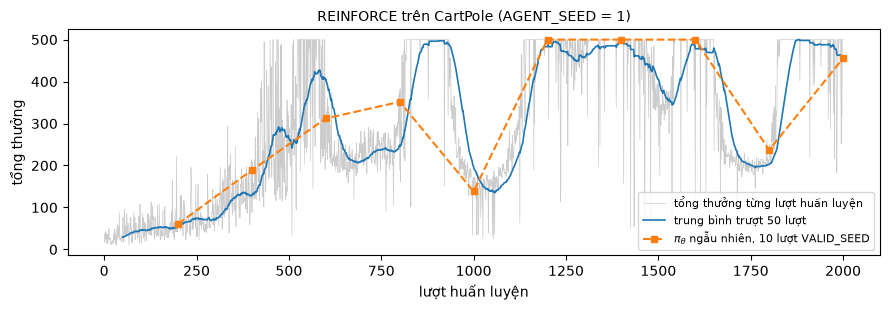

REINFORCE, ngẫu nhiên      tổng thưởng   457.64 ±  8.57 (sd  85.66) | G_0   98.15 | dài    458 | cắt ngắn  64%
   - góc + vận tốc góc:   -42.4 ±  16.8 (khoảng 95%, ghép cặp)
REINFORCE, tham lam        tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
   - góc + vận tốc góc:     0.0 ±   0.0 (khoảng 95%, ghép cặp)
REINFORCE, mốc tốt nhất    tổng thưởng   489.78 ±  5.92 (sd  59.20) | G_0   98.67 | dài    490 | cắt ngắn  96%
   - góc + vận tốc góc:   -10.2 ±  11.6 (khoảng 95%, ghép cặp)
DQN (mục 6)                tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
   - góc + vận tốc góc:     0.0 ±   0.0 (khoảng 95%, ghép cặp)
Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): ngẫu nhiên 457,64 ± 8,57; tham lam 500,00; mốc tốt nhất 489,78 ở lượt 1200; 605 824 bước môi trường


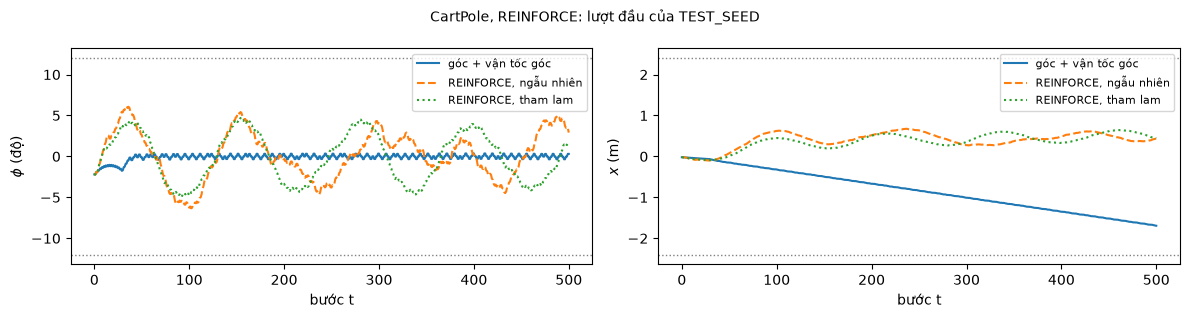

Trình phát: 3 lượt, HTML nhúng 41 kB


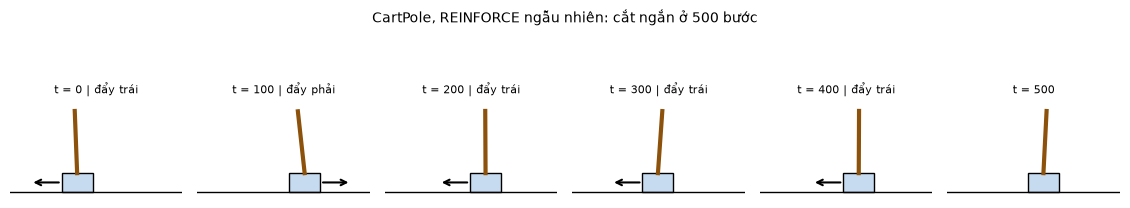

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.2))
er = log_rf["ep_ret"]; sm = np.convolve(er, np.ones(50) / 50, mode="valid")
ax.plot(np.arange(1, len(er) + 1), er, color="0.8", lw=0.5, label="tổng thưởng từng lượt huấn luyện")
ax.plot(np.arange(50, len(er) + 1), sm, lw=1.2, label="trung bình trượt 50 lượt")
ax.plot(log_rf["ckpt_ep"], log_rf["ckpt_mean"], "s--", ms=4, label=r"$\pi_\theta$ ngẫu nhiên, 10 lượt VALID_SEED")
ax.set_xlabel("lượt huấn luyện"); ax.set_ylabel("tổng thưởng"); ax.legend(fontsize=8)
ax.set_title("REINFORCE trên CartPole (AGENT_SEED = 1)", fontsize=10); fig.tight_layout(); plt.show()

res_rf = {"REINFORCE, ngẫu nhiên": evaluate_policy(envs["CartPole-v1"], stoch_policy(pol_cp), N_TEST, TEST_SEED),
          "REINFORCE, tham lam": evaluate_policy(envs["CartPole-v1"], greedy_pi(pol_cp), N_TEST, TEST_SEED),
          "REINFORCE, mốc tốt nhất": evaluate_policy(envs["CartPole-v1"], stoch_policy(best_rf), N_TEST, TEST_SEED),
          "DQN (mục 6)": evaluate_policy(envs["CartPole-v1"], net_policy(nets_cp["DQN"]), N_TEST, TEST_SEED)}
ref = results_ref["CartPole-v1"]["góc + vận tốc góc"]
for name, r in res_rf.items():
    summarize(name, r)
    m, h = paired_difference(r, ref)
    print(f"   - góc + vận tốc góc: {m:7.1f} ± {h:5.1f} (khoảng 95%, ghép cặp)")
print("Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): ngẫu nhiên 457,64 ± 8,57; tham lam 500,00; mốc tốt nhất 489,78 ở lượt 1200; "
      "605 824 bước môi trường")
ep_rf = {"góc + vận tốc góc": record_episode(envs["CartPole-v1"], cartpole_angle_vel, TEST_SEED, "cartpole"),
         "REINFORCE, ngẫu nhiên": record_episode(envs["CartPole-v1"], stoch_policy(pol_cp), TEST_SEED, "cartpole"),
         "REINFORCE, tham lam": record_episode(envs["CartPole-v1"], greedy_pi(pol_cp), TEST_SEED, "cartpole")}
plot_episodes(ep_rf, "CartPole, REINFORCE: lượt đầu của TEST_SEED")
display(player(ep_rf))
filmstrip(ep_rf["REINFORCE, ngẫu nhiên"], 6, f"CartPole, REINFORCE ngẫu nhiên: {end_reason(ep_rf['REINFORCE, ngẫu nhiên'])}"); plt.show()

**Đọc kết quả của lần chạy trực tiếp.** Với torch 2.15.0+cpu và hai luồng, ô trên cho đúng các số in ở dòng tham chiếu. Các số dưới đây là số tham chiếu khi soạn; với phiên bản khác, số in ra có thể khác. Chính sách ngẫu nhiên cuối đạt $457{,}6\pm8{,}6$ trên `TEST_SEED` ($64\%$ lượt đủ $500$ bước), chính sách tham lam $500$ ở cả $100$ lượt. Lần chạy hạt giống $1$ trong bảng dưới cho cùng $457{,}6$ trên `TEST_SEED`. Đường học dao động mạnh: trung bình trượt lên gần $500$ rồi rơi về $150$–$250$ nhiều lần, và mốc kiểm định ở lượt $1000$ chỉ còn khoảng $140$. Mỗi cập nhật dùng $\widehat g$ trung bình trên bốn lượt; khi chính sách đã tốt, mọi lợi tức đều dương và gần nhau, nên hướng cập nhật chủ yếu là nhiễu (mục 12 đo điều này), và một chuỗi cập nhật nhiễu có thể kéo chính sách khỏi vùng tốt.

Bảng dưới gộp mọi cấu hình REINFORCE đã chạy trên CartPole khi soạn (ba hoặc năm hạt giống mỗi cấu hình). Cột "ngẫu nhiên" và "tham lam" là chính sách cuối trên $100$ lượt `TEST_SEED`; cột "tốt nhất" là chính sách ngẫu nhiên ở mốc kiểm định tốt nhất; TB ± SE giữa hạt giống. Dòng đánh dấu `*` là cấu hình của ô mã trên; dòng in thêm sau bảng cho giá trị từng hạt giống của cấu hình đó.

In [25]:
RF_RUNS = TABLES["rf"]          # RF_RUNS[env][cấu hình] = {"spec": {...}, "seeds": {hạt giống: {...}}}


def show_rf_table(env_id, chosen=None):
    unit = "số ống" if env_id == "FlappyBird-v0" else "tổng thưởng"
    print(f"{env_id}: {unit} trên 100 lượt TEST_SEED, TB ± SE giữa hạt giống")
    print(f"  {'bộ tối ưu':<9} {'alpha':>7} {'K':>2} {'gamma^t':>7} {'mạng':<15} {'lượt':>6} {'n':>2} | {'ngẫu nhiên':>16} "
          f"{'tham lam':>9} {'tốt nhất':>9} | {'bước TB':>9} {'giây TB':>7}")
    rows = sorted(RF_RUNS[env_id].items(), key=lambda kv: (kv[1]["spec"]["opt"], -kv[1]["spec"]["lr"], kv[1]["spec"]["K"], kv[0]))
    for c, d in rows:
        sp, S = d["spec"], d["seeds"]
        v = lambda k: np.array([S[s][k] for s in S], float)
        st = v("stoch"); se = st.std(ddof=1) / np.sqrt(len(st)) if len(st) > 1 else np.nan
        mark = "*" if c == chosen else " "
        net_s = f"{sp['act']} {tuple(sp['hidden'])}"
        print(f"{mark} {sp['opt']:<9} {sp['lr']:7.0e} {sp['K']:2d} {'có' if sp['gamma_t'] else 'không':>7} "
              f"{net_s:<15} {int(np.mean(v('n_ep'))):6d} {len(S):2d} | {st.mean():8.2f} ± {se:6.2f} "
              f"{v('greedy').mean():9.2f} {v('best').mean():9.2f} | {v('steps').mean():9.0f} {v('secs').mean():7.0f}")
    if chosen:
        S = RF_RUNS[env_id][chosen]["seeds"]
        print(f"  * từng hạt giống, TEST_SEED: {[S[s]['stoch'] for s in sorted(S, key=int)]}; "
              f"SEL_SEED: {[S[s]['sel'] for s in sorted(S, key=int)]}")


show_rf_table("CartPole-v1", chosen="adam1e-3_K4_N2000")

CartPole-v1: tổng thưởng trên 100 lượt TEST_SEED, TB ± SE giữa hạt giống
  bộ tối ưu   alpha  K gamma^t mạng              lượt  n |       ngẫu nhiên  tham lam  tốt nhất |   bước TB giây TB
  adam        1e-02  1      có tanh (64, 64)     1000  3 |    15.13 ±   5.79     15.16     72.45 |     24376       9
  adam        3e-03  1      có tanh (64, 64)     1000  3 |    23.94 ±   6.01     24.23    195.48 |     87390      31
  adam        3e-03  1   không tanh (64, 64)     1000  3 |   228.84 ± 143.76    233.76    257.19 |    146373      46
  adam        3e-03  1      có relu (64, 64)     1000  3 |   403.94 ±  19.14    427.79    493.78 |    235976      65
  adam        2e-03  4      có tanh (64, 64)     2000  3 |   373.48 ± 114.80    381.04    496.83 |    605919     144
  adam        1e-03  1      có tanh (64, 64)     1000  3 |   273.88 ±  26.78    276.89    491.87 |    306379      92
  adam        1e-03  1      có tanh (64, 64)     2000  3 |   377.85 ± 107.04    383.97    492.20 |    680679 

**Đọc bảng.** Các con số cho ba quan sát.

- **Bước học lớn với tanh.** Với tầng ẩn tanh, có $\gamma^t$ và Adam $10^{-2}$ hoặc $3\cdot10^{-3}$, chính sách cuối giữ cột chưa tới $25$ bước, dù mốc tốt nhất từng đạt $70$–$200$. Mọi phần thưởng của CartPole bằng $+1$, nên mọi $G_t$ dương và mỗi cập nhật tăng log xác suất của mọi hành động đã chọn; khi một hành động chiếm gần hết xác suất ở nhiều quan sát, chính sách gần như tất định, các lượt rất ngắn và gradient gần $0$, nên khó thoát ra. Hai dòng cùng $\alpha=3\cdot10^{-3}$ cho kết quả khác: bỏ $\gamma^t$ cho $228{,}8\pm143{,}8$ (một hạt giống đạt $500$), và tầng ẩn ReLU cho $403{,}9\pm19{,}1$ sau $65$ giây, cao hơn và nhanh hơn cấu hình được chọn ($381{,}1\pm87{,}8$ sau $134$ giây; trên `SEL_SEED` là $400{,}2$ so với $382{,}0$). Dòng ReLU có trong bảng khi cấu hình được chốt nhưng không được chọn; notebook giữ cấu hình đã chốt để không đổi tiêu chí sau khi xem thêm kết quả. Ba hạt giống và $1000$ lượt chưa đủ để kết luận ReLU tốt hơn tanh; nhiệm vụ 8 ở mục 15 đề nghị phép so đó.
- **Ngân sách và $K$.** Cùng $\alpha=10^{-3}$, tăng số lượt từ $1000$ lên $2000$ nâng trung bình từ khoảng $274$ lên $378$–$381$ (có hoặc không gộp $K=4$ lượt), và $4000$ lượt với $K=4$ cho $489{,}3\pm10{,}3$ trên năm hạt giống, tham lam $500$ ở cả năm. Độ phân tán giữa hạt giống ở $2000$ lượt vẫn lớn (SE $88$–$107$): một trong ba hạt giống dừng ở khoảng $165$–$206$.
- **Có và không có $\gamma^t$.** Ở cùng $\alpha$ và ngân sách, bỏ $\gamma^t$ cho trung bình tương đương ($290{,}6$ so với $273{,}9$; $393{,}7$ so với $381{,}1$), chênh lệch nhỏ hơn nhiều so với độ phân tán giữa ba hạt giống. Với SGD, tức đúng $\theta\leftarrow\theta+\alpha\widehat g$, không bước học nào trong ba bước đã thử cho trung bình trên $125$: độ lớn của $\widehat g$ tỉ lệ với $G_t$ (tới $100$) và với độ dài lượt, nên một $\alpha$ cố định vừa quá lớn ở cuối vừa quá nhỏ ở đầu.

Cấu hình được chốt sau khi đã xem các con số trên `TEST_SEED` của một phần bảng này, nên kết quả của nó trên `TEST_SEED` là ước lượng lạc quan. Dữ liệu nhúng `RF_RUNS` có thêm điểm trên $100$ lượt `SEL_SEED` của từng hạt giống (khóa `sel`).

## 10. Đối chiếu: cấu hình REINFORCE của `pytorch/examples`

**Vấn đề.** Tệp `reinforcement_learning/reinforce.py` của kho `pytorch/examples` (commit `acc295d`) là cài đặt REINFORCE trên CartPole trong kho ví dụ chính thức của PyTorch, và học nhanh hơn nhiều so với mục 9 với bước học lớn gấp mười. Nó khác Thuật toán 09.25 ở hai điểm:

1. **Chuẩn hóa lợi tức trong lượt.** Trọng số của $\log\pi_\theta(A_t\mid O_t)$ là $\tilde G_t=(G_t-\bar G)/(s_G+\varepsilon)$, với $\bar G$, $s_G$ là trung bình và độ lệch chuẩn của $G_0,\dots,G_{T-1}$ trong cùng lượt và $\varepsilon$ là một hằng nhỏ tránh chia cho $0$ (khác nhiễu $\varepsilon_a$ của mục 3). Phép trừ $\bar G$ là một dạng đường cơ sở (baseline) mà Bài 10 nghiên cứu: trừ một hằng $b$ khỏi $G_t$ không đổi kỳ vọng vì $\mathbb E[\psi_t\mid H_t]=0$ (Mệnh đề 09.17), nhưng đổi phương sai (Bài tập 09.9 cho thấy chiều ngược lại: cộng hằng làm phương sai tăng). Ở đây $\bar G$ tính từ chính lượt đó nên phụ thuộc các hành động của lượt, và phép chia cho $s_G$ đổi thang của mỗi lượt; vì vậy hướng cập nhật nói chung không còn là ước lượng không chệch của $\nabla_\theta J$. Phép chia giữ độ lớn của trọng số quanh $1$ bất kể độ dài lượt, nên bước học $10^{-2}$ dùng được.
2. **Bỏ $\gamma^t$.** Như Ví dụ 09.21, hướng trung bình khi đó không là $\nabla_\theta J$ khi $\gamma<1$; Nota và Thomas (2020) chỉ ra rằng nói chung nó không là gradient của hàm mục tiêu nào.

Mạng: $4\to128$, Dropout $0{,}6$, ReLU, $128\to2$; Adam $10^{-2}$; $\gamma=0{,}99$; cập nhật sau mỗi lượt; dừng khi lợi tức trượt $\bar R\leftarrow0{,}05\,(\text{độ dài lượt})+0{,}95\,\bar R$ vượt ngưỡng $475$ của `CartPole-v1` (`env.spec.reward_threshold`). Ô mã dưới giữ đúng các điểm này, với hai khác biệt kỹ thuật: hành động được lấy mẫu bằng bộ sinh số NumPy (như mục 9) thay cho `Categorical.sample()` của PyTorch, và số lượt bị chặn ở $1000$. Dropout bật khi huấn luyện như nguồn; khi đánh giá, mạng chuyển sang `eval()` (tắt Dropout). Ô mã đánh giá chính sách học được trên `TEST_SEED` rồi phát lượt đầu của `TEST_SEED` cạnh chính sách ngẫu nhiên của mục 9.

dừng sau 349 lượt (88441 bước môi trường), 54 giây


pytorch/examples, ngẫu nhiên tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
pytorch/examples, tham lam tổng thưởng   500.00 ±  0.00 (sd   0.00) | G_0   99.34 | dài    500 | cắt ngắn 100%
REINFORCE mục 9, ngẫu nhiên tổng thưởng   457.64 ±  8.57 (sd  85.66) | G_0   98.15 | dài    458 | cắt ngắn  64%
Khi soạn, ba hạt giống:
  hạt giống 1: đạt ngưỡng sau 349 lượt, 88441 bước; TEST ngẫu nhiên 500.0, tham lam 500.0
  hạt giống 2: đạt ngưỡng sau 413 lượt, 116070 bước; TEST ngẫu nhiên 500.0, tham lam 500.0
  hạt giống 3: đạt ngưỡng sau 618 lượt, 127382 bước; TEST ngẫu nhiên 500.0, tham lam 500.0
Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): dừng sau 349 lượt, 88 441 bước; ngẫu nhiên và tham lam 500,00
Trình phát: 3 lượt, HTML nhúng 41 kB


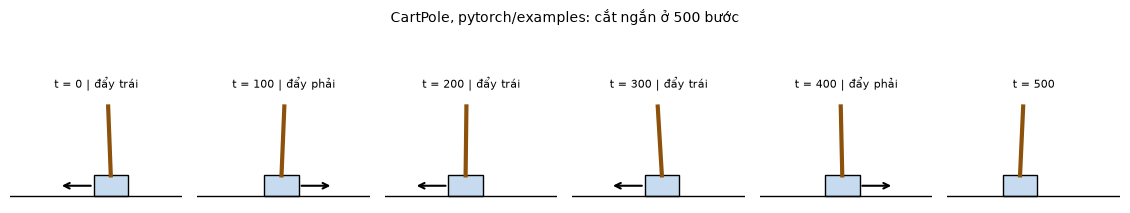

In [26]:
def train_pt_example(agent_seed=AGENT_SEED, max_episodes=1000):
    torch.manual_seed(agent_seed); rng = np.random.default_rng(agent_seed)
    env = make_env("CartPole-v1"); thr = env.spec.reward_threshold          # 475
    pol = nn.Sequential(nn.Linear(4, 128), nn.Dropout(p=0.6), nn.ReLU(), nn.Linear(128, 2))
    opt = torch.optim.Adam(pol.parameters(), lr=1e-2)
    tiny = np.finfo(np.float32).eps.item()                   # hằng nhỏ của phép chuẩn hóa
    running, lens, t0 = 10.0, [], time.time()
    for n in range(max_episodes):
        o, _ = env.reset(seed=20_000 + 100_000 * agent_seed + n)
        logps, rs = [], []
        while True:                                           # Dropout bật; log pi giữ đồ thị tính để lấy gradient
            p = torch.softmax(pol(torch.as_tensor(o, dtype=torch.float32)), dim=-1)
            pn = p.detach().numpy().astype(np.float64)
            a = int(min(np.searchsorted(np.cumsum(pn), rng.random() * pn.sum(), side="right"), 1))
            logps.append(torch.log(p[a])); o, r, term, trunc, _ = env.step(a); rs.append(r)
            if term or trunc:
                break
        G = torch.tensor(returns(np.array(rs), GAMMA), dtype=torch.float32)
        G = (G - G.mean()) / (G.std() + tiny)                 # chuẩn hóa trong lượt; không có gamma^t
        loss = -(torch.stack(logps) * G).sum()
        opt.zero_grad(); loss.backward(); opt.step()
        lens.append(len(rs)); running = 0.05 * len(rs) + 0.95 * running
        if running > thr:
            break
    pol.eval()                                                # tắt Dropout khi đánh giá
    return pol, dict(n_episodes=len(lens), steps=int(sum(lens)), secs=time.time() - t0, lens=np.array(lens))


pol_pt, log_pt = train_pt_example()
print(f"dừng sau {log_pt['n_episodes']} lượt ({log_pt['steps']} bước môi trường), {log_pt['secs']:.0f} giây")
res_pt = {"pytorch/examples, ngẫu nhiên": evaluate_policy(envs["CartPole-v1"], stoch_policy(pol_pt), N_TEST, TEST_SEED),
          "pytorch/examples, tham lam": evaluate_policy(envs["CartPole-v1"], greedy_pi(pol_pt), N_TEST, TEST_SEED)}
for name, r in {**res_pt, "REINFORCE mục 9, ngẫu nhiên": res_rf["REINFORCE, ngẫu nhiên"]}.items():
    summarize(name, r)
print("Khi soạn, ba hạt giống:")
for d in TABLES["pt"]:
    print(f"  hạt giống {d['seed']}: đạt ngưỡng sau {d['solved_at']} lượt, {d['steps']} bước; "
          f"TEST ngẫu nhiên {d['stoch_TEST']:.1f}, tham lam {d['greedy_TEST']:.1f}")
print("Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng): dừng sau 349 lượt, 88 441 bước; ngẫu nhiên và tham lam 500,00")
ep_pt = {"REINFORCE mục 9, ngẫu nhiên": ep_rf["REINFORCE, ngẫu nhiên"],
         "pytorch/examples, ngẫu nhiên": record_episode(envs["CartPole-v1"], stoch_policy(pol_pt), TEST_SEED, "cartpole"),
         "pytorch/examples, tham lam": record_episode(envs["CartPole-v1"], greedy_pi(pol_pt), TEST_SEED, "cartpole")}
display(player(ep_pt))
filmstrip(ep_pt["pytorch/examples, ngẫu nhiên"], 6, f"CartPole, pytorch/examples: {end_reason(ep_pt['pytorch/examples, ngẫu nhiên'])}"); plt.show()

**Đọc kết quả.** Khi soạn, cấu hình này đạt ngưỡng sau $349$, $413$ và $618$ lượt ($88\,000$–$127\,000$ bước môi trường) ở ba hạt giống, và cả ba chính sách đạt $500$ trên $100$ lượt `TEST_SEED`. REINFORCE thuần của mục 9 dùng $2000$ lượt (khoảng $500\,000$ bước) cho trung bình $381$ trên ba hạt giống. Cùng bước học $10^{-2}$ nhưng không chuẩn hóa (bảng ở mục 9) làm chính sách sụp về $15$ bước. Hai thay đổi được gộp trong một cấu hình, nên so sánh này không tách được phần đóng góp của chuẩn hóa với phần của việc bỏ $\gamma^t$, của Dropout hay của mạng rộng hơn; mục 12 đo trực tiếp ảnh hưởng của chuẩn hóa lên phương sai của hướng cập nhật.

## 11. REINFORCE trên Lunar Lander và Flappy Bird

**Vấn đề.** Không thư viện tham chiếu nào được kiểm (RL Baselines3 Zoo, CleanRL, Spinning Up, `pytorch/examples`, khóa học Deep RL của Hugging Face) công bố cấu hình REINFORCE thuần cho hai môi trường này; với Lunar Lander, RL Baselines3 Zoo có cấu hình A2C, một phương pháp gradient chính sách có hàm giá trị học được (actor–critic, Bài 10). Mục này là thí nghiệm khám phá: mọi cấu hình đã chạy khi soạn được công bố, kể cả cấu hình học kém. Một lần chạy mất từ khoảng $1{,}5$ tới $15$ phút, nên notebook chỉ đọc bảng.

Lunar Lander dùng hai tầng ẩn $128$ nút, Flappy Bird $64$ nút; ngân sách dừng ở số lượt $N_{\text{lượt}}$ hoặc ở tổng số bước môi trường (Lunar Lander $1{,}5$–$2$ triệu bước, Flappy Bird $1$–$4$ triệu bước), tùy điều kiện nào tới trước. Ở Lunar Lander, các lượt lơ lửng dài $1000$ bước tiêu nhanh ngân sách bước.

LunarLander-v3: tổng thưởng trên 100 lượt TEST_SEED, TB ± SE giữa hạt giống
  bộ tối ưu   alpha  K gamma^t mạng              lượt  n |       ngẫu nhiên  tham lam  tốt nhất |   bước TB giây TB
  adam        2e-03  1      có tanh (128, 128)   5000  2 |  -126.16 ±   1.69   -127.33    -37.61 |    835866     346
  adam        1e-03  1      có tanh (128, 128)   2333  2 |   -24.93 ±  30.93    -49.31    -11.24 |   1500292     587
  adam        1e-03  1   không tanh (128, 128)   4873  2 |     9.41 ±  37.99     19.80    230.01 |   1451349     590
  adam        1e-03  4      có tanh (128, 128)   3109  2 |   -51.14 ±   8.27    -65.95    -43.26 |   2000834     730
  adam        5e-04  1      có tanh (128, 128)   2742  2 |     9.16 ±  16.88    -43.07    -17.29 |   1500380     591

FlappyBird-v0: số ống trên 100 lượt TEST_SEED, TB ± SE giữa hạt giống
  bộ tối ưu   alpha  K gamma^t mạng              lượt  n |       ngẫu nhiên  tham lam  tốt nhất |   bước TB giây TB
  adam        3e-03  1      có tanh 

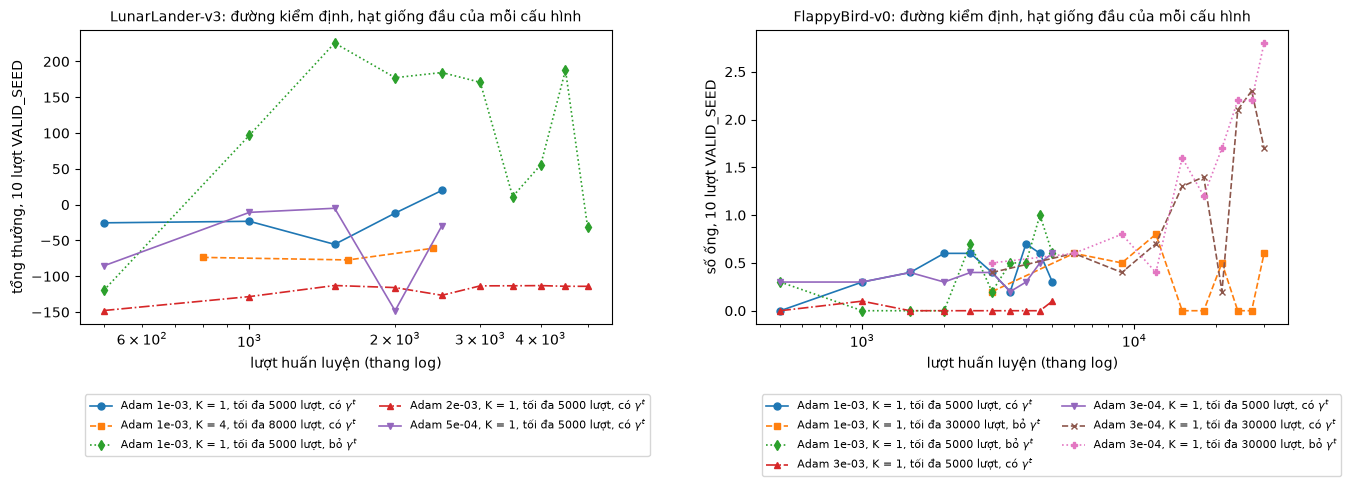

In [27]:
show_rf_table("LunarLander-v3")
print()
show_rf_table("FlappyBird-v0")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, env_id_ in zip(axes, ["LunarLander-v3", "FlappyBird-v0"]):
    for k, (c, d) in enumerate(sorted(RF_RUNS[env_id_].items())):
        s0 = sorted(d["seeds"], key=int)[0]; S = d["seeds"][s0]; sp = d["spec"]
        lab = f"Adam {sp['lr']:.0e}, K = {sp['K']}, tối đa {sp['N']} lượt, {'có' if sp['gamma_t'] else 'bỏ'} " + r"$\gamma^t$"
        ax.plot(S["ck_ep"], S["ck"], marker="osd^vxP*"[k % 8], ls=["-", "--", ":", "-."][k % 4], lw=1.2, ms=5, label=lab)
    ax.set_xscale("log"); ax.set_xlabel("lượt huấn luyện (thang log)")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
    ax.set_ylabel(("số ống" if env_id_ == "FlappyBird-v0" else "tổng thưởng") + ", 10 lượt VALID_SEED"); ax.set_title(f"{env_id_}: đường kiểm định, hạt giống đầu của mỗi cấu hình", fontsize=10)
fig.tight_layout(); plt.show()

**Đọc kết quả.** Trong dữ liệu nhúng, tên cấu hình ghi tốc độ học, `K4` (gộp bốn lượt), `nog` (bỏ $\gamma^t$), `N30k` ($30\,000$ lượt).

- **Lunar Lander.** Không cấu hình nào cho chính sách cuối ổn định: trung bình chính sách ngẫu nhiên cuối từ $-126$ (Adam $2\cdot10^{-3}$, chính sách sụp về rơi tự do) tới khoảng $9$. Cấu hình bỏ $\gamma^t$ với $\alpha=10^{-3}$ có mốc kiểm định tốt nhất đạt $230{,}0\pm9{,}2$ trên `TEST_SEED` ở cả hai hạt giống, ngang bộ điều khiển viết tay, nhưng chính sách cuối của cùng các lần chạy chỉ còn $-28{,}6$ và $47{,}4$ trên `TEST_SEED`. Một giả thuyết, chưa được thí nghiệm tách riêng: với $\gamma^t$, các bước hạ cánh ($t$ khoảng $200$–$400$) nhận trọng số $0{,}99^t\approx0{,}02$–$0{,}13$, nên gradient ít thay đổi hành vi ở cuối lượt; bỏ $\gamma^t$ đổi hướng (Ví dụ 09.21) theo chiều làm các bước cuối nặng hơn.
- **Flappy Bird.** Tiến bộ đều nhưng chậm: với $\alpha=3\cdot10^{-4}$, số ống trung bình trên các lượt huấn luyện tăng từ $0{,}06$ lên khoảng $0{,}85$ qua $5000$ lượt (chính sách cuối đạt $0{,}74$ trên `TEST_SEED`), và $30\,000$ lượt ($2$–$3$ triệu bước, $9$–$14$ phút) cho trung bình $0{,}6$–$1{,}7$ ống tùy cấu hình, so với $26$–$29$ ống của DQN và Double DQN ở mục 7 với $300\,000$ bước.

Trong ngân sách của bài, REINFORCE thuần không học được chính sách có ích trên Flappy Bird và không giữ được chính sách tốt trên Lunar Lander. Lượt ghi khi soạn dưới phát chính sách ngẫu nhiên ở mốc tốt nhất của Lunar Lander (Adam $10^{-3}$, bỏ $\gamma^t$, hạt giống $1$) và chính sách cuối trên Flappy Bird (Adam $3\cdot10^{-4}$, $30\,000$ lượt, hạt giống $1$).

LunarLander-v3  điều khiển viết tay          197 bước, nằm yên (+100)
LunarLander-v3  REINFORCE (ghi khi soạn)     413 bước, nằm yên (+100)
Trình phát: 2 lượt, HTML nhúng 28 kB


FlappyBird-v0   luật tay                    1365 bước, va chạm, 35 ống
FlappyBird-v0   REINFORCE (ghi khi soạn)      53 bước, va chạm, 0 ống
Trình phát: 2 lượt, HTML nhúng 49 kB; vẽ mỗi 2 bước để hiển thị trọn lượt dài 1365 bước


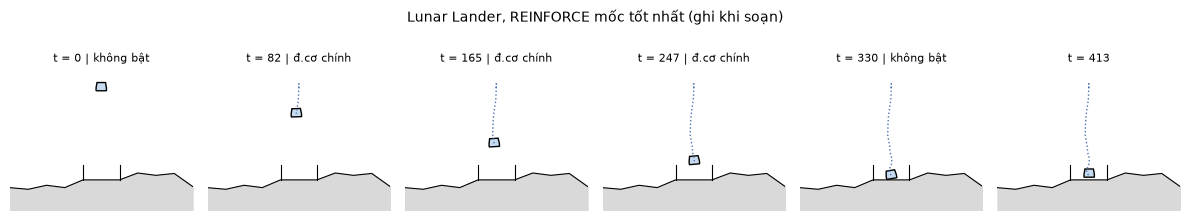

In [28]:
for env_id_, ref_name in [("LunarLander-v3", "điều khiển viết tay"), ("FlappyBird-v0", "luật tay")]:
    eps_ = {ref_name: record_episode(envs[env_id_], REF_POLICIES[env_id_][ref_name], TEST_SEED, KIND[env_id_]),
            "REINFORCE (ghi khi soạn)": EP_SAVED[env_id_]["REINFORCE"]}
    for name, ep in eps_.items():
        print(f"{env_id_:<15} {name:<26} {len(ep['actions']):5d} bước, {end_reason(ep)}")
    display(player(eps_))
filmstrip(EP_SAVED["LunarLander-v3"]["REINFORCE"], 6, "Lunar Lander, REINFORCE mốc tốt nhất (ghi khi soạn)"); plt.show()

## 12. Phương sai của ước lượng gradient

**Vấn đề.** Hệ quả 09.26 cho $\mathbb E[\widehat g\mid\theta_{\mathrm{old}}]=\nabla_\theta J(\theta_{\mathrm{old}})$, nhưng mỗi cập nhật chỉ dùng $K$ lượt. Muốn biết một cập nhật đi đúng hướng tới đâu, cần so độ lớn của gradient với độ phân tán của ước lượng. Tại một $\theta$ cố định, ô mã dưới thu $M$ lượt độc lập bằng $\pi_\theta$, tính một ước lượng $\widehat g^{(j)}\in\mathbb R^d$ cho mỗi lượt $j$, rồi in:

- $\lVert\bar g\rVert^2$ với $\bar g=\frac1M\sum_j\widehat g^{(j)}$, và tổng phương sai $V=\operatorname{tr}\widehat{\mathrm{Cov}}(\widehat g)$ (tổng phương sai mẫu của $d$ tọa độ);
- ước lượng hiệu chỉnh $\lVert\bar g\rVert^2-V/M$ của $\lVert\nabla_\theta J\rVert^2$: vì $\mathbb E\lVert\bar g\rVert^2=\lVert\nabla_\theta J\rVert^2+\operatorname{tr}\mathrm{Cov}(\widehat g)/M$, độ dài của trung bình mẫu luôn chứa một phần nhiễu;
- tỉ số $V/\lVert\bar g\rVert^2$; trung bình của cosin giữa một $\widehat g^{(j)}$ và $\bar g$; tỉ lệ lượt có $\widehat g^{(j)\top}\bar g>0$.

Bốn cách tính trọng số được so trên cùng các lượt: Thuật toán 09.25 ($\gamma^tG_t$); bỏ $\gamma^t$ ($G_t$); trừ một đường cơ sở hằng $\gamma^t(G_t-b_0)$ với $b_0$ là trung bình của mọi $G_t$ trên $20$ lượt khác thu trước (ước lượng vẫn không chệch vì $b_0$ không phụ thuộc các lượt được dùng); chuẩn hóa trong lượt như `pytorch/examples`. Hai điểm $\theta$ được xét: chính sách khởi tạo (hạt giống $1$, lượt ngắn) và chính sách ngẫu nhiên cuối của mục 9. Tổng phương sai $V$ so được giữa ba cách đầu (cùng thang); cách chuẩn hóa đổi thang của mỗi lượt nên chỉ so được qua tỉ số và cosin. Khi $\lVert\bar g\rVert^2$ không vượt mức nhiễu $V/M$ (ước lượng hiệu chỉnh âm), tỉ số $V/\lVert\bar g\rVert^2$ có mẫu số chủ yếu là nhiễu và không ước lượng được tin cậy.

Ánh xạ sang mã: `samples[k]` là mảng $(M,d)$ các $\widehat g^{(j)}$ của cách tính trọng số `k`; `gbar` là $\bar g$, cỡ $(d,)$; `V` là $V$; `n2` là $\lVert\bar g\rVert^2$; `cos` cỡ $(M,)$; `b` là $b_0$; $d=4610$.

In [29]:
def grad_samples(pol, env, M, seed, b=None):
    # M lượt độc lập bằng pi_theta tại theta cố định; mỗi lượt một g_hat (d,) cho mỗi cách tính trọng số
    rng = np.random.default_rng(seed); out = {k: [] for k in ["gamma^t G_t", "G_t", "gamma^t (G_t - b)", "chuẩn hóa"]}
    allG = []
    for j in range(M):
        O, A, rs, _ = run_episode(env, pol, rng, seed + j)
        G = returns(rs, GAMMA); disc = GAMMA ** np.arange(len(rs)); allG.append(G)
        ws = {"gamma^t G_t": disc * G, "G_t": G, "gamma^t (G_t - b)": disc * (G - (b if b is not None else 0.0)),
              "chuẩn hóa": (G - G.mean()) / (G.std(ddof=1) + 1e-8) if len(G) > 1 else 0 * G}
        logp = torch.log_softmax(pol(torch.from_numpy(O)), -1).gather(1, torch.from_numpy(A)[:, None]).squeeze(1)   # (T,)
        for k, w in ws.items():
            g = torch.autograd.grad((torch.as_tensor(w, dtype=torch.float32) * logp).sum(), list(pol.parameters()), retain_graph=True)
            out[k].append(torch.cat([x.flatten() for x in g]).numpy())                  # g_hat = sum_t w_t psi_t, (d,)
    return {k: np.array(v) for k, v in out.items()}, np.concatenate(allG)


def variance_report(samples, title):
    print(title)
    ref = samples["gamma^t G_t"].mean(0)
    for k, Gs in samples.items():
        M = len(Gs); gbar = Gs.mean(0); V = Gs.var(0, ddof=1).sum(); n2 = gbar @ gbar
        cos = Gs @ gbar / (np.linalg.norm(Gs, axis=1) * np.linalg.norm(gbar) + 1e-12)
        print(f"  {k:<18} V = {V:10.3g} | |gbar|^2 = {n2:10.3g} | hiệu chỉnh {n2 - V / M:10.3g} | V/|gbar|^2 = {V / n2:7.1f} | "
              f"cos TB = {cos.mean():5.2f} | cùng hướng {np.mean(cos > 0):4.0%} | cos(gbar, gbar Thuật toán 09.25) = "
              f"{gbar @ ref / (np.linalg.norm(gbar) * np.linalg.norm(ref)):5.2f}")


env_cp = make_env("CartPole-v1")
torch.manual_seed(AGENT_SEED); pol_init = PolicyNet(4, 2, CFG_RF["hidden"])          # cùng khởi tạo với mục 9
t0 = time.time()
for pol_, M, title in [(pol_init, 200, "Chính sách khởi tạo, M = 200 lượt"), (pol_cp, 100, "Chính sách cuối của mục 9, M = 100 lượt")]:
    _, Gpilot = grad_samples(pol_, env_cp, 20, 80_000)                                 # 20 lượt riêng để tính b
    samples, Gs = grad_samples(pol_, env_cp, M, 70_000, b=Gpilot.mean())
    print(f"(độ dài lượt TB {len(Gs) / M:.0f} bước, b = {Gpilot.mean():.1f})")
    variance_report(samples, title)
print(f"({time.time() - t0:.0f} giây)")
print("Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng), V của gamma^t G_t / G_t / gamma^t (G_t - b): "
      "khởi tạo 7,93e3 / 1,15e4 / 4,16e3; chính sách cuối 5,84e6 / 3,47e7 / 2,58e5")
print("Thử nghiệm sơ bộ khi soạn, Thuật toán 09.25, M = 200, hai chính sách đã học khác trên CartPole "
      "(Adam 1e-3, 1000 lượt, hạt giống 1 và 3): V/|gbar|^2 = 40,9 và 865,6")

(độ dài lượt TB 24 bước, b = 13.9)
Chính sách khởi tạo, M = 200 lượt
  gamma^t G_t        V =   7.93e+03 | |gbar|^2 =        663 | hiệu chỉnh        623 | V/|gbar|^2 =    12.0 | cos TB =  0.22 | cùng hướng  58% | cos(gbar, gbar Thuật toán 09.25) =  1.00
  G_t                V =   1.15e+04 | |gbar|^2 =        907 | hiệu chỉnh        849 | V/|gbar|^2 =    12.7 | cos TB =  0.21 | cùng hướng  58% | cos(gbar, gbar Thuật toán 09.25) =  1.00
  gamma^t (G_t - b)  V =   4.16e+03 | |gbar|^2 =        824 | hiệu chỉnh        804 | V/|gbar|^2 =     5.1 | cos TB =  0.23 | cùng hướng  70% | cos(gbar, gbar Thuật toán 09.25) =  0.97
  chuẩn hóa          V =       62.7 | |gbar|^2 =       4.93 | hiệu chỉnh       4.62 | V/|gbar|^2 =    12.7 | cos TB =  0.26 | cùng hướng  61% | cos(gbar, gbar Thuật toán 09.25) =  0.99


(độ dài lượt TB 427 bước, b = 77.2)
Chính sách cuối của mục 9, M = 100 lượt
  gamma^t G_t        V =   5.84e+06 | |gbar|^2 =   2.83e+03 | hiệu chỉnh  -5.55e+04 | V/|gbar|^2 =  2064.1 | cos TB =  0.09 | cùng hướng  57% | cos(gbar, gbar Thuật toán 09.25) =  1.00
  G_t                V =   3.47e+07 | |gbar|^2 =   9.97e+04 | hiệu chỉnh  -2.47e+05 | V/|gbar|^2 =   348.3 | cos TB =  0.06 | cùng hướng  53% | cos(gbar, gbar Thuật toán 09.25) = -0.20
  gamma^t (G_t - b)  V =   2.58e+05 | |gbar|^2 =   3.25e+03 | hiệu chỉnh        666 | V/|gbar|^2 =    79.5 | cos TB =  0.19 | cùng hướng  67% | cos(gbar, gbar Thuật toán 09.25) =  0.77
  chuẩn hóa          V =   5.48e+03 | |gbar|^2 =        145 | hiệu chỉnh       90.6 | V/|gbar|^2 =    37.7 | cos TB =  0.21 | cùng hướng  63% | cos(gbar, gbar Thuật toán 09.25) =  0.03
(13 giây)
Tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng), V của gamma^t G_t / G_t / gamma^t (G_t - b): khởi tạo 7,93e3 / 1,15e4 / 4,16e3; chính sách cuối 5,84e6 / 3,47e7 / 2,58e5
Th

**Đọc kết quả.** Các số trong đoạn này là số tham chiếu khi soạn (torch 2.15.0+cpu, hai luồng), cũng là số mà ô trên in ra với cùng phiên bản; với phiên bản khác, $\theta$ của mục 9 khác và con số đổi theo.

- **Chính sách khởi tạo** (lượt dài trung bình $24$ bước). Với Thuật toán 09.25, $V/\lVert\bar g\rVert^2\approx12$, cosin trung bình giữa một ước lượng một lượt và trung bình $0{,}22$, và $42\%$ ước lượng một lượt có tích vô hướng âm với trung bình: gần một nửa số cập nhật dùng một lượt đi ngược hướng trung bình. Trừ đường cơ sở hằng $b_0$ giảm $V$ khoảng $1{,}9$ lần ($7{,}93\cdot10^3$ xuống $4{,}16\cdot10^3$), nâng tỉ lệ cùng hướng lên $70\%$ và giữ hướng trung bình (cosin $0{,}97$ với hướng của Thuật toán 09.25). Bỏ $\gamma^t$ tăng $V$ ($1{,}15\cdot10^4$) cùng với độ dài $\bar g$, nên tỉ số gần như không đổi.
- **Chính sách cuối của mục 9** (lượt dài trung bình $427$ bước, mọi $G_t$ dương). Với Thuật toán 09.25, ước lượng hiệu chỉnh $\lVert\bar g\rVert^2-V/M$ âm: với $M=100$ lượt, trung bình của $\widehat g$ không phân biệt được với $0$, nên tỉ số $V/\lVert\bar g\rVert^2$ in ra và cosin giữa các hướng trung bình (cột cuối) chủ yếu phản ánh nhiễu. Thử nghiệm sơ bộ khi soạn, ở hai chính sách đã học khác trên CartPole với $M=200$ (dòng in cuối của ô trên), cho tỉ số $41$ và $866$: đại lượng này không ổn định giữa các điểm $\theta$. Trừ đường cơ sở hằng giảm tổng phương sai $V$ khoảng $23$ lần ($5{,}84\cdot10^6$ xuống $2{,}58\cdot10^5$) và cho ước lượng hiệu chỉnh dương.

Phương sai lớn của $\widehat g$ phù hợp với ba hiện tượng của mục 9–11: cần nhiều lượt cho mỗi cập nhật đáng tin; bước học lớn dễ đẩy chính sách tới một vùng gần tất định rồi kẹt ở đó; và cấu hình có chuẩn hóa lợi tức học nhanh hơn với bước học lớn hơn. Mục 10 chưa tách được phần đóng góp của chuẩn hóa vào tốc độ học (nhiệm vụ 5 ở mục 15). Bài 10 giữ Định lý 09.23 và thay $G_t$ bằng $G_t-b(O_t)$ với đường cơ sở phụ thuộc quan sát, rồi bằng một hàm giá trị học được (actor–critic).

## 13. Đối chiếu với lý thuyết

**Độ chệch của mục tiêu.** Mệnh đề 09.2 nói rằng với các ước lượng không chệch, phép cực đại cho kỳ vọng không nhỏ hơn giá trị đúng lớn nhất; mục 3 kiểm điều đó trên các ví dụ rời rạc và cho thấy độ chệch tăng theo số hành động khi các giá trị đúng bằng nhau. Mạng $Q_{\theta^-}$ không thỏa giả thiết không chệch, nên Mệnh đề 09.2 không áp dụng trực tiếp cho DQN; số liệu ở mục 6–7 chỉ là các phép đo độ lệch giữa $\max_aQ_\theta$ và lợi tức thực tế. Các phép đo đó cho đánh giá cao rõ ở CartPole ($Q_0>100$, vượt cận của mọi giá trị đúng) và ở Lunar Lander ($Q_0$ gần gấp đôi $G_0$); ở Flappy Bird, $Q_0-G_0$ của cả hai thuật toán chưa phân biệt được với $0$.

**Double DQN.** Mệnh đề 09.4 cần bản đánh giá độc lập với bản chọn; trong Thuật toán 09.5, $\theta^-$ là bản sao trễ của $\theta$, nên giả thiết không thỏa và không có bảo đảm hết chệch lên (Nhận xét 09.6). Số liệu phù hợp với nhận xét đó: trung bình $Q_0-G_0$ và đỉnh trung bình $q_i$ của Double DQN thấp hơn DQN ở cả ba môi trường, nhưng chỉ hai trong sáu hiệu vượt ngưỡng $2{,}365$ của từng phép so riêng, không hiệu nào vượt ngưỡng Bonferroni $3{,}64$, và độ lệch theo bước ở Lunar Lander đi ngược chiều. $Q_0$ của Double DQN trên CartPole vẫn trên cận $100$. Điểm của chính sách không khác nhau một cách phân biệt được; Nhận xét 09.6 cũng ghi rằng lợi ích về điểm trong bài báo của van Hasselt, Guez và Silver (2016) là quan sát thực nghiệm trên Atari với $5\cdot10^7$ bước, không phải hệ quả của một định lý.

**REINFORCE.** Hệ quả 09.26 cho $\widehat g$ không chệch dưới (G1)–(G4) với lượt sinh bởi chính $\pi_{\theta_{\mathrm{old}}}$. Cài đặt giữ hai điều kiện thuật toán phải giữ: tham số không đổi trong lượt, và mỗi lượt chỉ dùng cho cập nhật ngay sau nó. Ba điểm của cài đặt nằm ngoài phạm vi của hệ quả. Logit là mạng nơ-ron chứ không phải $\phi^\top\theta$ với đặc trưng bị chặn (G4). Lunar Lander có quan sát không Markov, nên (G1) không thỏa; theo đoạn "Trong thực hành" ở Mục 6 của ghi chú, Định lý 09.23 vẫn đúng theo lượt cho chính sách theo quan sát, còn Hệ quả 09.24 với $q_\pi$ thì không. Cả ba môi trường có cắt ngắn (CartPole ở $500$ bước, Lunar Lander ở $1000$ bước, Flappy Bird khi qua $50$ ống), nên $G_t$ là lợi tức của bài toán bị cắt ngắn. Bước Adam không tỉ lệ với $\widehat g$. Hệ quả 09.26 cũng không nói gì về phương sai; mục 12 đo nó và thấy, ở chính sách đã học, trung bình của $100$ ước lượng một lượt chưa phân biệt được với $0$.

## 14. Tổng kết

Notebook đo hai giới hạn mà ghi chú Bài 09 nêu bằng lý thuyết. Ở nửa thứ nhất, phép liệt kê cho đúng các độ chệch $\tfrac12$, $0{,}375$, $0$ của phép cực đại và $0$, $-0{,}125$ của ước lượng kép (Ví dụ 09.2–09.5); Double Q-learning giảm tỉ lệ chọn hành động "trái" sai trong bài toán Sutton–Barto 6.7; mục tiêu Double DQN cho đúng $4{,}6$ thay cho $5{,}5$ trên Ví dụ 09.6. Trên tám hạt giống của mỗi môi trường, trung bình $Q_0-G_0$ của Double DQN thấp hơn DQN ($11{,}2$ so với $15{,}8$ ở CartPole, $34{,}5$ so với $47{,}5$ ở Lunar Lander, $-0{,}7$ so với $0{,}2$ ở Flappy Bird), đỉnh trung bình $q_i$ cũng thấp hơn ở cả ba; hai trong sáu hiệu vượt ngưỡng $5\%$ của từng phép so, không hiệu nào vượt sau hiệu chỉnh Bonferroni, và độ lệch theo bước ở Lunar Lander đi ngược chiều. Điểm không khác nhau một cách phân biệt được. Ở nửa thứ hai, REINFORCE thuần với Adam $10^{-3}$, $K=4$ đạt trung bình $381$ trên CartPole sau $2000$ lượt và $489$ sau $4000$ lượt, nhưng không học được chính sách có ích trên Flappy Bird và không giữ được chính sách tốt trên Lunar Lander; cấu hình chuẩn hóa lợi tức của `pytorch/examples` đạt ngưỡng $475$ trên CartPole sau $349$–$618$ lượt. Phép đo phương sai trên CartPole cho cosin trung bình $0{,}22$ giữa một ước lượng một lượt và trung bình ở chính sách khởi tạo; ở chính sách đã học, trung bình của $100$ ước lượng chưa phân biệt được với $0$, và một đường cơ sở hằng giảm tổng phương sai khoảng $23$ lần.

**Kết quả theo mục.** Mục 3: độ chệch của phép cực đại và của ước lượng kép. Mục 4: Double Q-learning dạng bảng. Mục 5: mục tiêu Double DQN, `train_dqn`, phép đo `value_vs_return`. Mục 6–7: DQN và Double DQN trên ba môi trường, chạy trực tiếp và bảng tám hạt giống. Mục 8–9: chính sách softmax, `reinforce_loss`, `train_reinforce`, REINFORCE trên CartPole. Mục 10: cấu hình đối chiếu. Mục 11: REINFORCE trên Lunar Lander và Flappy Bird. Mục 12: phương sai của $\widehat g$.

**Công thức cần nhớ.** $a_i^*=\arg\max_aQ_\theta(O'_i,a)$, $y_i=R_i+\gamma(1-Z_i)Q_{\theta^-}(O'_i,a_i^*)$, cả hai trong `torch.no_grad()`. $L(\theta)=-\sum_t\gamma^tG_t\log\pi_\theta(A_t\mid O_t)$ với $\gamma^tG_t$ là hằng, $-\nabla_\theta L=\widehat g$.

**Giả thiết hay bị quên.** Double DQN chỉ đổi mục tiêu, không đổi siêu tham số; một hạt giống không đủ để so độ chệch của hai thuật toán, và nhiều phép so cần hiệu chỉnh ngưỡng; độ chệch của giá trị và điểm của chính sách là hai đại lượng khác nhau; REINFORCE cần lượt sinh bởi chính $\pi_{\theta_{\mathrm{old}}}$ và tham số giữ cố định trong lượt; bỏ $\gamma^t$ hoặc chuẩn hóa lợi tức trong lượt làm hướng cập nhật không còn là ước lượng không chệch của $\nabla_\theta J$.

In [30]:
print(f"Tổng thời gian chạy notebook: {time.time() - T_START:.0f} giây ({(time.time() - T_START) / 60:.1f} phút)")

Tổng thời gian chạy notebook: 591 giây (9.9 phút)


## 15. Gợi mở tìm hiểu và cải tiến

Mỗi nhiệm vụ nêu việc cần làm, gợi ý cài đặt và đại lượng cần đo. Khi so hai cấu hình, dùng ít nhất ba hạt giống tác tử (năm hoặc tám nếu hiệu nhỏ), chọn cấu hình trên `SEL_SEED` và chỉ báo kết quả cuối trên `TEST_SEED`. Ô mã cuối mục có khung hàm cho nhiệm vụ 2, 4 và 5; ô đó chỉ kiểm các khung trên số liệu của Ví dụ 09.6 và 09.18, không huấn luyện.

1. **Chu kỳ đồng bộ và độ chệch.** Theo Nhận xét 09.6, ngay sau mỗi lần đồng bộ, mục tiêu Double DQN trùng mục tiêu DQN. Chạy Double DQN và DQN trên CartPole với $C\in\{50,200,1000\}$, ba hạt giống mỗi ô, và báo $Q_0-G_0$ và đỉnh trung bình $q_i$. Dự đoán chiều của hiệu Double − DQN khi $C$ tăng trước khi chạy.
2. **Hai mạng độc lập.** Huấn luyện hai mạng trực tuyến $\theta_A$, $\theta_B$ trên hai nửa rời nhau của mỗi mini-batch; mục tiêu cho mạng A chọn bằng $\theta_A$ và đánh giá bằng mạng mục tiêu của B, như Double Q-learning (Thuật toán 09.7) với mạng. Hàm `double_two_net_targets` dưới là khung. So $Q_0-G_0$ với Double DQN trên CartPole.
3. **Đo độ chệch theo thời gian huấn luyện.** Ghi $Q_0-G_0$ ở mỗi mốc kiểm định (thêm phép đo vào nhánh `if t in ckpts` của `train_dqn`) và vẽ theo $t$ cho DQN và Double DQN. Xác định thời điểm $Q_0-G_0$ bắt đầu dương và so giữa hai thuật toán.
4. **Đường cơ sở trung bình động.** Thay $G_t$ trong `reinforce_loss` bằng $G_t-b$ với $b$ là trung bình trượt của $G_0$ trên các lượt trước (hàm `reinforce_loss_baseline`). Vì $b$ chỉ phụ thuộc các lượt trước, ước lượng vẫn không chệch. So số lượt cần để chính sách ngẫu nhiên đạt trung bình $475$ trên CartPole với mục 9, ba hạt giống. Bài 10 thay $b$ bằng một hàm của quan sát.
5. **Tách hai thay đổi của `pytorch/examples`.** Chạy ba biến thể trên CartPole: chỉ chuẩn hóa (giữ $\gamma^t$), chỉ bỏ $\gamma^t$ (không chuẩn hóa), cả hai; cùng mạng $4\to128\to2$ không Dropout, Adam $10^{-3}$ và $10^{-2}$. Báo số lượt tới ngưỡng $475$ và điểm trên `TEST_SEED`.
6. **$\gamma$ gần $1$ trên Lunar Lander.** Giả thuyết ở mục 11 cho rằng $\gamma^t$ làm các bước hạ cánh gần như không đóng góp. Chạy REINFORCE với $\gamma=0{,}999$ (giữ $\gamma^t$) và so với $\gamma=0{,}99$ bỏ $\gamma^t$. Vì $J$ đổi theo $\gamma$, so hai cách bằng tổng thưởng không chiết khấu trên `TEST_SEED`; so cả đường kiểm định và mức sụp của chính sách cuối.
7. **Dữ liệu cũ và tỉ số xác suất.** Theo Tình huống 09.2, dùng lại lượt của tham số cũ $\theta'$ làm $\widehat g$ chệch. Lưu $\log\pi_{\theta'}(A_t\mid O_t)$ khi thu lượt, dùng lại mỗi lượt cho hai cập nhật liên tiếp với trọng số $\prod_t\pi_\theta(A_t\mid O_t)/\pi_{\theta'}(A_t\mid O_t)$ ở lần thứ hai, và đo phương sai của trọng số theo độ dài lượt.
8. **Tầng ẩn ReLU hay tanh.** Bảng ở mục 9 có một dòng ReLU ($\alpha=3\cdot10^{-3}$, $1000$ lượt) cho $403{,}9\pm19{,}1$, cao hơn cấu hình tanh được chọn. Đổi `nn.Tanh()` thành `nn.ReLU()` trong `PolicyNet`, chạy cả hai họ với $\alpha\in\{10^{-3},3\cdot10^{-3}\}$, $K\in\{1,4\}$, năm hạt giống; chọn trên `SEL_SEED`, báo trên `TEST_SEED`. Ghi thêm tỉ lệ hạt giống có chính sách cuối sụp dưới $50$.

In [31]:
def double_two_net_targets(netA, netB, tgtA, tgtB, batch, gamma):
    # Nhiệm vụ 2: mục tiêu của mạng A chọn bằng A, đánh giá bằng mạng mục tiêu của B (và ngược lại)
    O, A, R, O2, Z, U = batch
    with torch.no_grad():
        aA = netA(O2).argmax(dim=1, keepdim=True)                       # (b, 1)
        aB = netB(O2).argmax(dim=1, keepdim=True)
        yA = R + gamma * (1.0 - Z) * tgtB(O2).gather(1, aA).squeeze(1)  # (b,)
        yB = R + gamma * (1.0 - Z) * tgtA(O2).gather(1, aB).squeeze(1)
    return yA, yB


def reinforce_loss_baseline(pol, O, A, rs, gamma, b):
    # Nhiệm vụ 4: L = - sum_t gamma^t (G_t - b) log pi_theta(A_t | O_t), b hằng (không phụ thuộc lượt hiện tại)
    G = returns(rs, gamma) - b
    w = G * gamma ** np.arange(len(rs))
    logp = torch.log_softmax(pol(O), dim=-1).gather(1, A.unsqueeze(1)).squeeze(1)
    return -(torch.as_tensor(w, dtype=torch.float32) * logp).sum()


def reinforce_loss_variant(pol, O, A, rs, gamma, normalize, discount_t):
    # Nhiệm vụ 5: bật/tắt riêng chuẩn hóa trong lượt và thừa số gamma^t
    G = returns(rs, gamma)
    if normalize:
        G = (G - G.mean()) / (G.std(ddof=1) + 1e-8) if len(G) > 1 else 0 * G
    w = G * (gamma ** np.arange(len(rs)) if discount_t else 1.0)
    logp = torch.log_softmax(pol(O), dim=-1).gather(1, A.unsqueeze(1)).squeeze(1)
    return -(torch.as_tensor(w, dtype=torch.float32) * logp).sum()


# Kiểm trên số liệu của Ví dụ 09.6 (Z = 0): mạng A = (3; 6), mạng B = (5; 4); mạng mục tiêu của mỗi mạng là bản sao của chính nó
batch_ex = (o1, torch.tensor([0]), torch.tensor([1.0]), o1, torch.tensor([0.0]), torch.tensor([0.0]))
yA, yB = double_two_net_targets(q_on, q_tg, q_on, q_tg, batch_ex, 0.9)   # yA = 1 + 0,9 * 4 (A chọn hành động 2, B đánh giá); yB = 1 + 0,9 * 3
O2s, A2s = torch.zeros(2, 1), torch.tensor([0, 0])
L_b = reinforce_loss_baseline(Logits([np.log(2.0), 0.0]), O2s, A2s, np.array([1.0, 2.0]), 0.9, b=0.0)
L_v = reinforce_loss_variant(Logits([np.log(2.0), 0.0]), O2s, A2s, np.array([1.0, 2.0]), 0.9, False, True)
print("yA, yB:", yA.numpy(), yB.numpy(), "| b = 0 trùng Thuật toán 09.25:", round(L_b.item(), 6) == round(L_v.item(), 6))
assert torch.allclose(yA, torch.tensor([4.6])) and torch.allclose(yB, torch.tensor([3.7]))
assert L_b.ndim == 0 and abs(L_b.item() - L_v.item()) < 1e-6

yA, yB: [4.6] [3.6999998] | b = 0 trùng Thuật toán 09.25: True


### Tài liệu tham khảo

**Tài liệu của học phần**

- Ghi chú Bài 09: Định nghĩa 09.1, 09.11, 09.14, 09.15; Mệnh đề 09.2, 09.4, 09.16, 09.17; Thuật toán 09.5, 09.7, 09.25; Định lý 09.23; Hệ quả 09.26; Nhận xét 09.6; Ví dụ 09.1–09.7, 09.18–09.21; Bài tập 09.9; Tình huống 09.1 (Double DQN trên Lunar Lander và Flappy Bird), Tình huống 09.2.
- Ghi chú Bài 08: Thuật toán 08.13, Nhận xét 08.21.
- Notebook thực hành Bài 08 (`thuc-hanh-dqn-cartpole-lunarlander-flappybird.ipynb`): hạ tầng đánh giá, chính sách tham chiếu, trình phát, cấu hình DQN (mục 7–10) và biến thể Double DQN (mục 15).

**Bài báo và sách** (theo năm)

- R. J. Williams, "Simple statistical gradient-following algorithms for connectionist reinforcement learning", *Machine Learning* 8, 1992, 229–256.
- R. S. Sutton, D. McAllester, S. Singh, Y. Mansour, "Policy gradient methods for reinforcement learning with function approximation", *NeurIPS*, 2000.
- H. van Hasselt, "Double Q-learning", *NeurIPS*, 2010.
- V. Mnih và cộng sự, "Human-level control through deep reinforcement learning", *Nature* 518, 2015, 529–533.
- H. van Hasselt, A. Guez, D. Silver, "Deep Reinforcement Learning with Double Q-learning", *AAAI*, 2016, arXiv:1509.06461 (cách đo giá trị ước lượng so với lợi tức thực tế; cùng siêu tham số cho DQN và Double DQN).
- R. S. Sutton, A. G. Barto, *Reinforcement Learning: An Introduction*, ấn bản 2, MIT Press, 2018: §6.7 (Ví dụ 6.7), §13.2–13.4.
- C. Nota, P. S. Thomas, "Is the Policy Gradient a Gradient?", *AAMAS*, 2020.

**Phần mềm và mã nguồn**

- `pytorch/examples`, `reinforcement_learning/reinforce.py`, commit `acc295dc7b`: https://github.com/pytorch/examples/blob/acc295dc7b90714f1bf47f06004fc19a7fe235c4/reinforcement_learning/reinforce.py (cấu hình đối chiếu ở mục 10).
- CleanRL, thư mục `cleanrl/` (có `dqn.py`, `dqn_atari.py`; không có REINFORCE), commit `fe8d8a03c4`: https://github.com/vwxyzjn/cleanrl/tree/fe8d8a03c41a7ef5b523e2e354bd01c363e786bb/cleanrl.
- OpenAI Spinning Up, `spinup/algos/pytorch/vpg/vpg.py` (gradient chính sách có hàm giá trị và GAE) và `spinup/examples/pytorch/pg_math/2_rtg_pg.py`, commit `038665d62d`: https://github.com/openai/spinningup/tree/038665d62d569055401d91856abb287263096178/spinup.
- Hugging Face Deep RL Course, đơn vị 4 (REINFORCE trên CartPole và Pixelcopter, có chuẩn hóa lợi tức), commit `dbc53d8358`: https://github.com/huggingface/deep-rl-class/blob/dbc53d83582884d06fb2a4b9e388405afdd34b18/units/en/unit4/hands-on.mdx.
- RL Baselines3 Zoo, `hyperparams/a2c.yml`, `hyperparams/dqn.yml`, commit `61956d90d9`: https://github.com/DLR-RM/rl-baselines3-zoo/tree/61956d90d9f8ac126043ed4024efa12a462d97e1/hyperparams.
- Tài liệu và mã nguồn `CartPole-v1`, `LunarLander-v3` (Gymnasium 1.x); `flappy-bird-gymnasium` 0.4.0; PyTorch `torch.nn`, `torch.optim.Adam`, `torch.autograd.grad`.